# Clasificación multi-etiqueta de discurso de odio en tuits en español (HS / TR / AG)

| | |
|---|---|
| **Competencia** | `tweet-toxic-2026-puj` (Kaggle, organización JarvisLab_PUJ) |
| **Curso** | Procesamiento de Lenguaje Natural - Maestría en Inteligencia Artificial, Pontificia Universidad Javeriana |
| **Autor** | Carlos Garnica |
| **Fecha del notebook** | 2026-09-25 (trabajo experimental: 2026-09-22 a 2026-09-25) |
| **Entregable** | Notebook final del proyecto: 30 % de la nota. El 70 % restante es el leaderboard privado de Kaggle |
| **Resultado final** | F1 público **0.78306** (v03, mejor de 15 sondeos); F1 local OOF 0.7989 con umbrales por etiqueta |
| **Alcance** | Pipeline clásico (fases 0-14), Advanced Research v2 (P0-P7), fases v4/v5/v5.1, v6-v8 y fase v9 guiada por la auditoría forense (2026-09-26) |

## Resumen ejecutivo

1. **Tarea**: predecir tres etiquetas binarias por tuit - HS (discurso de odio), TR (dirigido contra una persona o grupo) y AG (agresividad) - sobre 1.731 ejemplos de entrenamiento y 1.154 de prueba, en español normalizado a ASCII por los organizadores.
2. **Métrica oficial**: F1. La sonda E00 (plantilla todo-1, score 0.51494) identificó la implementación como la media column-wise de la F1 binaria de la clase positiva; `macro-6`, `micro` y `samples` quedaron descartadas como métricas de selección (D-009).
3. **Restricciones cumplidas**: sin transformers ni LLM; sin embeddings preentrenados (spaCy solo como anotador lingüístico, D-003); toda vectorización entrenada desde cero; el test nunca se usó para entrenar, ajustar vocabularios, umbrales ni seleccionar features; sin etiquetas ni corpus externos (D-002).
4. **Estado del arte**: 45 referencias verificadas con DOI. El hallazgo central es que el sistema ganador de la Subtask A en español de HatEval (Argota Vega et al., 2019) usó solo features clásicas y SVM lineal (macro-F1 0.73), lo que fijó el techo realista sin transformers.
5. **Datos**: 4 grupos de near-duplicados con más de una fila (3 cruzan train y test: 7 filas de train y 10 de test), 5 duplicados exactos dentro de test, 17 pseudo-autores con 3 o más tuits (77 tuits, 4.4 %) y la ambigüedad semántica de TR frente al esquema HatEval (D-005, pendiente de revisión humana).
6. **Protocolo de validación**: la fase 1 usó `StratifiedGroupKFold(k=5)` agrupado por near-duplicados y estratificado por HS x TR x AG; el control por pseudo-autor (D-015) bajó el OOF de 0.7927 a 0.7838 y explicó la mayor parte del gap. La fase v2 usó grupos fusionados (near-duplicado UNION pseudo-autor), un holdout congelado de 248 tuits y bootstrap por tweet (D-016, sección 9).
7. **Modelo final (D-014)**: unión TF-IDF `word(1,2)` + `char_wb(3,5)`, `min_df=2`, `sublinear_tf`, con tres `LogisticRegression(C=2.0, class_weight="balanced")` y umbrales por etiqueta 0.44 / 0.51 / 0.46 (27.431 features).
8. **Resultados locales**: OOF 0.7927 con umbral 0.5 y 0.7989 con umbrales; en el leaderboard 0.77993 (umbral 0.5) y **0.78306** (umbrales), un contraste pareado de +0.0031 a favor de los umbrales. En el protocolo v2 (desarrollo de 1.483 tuits) el mismo modelo rinde 0.7772.
9. **Fase v2 (Advanced Research, 2026-09-25)**: 24 líneas de investigación agrupadas en paquetes P0-P7. Las líneas de canales nuevos quedaron **cerradas sin mejora**: cadenas de etiquetas (0.7744), targeting estructural (0.7487), sintaxis POS / dependencias / morfología (0.7656 / 0.7653 / 0.7567), cita y atribución (0.7554), negación (0.7657), emoción (0.6330), NB-SVM (0.7612) y multicanal ortográfico (0.7534). Dos resultados positivos en local: el meta de dependencia de etiquetas (0.7853, +0.0081 sobre la referencia v2) y el stacking v2 con Ridge (0.7874, +0.0102), adoptados como candidatos según la regla pre-registrada de D-016.
10. **Cierre de la fase v2 (sin mejora transferible)**: el meta confirmó su mejora en el holdout congelado (0.8465 frente a 0.8285 de v03; delta pareado +0.0180, IC95 [+0.0003, +0.0372]) pero la sonda de leaderboard v08 dio **0.78163** frente a 0.78306 de v03 (-0.0014, dentro del error estándar ~0.013). El candidato **no se adopta**; el modelo final sigue siendo v03 (D-020).
11. **Lectura honesta del leaderboard**: 12 sondeos; las 7 variantes de la familia unión tienen media 0.7769 y el rango completo 0.77034-0.78306 (0.01272) equivale a 1.04 errores estándar (n = 1.154). El máximo observado está sesgado al alza por selección (winner's curse) y el nivel esperado de la familia es ~0.776-0.780. Los dos únicos contrastes pareados fiables son v02 frente a v03 (+0.0031, por los umbrales) y v03 frente a v08 (-0.0014, meta v2).
12. **Evidencia negativa documentada** (igual de importante que la positiva): 10 variantes de preprocesamiento, post-proceso jerárquico (-0.0056), ensembles (LB 0.77510), Optuna (mejor OOF 0.8039, LB 0.77602), features densas H11/H12/H14 (-0.009 a -0.032), DL desde cero (3 arquitecturas), y las 24 de las 24 líneas del backlog v2 evaluadas.
13. **Limitaciones principales**: gap local-LB de -0.013 a -0.029, cambio de calibración de las entradas del meta (hipótesis abierta), corpus sin diacríticos, solo 1.731 ejemplos, ausencia de embeddings preentrenados y una frontera de anotación no observable en el texto.
14. **Reproducibilidad**: 26 scripts de experimento (00-25), 128 filas en `experiments.csv`, 12 sondeos en `submissions/leaderboard_log.csv` y 32 figuras. El notebook carga artefactos ya calculados (joblib, CSV, JSON, NPZ, PNG), no reentrena nada y ejecuta en vivo las verificaciones de sha256, los recuentos y la reconstrucción byte a byte de la submission final (sección 14).


## 1. Configuración del notebook

Esta seccion fija las rutas del proyecto, las semillas y las utilidades comunes que usan todas las celdas siguientes (verificacion de metricas, lectura de artefactos y presentacion de tablas). Ninguna celda del notebook reentrena modelos pesados: el contenido se reconstruye desde los artefactos guardados, que son la fuente de verdad del proyecto.

In [1]:
"""Configuración común del notebook: rutas, semillas y utilidades de presentación.

Define RUTAS (relativas a la raíz del proyecto), fija las semillas, añade la
raíz al sys.path para importar src.* y expone los ayudantes `mostrar_figura` y
`mostrar_tabla`. No descarga nada ni escribe archivos.
"""

from __future__ import annotations

import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

# El notebook vive en <proyecto>/notebooks/; la raíz del proyecto es su padre.
DIRECTORIO_NOTEBOOK = Path.cwd()
PROJECT_ROOT = (
    DIRECTORIO_NOTEBOOK.parent if DIRECTORIO_NOTEBOOK.name == "notebooks" else DIRECTORIO_NOTEBOOK
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RUTAS = {
    "data": PROJECT_ROOT / "data",
    "models": PROJECT_ROOT / "models",
    "features": PROJECT_ROOT / "features",
    "reports": PROJECT_ROOT / "reports",
    "figuras": PROJECT_ROOT / "reports" / "figuras",
    "submissions": PROJECT_ROOT / "submissions",
    "experiments": PROJECT_ROOT / "experiments",
    "config": PROJECT_ROOT / "config",
}

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)


def mostrar_figura(nombre: str, titulo: str, ancho: int = 780) -> None:
    """Muestra una figura ya generada por los scripts de experimento.

    Args:
        nombre: nombre del archivo PNG dentro de reports/figuras/.
        titulo: pie de figura con su nota de elaboración propia.
        ancho: ancho de visualización en píxeles.

    Returns:
        None. Escribe la imagen y su pie en la salida de la celda.
    """
    ruta = RUTAS["figuras"] / nombre
    if ruta.exists():
        display(Image(filename=str(ruta), width=ancho))
        display(Markdown(f"*{titulo}*"))
    else:
        print(f"[aviso] figura no encontrada: {ruta.relative_to(PROJECT_ROOT)}")


def mostrar_tabla(frame: pd.DataFrame, max_colwidth: int = 60) -> None:
    """Imprime un DataFrame en texto plano, truncando columnas largas.

    Args:
        frame: tabla a mostrar.
        max_colwidth: número máximo de caracteres por columna de texto.

    Returns:
        None. Imprime la tabla por consola.
    """
    print(frame.to_string(index=False, max_colwidth=max_colwidth))


print(f"Raiz del proyecto: {PROJECT_ROOT}")
print(f"Semilla fija: {SEMILLA}")
print("Carpetas detectadas:")
for clave, ruta in RUTAS.items():
    print(f"  {clave:12s} {'OK' if ruta.exists() else 'FALTA'}  {ruta.relative_to(PROJECT_ROOT)}")

Raiz del proyecto: /home/carlos/Git/PLN-v10/kaggle_toxic_2026_puj
Semilla fija: 42
Carpetas detectadas:
  data         OK  data
  models       OK  models
  features     OK  features
  reports      OK  reports
  figuras      OK  reports/figuras
  submissions  OK  submissions
  experiments  OK  experiments
  config       OK  config


## 2. Reglas y restricciones de la competencia

### OBSERVACIÓN

El profesor dejó las reglas por escrito (`docs/competition_rules.md`, texto verbatim capturado el 2026-09-22). La evaluación es 70 % leaderboard privado (F1) y 30 % notebook entregado; existe una restricción adicional explícita: **no se pueden usar transformers ni modelos LLM** (RoBERTa, BERT) y **todo debe entrenarse desde cero**.

### HIPÓTESIS

Un notebook que documente de forma explícita y verificable el cumplimiento de cada regla maximiza el 30 % de la nota sin comprometer el rigor metodológico (D-011).

### MÉTODO

Contraste regla por regla con la evidencia del proyecto, más una verificación ejecutable del formato de la submission y del vocabulario del modelo final (secciones 2 y 13).

### RESULTADO

| Regla (texto del organizador) | Cómo se cumplió | Evidencia |
|---|---|---|
| "Se espera un notebook claro y bien documentado" (procesamiento, representación, modelos y experimentos) | Este notebook recorre las 16 secciones con narrativa OBSERVACIÓN -> HIPÓTESIS -> MÉTODO -> RESULTADO -> INTERPRETACIÓN -> DECISIÓN -> SIGUIENTE PASO, incluidas las 24 líneas de la fase v2 con sus resultados negativos | `notebooks/10_final_pipeline.ipynb`; informes en `reports/` |
| "El dataset de prueba no debe ser usado para entrenamiento" | El test solo se usa con `transform`/`predict`; el vectorizador, el escalador, el SVD y los vocabularios del DL se ajustan dentro de cada pliegue de entrenamiento | Auditoría final, sección 1.1; dimensión y vocabulario del joblib idénticos a un `fit` solo-train |
| Prohibido transformers/LLM (RoBERTa, BERT) | Cero usos en todo el código (grep de `transformers`, `bert`, `gpt`, `from_pretrained`, `torch.hub`) | `reports/auditoria_final.md`, sección 1.2 |
| "Se pueden usar modelos de vectorización, pero deben entrenarse desde cero" | TF-IDF (word y char) ajustado por pliegue; `TruncatedSVD` y embeddings del DL inicializados y entrenados desde cero | Auditoría final, secciones 1.1 y 1.2 |
| Prohibido usar embeddings preentrenados | spaCy se usa solo como anotador (POS, lemas, dependencias) con `exclude=["ner"]`; no se usan `.vector`, `.tensor` ni `similarity()` (D-003), tampoco en los canales de la fase v2 | Auditoría final, sección 1.2; `experiments/19_sintaxis_cita_negacion_v2.py` |
| "Está permitido el uso de librerías comunes de NLP y ML (NLTK, Scikit-learn, TensorFlow, PyTorch, Pandas, Numpy)" | Se usaron scikit-learn, pandas, numpy, scipy, nltk, spaCy (anotador), Optuna, matplotlib y PyTorch (DL desde cero) | `requirements.txt` |
| El archivo de predicción debe respetar el formato de la plantilla | 9/9 submissions con columnas `id,HS,TR,AG`, 1.154 filas, ids idénticos y en el mismo orden que la plantilla, valores en {0,1} | `reports/auditoria_final.md`, sección 4; verificación en la sección 3 |
| Sin corpus/etiquetas externas (regla interna D-002, más estricta que la oficial) | `data/external/` vacío; ninguna descarga de corpus; los léxicos se inducen solo de train y dentro del pliegue (también en P1-P5 de la fase v2) | Auditoría final, secciones 1.2 y 1.3 |
| Sin envíos automáticos | Los 12 sondeos los hizo el autor manualmente; el código no contiene llamadas de envío a la API/CLI de Kaggle | Auditoría final, sección 4; `submissions/leaderboard_log.csv` |

### INTERPRETACIÓN

Las restricciones no fueron un obstáculo insalvable: el estado del arte muestra que el mejor sistema clásico en español sobre este esquema de anotación alcanzó macro-F1 0.73 con features lingüísticas y SVM lineal, es decir, exactamente la familia de métodos que este proyecto explora.

### DECISIÓN

Se mantiene la arquitectura clásica (TF-IDF + modelo lineal) como columna vertebral y se añade el DL desde cero únicamente como requisito metodológico (fase 11), no como palanca de rendimiento.

### SIGUIENTE PASO

Verificar de forma ejecutable el formato de la submission vigente y los artefactos que sustentan la reproducibilidad.


In [2]:
"""Verificación ejecutable de reglas: formato de la submission vigente (v03).

Comprueba columnas, número de filas, orden de ids respecto de la plantilla
oficial, dominio binario y hash sha256 del archivo. No escribe nada en disco.
"""

import hashlib
from pathlib import Path

import pandas as pd

SUBMISSION_VIGENTE = "toxic_submission_v03_lr_union_thr.csv"


def sha256_of(path: Path) -> str:
    """Devuelve el sha256 de un archivo en hexadecimal.

    Args:
        path: ruta del archivo.

    Returns:
        Hash sha256 en hexadecimal.
    """
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for bloque in iter(lambda: handle.read(1 << 20), b""):
            digest.update(bloque)
    return digest.hexdigest()


ruta_submission = RUTAS["submissions"] / SUBMISSION_VIGENTE
submission_v03 = pd.read_csv(ruta_submission)
plantilla_oficial = pd.read_csv(RUTAS["data"] / "raw" / "submission.csv")

comprobaciones = {
    "columnas exactas (id, HS, TR, AG)": list(submission_v03.columns) == ["id", "HS", "TR", "AG"],
    "1.154 filas": len(submission_v03) == 1154,
    "ids identicos y en el mismo orden que la plantilla": bool(
        (submission_v03["id"].to_numpy() == plantilla_oficial["id"].to_numpy()).all()
    ),
    "ids unicos": bool(submission_v03["id"].is_unique),
    "sin nulos": not bool(submission_v03.isna().any().any()),
    "valores en {0, 1}": bool(submission_v03[["HS", "TR", "AG"]].isin([0, 1]).all().all()),
}

print("Submission verificada:", SUBMISSION_VIGENTE)
print("sha256:", sha256_of(ruta_submission)[:16], "...")
for nombre, resultado in comprobaciones.items():
    print(f"  [{'OK' if resultado else 'FALLA'}] {nombre}")
print("\nTasa de positivos predichos en test:")
print((submission_v03[["HS", "TR", "AG"]].mean().round(4)).to_string())

Submission verificada: toxic_submission_v03_lr_union_thr.csv
sha256: 7d7478f271e6edfd ...
  [OK] columnas exactas (id, HS, TR, AG)
  [OK] 1.154 filas
  [OK] ids identicos y en el mismo orden que la plantilla
  [OK] ids unicos
  [OK] sin nulos
  [OK] valores en {0, 1}

Tasa de positivos predichos en test:
HS    0.4385
TR    0.2894
AG    0.3657


## 3. Datos: carga, auditoría de integridad y diccionario

### OBSERVACIÓN

Los tres archivos oficiales tienen particularidades de formato detectadas en la Fase 0: `toxic_train.csv` usa separador `;` y UTF-8; `toxic_test.csv` usa `;` pero está en **cp1252** (6 bytes `0xBF` correspondientes a "¿"); `submission.csv` usa coma y 4 columnas. Además, los textos contienen comillas internas y puntos y coma que rompen los parsers ingenuos.

### HIPÓTESIS

Un parser robusto (quoting estándar de CSV + decodificación con caída a cp1252) preserva el 100 % de las filas y campos; cualquier pérdida silenciosa invalidaría todo el modelado posterior (D-006).

### MÉTODO

Carga con `src.data` (módulo congelado en la Fase 0), validación de filas, nulos, ids y dominios; inspección de bytes no UTF-8; recuento de near-duplicados, duplicados exactos y pseudo-autores.

### RESULTADO

Ver la salida de las dos celdas siguientes: 1.731 filas de train, 1.154 de test, 1.154 de plantilla, sin nulos, ids únicos y disjuntos, 0 violaciones de la regla estructural `TR=1 => HS=1`.

### INTERPRETACIÓN

El corpus está íntegro y su estructura de anotación es condicionada: TR y AG solo se anotan sobre tuits que ya contienen discurso de odio (D-001), lo que justifica modelar tres clasificadores binarios acoplados en lugar de una multiclase.

### DECISIÓN

Congelar el parser (`src.data`) y usar exclusivamente los datos oficiales; no reconstruir diacríticos ni recurrir a corpus externos (D-002, D-010).

### SIGUIENTE PASO

EDA y textometría con tamaños de efecto (sección 4).

In [3]:
"""Carga oficial de los datos con src.data y auditoría de integridad.

Imprime shapes, tipos, nulos, la distribución de etiquetas y las combinaciones
HS x TR x AG. Todos los valores provienen de los archivos oficiales.
"""

import pandas as pd

from src.data import (
    LABEL_COLUMNS,
    TEST_COLUMNS,
    TRAIN_COLUMNS,
    read_submission,
    read_test,
    read_train,
    validate_frame,
)

train = read_train()
test = read_test()
plantilla = read_submission()

print("=" * 78)
for nombre, frame, columnas, filas_esperadas in (
    ("toxic_train.csv", train, TRAIN_COLUMNS, 1731),
    ("toxic_test.csv", test, TEST_COLUMNS, 1154),
):
    informe = validate_frame(frame, columnas, filas_esperadas)
    print(f"{nombre}: shape={frame.shape} | validacion_ok={informe['ok']} | sin_nulos={informe['sin_nulos']}")
plantilla_ok = (
    len(plantilla) == 1154
    and list(plantilla.columns) == ["id", "HS", "TR", "AG"]
    and bool(plantilla["id"].is_unique)
)
print(f"submission.csv: shape={plantilla.shape} | formato_ok={plantilla_ok} | ids_iguales_a_test={bool((plantilla['id'].to_numpy() == test['id'].to_numpy()).all())}")
print("=" * 78)

print("\nPrimeras filas de train (texto truncado a 70 caracteres):")
vista = train.head(4).copy()
vista["text"] = vista["text"].str.slice(0, 70)
print(vista.to_string(index=False))

print("\nDistribución de etiquetas (train, n=1731):")
distribucion = pd.DataFrame(
    {
        "positivos": [int(train[etiqueta].sum()) for etiqueta in LABEL_COLUMNS],
        "porcentaje": [round(100 * train[etiqueta].mean(), 2) for etiqueta in LABEL_COLUMNS],
    },
    index=list(LABEL_COLUMNS),
)
distribucion["desbalanceo_neg_pos"] = [
    round((len(train) - int(train[etiqueta].sum())) / int(train[etiqueta].sum()), 2)
    for etiqueta in LABEL_COLUMNS
]
print(distribucion.to_string())

combinaciones = (
    train.groupby(list(LABEL_COLUMNS)).size().reset_index(name="n").sort_values("n", ascending=False)
)
combinaciones["porcentaje"] = (100 * combinaciones["n"] / len(train)).round(2)
print("\nCombinaciones HS x TR x AG:")
print(combinaciones.to_string(index=False))
print(
    "\nViolaciones de TR=1 con HS=0:",
    int(((train["TR"] == 1) & (train["HS"] == 0)).sum()),
    "| casos AG=1 con HS=0:",
    int(((train["AG"] == 1) & (train["HS"] == 0)).sum()),
)

toxic_train.csv: shape=(1731, 5) | validacion_ok=True | sin_nulos=True
toxic_test.csv: shape=(1154, 2) | validacion_ok=True | sin_nulos=True
submission.csv: shape=(1154, 4) | formato_ok=True | ids_iguales_a_test=True

Primeras filas de train (texto truncado a 70 caracteres):
   id                                                                   text  HS  TR  AG
20430 @SomosRedSaime  amigos SAIME mi nombre es walter perez V-13.899.989 wp   0   0   0
22434 Preferan enfrentar los peligros de regresar a su hogar antes que ser e   0   0   0
23930 @srtaalegre_ Siiii jajjajajajjajajaja yo te iba a ensear pero vivs lej   0   0   0
20412 @anaisbernal Esta es la justicia en espaa para estos indeseables una p   0   0   0

Distribución de etiquetas (train, n=1731):
    positivos  porcentaje  desbalanceo_neg_pos
HS        756       43.67                 1.29
TR        519       29.98                 2.34
AG        662       38.24                 1.61

Combinaciones HS x TR x AG:
 HS  TR  AG   n  p

In [4]:
"""Auditoría de integridad: encoding, quoting, near-duplicados y pseudo-autores.

Lee bytes crudos (para verificar el encoding real), recuenta los grupos de
near-duplicados guardados en la Fase 0 y resume los pseudo-autores detectados.
"""

import json
import re

import pandas as pd

# --- Encoding real de cada archivo oficial -------------------------------
print("Encoding y bytes no ASCII de los archivos oficiales:")
for nombre in ("toxic_train.csv", "toxic_test.csv", "submission.csv"):
    crudo = (RUTAS["data"] / "raw" / nombre).read_bytes()
    try:
        crudo.decode("utf-8")
        encoding = "utf-8"
    except UnicodeDecodeError:
        encoding = "cp1252"
    no_ascii = sum(1 for byte in crudo if byte > 127)
    print(f"  {nombre:22s} encoding={encoding:7s} bytes_no_ascii={no_ascii}")

# --- Quoting: comillas y puntos y coma internos --------------------------
print("\nParticularidades de quoting:")
for nombre, textos_frame in (("train", train["text"]), ("test", test["text"])):
    print(f"  {nombre}: textos con ';' interno = {int(textos_frame.str.contains(';', regex=False).sum())} | "
          f"textos con comilla interna = {int(textos_frame.str.contains('\"', regex=False).sum())}")
print("  -> 12 + 9 = 21 textos con ';' preservados; el quoting estandar los conserva (QUOTE_NONE rompia 13 filas de train)")

# --- Near-duplicados ------------------------------------------------------
grupos = pd.read_csv(RUTAS["data"] / "processed" / "grupos_near_duplicados.csv")
grupos_multiples = grupos[grupos["tamano_grupo"] > 1]
composicion = grupos_multiples.groupby(["grupo", "split"]).size().unstack(fill_value=0).reset_index()
cruzan = int(((composicion.get("train", 0) > 0) & (composicion.get("test", 0) > 0)).sum())
print("\nNear-duplicados (umbral de similitud 0.85, Fase 0):")
print(f"  filas en grupos con mas de una fila: {len(grupos_multiples)} "
      f"(train={int((grupos_multiples['split'] == 'train').sum())}, test={int((grupos_multiples['split'] == 'test').sum())})")
print(f"  grupos con mas de una fila: {len(composicion)} | de ellos cruzan train y test: {cruzan} "
      f"| solo test: {len(composicion) - cruzan}")
print(composicion.to_string(index=False))
print("  duplicados exactos: 0 entre train y test; 5 dentro de test (Fase 0)")

# --- Pseudo-autores -------------------------------------------------------
pseudo = pd.read_csv(RUTAS["reports"] / "eda" / "pseudo_autores.csv")
pseudo_relevantes = pseudo[pseudo["n_tweets"] >= 3]
control_json = json.loads((RUTAS["reports"] / "control_pseudo_autores.json").read_text(encoding="utf-8"))
print("\nPseudo-autores (primera mencion @usuario como proxy de autor):")
print(f"  menciones distintas en train: {control_json['resumen_grupos']['pseudo_autores_distintos']} "
      f"(tuits con mencion: {control_json['resumen_grupos']['tweets_con_mencion']})")
print(f"  autores con >= 3 tuits: {len(pseudo_relevantes)} | tuits afectados: {int(pseudo_relevantes['n_tweets'].sum())} "
      f"({100 * pseudo_relevantes['n_tweets'].sum() / len(train):.1f} % de train)")
print("  top-5 por numero de tuits:")
print(pseudo_relevantes.head(5)[["mencion", "n_tweets", "share_HS"]].to_string(index=False))

# --- Diccionario de datos -------------------------------------------------
diccionario = pd.read_csv(RUTAS["reports"] / "data_dictionary.csv")
print("\nDiccionario de datos (variables de los archivos oficiales):")
print(diccionario[["variable", "archivo", "dominio", "significado_verificado"]].to_string(index=False, max_colwidth=58))

Encoding y bytes no ASCII de los archivos oficiales:
  toxic_train.csv        encoding=utf-8   bytes_no_ascii=0
  toxic_test.csv         encoding=cp1252  bytes_no_ascii=6
  submission.csv         encoding=utf-8   bytes_no_ascii=0

Particularidades de quoting:
  train: textos con ';' interno = 12 | textos con comilla interna = 39
  test: textos con ';' interno = 9 | textos con comilla interna = 25
  -> 12 + 9 = 21 textos con ';' preservados; el quoting estandar los conserva (QUOTE_NONE rompia 13 filas de train)

Near-duplicados (umbral de similitud 0.85, Fase 0):
  filas en grupos con mas de una fila: 17 (train=7, test=10)
  grupos con mas de una fila: 4 | de ellos cruzan train y test: 3 | solo test: 1
 grupo  test  train
   112     2      3
   338     1      3
  1272     1      1
  1899     6      0
  duplicados exactos: 0 entre train y test; 5 dentro de test (Fase 0)

Pseudo-autores (primera mencion @usuario como proxy de autor):
  menciones distintas en train: 740 (tuits con mencion:

## 4. EDA y textometría: señales, tamaños de efecto y estructura

### OBSERVACIÓN

El corpus mezcla registros muy distintos (respuestas breves entre usuarios frente a titulares y comentarios largos con URL) y las etiquetas no son independientes: `phi(HS, AG) = 0.831`, `phi(HS, TR) = 0.743`, `phi(TR, AG) = 0.759`. La normalización ASCII de los organizadores elimina todos los emojis Unicode (0 en train y 0 en test).

### HIPÓTESIS

H1 (los n-gramas de carácter capturan evasión ortográfica), H3 (las marcas de *targeting* separan TR), H6 (la estilometría aporta en textos cortos), H8 (la estructura jerárquica es explotable) y H9 (el umbral 0.5 no es óptimo).

### MÉTODO

Chi-cuadrado con V de Cramér corregida por sesgo, diferencia de proporciones con intervalo de Newcombe, Mann-Whitney con delta de Cliff y Kruskal-Wallis con épsilon cuadrado; corrección de Benjamini-Hochberg por familia; control por deduplicación de near-duplicados. El léxico agresivo y el inventario de colectivos se inducen de train, por lo que sus rebanadas son artefactos in-sample y se reportan aparte.

### RESULTADO

Las señales más fuertes sobre TR son `tiene_insulto` (V = 0.339), `tiene_mencion_inicial` (V = 0.325) y `tiene_insulto_dirigido` (V = 0.266); sobre HS y AG domina `tiene_insulto` (V = 0.355 en ambas). La deduplicación por near-duplicado no cambia el orden ni la magnitud de los efectos (solo elimina 4 filas de train).

### INTERPRETACIÓN

El efecto más grande y más estable es el léxico agresivo, seguido de las marcas de *targeting* (mención inicial). Los efectos de estilo son pequeños pero sistemáticos. Ninguna señal de superficie por sí sola explica las etiquetas: la frontera es semántica.

### DECISIÓN

Priorizar las familias de features con V de Cramér alto (léxico agresivo y *targeting*) y mantener la estilometría solo como bloque auxiliar; descartar por completo la familia de emojis (no existen en el corpus).

### SIGUIENTE PASO

Caracterizar la etiqueta TR, la más ambigua (sección 5).

In [5]:
"""Tablas del EDA con tamaño de efecto: V de Cramér, delta de Cliff y épsilon cuadrado.

Carga las tablas ya calculadas en la Fase 2 (no recalcula el EDA completo).
"""

import pandas as pd

categoricos = pd.read_csv(RUTAS["reports"] / "eda" / "fase2_tests_categoricos.csv")
continuos = pd.read_csv(RUTAS["reports"] / "eda" / "fase2_tests_continuos.csv")
combinaciones_tests = pd.read_csv(RUTAS["reports"] / "eda" / "fase2_tests_combinaciones.csv")

completo = categoricos[categoricos["conjunto"] == "completo"]

print("Señales binarias más asociadas a cada etiqueta (V de Cramér, q con Benjamini-Hochberg):")
for etiqueta in ("HS", "TR", "AG"):
    tabla = (
        completo[completo["etiqueta"] == etiqueta]
        .sort_values("v_cramer", ascending=False)
        .head(6)[["fenomeno", "v_cramer", "magnitud", "diferencia_proporciones", "p_valor_bh"]]
    )
    tabla = tabla.rename(
        columns={
            "fenomeno": "fenomeno",
            "v_cramer": "V_Cramer",
            "magnitud": "magnitud",
            "diferencia_proporciones": "dif_proporciones",
            "p_valor_bh": "q_BH",
        }
    )
    print(f"\n--- {etiqueta} ---")
    print(tabla.to_string(index=False))

print("\n" + "=" * 78)
print("Control por near-duplicados (orden de importancia antes -> después de deduplicar):")
for etiqueta in ("TR",):
    antes = completo[completo["etiqueta"] == etiqueta].set_index("fenomeno")["v_cramer"]
    despues = (
        categoricos[categoricos["conjunto"] == "deduplicado"]
        .query("etiqueta == @etiqueta")
        .set_index("fenomeno")["v_cramer"]
    )
    comparacion = pd.DataFrame({"V_completo": antes, "V_deduplicado": despues}).dropna()
    comparacion["cambio"] = (comparacion["V_deduplicado"] - comparacion["V_completo"]).round(4)
    print(comparacion.sort_values("V_completo", ascending=False).head(6).to_string())

print("\n" + "=" * 78)
print("Variables continuas más discriminantes por combinación (Kruskal-Wallis, épsilon^2):")
top_continuas = (
    combinaciones_tests.sort_values("epsilon_cuadrado", ascending=False)
    .drop_duplicates(subset=["variable"])
    .head(5)[["conjunto", "variable", "epsilon_cuadrado", "magnitud", "p_valor_bh"]]
)
print(top_continuas.to_string(index=False))

print("\n" + "=" * 78)
print("Longitudes por etiqueta y clase (extracto; n_caracteres):")
longitudes = pd.read_csv(RUTAS["reports"] / "eda" / "fase2_longitudes_por_clase.csv")
extracto = longitudes[longitudes["variable"] == "n_caracteres"][["nivel", "grupo", "n", "media", "mediana", "min", "max"]]
print(extracto.round(1).to_string(index=False))

Señales binarias más asociadas a cada etiqueta (V de Cramér, q con Benjamini-Hochberg):

--- HS ---
                   fenomeno  V_Cramer     magnitud  dif_proporciones     q_BH
              tiene_insulto    0.3555        medio            0.4067 0.000000
     tiene_insulto_dirigido    0.1726      pequeno            0.1781 0.000000
      tiene_mencion_inicial    0.1255      pequeno            0.1291 0.000001
              tiene_hashtag    0.1069      pequeno           -0.1871 0.000039
              tiene_mencion    0.0974 despreciable            0.0996 0.000151
tiene_mayusculas_sostenidas    0.0974 despreciable           -0.1010 0.000151

--- TR ---
                  fenomeno  V_Cramer magnitud  dif_proporciones  q_BH
             tiene_insulto    0.3389    medio            0.3582   0.0
     tiene_mencion_inicial    0.3250    medio            0.3040   0.0
    tiene_insulto_dirigido    0.2658  pequeno            0.2518   0.0
             tiene_mencion    0.2629  pequeno            0.242

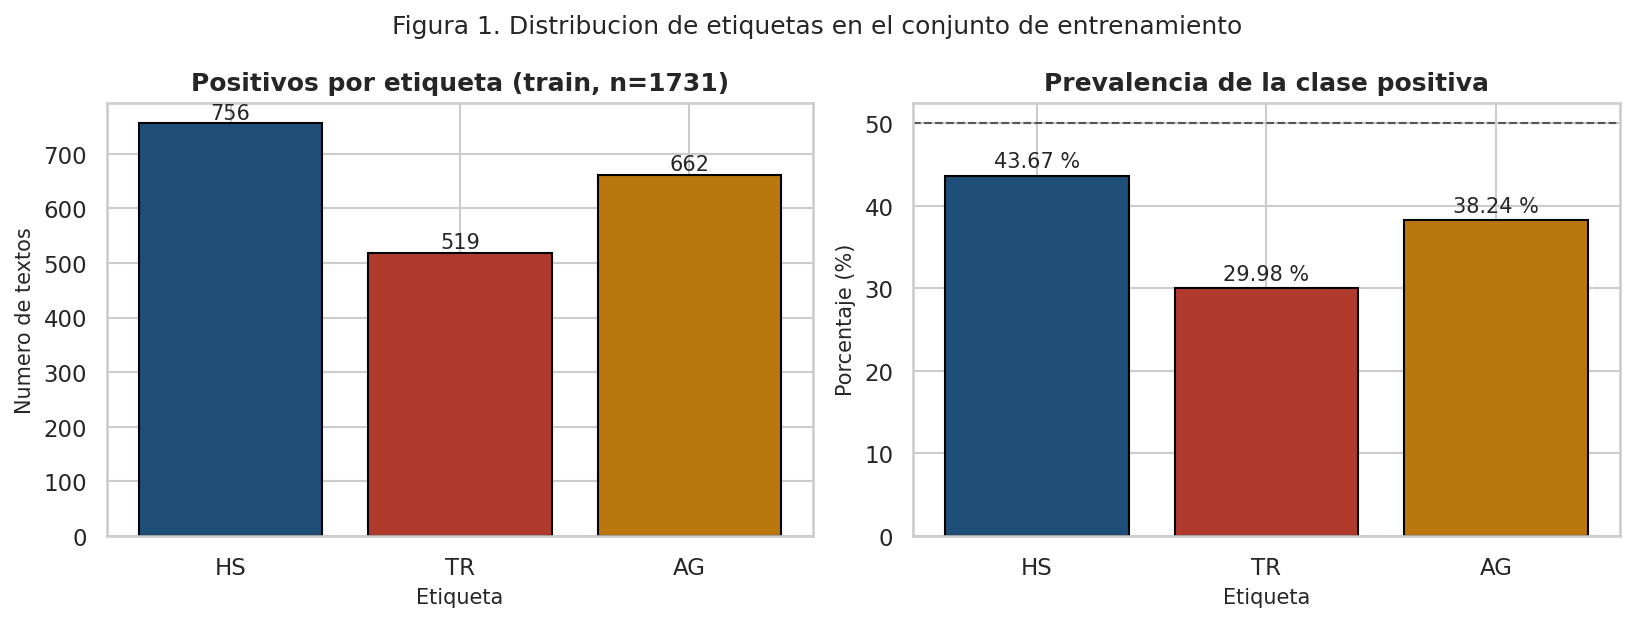

*Figura 1. Distribución de etiquetas en el conjunto de entrenamiento (n = 1.731). Elaboración propia con datos oficiales de la competencia.*

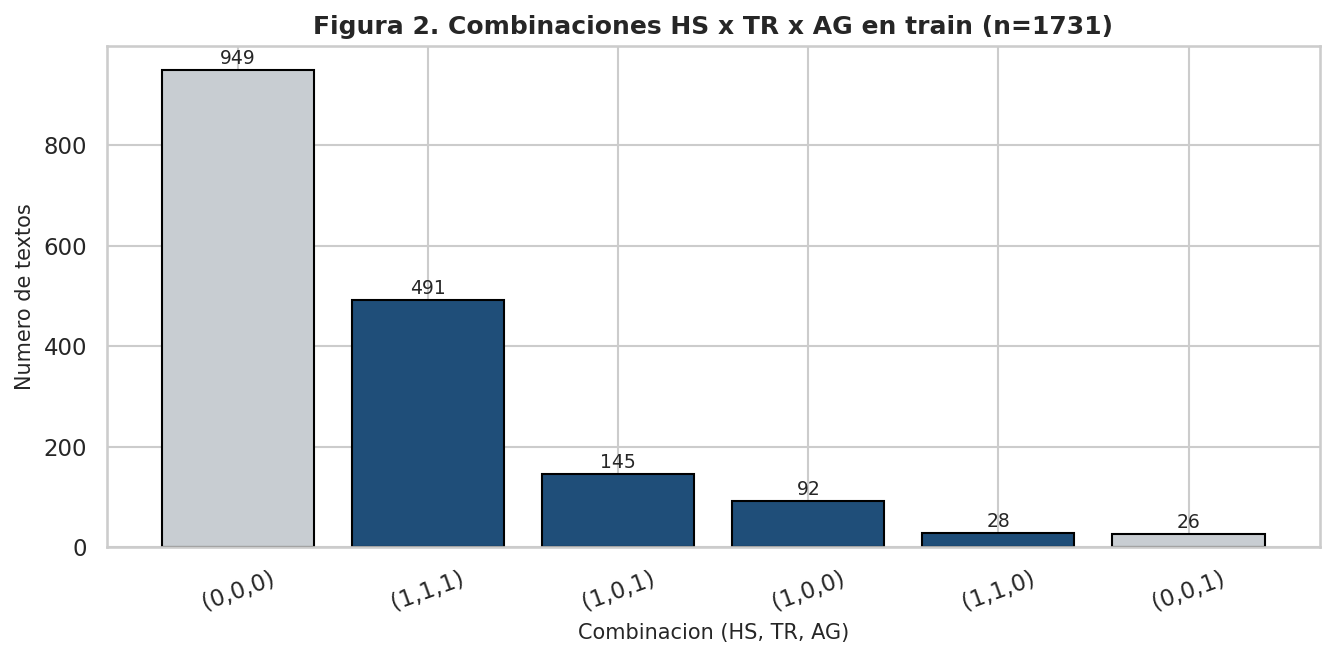

*Figura 2. Combinaciones HS x TR x AG. Dos regímenes dominan el corpus: (0,0,0) con 949 textos y (1,1,1) con 491; no existe ninguna combinación con TR=1 y HS=0. Elaboración propia con datos oficiales de la competencia.*

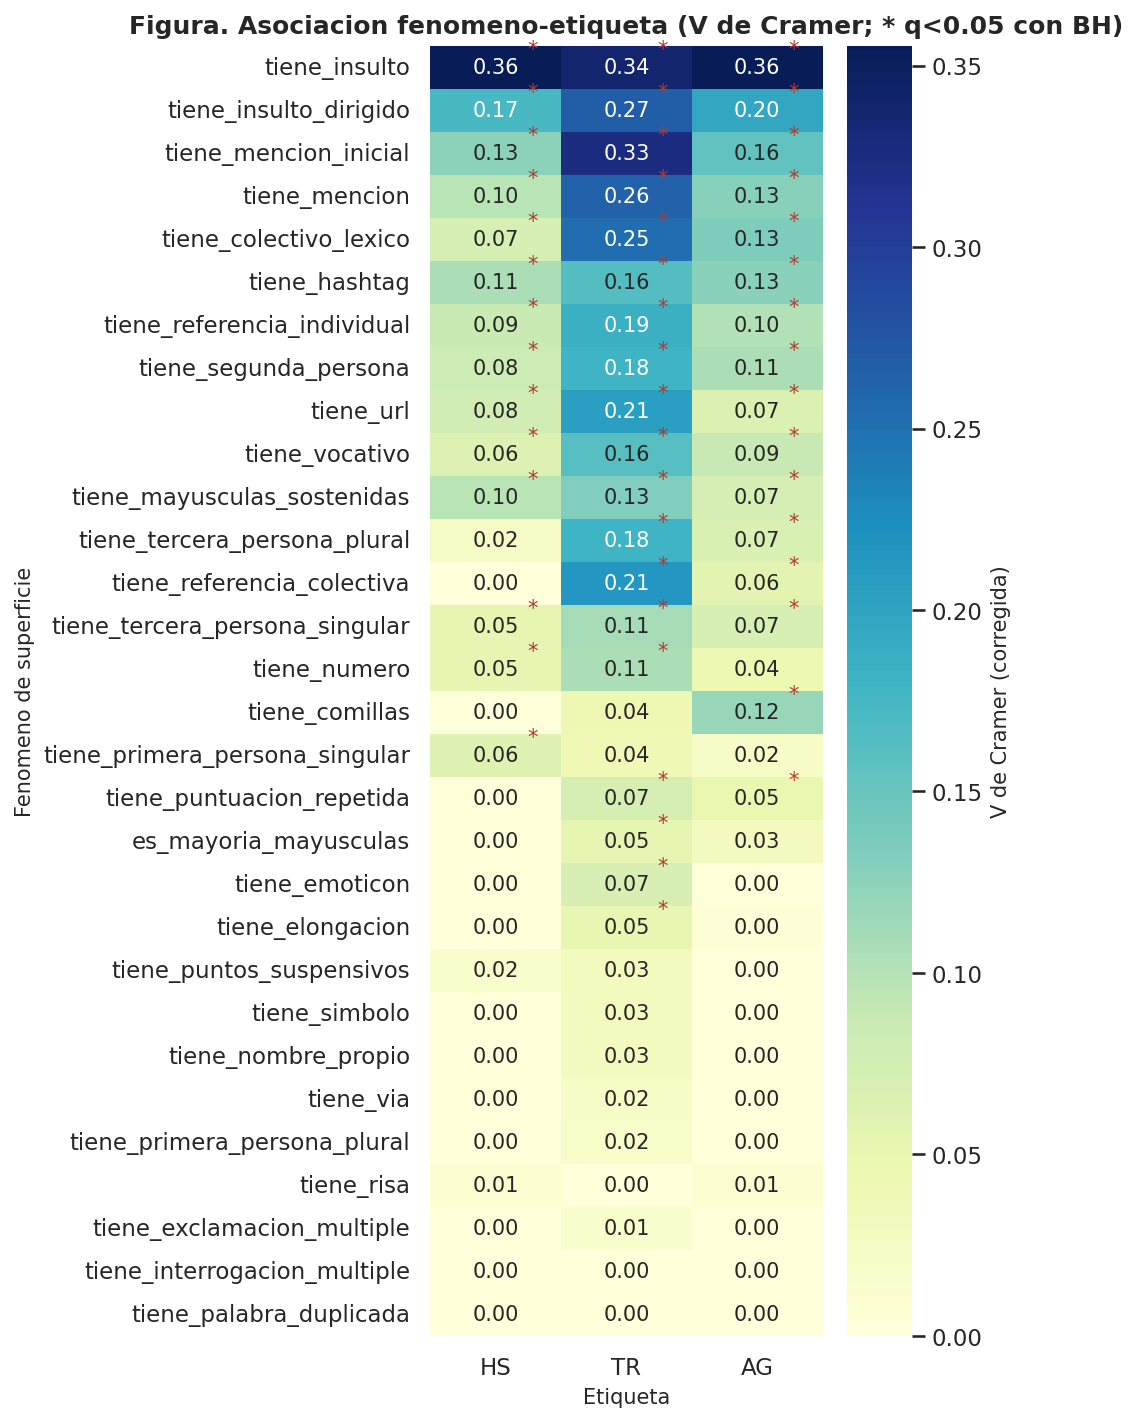

*Figura 3. Asociación fenómeno-etiqueta medida con V de Cramér (asterisco: q < 0.05 con Benjamini-Hochberg). Elaboración propia con datos oficiales de la competencia.*

In [6]:
"""Figuras clave del EDA (generadas en la Fase 2; se muestran, no se recalculan)."""

mostrar_figura(
    "fig_01_distribucion_etiquetas.png",
    "Figura 1. Distribución de etiquetas en el conjunto de entrenamiento (n = 1.731). "
    "Elaboración propia con datos oficiales de la competencia.",
)
mostrar_figura(
    "fig_02_combinaciones_etiquetas.png",
    "Figura 2. Combinaciones HS x TR x AG. Dos regímenes dominan el corpus: (0,0,0) con 949 textos "
    "y (1,1,1) con 491; no existe ninguna combinación con TR=1 y HS=0. "
    "Elaboración propia con datos oficiales de la competencia.",
)
mostrar_figura(
    "fig_15_heatmap_chi2_cramersv.png",
    "Figura 3. Asociación fenómeno-etiqueta medida con V de Cramér (asterisco: q < 0.05 con "
    "Benjamini-Hochberg). Elaboración propia con datos oficiales de la competencia.",
)

### INTERPRETACIÓN de las figuras

- La distribución es **moderadamente desbalanceada** (máximo 2.34:1 en TR), por lo que se descarta el remuestreo agresivo (SMOTE/ADASYN) y se opta por pesos de clase y umbral optimizado.
- El espacio de etiquetas es **fuertemente estructurado**: el 54.8 % del corpus no tiene ninguna etiqueta y el 28.4 % tiene las tres. Esto valida la formulación multi-etiqueta con estructura jerárquica (D-001).
- El mapa de V de Cramér muestra que las señales de superficie se concentran en dos familias: léxico agresivo y marcas de *targeting*.

### DECISIÓN

Avanzar a la caracterización de TR (la etiqueta con semántica discutida) antes de modelar, tal como exige el proyecto.

## 5. Caracterización de TR: la discrepancia entre la definición oficial y HatEval

### OBSERVACIÓN

La definición oficial dice que TR indica "si el discurso está dirigido contra una persona o grupo". El corpus sigue el esquema de HatEval (SemEval-2019 Task 5, subconjunto español), donde TR codifica el **rango del objetivo** (0 = grupo, 1 = individuo). Las dos lecturas predicen lo mismo para las menciones y la segunda persona, pero difieren en los textos con objetivo colectivo explícito.

### HIPÓTESIS

La etiqueta observada puede corresponder al esquema HatEval re-etiquetado; hay que **medirlo, no asumirlo** (D-005). Si TR fuera literalmente "dirigido a alguien", casi todo texto de odio debería tener TR=1, pero solo el 68.7 % de los textos con HS=1 lo tiene.

### MÉTODO

Contraste cuantitativo dentro de HS=1 (n = 756: TR=1 con 519 casos, TR=0 con 237) de los rasgos de *targeting* y de referencia colectiva; generación de una tabla cualitativa de 40 ejemplos TR=1 y 40 TR=0 con rasgos anotados automáticamente para revisión humana.

### RESULTADO

Dentro de HS=1, la mención inicial aparece en el **64.9 % de los TR=1 frente al 9.7 % de los TR=0** (V = 0.512) y la referencia colectiva explícita aparece en el **57.0 % de los TR=0 frente al 10.0 % de los TR=1** (V = 0.504); los TR=0 concentran además las URLs (V = 0.345). El imperativo es el único rasgo sin señal (V = 0.030).

### INTERPRETACIÓN

Los datos son **compatibles con la lectura HatEval** (TR=1 = objetivo individual, típicamente una respuesta directa a un usuario; TR=0 = objetivo colectivo, noticia o comentario general) y dejan abierta la lectura literal del enunciado. La evidencia no permite decidir automáticamente: el discriminador real (dirigido a un grupo frente a hablar sobre un grupo) no es separable con features de superficie.

### DECISIÓN

**PENDIENTE DE REVISIÓN HUMANA (D-005)**: no se decide unilateralmente. Se modela la etiqueta tal como aparece en los datos y se documenta la ambigüedad como limitación. Los materiales para la revisión quedan en `reports/eda/tr_ejemplos_para_revision.csv` (80 ejemplos anotados) y `reports/eda/fase2_tr0_con_referencia_colectiva.csv` (casos límite).

### SIGUIENTE PASO

Preprocesamiento y representación: barrido controlado de variantes (sección 6).

In [7]:
"""Caracterización cuantitativa de TR dentro de HS=1.

Recalcula la mención inicial (regex exacta: @usuario al comienzo del texto) y
lee los contrastes de referencia colectiva y V de Cramér del artefacto de la
Fase 2 (`reports/eda/fase2_resumen_tr_semantica.csv`), cuya definición de
referencia colectiva usa el patrón estructural con spaCy (sustantivo o
adjetivo en plural precedido de determinante plural), no un léxico externo.
"""

import re

import pandas as pd

PATRON_MENCION_INICIAL = re.compile(r"^\s*(?:rt\s+)?@\w+", flags=re.IGNORECASE)

discurso_de_odio = train[train["HS"] == 1].copy()
discurso_de_odio["mencion_inicial"] = discurso_de_odio["text"].str.contains(PATRON_MENCION_INICIAL)

resumen_fase2 = pd.read_csv(RUTAS["reports"] / "eda" / "fase2_resumen_tr_semantica.csv").iloc[0]

tabla = pd.DataFrame(
    {
        "TR=0 (grupo/generico)": [
            int(resumen_fase2["n_tr0"]),
            round(100 * resumen_fase2["p_tr0_con_mencion_inicial"], 1),
            round(100 * resumen_fase2["p_tr0_con_colectivo"], 1),
        ],
        "TR=1 (individuo/respuesta)": [
            int(resumen_fase2["n_tr1"]),
            round(100 * resumen_fase2["p_tr1_con_mencion_inicial"], 1),
            round(100 * resumen_fase2["p_tr1_con_colectivo"], 1),
        ],
    },
    index=["n", "mencion inicial (%)", "referencia colectiva (%)"],
)
print("Perfil de TR dentro de HS=1 (n = 756; n_tr1 = 519, n_tr0 = 237):")
print(tabla.to_string())

mencion_recalculada = discurso_de_odio.groupby("TR")["mencion_inicial"].mean().round(4) * 100
print(f"\nControl del recálculo directo de mencion inicial: TR=0 {mencion_recalculada.loc[0]:.1f} % | "
      f"TR=1 {mencion_recalculada.loc[1]:.1f} % (coincide con el artefacto de la Fase 2)")
print(f"Proporción de TR=1 dentro de HS=1: {100 * resumen_fase2['proporcion_tr1_en_hs1']:.2f} % "
      f"(bajo la lectura literal 'dirigido a alguien' el valor esperado sería cercano al 100 %)")

print("\nV de Cramér de los rasgos de targeting dentro de HS=1:")
rasgos = pd.read_csv(RUTAS["reports"] / "eda" / "fase2_rasgos_TR.csv").head(8)
print(rasgos[["fenomeno", "p_etiqueta_con_fenomeno", "p_etiqueta_sin_fenomeno", "diferencia_proporciones", "v_cramer", "magnitud"]]
      .round(4).to_string(index=False))

revision = pd.read_csv(RUTAS["reports"] / "eda" / "tr_ejemplos_para_revision.csv")
casos_limite = pd.read_csv(RUTAS["reports"] / "eda" / "fase2_tr0_con_referencia_colectiva.csv")
print(f"\nMaterial de revisión humana (D-005): {len(revision)} ejemplos anotados "
      f"({int((revision['TR'] == 1).sum())} TR=1 y {int((revision['TR'] == 0).sum())} TR=0) y "
      f"{len(casos_limite)} casos límite TR=0 con referencia colectiva.")

Perfil de TR dentro de HS=1 (n = 756; n_tr1 = 519, n_tr0 = 237):
                          TR=0 (grupo/generico)  TR=1 (individuo/respuesta)
n                                         237.0                       519.0
mencion inicial (%)                         9.7                        64.9
referencia colectiva (%)                   57.0                        10.0

Control del recálculo directo de mencion inicial: TR=0 9.7 % | TR=1 64.9 % (coincide con el artefacto de la Fase 2)
Proporción de TR=1 dentro de HS=1: 68.65 % (bajo la lectura literal 'dirigido a alguien' el valor esperado sería cercano al 100 %)

V de Cramér de los rasgos de targeting dentro de HS=1:
                    fenomeno  p_etiqueta_con_fenomeno  p_etiqueta_sin_fenomeno  diferencia_proporciones  v_cramer magnitud
       tiene_mencion_inicial                   0.9361                   0.4596                   0.4765    0.5120   grande
  tiene_referencia_colectiva                   0.2781                   0.8207   

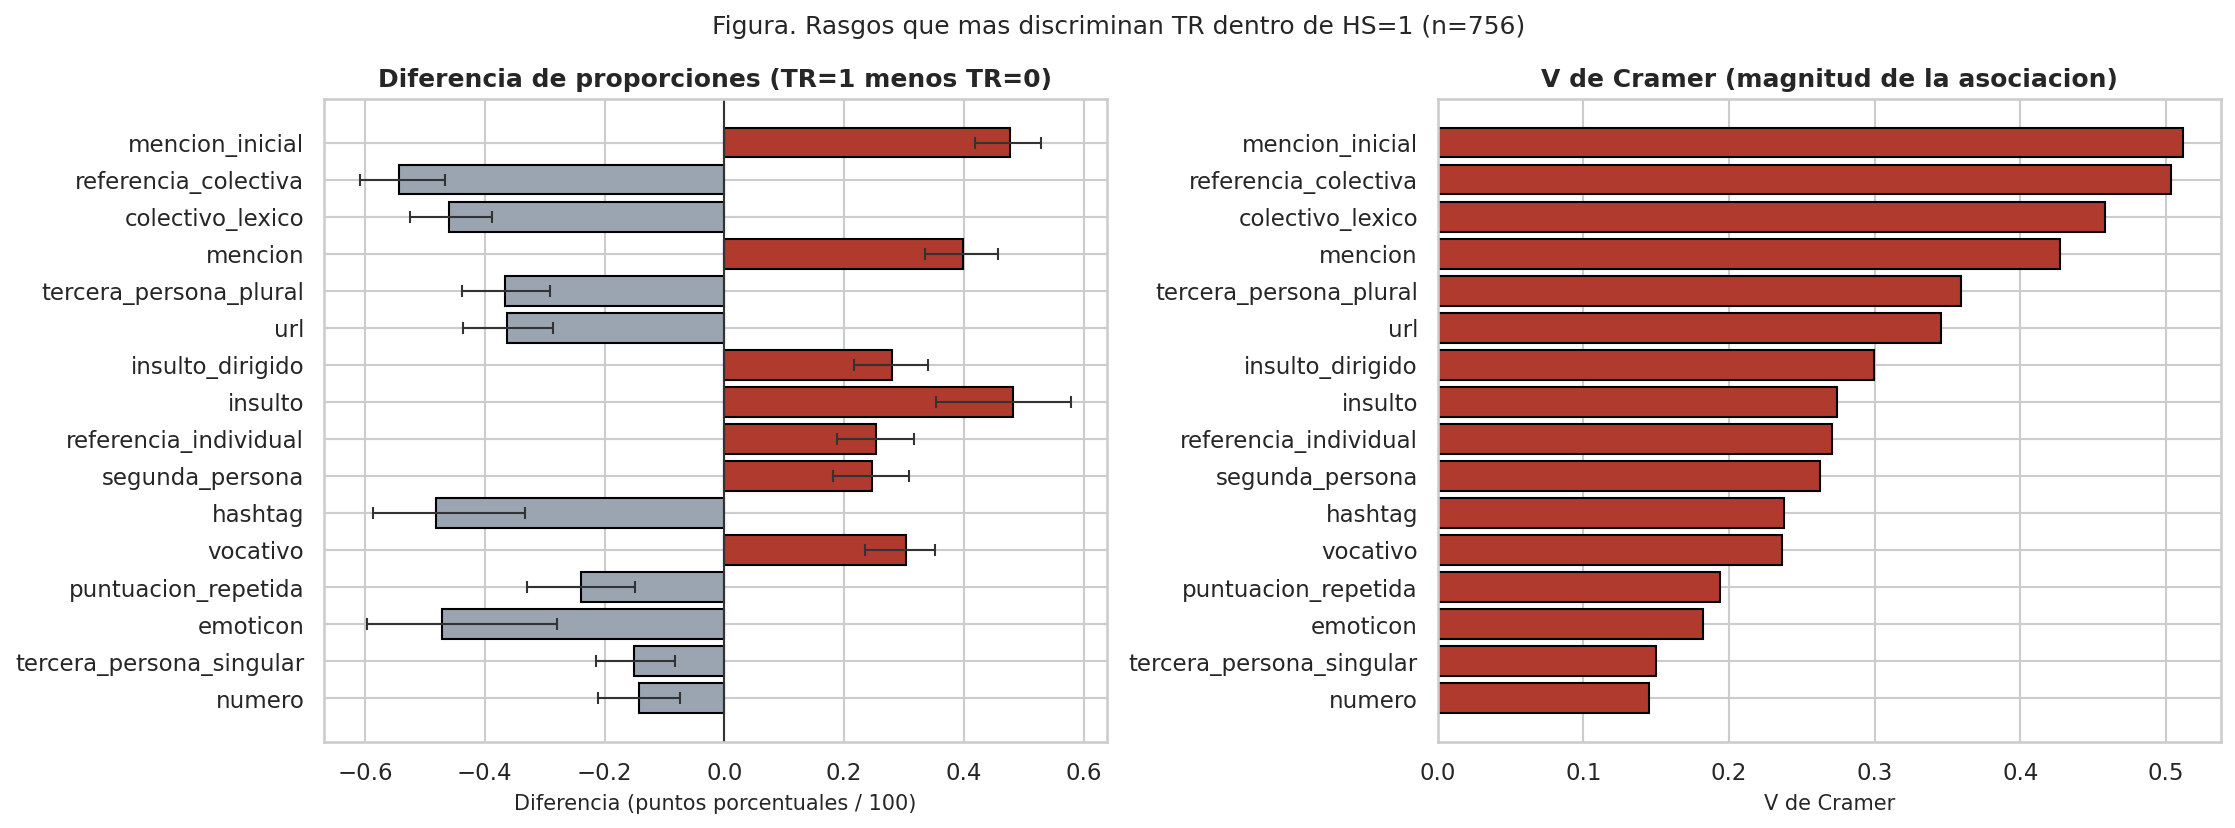

*Figura 4. Rasgos que más discriminan TR dentro de HS=1 (n = 756): diferencia de proporciones y V de Cramér. La mención inicial y la referencia colectiva son los dos extremos opuestos. Elaboración propia con datos oficiales de la competencia.*

In [8]:
"""Figura de rasgos que discriminan TR dentro de HS=1."""

mostrar_figura(
    "fig_16_rasgos_TR.png",
    "Figura 4. Rasgos que más discriminan TR dentro de HS=1 (n = 756): diferencia de proporciones "
    "y V de Cramér. La mención inicial y la referencia colectiva son los dos extremos opuestos. "
    "Elaboración propia con datos oficiales de la competencia.",
)

## 6. Preprocesamiento y representación: barrido PRE / REP / MOD

### OBSERVACIÓN

El corpus es texto de Twitter degradado (sin diacríticos, con URLs `t.co`, menciones, hashtags, elongaciones y ruido de puntuación). El estado del arte sugiere que los n-gramas de carácter ayudan con la evasión ortográfica y que las n-gramas de palabras funcionales y de puntuación fueron clave en el sistema ganador en español.

### HIPÓTESIS

H4 (word + char > cada representación sola), H6 (estilometría) y H7 (la lematización no aporta en tuits). Cada adición debe pasar una ablación controlada: la literatura muestra que acumular bloques de features puede degradar el rendimiento.

### MÉTODO

Barrido de 25 configuraciones con validación común `StratifiedGroupKFold(5, shuffle=True, random_state=42)` agrupada por near-duplicados y estratificada por HS x TR x AG, con el vectorizador ajustado **dentro de cada pliegue**:
- **Parte A (PRE-00..PRE-09)**: 10 transformaciones deterministas del texto con representación y modelo fijos.
- **Parte B (REP-01..REP-06)**: 6 representaciones (char, word, unigramas, unión) con modelo fijo.
- **Parte C (MOD-01..MOD-04)**: 4 familias de modelos sobre la mejor representación.
Regla de decisión pre-registrada: se adopta una mejora con **>= +0.005 absoluto** en la métrica primaria y en **>= 3 de 5 pliegues**.

### RESULTADO

| Parte | Ganador | F1 OOF | Delta vs B1 | Pliegues | Decisión |
|---|---|---|---|---|---|
| A - preprocesamiento | PRE-03 (URLs -> token `url`) | 0.7623 | +0.0035 | 4/5 | **Descartada** (no alcanza el umbral +0.005) |
| B - representación | REP-05 (unión word + char_wb) | 0.7865 | +0.0278 | 5/5 | Adoptada |
| C - modelo | MOD-03b_BEST (LR C=2.0 balanced) | 0.7927 | +0.0339 | 5/5 | **Adoptada (modelo final)** |

Ninguna de las 10 variantes de preprocesamiento superó el umbral: la mejor fue sustituir URLs por un token (+0.0035) y la lematización con spaCy fue la peor (-0.0162). Las representaciones puras de carácter (REP-01: 0.7567) o de palabra (REP-03: 0.7417) quedan muy por debajo de la unión (REP-05: 0.7865), lo que confirma H4.

### INTERPRETACIÓN

El corpus ya viene normalizado por los organizadores: las limpiezas adicionales que un pipeline de Twitter aplicaría por defecto **no aportan** e incluso dañan (quitar mayúsculas, lematizar). La ganancia está en la representación (unión de palabra y carácter) y en el control de la regularización, no en el preprocesamiento.

### DECISIÓN

Usar texto crudo como preprocesamiento y la unión TF-IDF `word(1,2)` + `char_wb(3,5)` con `min_df=2` y `sublinear_tf` como representación; descartar todas las variantes de preprocesamiento y el post-proceso jerárquico (MOD-04: -0.0057 frente a su origen, cierre de H8 con esta representación).

### SIGUIENTE PASO

Modelos, optimización de hiperparámetros y ensembles (sección 7).

In [9]:
"""Tablas del barrido PRE / REP / MOD (Fases 4-5).

Muestra el ranking por parte y la comparación con el baseline B1.
"""

import pandas as pd

variantes = pd.read_csv(RUTAS["reports"] / "variantes_representaciones.csv")
columnas_orden = ["f1_media_columnas", "f1_HS", "f1_TR", "f1_AG"]

for parte, titulo in (
    ("A", "PARTE A - preprocesamiento (modelo y representación fijos)"),
    ("B", "PARTE B - representacion (modelo fijo)"),
    ("C", "PARTE C - modelo (mejor representacion)"),
):
    tabla = variantes[variantes["parte"].str.startswith(parte)].sort_values(
        "f1_media_columnas", ascending=False
    )
    vista = tabla[
        ["experiment_id", "descripcion", "f1_media_columnas", "mejora_vs_B1", "mejora_en_pliegues", "dimension", "decision"]
    ].copy()
    vista["descripcion"] = vista["descripcion"].str.slice(0, 78)
    print("=" * 110)
    print(titulo)
    print("=" * 110)
    print(vista.to_string(index=False, max_colwidth=80))
    print()

print("Referencia B1 (TF-IDF word(1,2) + LR C=1.0 balanced): F1 OOF 0.75870")
print("Umbral de adopción pre-registrado: +0.005 absoluto y >= 3/5 pliegues.")

PARTE A - preprocesamiento (modelo y representación fijos)
experiment_id                                                                    descripcion  f1_media_columnas  mejora_vs_B1  mejora_en_pliegues  dimension   decision
       PRE-03 URLs sustituidas por el token 'url' (transformacion unica sobre texto crudo; 5             0.7623      0.003548                   4       4024 descartada
       PRE-05 hashtags partidos en camelCase conservando las palabras (transformacion unica              0.7607      0.002013                   4       4061 descartada
       PRE-00 texto crudo (referencia = baseline B1) (transformacion unica sobre texto crudo             0.7587      0.000000                   0       4024 referencia
       PRE-07 puntuacion eliminada (solo letras, digitos y espacios) (transformacion unica s             0.7587      0.000000                   0       4024 descartada
       PRE-06 elongaciones colapsadas: (.)\1{2,} -> dos repeticiones (transformacion unica s         

### Literatura de referencia y su papel en las decisiones

De las 45 referencias verificadas en `reports/estado_arte.md`, estas diez son las que
sostienen las decisiones metodologicas del proyecto. La columna de compatibilidad indica
si el metodo es usable bajo las restricciones de la competencia.

| Ref | Trabajo (ano) | Aporte al proyecto | Compatibilidad |
|---|---|---|---|
| Basile et al. - SemEval-2019 Task 5 (HatEval) | 2019 | TR y AG solo se anotan sobre tweets de odio: estructura condicionada. Los mejores sistemas usan SVM de kernel lineal sobre TF-IDF | compatible: paper de organizacion del esquema; solo aporta estructura de anotacion y baselines |
| Argota Vega et al. - MineriaUNAM at SemEval-2019 Tas | 2019 | GANO la Subtask A en espanol SIN redes neuronales y SIN embeddings preentrenados, solo con features linguisticas y busqueda combinatoria del espacio d | compatible: 100 por ciento. No usa transformers ni embeddings preentrenados |
| Nina-Alcocer - HATERecognizer at SemEval-2019 Task 5 | 2019 | Las features de emocion aportan senal complementaria clara (subtask B) y las estructurales aportan en A; anadir bloques NO siempre mejora: hay que abl | parcial: POS/emocion/estructural + TF-IDF son compatibles; GloVe; Google News y FastText estan PROHIBIDOS |
| Plaza-del-Arco et al. - SINAI at SemEval-2019 Task 5 | 2019 | La votacion ingenua NO supera al SVM lineal simple (+0.006). Evidencia negativa contra esperar ganancias automaticas por ensamblar | compatible: SVM; LR; arboles; TF-IDF |
| Garcia-Diaz et al. - Evaluating feature combination  | 2022 | Es el precedente metodologico mas cercano al plan de ablacion de este proyecto; confirma que las features linguisticas suman sobre TF-IDF pero que la  | parcial: la rama con transformers esta prohibida; la rama de features linguisticas es compatible |
| Nobata et al. - Abusive Language Detection in Online | 2016 | Evidencia fundacional de H1: los n-gramas de caracter capturan variacion morfologica y evasion ortografica | compatible |
| Malmasi & Zampieri - Detecting Hate Speech in Social | 2017 | Confirma la eficacia de n-gramas + modelo lineal en redes sociales | compatible |
| ElSherief et al. - Hate Lingo: A Target-Based Lingui | 2018 | Base teorica de H3 (features de targeting) y de la separacion HS frente a AG | compatible: solo aporta diseno de features; si se usaran categorias tipo LIWC habria que documentarlas como re |
| Lipton et al. - Optimal Thresholding of Classifiers  | 2014 | Base directa de H9: optimizar un umbral por etiqueta sobre validacion; nunca sobre test | compatible |
| Nan et al. - Optimizing F-measure: A Tale of Two App | 2012 | Justifica elegir umbral por su robustez y bajo coste computacional con tres clasificadores binarios independientes | compatible |
| Arango et al. - Hate Speech Detection is Not as Easy | 2019 | Evidencia externa que valida la decision D-004 de usar StratifiedGroupKFold con grupos de near-duplicados | compatible: metodologico |

**Lectura**: el sistema ganador en espanol de HatEval (Argota Vega et al., 2019) no uso
redes neuronales ni embeddings preentrenados, lo que fijo el techo realista del proyecto;
la literatura de umbrales (Lipton et al., 2014; Nan et al., 2012) anticipa que el ajuste de
umbral es la palanca efectiva cuando la metrica es F1, tal como confirmo el leaderboard
(+0.0031 pareado). Las referencias con transformers se citan solo como cota superior
prohibida por las reglas del curso.

## 7. Modelos: baselines, clásicos, Optuna, ensembles, features densas y DL desde cero

### OBSERVACIÓN

Tras fijar la representación, quedan cinco vías por explorar: (a) baselines y modelos clásicos sobre la unión; (b) optimización de hiperparámetros con Optuna; (c) ensembles de modelos base diversos; (d) features densas inducidas de train (hipótesis H11/H12/H14 del análisis de error); (e) redes neuronales entrenadas desde cero, exigidas como requisito metodológico.

### HIPÓTESIS

H2 (léxico agresivo + segunda persona separan AG), H9 (umbral por etiqueta distinto de 0.5), H10 (stacking > mejor individual), H11/H12/H14 (bloques densos de interacción, objetivo y deshumanización) y la expectativa razonable de que, con 1.731 ejemplos y sin embeddings preentrenados, el DL no supere a un modelo lineal bien regularizado.

### MÉTODO

- **Baselines**: B1 (TF-IDF word(1,2) + LR balanceada) y B5-DENSE (LR sobre 46 features densas escaladas, sin TF-IDF). Nota de trazabilidad: los baselines B2-B4 previstos en la Fase 2 nunca se ejecutaron; su rol lo cubrieron las partes B y C del barrido (REP-01..REP-06 y MOD-01..MOD-04).
- **Clásicos**: ComplementNB, LinearSVC y LogisticRegression con C en {0.5, 1.0, 2.0} sobre la unión.
- **Optuna**: 50 trials (28 completados, 22 podados), `TPESampler(seed=42)` y `MedianPruner`, 294.58 s; se optimizó el OOF con umbral 0.5.
- **Ensembles**: 4 modelos base con el mismo split (M1 word LR 0.7587, M2 unión LR 0.7927, M3 unión LinearSVC 0.7849, M4 char LR 0.7567) combinados por voto suave, pesos en símplex, stacking por etiqueta y mejor subconjunto; selección con validación anidada.
- **Features densas**: 46 features en 3 bloques (H11 registro bromista, H12 objetivo individual frente a colectivo, H14 léxico de deshumanización), inducidas **dentro de cada pliegue** y concatenadas al TF-IDF.
- **DL desde cero**: MLP sobre SVD 300 del TF-IDF unión, CharCNN con embeddings de carácter y BiLSTM con embeddings de palabra; 5 pliegues, 3 semillas, early stopping estricto, AdamW, sin AMP (medido: con estos tamaños AMP era más lento en ROCm).

### RESULTADO

| Familia | Mejor configuración | F1 OOF | Resultado | Decisión |
|---|---|---|---|---|
| Baseline clásico | B1 TF-IDF word + LR | 0.7587 | Referencia | Base de comparación |
| Baseline denso | B5-DENSE (46 features) | 0.6607 | -0.1320 vs MOD-03b | Descartado |
| Clásicos sobre unión | MOD-03b_BEST (LR C=2.0) | **0.7927** | +0.0339 vs B1, 5/5 pliegues | **Adoptado** |
| LinearSVC | MOD-01_BEST | 0.7849 | -0.0078 vs LR | Descartado |
| ComplementNB | MOD-02_BEST | 0.6888 | -0.1039 | Descartado |
| Optuna | OPT-01 (trial 24) | 0.8012 (0.8039 con umbrales) | Mejor OOF, pero **LB 0.77602** | Descartado |
| Ensembles | ENS-04 (par M2+M3, umbrales medianos) | 0.7916 anidado / 0.7985 | LB 0.77510 | Descartado |
| Features densas | HIB-H12 | 0.7836 | -0.0091 vs MOD-03b | Descartado (H11/H12/H14 no validan) |
| DL desde cero | DL-01 (MLP sobre SVD) | 0.7949 (0.7947 +/- 0.0011 con 3 semillas) | Supera a MOD-03b en OOF, pero sin sonda de LB | No adoptado por protocolo |
| DL desde cero | DL-02 CharCNN / DL-03 BiLSTM | 0.7410 / 0.7364 | Por debajo incluso de B1 | Descartados |

### INTERPRETACIÓN

1. **El baseline denso confirma que la señal está en el texto, no en las features de superficie**: 46 features densas rinden 0.6607 frente a 0.7927 del TF-IDF unión.
2. **La acumulación de features no funciona**: los tres bloques densos concatenados al TF-IDF degradan (-0.009 a -0.032); el control con las densas a cero reproduce 0.792659 exacto, lo que demuestra que la pérdida es de las features y no del `hstack`. H11/H12/H14 quedan como **evidencia negativa** documentada.
3. **Optuna ilustra el sesgo de selección por OOF**: el modelo con el mejor OOF (0.8012/0.8039) fue el que peor transfirió al leaderboard (0.77602), porque el OOF conserva la prevalencia de train (~43.7 % de HS) mientras que el test tiene ~7 % menos positivos (sonda E00).
4. **Los ensembles no aportan con modelos tan correlacionados** (correlación de errores 0.63-0.84): la mejor estimación anidada (+0.0023) no alcanza el umbral de +0.005 y el envío lo confirmó (LB 0.77510, peor que v02 y v03).
5. **El DL desde cero no supera al clásico de forma adoptable**: solo el MLP sobre SVD empata o supera ligeramente el OOF, y por D-012/D-014 una mejora así exige una sonda de leaderboard, que no se gastó porque la fase competitiva estaba cerrada. CharCNN y BiLSTM quedan por debajo de B1: con 1.731 ejemplos y sin embeddings preentrenados no hay masa crítica para entrenar representaciones desde cero.

### DECISIÓN

Adoptar MOD-03b_BEST (LR C=2.0 balanced sobre la unión) como modelo final; registrar Optuna, ensembles, features densas y DL como evidencia negativa con sus números; cerrar la línea de acumulación de features.

### SIGUIENTE PASO

Validación rigurosa: control por pseudo-autor y contraste con el leaderboard (sección 8).

Estudio Optuna: opt01_tfidf_lr_union
  trials solicitados: 50 | ejecutados: 50 | completados: 28 | podados: 22
  duracion: 294.6 s | sampler: TPESampler(seed=42, n_startup_trials=10)
  metrica objetivo: f1_media_columnas out-of-fold con umbral 0.5

Mejor trial: #24 con F1 OOF 0.8012 (delta vs MOD-03b +0.0086, 5/5 pliegues)
  parametros: {"word": {"ngram_range": [1, 3], "min_df": 5, "max_df": 0.9, "sublinear_tf": true}, "char": {"ngram_range": [3, 6], "min_df": 2, "sublinear_tf": true}, "modelo": {"C": 3.2575442857761407, "class_weight": "balanced"}}
  umbrales optimos por etiqueta: {'HS': 0.48, 'TR': 0.51, 'AG': 0.49} -> F1 OOF 0.8039

Advertencia registrada (D-012): En la familia union word+char el gap local-LB medido es -0.013 a -0.016 (v02 -0.0128, v03 -0.0158, v04 -0.0234); D-012 exige >= +0.010 local para considerar una mejora realista en el leaderboard. Un delta entre +0.005 y +0.010 cumple la regla pre-registrada pero debe confirmarse con una sonda de LB antes de darla por real.

 trial  f1_media_columnas word_ngram_range  word_min_df char_ngram_range     lr_C lr_class_weight
    24           0.801225              1-3            5              3-6 3.257544        balanced
    17           0.797840              1-3            3              3-6 2.715342        balanced
    44           0.796765              1-3            3              3-6 2.262272        balanced
    16           0.795985              1-3            3              3-6 3.838844        balanced
    41           0.795670              1-3            3              3-6 3.747211        balanced


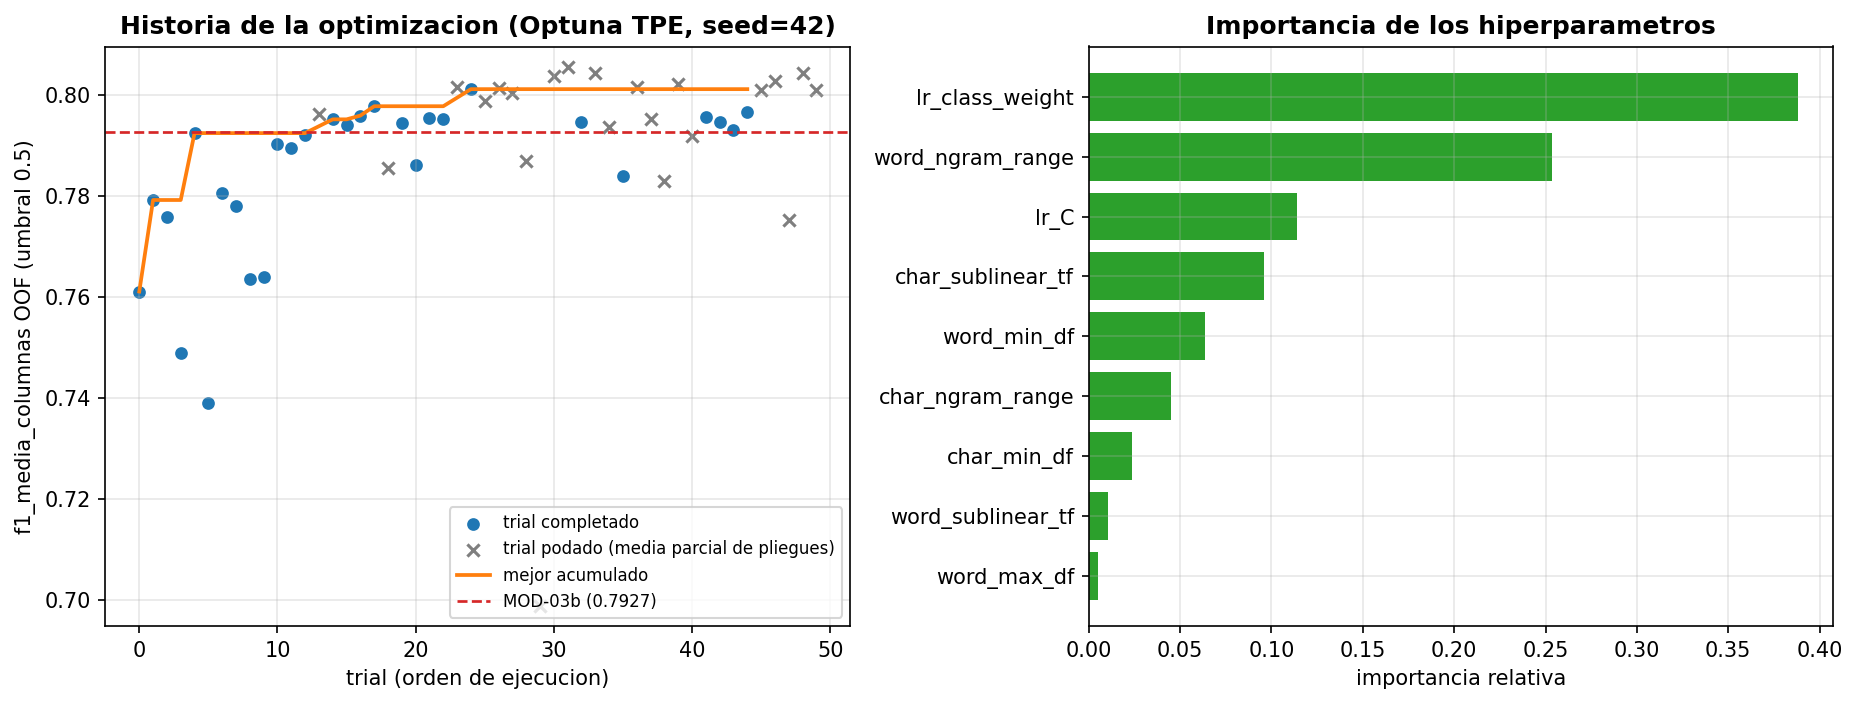

*Figura 5. Historia de la optimización con Optuna: mejores valores por trial y distribución de los trials completados. Elaboración propia con datos oficiales de la competencia.*

In [10]:
"""Resumen del estudio de Optuna (50 trials) y de la decisión de no adoptarlo."""

import json

import pandas as pd

trials = pd.read_csv(RUTAS["reports"] / "optuna_trials.csv")
estudio = json.loads((RUTAS["reports"] / "optuna_estudio.json").read_text(encoding="utf-8"))

print("Estudio Optuna:", estudio["estudio"]["study_name"])
print(f"  trials solicitados: {estudio['estudio']['n_trials_solicitados']} | ejecutados: {estudio['estudio']['n_trials_ejecutados']} "
      f"| completados: {estudio['estudio']['n_completados']} | podados: {estudio['estudio']['n_podados']}")
print(f"  duracion: {estudio['estudio']['duracion_seg']:.1f} s | sampler: {estudio['estudio']['sampler']}")
print(f"  metrica objetivo: {estudio['estudio']['metrica_objetivo']}")

mejor = estudio["mejor_trial"]
print(f"\nMejor trial: #{mejor['numero']} con F1 OOF {mejor['f1_media_columnas']:.4f} "
      f"(delta vs MOD-03b {mejor['delta_vs_mod03b']:+.4f}, {mejor['pliegues_mejorados']}/5 pliegues)")
print("  parametros:", json.dumps(mejor["params"], ensure_ascii=False))
print(f"  umbrales optimos por etiqueta: {estudio['umbrales']['umbrales_optimos']} "
      f"-> F1 OOF {estudio['umbrales']['f1_media_columnas_umbrales_optimos']:.4f}")
print(f"\nAdvertencia registrada (D-012): {estudio['advertencia_d012']}")
print(f"\nResultado en el leaderboard: LB 0.77602 (peor que v02 y v03) pese al mejor OOF -> NO se adopta.")
print(f"\nTop-5 trials por F1 OOF:")
print(trials.sort_values("f1_media_columnas", ascending=False)
      .head(5)[["trial", "f1_media_columnas", "word_ngram_range", "word_min_df", "char_ngram_range", "lr_C", "lr_class_weight"]]
      .to_string(index=False))

mostrar_figura(
    "fig_25_optuna_historia.png",
    "Figura 5. Historia de la optimización con Optuna: mejores valores por trial y distribución de los "
    "trials completados. Elaboración propia con datos oficiales de la competencia.",
)

ENSEMBLES (4 bases OOF con el mismo split; seleccion anidada)
experiment_id                                      ensemble  f1_anidada_0.5  f1_anidada_umbrales          umbrales_finales  delta_vs_single_anidado
       ENS-01    voto suave con pesos iguales (M1+M2+M3+M4)        0.790594             0.790594 HS=0.50, TR=0.50, AG=0.50                -0.003621
       ENS-02 voto suave con pesos en rejilla simplex (p...        0.791898             0.794939 HS=0.43, TR=0.48, AG=0.44                -0.002318
       ENS-03 stacking por etiqueta con LR sobre las 4 p...        0.783649             0.793658 HS=0.41, TR=0.38, AG=0.33                -0.010567
       ENS-04 mejor par/trio de bases seleccionado de fo...        0.791609             0.798467 HS=0.44, TR=0.47, AG=0.44                -0.002606
Decision: ninguno alcanza el umbral +0.005; el mejor (ENS-04, +0.0023) se envio como v04 y dio LB 0.77510.

FEATURES DENSAS H11 / H12 / H14 (inducidas por pliegue; concatenadas al TF-IDF)
experiment

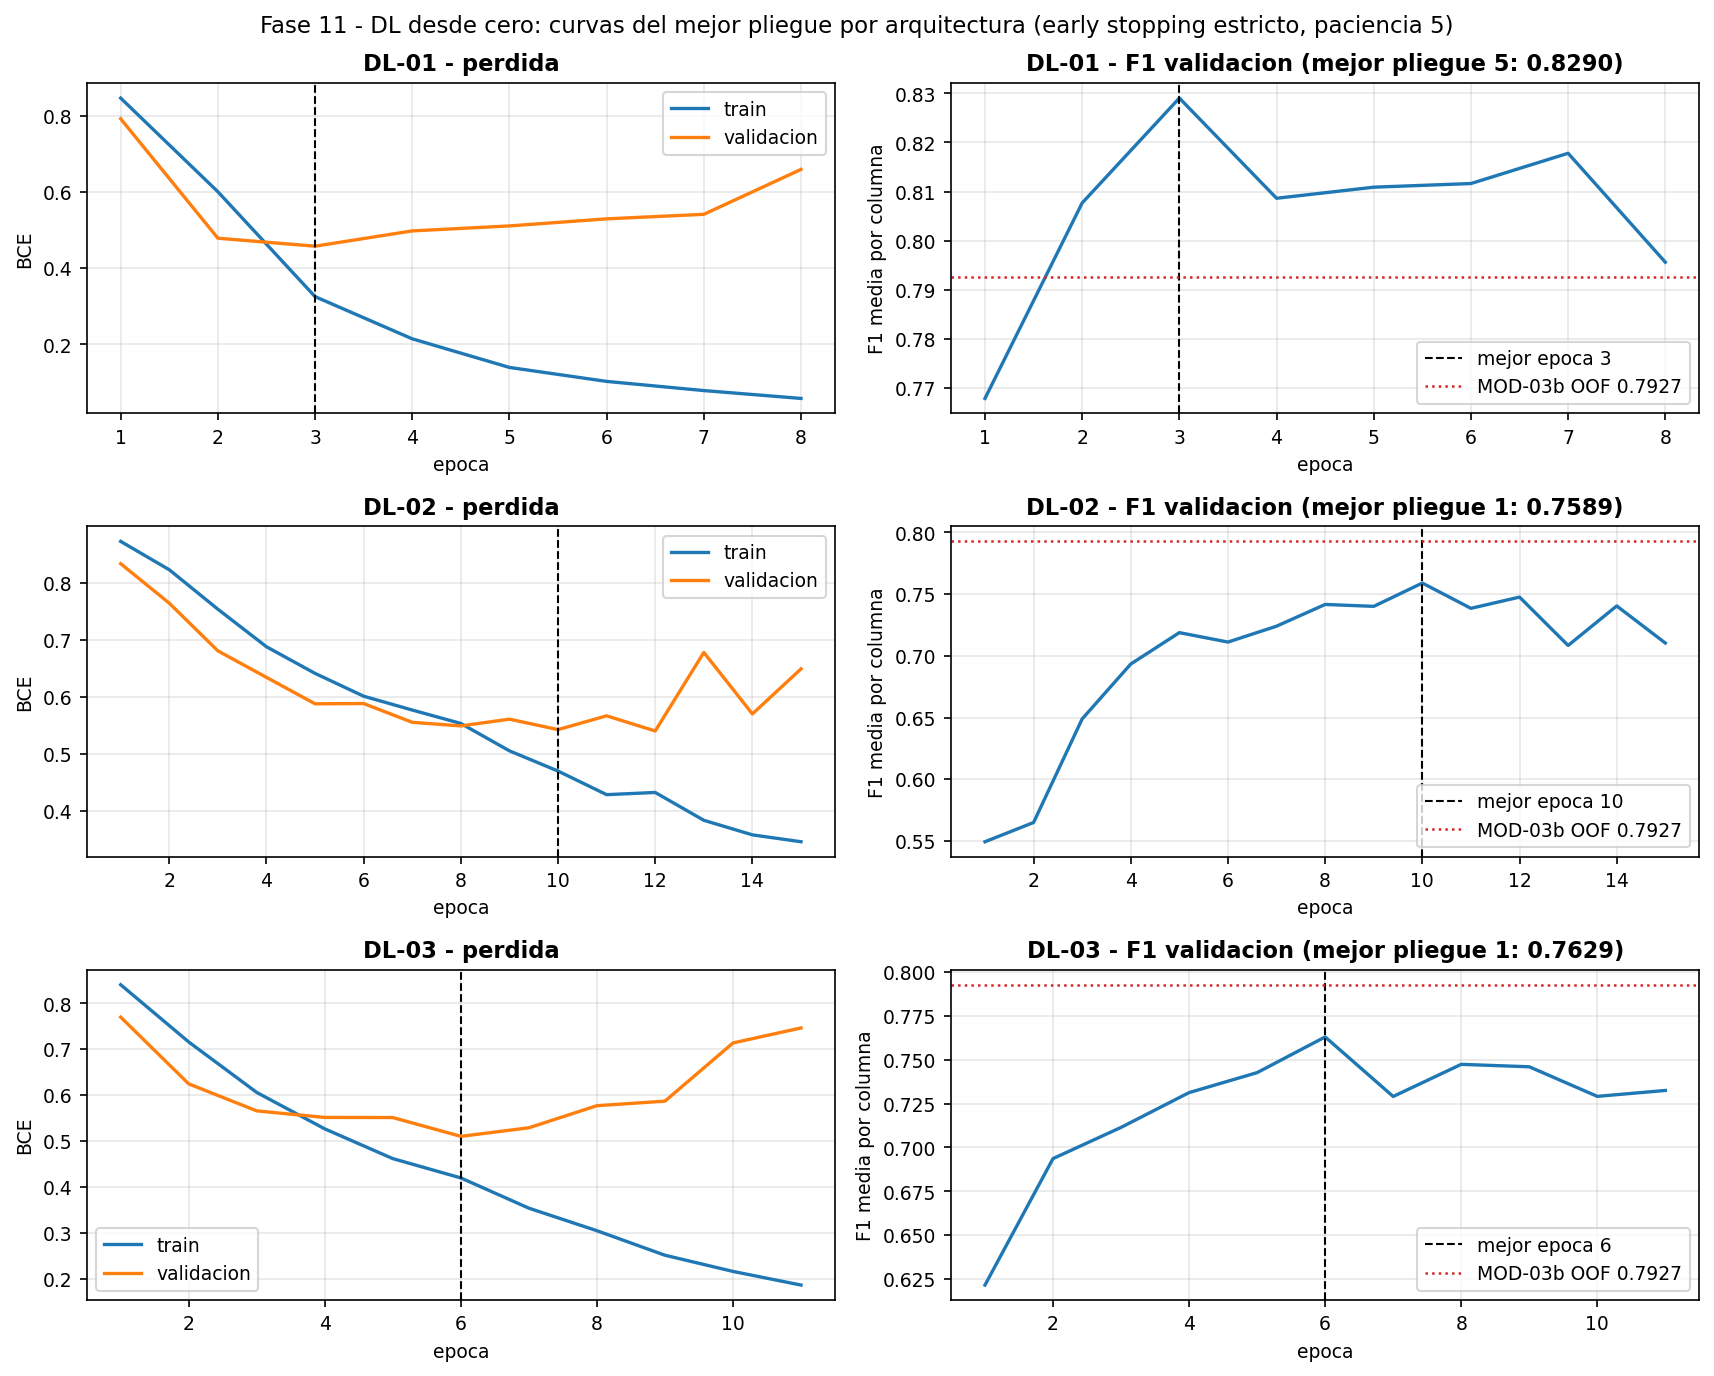

*Figura 6. Curvas de pérdida y F1 por época de las tres arquitecturas de DL entrenadas desde cero. Elaboración propia con datos oficiales de la competencia.*

In [11]:
"""Tablas de ensembles, features densas y DL desde cero (resultados honestos, incluidos los negativos)."""

import json

import pandas as pd

ensembles = pd.read_csv(RUTAS["reports"] / "ensembles_resultados.csv")
densas = pd.read_csv(RUTAS["reports"] / "features_densas_resultados.csv")
dl = pd.read_csv(RUTAS["reports"] / "dl_desde_cero_resultados.csv")
dl_json = json.loads((RUTAS["reports"] / "dl_desde_cero_resultados.json").read_text(encoding="utf-8"))

print("=" * 110)
print("ENSEMBLES (4 bases OOF con el mismo split; seleccion anidada)")
print("=" * 110)
print(ensembles[["experiment_id", "ensemble", "f1_anidada_0.5", "f1_anidada_umbrales", "umbrales_finales", "delta_vs_single_anidado"]]
      .to_string(index=False, max_colwidth=45))
print("Decision: ninguno alcanza el umbral +0.005; el mejor (ENS-04, +0.0023) se envio como v04 y dio LB 0.77510.")

print("\n" + "=" * 110)
print("FEATURES DENSAS H11 / H12 / H14 (inducidas por pliegue; concatenadas al TF-IDF)")
print("=" * 110)
print(densas[["experiment_id", "descripcion", "f1_media_columnas", "mejora_vs_MOD03b", "mejora_en_pliegues", "n_features_densas", "decision"]]
      .to_string(index=False, max_colwidth=52))
print("Control: con las densas a cero se reproduce 0.792659 exacto -> la perdida es de las features, no del hstack.")

print("\n" + "=" * 110)
print("DEEP LEARNING DESDE CERO (requisito metodologico; 5 pliegues, early stopping estricto)")
print("=" * 110)
print(dl[["experiment_id", "arquitectura", "n_parametros", "f1_val_media", "f1_val_std", "f1_HS", "f1_TR", "f1_AG", "delta_vs_MOD03b", "delta_vs_B1"]]
      .to_string(index=False, max_colwidth=48))
print(f"\nConclusion del informe de DL: {dl_json['conclusion']['interpretacion']}")

mostrar_figura(
    "fig_26_dl_curvas.png",
    "Figura 6. Curvas de pérdida y F1 por época de las tres arquitecturas de DL entrenadas desde cero. "
    "Elaboración propia con datos oficiales de la competencia.",
)

## 8. Validación (fase 1): protocolo agrupado, control por pseudo-autor y contraste con el leaderboard

### OBSERVACIÓN

La auditoría de la fase 0 detectó 4 grupos de near-duplicados con más de una fila: 3 de ellos cruzan train y test (7 filas de train y 10 de test afectadas) y 1 es solo de test (5 duplicados exactos). Además, 17 pseudo-autores (primera mención `@usuario`) concentran 3 o más tuits (77 tuits, 4.4 % de train), y un mismo usuario tiende a producir tuits con etiquetas correlacionadas.

### HIPÓTESIS

Un `StratifiedKFold` aleatorio repartiría copias casi idénticas entre entrenamiento y validación y sobreestimaría el F1. Agrupar por near-duplicado (D-004) y, adicionalmente, por pseudo-autor (D-015) da una estimación más honesta del rendimiento en test.

### MÉTODO

`StratifiedGroupKFold(k=5, shuffle=True, random_state=42)` con grupos = componentes conexas de similitud >= 0.85 y estratificación por la combinación HS x TR x AG; el vectorizador se ajusta dentro de cada pliegue. Control adicional (fase 12): fusión de los grupos de near-duplicado con los de pseudo-autor (1.645 grupos) y reevaluación del modelo final. Contraste final: 9 sondeos manuales al leaderboard público; la tabla completa y su lectura estadística están en la sección 11.

### RESULTADO

**Control por pseudo-autor (D-015)**: el mismo modelo con grupos fusionados baja de **OOF 0.7927 a 0.7838** (-0.0088) y el gap frente al LB real de esa configuración (v02 = 0.77993) se reduce de **-0.0128 a -0.0039**. Los 5 pliegues no comparten ningún grupo; la desviación entre pliegues es 0.0186.

**Leaderboard (12 sondeos)**:

| Sondeo | Local (OOF) | Kaggle | Gap | Qué es |
|---|---|---|---|---|
| v00 plantilla | - | 0.51494 | - | Sonda E00 (todo 1,1,1) para identificar la métrica |
| v01 baseline TF-IDF+LR | 0.75778 | 0.75677 | -0.0010 | B1, representación word(1,2) |
| v02 unión word+char, umbral 0.5 | 0.79270 | 0.77993 | -0.0128 | MOD-03b sin umbrales |
| **v03 unión + umbrales** | **0.79890** | **0.78306** | -0.0158 | **Mejor sondeo / modelo final** |
| v04 ensemble M2+M3 | 0.79850 | 0.77510 | -0.0234 | Descartado |
| v05 Optuna OPT-01 | 0.80390 | 0.77602 | -0.0279 | Descartado |
| v06 robustez C=1.0 | 0.79290 | 0.77227 | -0.0206 | Descartado (D-013 refutada) |
| v07 robustez min_df=5 | 0.79930 | 0.77034 | -0.0290 | Descartado (D-013 refutada) |
| v08 meta v2 (Ridge alpha=3) | 0.78740 | 0.78163 | -0.0058 | Descartado: la señal del meta no transfirió (D-020) |

### INTERPRETACIÓN

1. **La métrica quedó identificada**: la sonda E00 (0.51494 con todo-1) descarta `macro-6` (0.270) y `samples` (0.284) y es compatible con la media column-wise (0.541 esperada); la confirmación llegó con v01 (local 0.75778 vs LB 0.75677, diferencia -0.0010).
2. **El protocolo agrupado reproduce el leaderboard** con error ~0.001 en el baseline, lo que valida tomar decisiones en local.
3. **El gap local-LB crece con la capacidad del modelo**: B1 (4.024 features) -0.001; MOD-03b (27.431) -0.013/-0.016; ensembles -0.023; Optuna (32.060) -0.028. El OOF conserva la prevalencia de train y premia modelos que explotan patrones específicos de la muestra.
4. **El pseudo-autor explica la mayor parte del gap** (D-015): al agruparlo, el gap cae a -0.0039, coherente con que el OOF original era optimista. Esta evidencia es la base del protocolo v2 (sección 9).
5. **Plateau**: las 7 variantes de la familia unión (v02-v08) caen en la banda 0.77034-0.78306, un rango de 0.01272 equivalente a 1.04 errores estándar (0.0122 con n = 1.154). Las diferencias entre variantes son indistinguibles del ruido; los dos únicos contrastes pareados fiables son v02 frente a v03 (mismo modelo, +0.0031 por los umbrales) y v03 frente a v08 (-0.0014, meta v2). El máximo observado (0.78306) está sesgado al alza por selección, como cuantifica la sección 11.

### DECISIÓN

Adoptar la validación con grupos fusionados (near-duplicado + pseudo-autor) como protocolo recomendado; mantener la selección de modelo ya cerrada (D-014) y **detener el sondeo del leaderboard**. Regla práctica adoptada: dentro de la familia unión, exigir mejoras locales >= +0.010 antes de considerarlas realistas.

### SIGUIENTE PASO

Elevar ese protocolo a estándar de la fase v2 con holdout congelado y regla de adopción pre-registrada (sección 9).


In [12]:
"""Control por pseudo-autor (D-015) y tabla del leaderboard con los 12 sondeos.

Carga el informe del control por pseudo-autor y el registro de envíos. El detalle
narrativo de cada sondeo, con su lectura estadística, está en la sección 11.
"""

import json

import pandas as pd

control = json.loads((RUTAS["reports"] / "control_pseudo_autores.json").read_text(encoding="utf-8"))
leaderboard = pd.read_csv(RUTAS["submissions"] / "leaderboard_log.csv")

print("=" * 100)
print("CONTROL POR PSEUDO-AUTOR (D-015, experiments/12_control_pseudo_autores.py)")
print("=" * 100)
resumen = control["resumen_grupos"]
print(f"  tweets: {resumen['n_tweets']} | con mencion: {resumen['tweets_con_mencion']} | "
      f"autores distintos: {resumen['pseudo_autores_distintos']} | autores con >1 tweet: {resumen['pseudo_autores_con_mas_de_un_tweet']}")
print(f"  grupos fusionados (near-duplicado + pseudo-autor): {resumen['n_grupos_fusionados']}")
print(f"  F1 OOF solo near-duplicados: {control['f1_solo_near_duplicados']:.4f}")
print(f"  F1 OOF con grupos fusionados: {control['f1_con_grupos_fusionados']:.4f} "
      f"(diferencia {control['diferencia']:+.4f}; std entre pliegues {control['metricas_globales']['std_pliegues']:.4f})")
# Convencion del proyecto: gap local-LB = LB - local (negativo cuando el OOF es optimista).
lb_v02 = 0.77993
gap_fusionado = lb_v02 - control["f1_con_grupos_fusionados"]
gap_solo_nd = lb_v02 - control["f1_solo_near_duplicados"]
print(f"  gap local-LB (LB - local) frente a v02 (LB {lb_v02}): {gap_fusionado:+.4f} con grupos fusionados "
      f"frente a {gap_solo_nd:+.4f} con solo near-duplicados -> el pseudo-autor explica la mayor parte del gap")

print("\n" + "=" * 100)
print("LEADERBOARD PUBLICO: 9 SONDEO (tabla completa y lectura en la seccion 11)")
print("=" * 100)
tabla_lb = leaderboard[["submission_id", "local_f1", "kaggle_f1", "diferencia"]].copy()
print(tabla_lb.to_string(index=False))

mejores = leaderboard.dropna(subset=["kaggle_f1"]).sort_values("kaggle_f1", ascending=False)
print(f"\nMejor sondeo: {mejores.iloc[0]['submission_id']} con LB {mejores.iloc[0]['kaggle_f1']:.5f}")
familia_union = leaderboard[leaderboard["submission_id"].str.contains("v0[2-8]")]
print(f"Familia union (v02-v08): media {familia_union['kaggle_f1'].mean():.4f} | banda "
      f"{familia_union['kaggle_f1'].min():.5f} - {familia_union['kaggle_f1'].max():.5f} "
      f"(rango {familia_union['kaggle_f1'].max() - familia_union['kaggle_f1'].min():.5f})")
error_estandar = (0.78 * 0.22 / 1154) ** 0.5
rango_banda = familia_union["kaggle_f1"].max() - familia_union["kaggle_f1"].min()
print(f"Error estandar binomial aproximado (F1~0.78, n=1154): {error_estandar:.4f} "
      f"-> el rango de la banda equivale a {rango_banda / error_estandar:.2f} errores estandar "
      f"(el informe D-014 reporta 0.0129 y 0.99; ambas aproximaciones dan el orden de un error estandar)")


CONTROL POR PSEUDO-AUTOR (D-015, experiments/12_control_pseudo_autores.py)
  tweets: 1731 | con mencion: 822 | autores distintos: 740 | autores con >1 tweet: 39
  grupos fusionados (near-duplicado + pseudo-autor): 1645
  F1 OOF solo near-duplicados: 0.7927
  F1 OOF con grupos fusionados: 0.7838 (diferencia -0.0088; std entre pliegues 0.0186)
  gap local-LB (LB - local) frente a v02 (LB 0.77993): -0.0039 con grupos fusionados frente a -0.0127 con solo near-duplicados -> el pseudo-autor explica la mayor parte del gap

LEADERBOARD PUBLICO: 9 SONDEO (tabla completa y lectura en la seccion 11)
               submission_id  local_f1  kaggle_f1  diferencia
               v00_plantilla       NaN    0.51494         NaN
       v01_baseline_tfidf_lr  0.757780    0.75677    -0.00101
                v02_lr_union  0.792700    0.77993    -0.01277
            v03_lr_union_thr  0.798900    0.78306    -0.01584
           v04_ens04_mediana  0.798500    0.77510    -0.02340
                  v05_optuna  0.

## 9. Protocolo de validación v2 (D-016): grupos fusionados, holdout congelado y bootstrap

### OBSERVACIÓN

El protocolo histórico (solo near-duplicado) era optimista (D-015) y el plan v2 abre 24 líneas de investigación sobre 1.731 ejemplos: con esa multiplicidad de comparaciones, el riesgo dominante es que aparezcan "mejoras" de +0.003 por azar. Además, los OOF existentes (`oof_bases.npz`, `oof_mod03b.npz`) se calcularon con el protocolo histórico y no sirven para cadenas ni stacking sin heredar el sesgo.

### HIPÓTESIS

Con grupos fusionados (near-duplicado UNION pseudo-autor), un holdout congelado antes de mirar resultados y bootstrap por tweet como unidad de remuestreo, las mejoras que sobrevivan a la regla de adopción serán reales y no artefactos de selección.

### MÉTODO

D-016, aprobado el 2026-09-25:

1. **Grupos** = near-duplicado UNION pseudo-autor; `src/splits.py` centraliza el protocolo.
2. **Holdout congelado** por `StratifiedGroupKFold(n_splits=7, shuffle=True, seed=42)`: el pliegue 0 es el holdout (248 tuits, los 6 combos de etiquetas representados) y el resto el desarrollo (1.483). Se congela ANTES de mirar resultados y admite un máximo de **5 evaluaciones** en todo el proyecto, solo finalistas y registradas en `RUNLOG.md`.
3. **Métrica primaria** = `corrected_cv` sobre el desarrollo; `historical_cv` se reporta para continuidad. Referencias v2 en el desarrollo: V03 con umbrales = **0.7772** y M2 con umbral 0.5 = 0.7718.
4. **Todo OOF**; prohibido usar validación o test para ajustar cualquier cosa (vectorizadores, léxicos, escaladores, umbrales, selección de hiperparámetros).
5. **Regla de adopción**: `corrected_cv` >= +0.005 con mejora en >= 3/5 pliegues, o complementariedad demostrada (`ensemble_gain` >= 0.0015 con IC bootstrap > 0). Presupuesto de leaderboard: máximo 3 sondas, solo finalistas.
6. **Contingencia pre-registrada**: si el std entre pliegues del desarrollo supera 0.025, pasar a CV repetida (3 semillas x 5 pliegues); si aun así no discrimina, ampliar el holdout al 20 %.

### RESULTADO

| Referencia v2 (desarrollo, n = 1.483) | corrected_cv | Por etiqueta (HS / TR / AG) |
|---|---|---|
| M1 word LR (umbral 0.5) | 0.7486 | 0.724 / 0.806 / 0.715 |
| **M2 unión LR C=2.0 (V03, umbrales 0.44/0.51/0.46)** | **0.7772** | 0.762 / 0.816 / 0.754 |
| M2 unión LR C=2.0 (umbral 0.5) | 0.7718 | 0.753 / 0.818 / 0.745 |
| M3 unión LinearSVC (umbral 0.5) | 0.7677 | 0.749 / 0.813 / 0.741 |
| M4 char LR (umbral 0.5) | 0.7377 | 0.708 / 0.796 / 0.709 |

La celda siguiente verifica en vivo, contra los artefactos, que el sha256 del CSV de la partición coincide con `config/holdout_v2.json`, que dev + holdout = 1.731 sin grupos ni ids compartidos, y que la partición tiene 1.645 grupos (230 en el holdout). También muestra las 2 de 5 evaluaciones consumidas hasta la fecha (P7-01 V03 y P7-02 meta), registradas en `reports/holdout_evaluaciones_v2.csv`.

### INTERPRETACIÓN

El protocolo calibra mejor con el leaderboard (D-015) y protege el presupuesto de envíos. En el desarrollo, la diferencia entre el protocolo corregido y el histórico para V03 (0.7772 frente a 0.7736) está dentro del ruido: la evidencia fuerte de que el protocolo histórico era optimista proviene del train completo (0.7927 frente a 0.7838), no del desarrollo. Los OOF corregidos de los 4 bases quedan en `features/v2_oof_base_corrected.npz`, que es la entrada común de todas las comparaciones de la fase v2.

### DECISIÓN

Congelar el protocolo v2 y evaluar todas las líneas de investigación dentro de él; ninguna línea se evalúa fuera de este marco (D-016).

### SIGUIENTE PASO

Ejecutar los paquetes P1-P7 y documentar cada resultado, incluidos los negativos (sección 10).


In [13]:
"""Verificación en vivo del holdout congelado v2 (D-016) y de las referencias.

No reentrena nada: recalcula el sha256 de la partición y lo compara con
config/holdout_v2.json, comprueba la aritmética dev + holdout = 1.731 y la
ausencia de grupos e ids compartidos, e imprime las referencias del desarrollo y
las evaluaciones consumidas del holdout.
"""

import hashlib
import json

import pandas as pd

PARTICION = RUTAS["data"] / "processed" / "holdout_v2_ids.csv"
CONFIG_HOLDOUT = json.loads((RUTAS["config"] / "holdout_v2.json").read_text(encoding="utf-8"))
REFERENCIAS = json.loads((RUTAS["reports"] / "baseline_v03_dev_metrics.json").read_text(encoding="utf-8"))

# --- Hash de la particion congelada -------------------------------------
hash_particion = hashlib.sha256(PARTICION.read_bytes()).hexdigest()
assert hash_particion == CONFIG_HOLDOUT["hash_ids_csv"], (
    "El sha256 de data/processed/holdout_v2_ids.csv no coincide con config/holdout_v2.json"
)

# --- Arimetica de la particion ------------------------------------------
particion = pd.read_csv(PARTICION)
n_dev = int((particion["particion"] == "dev").sum())
n_holdout = int((particion["particion"] == "holdout").sum())
assert (n_dev, n_holdout) == (1483, 248), "La particion no tiene 1.483 de desarrollo y 248 de holdout"
assert (n_dev, n_holdout) == (CONFIG_HOLDOUT["n_tweets_dev"], CONFIG_HOLDOUT["n_tweets_holdout"])
assert n_dev + n_holdout == 1731, "Desarrollo + holdout debe cubrir las 1.731 filas de train"

grupos_dev = set(particion.loc[particion["particion"] == "dev", "grupo_near_dup_autor"])
grupos_holdout = set(particion.loc[particion["particion"] == "holdout", "grupo_near_dup_autor"])
ids_dev = set(particion.loc[particion["particion"] == "dev", "id"])
ids_holdout = set(particion.loc[particion["particion"] == "holdout", "id"])
assert not (grupos_dev & grupos_holdout), "Hay grupos compartidos entre desarrollo y holdout"
assert not (ids_dev & ids_holdout), "Hay ids compartidos entre desarrollo y holdout"
assert len(grupos_holdout) == CONFIG_HOLDOUT["n_grupos_holdout"] == 230
assert len(grupos_dev | grupos_holdout) == CONFIG_HOLDOUT["n_grupos_total"] == 1645

print("Holdout congelado v2 verificado:")
print(f"  sha256 de la particion: {hash_particion[:16]}... (coincide con config/holdout_v2.json)")
print(f"  desarrollo: {n_dev} tuits en {len(grupos_dev)} grupos | holdout: {n_holdout} tuits en {len(grupos_holdout)} grupos")
print(f"  grupos compartidos: {len(grupos_dev & grupos_holdout)} | ids compartidos: {len(ids_dev & ids_holdout)} | total: {n_dev + n_holdout} tuits")

distribucion = (
    particion.assign(combinacion=particion["combinacion"].astype(int).astype(str).str.zfill(3))
    .groupby(["particion", "combinacion"])
    .size()
    .unstack(fill_value=0)
)
print("\nDistribucion de combinaciones HS x TR x AG por particion:")
print(distribucion.to_string())

print("\nReferencias v2 en el desarrollo (config/holdout_v2.json y reports/baseline_v03_dev_metrics.json):")
v03 = REFERENCIAS["v03_con_umbrales_corrected"]
print(f"  V03 con umbrales 0.44/0.51/0.46: {v03['f1_media_columnas']:.4f} "
      f"(HS {v03['f1_por_etiqueta']['HS']:.4f} / TR {v03['f1_por_etiqueta']['TR']:.4f} / AG {v03['f1_por_etiqueta']['AG']:.4f})")
for nombre, info in REFERENCIAS["modelos"].items():
    print(f"  {nombre:16s} umbral 0.5: {info['resumen']['f1_media_columnas']:.4f} "
          f"(std entre pliegues {info['resumen']['std_pliegues']:.4f})")
historico = REFERENCIAS["v03_protocolo_historico_sobre_dev"]["umbrales_v03"]["f1_media_columnas"]
print(f"  V03 con umbrales en el protocolo historico sobre el mismo desarrollo: {historico:.4f} "
      f"(diferencia {historico - v03['f1_media_columnas']:+.4f}: dentro del ruido)")

evaluaciones = pd.read_csv(RUTAS["reports"] / "holdout_evaluaciones_v2.csv")
maximo = CONFIG_HOLDOUT["regla_de_uso"]["maximo_evaluaciones"]
print(f"\nEvaluaciones al holdout consumidas: {len(evaluaciones)}/{maximo} (solo finalistas, registradas en RUNLOG.md)")
for fila in evaluaciones.itertuples():
    print(f"  {fila.experimento}: {fila.motivo[:90]}")


Holdout congelado v2 verificado:
  sha256 de la particion: e5b62e5f22c4c63a... (coincide con config/holdout_v2.json)
  desarrollo: 1483 tuits en 1415 grupos | holdout: 248 tuits en 230 grupos
  grupos compartidos: 0 | ids compartidos: 0 | total: 1731 tuits

Distribucion de combinaciones HS x TR x AG por particion:
combinacion  000  001  100  101  110  111
particion                                
dev          813   22   79  124   24  421
holdout      136    4   13   21    4   70

Referencias v2 en el desarrollo (config/holdout_v2.json y reports/baseline_v03_dev_metrics.json):
  V03 con umbrales 0.44/0.51/0.46: 0.7772 (HS 0.7617 / TR 0.8157 / AG 0.7542)
  M1_word_lr       umbral 0.5: 0.7486 (std entre pliegues 0.0163)
  M2_union_lr_c2   umbral 0.5: 0.7718 (std entre pliegues 0.0161)
  M3_union_svc     umbral 0.5: 0.7677 (std entre pliegues 0.0151)
  M4_char_lr       umbral 0.5: 0.7377 (std entre pliegues 0.0227)
  V03 con umbrales en el protocolo historico sobre el mismo desarrollo: 0.7

## 10. Fase v2 (Advanced Research): paquetes P0-P7, resultados exactos y decisiones

### OBSERVACIÓN

Al cierre de la fase 1 el plateau de la familia unión estaba documentado (LB 0.77034-0.78306 = ruido de muestreo), pero `reports/advanced_gap_analysis_v2.md` identificó 24 brechas entre lo que el EDA describe y lo que el modelo representa: dependencia entre etiquetas (phi 0.743-0.831 explotada solo con un post-proceso duro), targeting estructural, autor frente a citado, negación, sintaxis, emoción, perfiles léxicos, calibración y fusión tardía.

### HIPÓTESIS

Con 1.731 ejemplos y 24 líneas nuevas, la multiplicidad de comparaciones es el riesgo principal. Un protocolo corregido (D-016, sección 9) permite distinguir una señal real de una fluctuación. Si existe una fuente de señal no explotada, debe aparecer en el nivel meta (fusión tardía), la única vía que ya había funcionado en la fase 1.

### MÉTODO

Paquetes P0-P7 de `tasks/plan.md`: P0 scaffold (congelar v03, holdout, OOF corregido, gap analysis, backlog, D-016); P1 dependencia de etiquetas (cadenas y meta-modelo); P2 targeting estructural; P3 sintaxis sparse; P4 cita/atribución/negación; P5 emoción, NB-SVM y ortografía; P6 stacking v2; P7 holdout congelado, auditoría y sonda de leaderboard. Cada variante se evalúa con `corrected_cv` sobre el desarrollo (1.483 tuits) frente a la referencia V03 = 0.7772 y se aplica la regla de adopción de D-016 (+0.005 con 3/5 pliegues, o complementariedad con IC bootstrap > 0).

### RESULTADO

| Paquete | Línea | Mejor variante | corrected_cv | Delta vs V03 (0.7772) | Decisión |
|---|---|---|---|---|---|
| P0 | Scaffold (holdout, OOF corregido, gap analysis, backlog, D-016) | V03 reevaluada | 0.7772 | - | Hecho |
| P1 | Cadenas de etiquetas (E2-01) | HS_AG_TR_raw | 0.7744 | -0.0028 | **Cerrada** (IC incluye 0; 1/5 pliegues) |
| P1 | Meta de dependencia (E2-02) | LR C=0.1 sobre 44 features | **0.7853** | **+0.0081** | Adoptada como candidato v2-A (4/5 pliegues; IC [+0.0021, +0.0248]) |
| P2 | Targeting estructural (E2-05/E2-06) | unión + n-gramas simbólicos | 0.7487 | -0.0285 | **Cerrada** (1/5 pliegues) |
| P3 | POS / dependencias / morfología sparsas (E2-03/E2-04) | unión + POS | 0.7656 | -0.0116 | **Cerrada** (0/5 pliegues) |
| P4 | Cita y atribución (E2-07) y negación (E2-08) | unión + negación | 0.7657 | -0.0115 | **Cerrada** (0/5 pliegues) |
| P5 | Emoción y afecto (E2-09) | unión + afecto | 0.6330 | -0.1442 | **Cerrada** (0/5 pliegues) |
| P5 | NB-SVM (E2-15) | NB-unión + LR | 0.7612 | -0.0160 | **Cerrada** (gain +0.0038, IC [-0.0081, +0.0162]) |
| P5 | Multicanal ortográfico (E2-10) | raw + colapsado | 0.7534 | -0.0238 | **Cerrada** (0/5 pliegues) |
| P6 | Stacking v2 (E2-17/E2-18) | META-BASES-RIDGE alpha=3 | **0.7874** | **+0.0102** | Adoptada por complementariedad (gain +0.0089, IC [+0.0019, +0.0160]) |
| P7 | Holdout congelado (248 tuits, 2/5 evaluaciones) | Meta Ridge alpha=3 | **0.8465** (V03 0.8285) | +0.0180 | GO (IC95 [+0.0003, +0.0372]) |
| P7 | Sonda de leaderboard | v08 meta v2 | **LB 0.78163** | -0.0014 vs v03 | **No adoptada**: la señal no transfirió |

**Resultados negativos explícitos** (todos con `corrected_cv` y delta frente a V03 = 0.7772):

- Cadenas de etiquetas: HS_TR_AG 0.7737 / HS_AG_TR 0.7744 / AG_HS_TR 0.7726 (mejor -0.0028; la ganancia en el ensemble llega a +0.0053 pero con IC que incluye 0).
- Targeting: canal abstracto 0.6076 (-0.1696), canal + distancias 0.6484 (-0.1288), unión + canal 0.7356 (-0.0416), unión + n-gramas simbólicos 0.7487 (-0.0285).
- Sintaxis: POS sola 0.5637 (-0.2135) y unión + POS 0.7656 (-0.0116); dependencias 0.5514 y unión + dependencias 0.7653 (-0.0119); morfología 0.5477 y unión + morfología 0.7567 (-0.0205).
- Cita/negación: canal de cita 0.7437 (-0.0335), unión + cita 0.7554 (-0.0218); canal de negación 0.5267 (-0.2505), unión + negación 0.7657 (-0.0115), unión + cita + negación 0.7552 (-0.0220).
- Emoción: marcadores estáticos 0.5897, léxico inducido 0.6205, canal completo 0.6230, unión + afecto 0.6330 (-0.1442).
- NB-SVM: word 0.7538 (-0.0234), char 0.7380 (-0.0392), unión 0.7612 (-0.0160) y unión + SVC 0.7429 (-0.0343).
- Ortografía: raw 0.7486, colapso de repeticiones 0.7488, sin puntuación interna 0.7500, leetspeak 0.7486, unión normalizada 0.7534, insulto enmascarado 0.7496 (mejor -0.0238).
- Meta v2: mejor en desarrollo (+0.0102) y en el holdout (+0.0180), pero **LB 0.78163 frente a 0.78306 de v03** (-0.0014): el candidato no se adopta.

### INTERPRETACIÓN

1. **La dependencia entre etiquetas solo aporta en el nivel meta**: inyectada como columna continua en la representación no mejora (0.7744), pero un meta-modelo regularizado sobre los scores, márgenes y entropías de los 4 bases alcanza 0.7853 (+0.0081) y su versión Ridge llega a 0.7874 (+0.0102). La estructura que el EDA describe (phi 0.83) era real y estaba mal explotada.
2. **Los canales nuevos no aportaron ni solos ni dentro del meta**: la concatenación sparse vuelve a degradar (de -0.011 a -0.25) y añadir los canales de targeting al meta empeora (-0.0006, IC [-0.0077, +0.0062]). El patrón de la fase 1 (acumular bloques de features no ayuda) se confirma en un régimen distinto.
3. **Dos señales complementarias identificadas pero no transferidas**: el recall de AG en la rebanada de referencia colectiva subió de 0.452 (v03) a 0.478 con el canal `CH-TGT+DIST` (y a 0.470 con la mejor variante global, `TXT+TGT-SPARSE`), y a 0.574 con el meta Ridge (F1 de 0.523 a 0.589), sin degradar fuera de la rebanada.
4. **Hallazgos del corpus**: comillas en solo 2 % de los tuits, 0 RT, marcadores de atribución en 6.9 % y negación en 25.5 % (`es_core_news_md` no emite `dep_=neg`, se detectó por `advmod` + `Polarity=Neg`).
5. **El gap de calibración del meta es la hipótesis abierta**: el meta se entrena con scores OOF de bases entrenados en 4/5 del desarrollo y predice el test con bases entrenados con todo el train; ese cambio de distribución de las entradas no se midió.
6. **Tamaño del efecto frente al error**: el holdout tiene 248 tuits (EE ~0.03) y el test 1.154 (EE ~0.013); los deltas locales (0.010-0.018) son del orden del error de medición.

### DECISIÓN

Mantener V03 como modelo final (D-020); documentar la fase v2 como **señal complementaria no transferida al test** y cerrar las líneas de canales. El valor académico de la fase es el protocolo corregido, la evidencia negativa sistemática (19 de 24 líneas del backlog evaluadas) y las dos señales complementarias medidas.

### SIGUIENTE PASO

Cuantificar el sesgo de selección de los 12 sondeos (sección 11).


In [14]:
"""Tablas exactas de la fase v2 (P1 a P5): líneas cerradas sin mejora.

Lee los CSV de cada paquete y muestra el corrected_cv de cada variante, su delta
frente a la referencia V03 del desarrollo (0.7772) y los pliegues mejorados.
No recalcula nada: los informes son la fuente de verdad.
"""

import pandas as pd

pd.set_option("display.width", 220)

cadenas = pd.read_csv(RUTAS["reports"] / "cadenas_etiquetas_v2.csv")
print("=" * 120)
print("P1 - CADENAS DE ETIQUETAS (E2-01): ninguna variante supera la referencia (mejor 0.7744, -0.0028)")
print("=" * 120)
print(cadenas[["variante", "corrected_cv", "f1_HS", "f1_TR", "f1_AG", "delta_vs_v03_umbrales",
               "pliegues_mejorados_vs_v03", "ensemble_gain", "adoptado"]].to_string(index=False))

targeting = pd.read_csv(RUTAS["reports"] / "targeting_v2.csv")
print("\n" + "=" * 120)
print("P2 - TARGETING ESTRUCTURAL (E2-05/E2-06): mejor variante 0.7487 (-0.0285);")
print("  el canal CH-TGT+DIST sube el recall de AG en la rebanada colectiva a 0.478 frente a 0.452 de V03")
print("=" * 120)
print(targeting[["clave", "corrected_cv", "delta_vs_v03_umbrales", "pliegues_mejorados_vs_v03",
                 "ag_recall_slice", "ag_recall_slice_v03", "ensemble_gain"]].to_string(index=False))

sintaxis = pd.read_csv(RUTAS["reports"] / "sintaxis_cita_negacion_v2.csv")
print("\n" + "=" * 120)
print("P3 y P4 - SINTAXIS (E2-03/E2-04) Y CITA/NEGACION (E2-07/E2-08): mejor 0.7657 (-0.0115)")
print("=" * 120)
print(sintaxis[["seccion", "clave", "corrected_cv", "delta_vs_v03_umbrales", "pliegues_mejorados_vs_v03",
                "ensemble_gain"]].to_string(index=False))

emocion = pd.read_csv(RUTAS["reports"] / "emocion_nbsvm_ortografia_v2.csv")
seleccionadas = emocion[emocion["seleccionada"] == 1]
print("\n" + "=" * 120)
print("P5 - EMOCION (E2-09), NB-SVM (E2-15) Y ORTOGRAFIA (E2-10): mejor 0.7612 (-0.0160)")
print("  (una fila por variante: la variante marcada como seleccionada en el informe)")
print("=" * 120)
print(seleccionadas[["seccion", "clave", "corrected_cv", "delta_vs_v03_umbrales", "pliegues_mejorados_vs_v03",
                     "ensemble_gain", "correlacion_residuos_media"]].to_string(index=False))


P1 - CADENAS DE ETIQUETAS (E2-01): ninguna variante supera la referencia (mejor 0.7744, -0.0028)
         variante  corrected_cv  f1_HS  f1_TR  f1_AG  delta_vs_v03_umbrales  pliegues_mejorados_vs_v03  ensemble_gain  adoptado
             BASE        0.7718 0.7532 0.8175 0.7447                -0.0054                          2            NaN     False
     HS_TR_AG_raw        0.7737 0.7532 0.8165 0.7513                -0.0035                          1         0.0044     False
HS_TR_AG_standard        0.7711 0.7532 0.8103 0.7498                -0.0061                          1         0.0033     False
     HS_AG_TR_raw        0.7744 0.7532 0.8188 0.7513                -0.0028                          1         0.0043     False
HS_AG_TR_standard        0.7716 0.7532 0.8096 0.7519                -0.0056                          1         0.0053     False
     AG_HS_TR_raw        0.7726 0.7538 0.8193 0.7447                -0.0046                          1        -0.0001     False
AG_HS_T

In [15]:
"""P6 (stacking v2) y P7 (holdout congelado y sonda v08): el candidato que no transfirió.

Lee la tabla del stacking, el detalle del informe JSON (canales, rebanada
colectiva, reproducción del meta de P1) y el resultado del holdout y de la sonda
de leaderboard del meta.
"""

import json

import pandas as pd

stacking = pd.read_csv(RUTAS["reports"] / "stacking_v2.csv")
detalle_stacking = json.loads((RUTAS["reports"] / "stacking_v2.json").read_text(encoding="utf-8"))
p7 = json.loads((RUTAS["reports"] / "p7_holdout_resultados.json").read_text(encoding="utf-8"))
leaderboard = pd.read_csv(RUTAS["submissions"] / "leaderboard_log.csv")

print("=" * 130)
print("P6 - STACKING V2 (E2-18): mejor META-BASES-RIDGE 0.7874 (+0.0102 vs V03, +0.0020 vs v2-A)")
print("=" * 130)
print(stacking[["variante", "conjunto", "modelo", "mejor_parametro", "n_features", "corrected_cv",
                "delta_vs_v2a", "delta_vs_v03", "pliegues_mejorados_vs_v2a", "ensemble_gain",
                "decision"]].to_string(index=False, max_colwidth=34))

reproduccion = detalle_stacking["reproduccion_p1_anidada"]
print(f"\nReproduccion del meta anidado de P1 (E2-02): corrected_cv {reproduccion['corrected_cv']:.4f} "
      f"frente a la referencia {reproduccion['referencia']:.4f} (diferencia {reproduccion['diferencia']:.2e})")
canales = detalle_stacking["comparacion_canales"]
print(f"Canales de targeting en el meta: NO APORTAN (delta {canales['delta_canales_vs_bases_congelado']:+.4f}, "
      f"IC [{canales['bootstrap_vs_bases_congelado']['ic_inferior']:+.4f}, "
      f"{canales['bootstrap_vs_bases_congelado']['ic_superior']:+.4f}])")
rebanada = detalle_stacking["rebanada_colectiva"]["metricas"]
print(f"Rebanada de referencia colectiva (n = {detalle_stacking['rebanada_colectiva']['n']}): "
      f"recall de AG V03 {rebanada['V03']['dentro']['recall']:.3f} -> meta Ridge {rebanada['META-BASES-RIDGE']['dentro']['recall']:.3f} "
      f"(F1 {rebanada['V03']['dentro']['f1']:.3f} -> {rebanada['META-BASES-RIDGE']['dentro']['f1']:.3f}; "
      f"fuera de la rebanada recall {rebanada['V03']['fuera']['recall']:.3f} -> {rebanada['META-BASES-RIDGE']['fuera']['recall']:.3f})")
ridge = detalle_stacking["variantes"]["META-BASES-RIDGE"]
print(f"Complementariedad del meta Ridge: ensemble_gain {ridge['ensemble_gain']:+.4f} con IC "
      f"[{ridge['bootstrap_ensemble']['ic_inferior']:+.4f}, {ridge['bootstrap_ensemble']['ic_superior']:+.4f}]")

print("\n" + "=" * 130)
print("P7 - HOLDOUT CONGELADO (248 tuits) Y SONDA DE LEADERBOARD")
print("=" * 130)
print(f"  Paso 1 - V03 (M2 reajustado con el desarrollo, umbrales congelados): {p7['paso_1_v03_holdout']['f1_media_columnas']:.4f} "
      f"(HS {p7['paso_1_v03_holdout']['f1_por_etiqueta']['HS']:.4f} / TR {p7['paso_1_v03_holdout']['f1_por_etiqueta']['TR']:.4f} / AG {p7['paso_1_v03_holdout']['f1_por_etiqueta']['AG']:.4f})")
print(f"  Paso 2 - meta Ridge alpha=3 (44 meta-features OOF del desarrollo): {p7['paso_2_meta_holdout']['f1_media_columnas']:.4f} "
      f"(HS {p7['paso_2_meta_holdout']['f1_por_etiqueta']['HS']:.4f} / TR {p7['paso_2_meta_holdout']['f1_por_etiqueta']['TR']:.4f} / AG {p7['paso_2_meta_holdout']['f1_por_etiqueta']['AG']:.4f})")
print(f"  Delta pareado meta vs V03: {p7['decision']['delta_meta_vs_v03']:+.4f} (regla pre-registrada: meta >= V03 - 0.005) -> "
      f"{'GO' if p7['decision']['cumple'] else 'NO-GO'}; evaluaciones consumidas: {p7['protocolo']['evaluaciones_despues']}/5")
submission = p7["paso_3_submission"]
print(f"  Paso 3 - submission v08: {submission['n_filas']} filas; positivos test HS {submission['positivos_test']['HS']} / "
      f"TR {submission['positivos_test']['TR']} / AG {submission['positivos_test']['AG']} "
      f"({100 * submission['tasa_positivos_test']['HS']:.1f} / {100 * submission['tasa_positivos_test']['TR']:.1f} / "
      f"{100 * submission['tasa_positivos_test']['AG']:.1f} %; train {100 * submission['tasa_positivos_train']['HS']:.1f} / "
      f"{100 * submission['tasa_positivos_train']['TR']:.1f} / {100 * submission['tasa_positivos_train']['AG']:.1f} %; "
      f"test estimado E00 {100 * submission['tasa_test_estimada_e00']['HS']:.1f} / "
      f"{100 * submission['tasa_test_estimada_e00']['TR']:.1f} / {100 * submission['tasa_test_estimada_e00']['AG']:.1f} %)")
sonda = leaderboard[leaderboard["submission_id"] == "v08_meta_v2"].iloc[0]
print(f"  Sonda de leaderboard v08: LB {sonda['kaggle_f1']:.5f} frente a v03 {leaderboard.loc[leaderboard['submission_id'] == 'v03_lr_union_thr', 'kaggle_f1'].iloc[0]:.5f} "
      f"(diferencia {sonda['kaggle_f1'] - 0.78306:+.5f}) -> NO se adopta; V03 sigue siendo el modelo final")
print(f"  Gap dev-LB: meta {sonda['diferencia']:+.4f} frente al +0.0059 implicito de v03 "
      f"(su corrected_cv del desarrollo 0.7772 contra su LB 0.78306)")


P6 - STACKING V2 (E2-18): mejor META-BASES-RIDGE 0.7874 (+0.0102 vs V03, +0.0020 vs v2-A)
          variante               conjunto modelo  mejor_parametro  n_features  corrected_cv  delta_vs_v2a  delta_vs_v03  pliegues_mejorados_vs_v2a  ensemble_gain                  decision
        META-BASES                  bases     lr              1.0          44        0.7850       -0.0003        0.0078                          2         0.0154 No adoptado / diagnostico
           META+CH          bases_canales     lr              1.0          62        0.7807       -0.0046        0.0035                          1         0.0094 No adoptado / diagnostico
      META+CH+ESTR bases_canales_ampliado     lr              1.0          65        0.7844       -0.0009        0.0072                          2         0.0115 No adoptado / diagnostico
  META-BASES-RIDGE                  bases  ridge              3.0          44        0.7874        0.0020        0.0102                          3         0.0

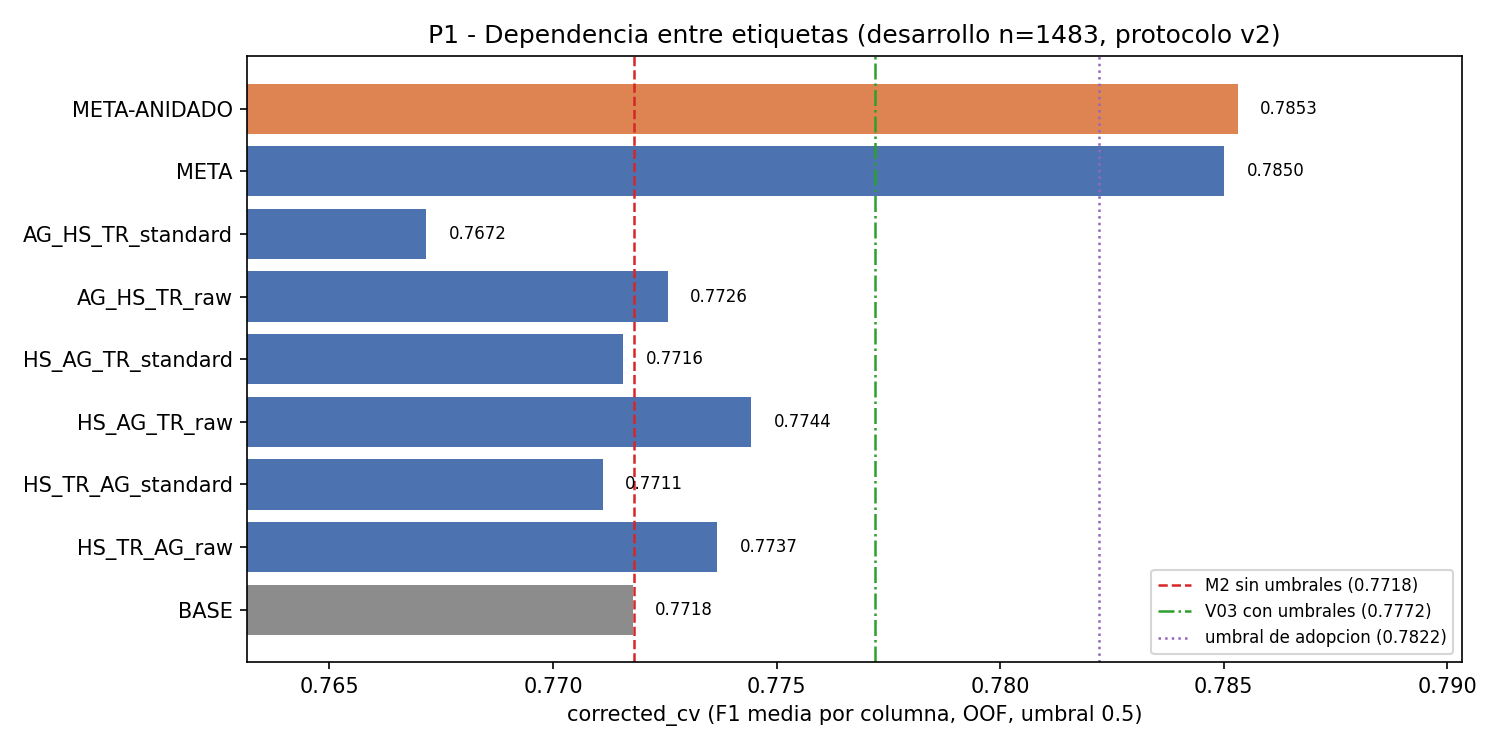

*Figura 10. Cadenas de etiquetas y meta-modelo de dependencia (P1): la dependencia solo aporta en el nivel meta. Elaboración propia con datos oficiales de la competencia.*

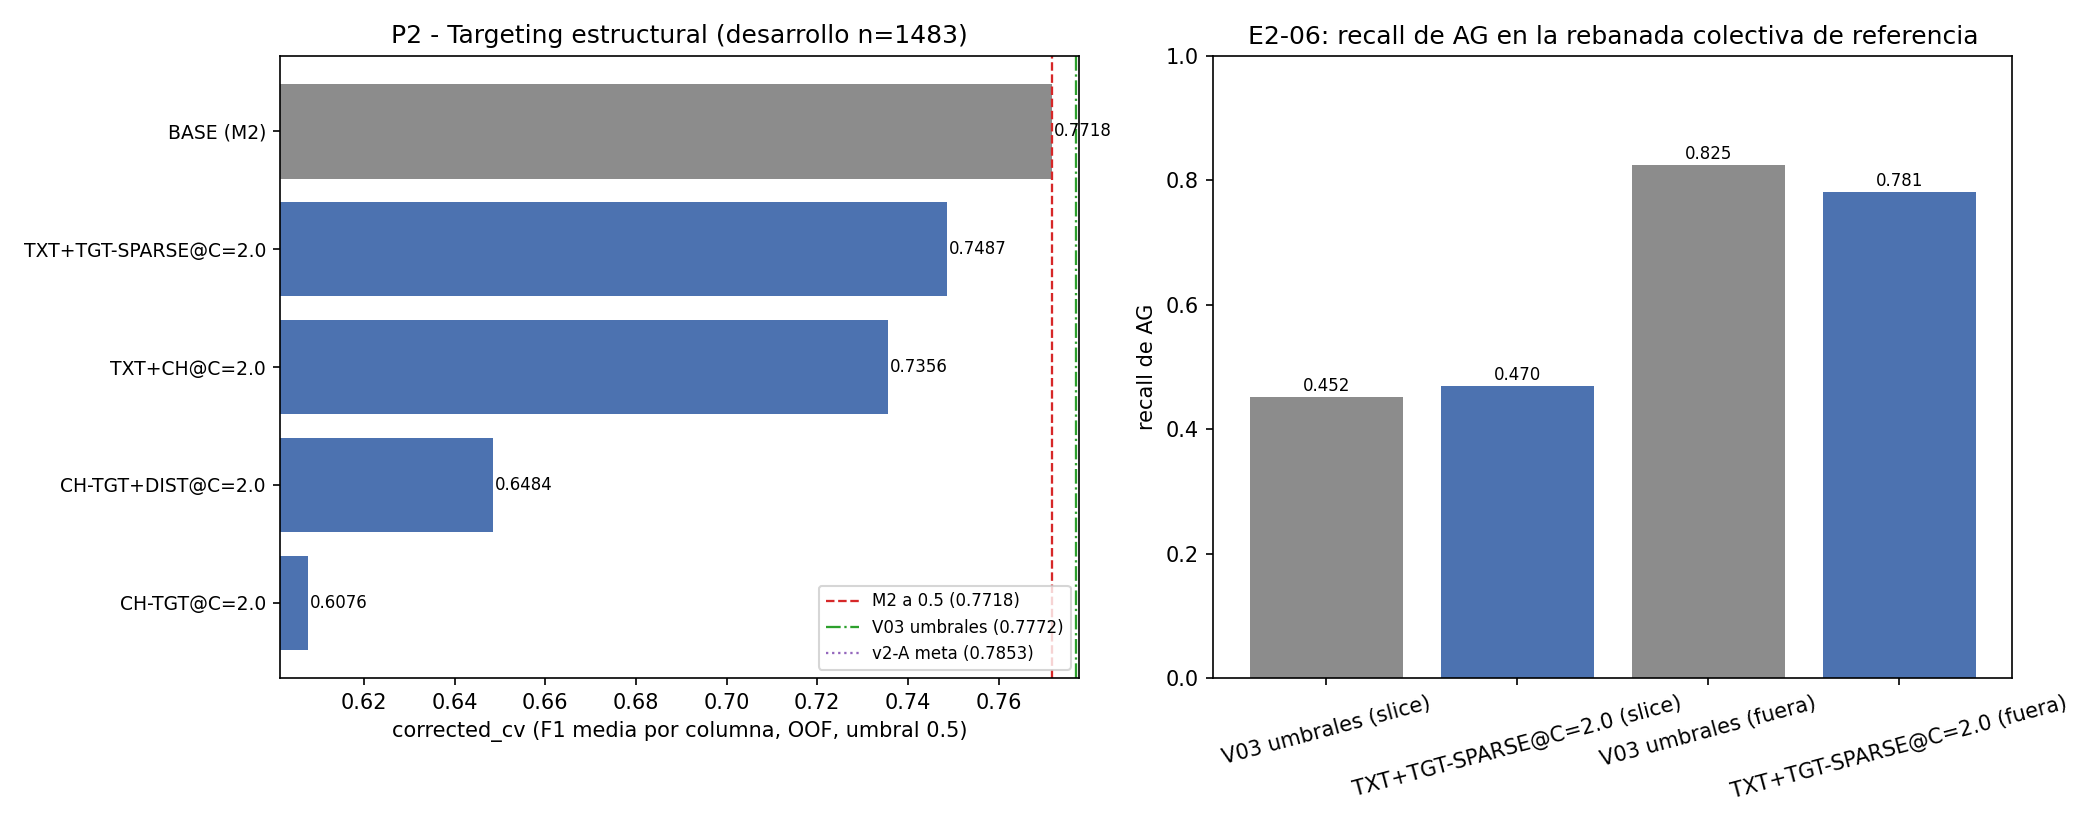

*Figura 11. Targeting estructural (P2): la concatenación de canales degrada el corrected_cv aunque suba el recall de AG en la rebanada colectiva. Elaboración propia con datos oficiales de la competencia.*

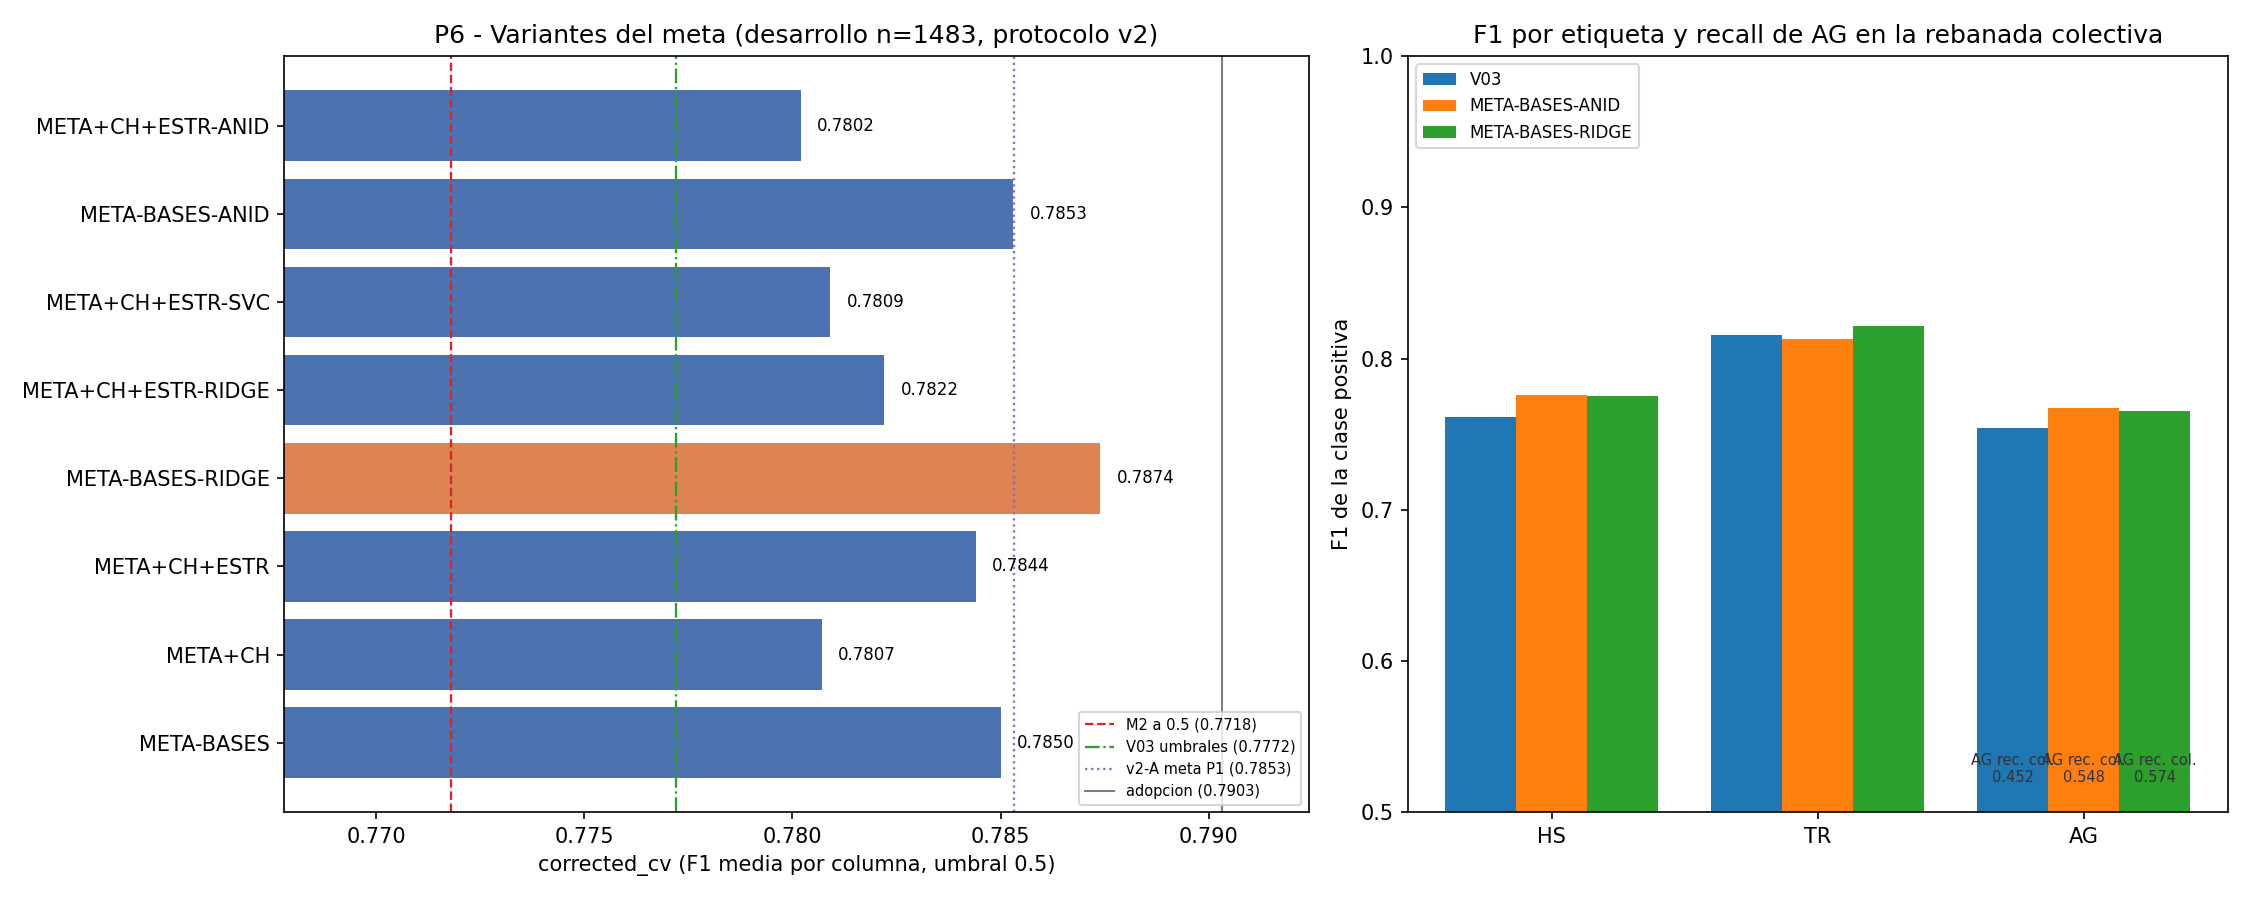

*Figura 12. Stacking v2 (P6): el meta Ridge es el mejor candidato en el desarrollo (0.7874) y el único adoptado por complementariedad. Elaboración propia con datos oficiales de la competencia.*

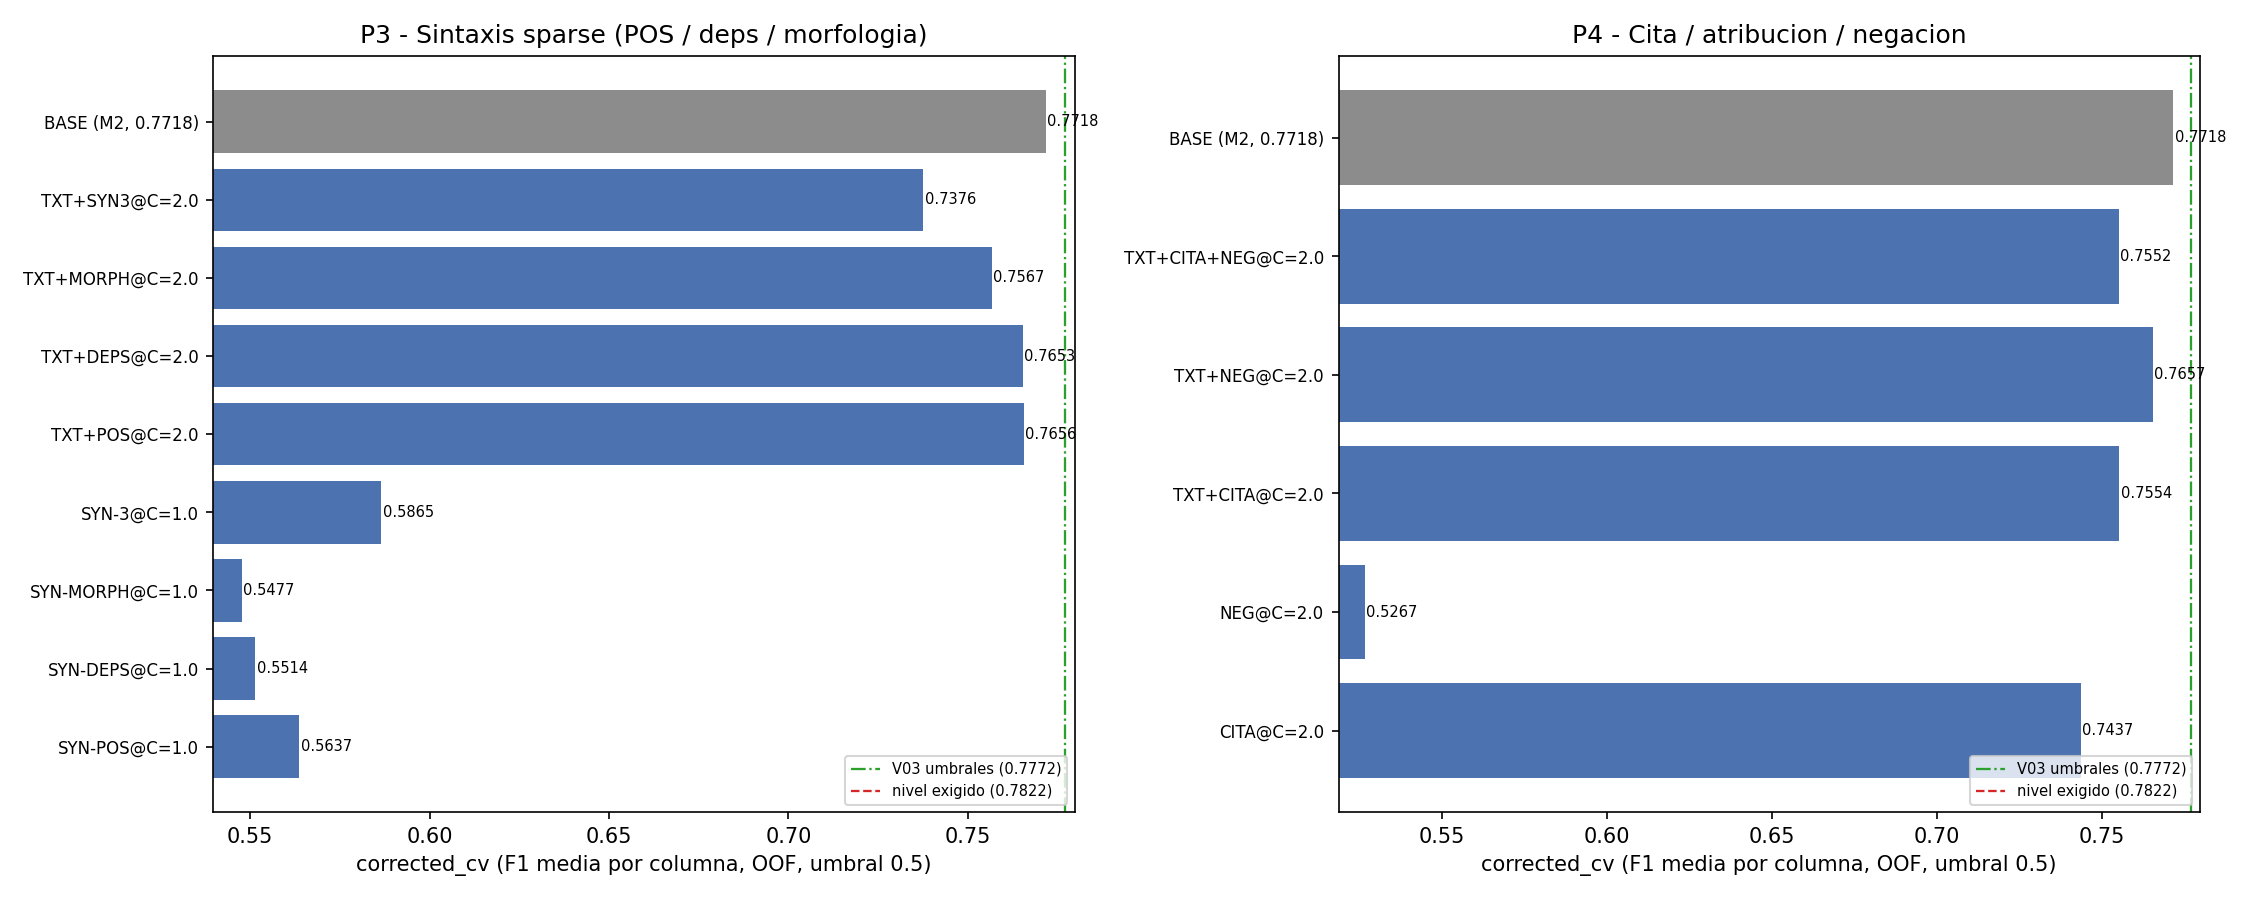

*Figura 13. Canales de sintaxis, cita/atribución y negación (P3-P4): todos por debajo de la referencia V03. Elaboración propia con datos oficiales de la competencia.*

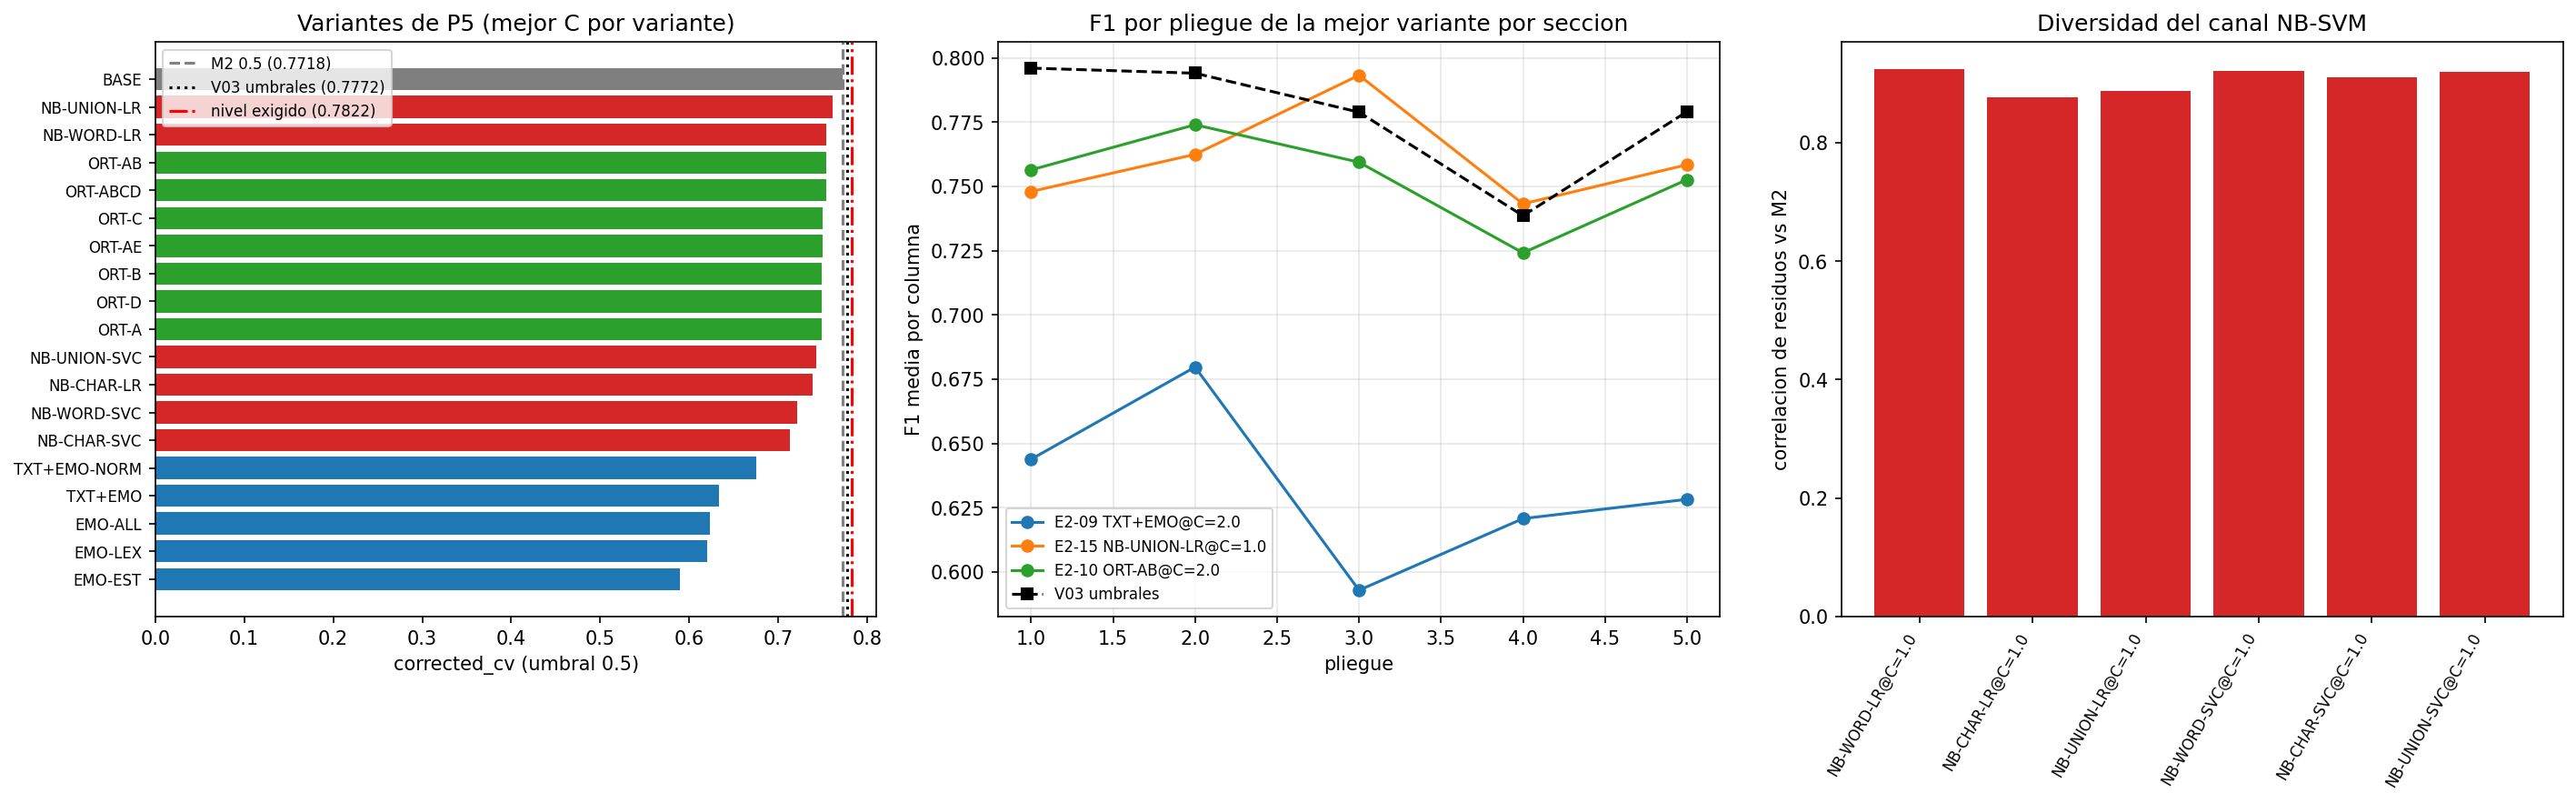

*Figura 14. Emoción, NB-SVM y multicanal ortográfico (P5): ninguno alcanza la referencia; el NB-unión es el más cercano. Elaboración propia con datos oficiales de la competencia.*

In [16]:
"""Figuras de la fase v2 (generadas por los scripts 15-20; se muestran, no se recalculan)."""

for nombre, pie in (
    ("fig_27_cadenas_v2.png",
     "Figura 10. Cadenas de etiquetas y meta-modelo de dependencia (P1): la dependencia solo aporta en el nivel meta. "
     "Elaboración propia con datos oficiales de la competencia."),
    ("fig_28_targeting_v2.png",
     "Figura 11. Targeting estructural (P2): la concatenación de canales degrada el corrected_cv aunque suba el recall de AG "
     "en la rebanada colectiva. Elaboración propia con datos oficiales de la competencia."),
    ("fig_29_stacking_v2.png",
     "Figura 12. Stacking v2 (P6): el meta Ridge es el mejor candidato en el desarrollo (0.7874) y el único adoptado por "
     "complementariedad. Elaboración propia con datos oficiales de la competencia."),
    ("fig_30_sintaxis_cita_v2.png",
     "Figura 13. Canales de sintaxis, cita/atribución y negación (P3-P4): todos por debajo de la referencia V03. "
     "Elaboración propia con datos oficiales de la competencia."),
    ("fig_31_emocion_nbsvm_v2.png",
     "Figura 14. Emoción, NB-SVM y multicanal ortográfico (P5): ninguno alcanza la referencia; el NB-unión es el más cercano. "
     "Elaboración propia con datos oficiales de la competencia."),
):
    mostrar_figura(nombre, pie)


## 11. Las 15 sondas de leaderboard y la lectura honesta del resultado

### OBSERVACIÓN

El proyecto gastó 15 envíos en el leaderboard público: 1 sonda de metrología (E00), 1 baseline, 5 variantes de la familia unión de la fase 1, 2 del ciclo v2 (v03 revalidada y el meta), 3 de la fase final de candidatos (metas restringidos sobre V03 + canales) y 3 de la fase v8 (promedio de pliegues, C por etiqueta y promedio de repeticiones). El máximo observado sigue siendo 0.78306 (v03): ninguna sonda posterior lo superó.

### HIPÓTESIS

El máximo de 15 mediciones ruidosas **no** es una estimación insesgada del rendimiento esperado: la selección del máximo infla el resultado (winner's curse). Si la hipótesis es correcta, el rango de la familia debe ser compatible con el error estándar de la métrica y el nivel esperado debe quedar por debajo del máximo.

### MÉTODO

Tabla completa de `submissions/leaderboard_log.csv` con el F1 local, el F1 de Kaggle, el gap y la decisión; cálculo de la media y el rango de la familia unión (v02-v08), del error estándar binomial aproximado con n = 1.154 y de la razón rango / error estándar. Identificación de los únicos contrastes pareados (mismo modelo o mismo pipeline cambiando una sola decisión).

### RESULTADO

| Sondeo | Local (OOF) | Kaggle | Gap (LB - local) | Descripción | Decisión |
|---|---|---|---|---|---|
| v00 (E00) | - | 0.51494 | - | Plantilla todo-1: identificación de la implementación de la métrica | Sonda de metrología (descartada como modelo) |
| v01 | 0.75778 | 0.75677 | -0.0010 | Baseline B1: TF-IDF word(1,2) + LR balanceada | Superada |
| v02 | 0.79270 | 0.77993 | -0.0128 | MOD-03b (unión word+char, LR C=2.0) sin umbrales | Control pareado de v03 |
| v03 | 0.79890 | **0.78306** | -0.0158 | MOD-03b con umbrales 0.44/0.51/0.46 | **Modelo final** |
| v04 | 0.79850 | 0.77510 | -0.0234 | Ensemble ENS-04 (M2+M3, umbrales medianos) | Descartado |
| v05 | 0.80390 | 0.77602 | -0.0279 | OPT-01 de Optuna (mejor OOF del proyecto) | Descartado |
| v06 | 0.79290 | 0.77227 | -0.0206 | Robustez C=1.0 (control de capacidad) | Descartado (D-013 refutada) |
| v07 | 0.79930 | 0.77034 | -0.0290 | Robustez min_df=5 (10.515 features) | Descartado (D-013 refutada) |
| v08 | 0.78740 | 0.78163 | -0.0058 | Meta v2 (Ridge alpha=3 sobre 44 meta-features) | No adoptado (D-020) |
| v09 | 0.78094 | 0.77895 | -0.0020 | C-EMO: V03 + emoción (meta restringido) | No superado (D-024) |
| v10 | 0.77931 | 0.77978 | +0.0005 | C-SYN: V03 + sintaxis (meta restringido) | No superado (D-024) |
| v11 | 0.77966 | 0.78150 | +0.0018 | C-EMO-SYN: V03 + emoción + sintaxis | No superado (D-024) |

Estadísticas de la familia unión (v02-v08, 7 variantes): media **0.7769**, mínimo 0.77034, máximo 0.78306, rango **0.01272**. Error estándar binomial aproximado con F1 ~ 0.78 y n = 1.154: **0.0122** -> el rango equivale a **1.04 errores estándar**.

### INTERPRETACIÓN

1. **Los 12 sondeos son estadísticamente indistinguibles** salvo en los contrastes pareados: el rango completo cabe en ~1 error estándar, así que ordenar las variantes por su puntaje de Kaggle no aporta información sobre cuál es mejor.
2. **Winner's curse**: con 7 variantes de la misma familia medidas con ruido, el máximo observado está sesgado al alza. La media de la familia (0.7769) es una estimación más razonable del nivel esperado del sistema que el máximo (0.78306).
3. **Los dos contrastes pareados fiables**: v02 frente a v03 (+0.0031; mismo modelo y mismos datos, solo cambian los umbrales) confirma que el ajuste de umbral es real; v03 frente a v08 (-0.0014; el meta v2 no supera al modelo final). Las demás diferencias mezclan cambios de modelo con ruido.
4. **El gap local-LB depende del pipeline, no del OOF**: v01 (-0.0010, 4.024 features), v03 (-0.0158, 27.431) y v05 (-0.0279, 32.060) muestran que el OOF premia la capacidad; v08 rompe el patrón con el gap **menos negativo** de todos los modelos grandes (-0.0058), porque su entrada (los scores de los bases) cambia de distribución entre el desarrollo y el test.
5. **La hipótesis de transferencia quedó refutada con evidencia pareada**: el meta mejoró en el desarrollo (+0.0102) y en el holdout congelado (+0.0180, IC [+0.0003, +0.0372]) y aun así perdió en el leaderboard. Una validación local, incluso con holdout, no garantiza transferencia con n = 248-1.483 y deltas del orden del error.


6. **Las tres sondas de la fase final no cambiaron la lectura**: v09/v10/v11 (V03 + canales, metas restringidos) obtuvieron 0.77895 / 0.77978 / 0.78150, las tres dentro de la banda y por debajo de v03; el ranking local volvió a no predecir el del LB (C-EMO era el mejor local de los tres y obtuvo el peor LB; C-EMO-SYN, el segundo local, obtuvo el mejor). Quedan fuera de la familia unión usada para las estadísticas.

### DECISIÓN

Mantener V03 como modelo final y de rollback; no volver a sondear el leaderboard (D-014, D-020 y D-024 vigentes; 12 sondas registradas); reportar 0.78306 como **cota superior sesgada por selección** acompañada del nivel esperado de la familia (~0.776-0.780).

### SIGUIENTE PASO

Analizar dónde falla el modelo final (sección 12).


In [17]:
"""Tabla completa de las 15 sondas de leaderboard y su lectura estadística.

Reconstruye el gap cuando falta, agrega las decisiones por sondeo y verifica que
los recuentos y las estadísticas declaradas coinciden con el registro.
"""

import pandas as pd

leaderboard = pd.read_csv(RUTAS["submissions"] / "leaderboard_log.csv")

DESCRIPCIONES = {
    "v00_plantilla": "Plantilla todo-1 (sonda E00 de metrologia)",
    "v01_baseline_tfidf_lr": "Baseline B1: TF-IDF word(1,2) + LR balanceada",
    "v02_lr_union": "MOD-03b (union word+char, LR C=2.0) sin umbrales",
    "v03_lr_union_thr": "MOD-03b con umbrales 0.44/0.51/0.46",
    "v04_ens04_mediana": "Ensemble ENS-04 (M2+M3, umbrales medianos)",
    "v05_optuna": "OPT-01 de Optuna (mejor OOF del proyecto)",
    "v06_robustez_c1": "Robustez C=1.0 (control de capacidad)",
    "v07_robustez_mindf5": "Robustez min_df=5 (10.515 features)",
    "v08_meta_v2": "Meta v2: Ridge alpha=3 sobre 44 meta-features",
    "v09_candidate_a": "C-EMO: V03 + emocion (meta restringido)",
    "v10_candidate_b": "C-SYN: V03 + sintaxis (meta restringido)",
    "v11_candidate_c": "C-EMO-SYN: V03 + emocion + sintaxis (meta restringido)",
    "v08_p1_fold_ensemble": "Promedio de modelos por pliegue (fase v8, P1)",
    "v09_p5_c_por_etiqueta": "C por etiqueta con correccion (fase v8, P5)",
    "v12_p7_promedio_repeticiones": "Promedio de repeticiones (fase v8, P7)",
}
DECISIONES = {
    "v00_plantilla": "Sonda de metrologia (no es un modelo)",
    "v01_baseline_tfidf_lr": "Superada",
    "v02_lr_union": "Control pareado de v03",
    "v03_lr_union_thr": "MODELO FINAL (vigente)",
    "v04_ens04_mediana": "Descartado",
    "v05_optuna": "Descartado",
    "v06_robustez_c1": "Descartado (D-013 refutada)",
    "v07_robustez_mindf5": "Descartado (D-013 refutada)",
    "v08_meta_v2": "No adoptado (D-020)",
    "v09_candidate_a": "Sonda enviada: LB 0.77895 (no supera V03, D-024)",
    "v10_candidate_b": "Sonda enviada: LB 0.77978 (no supera V03, D-024)",
    "v11_candidate_c": "Sonda enviada: LB 0.78150 (no supera V03, D-024)",
    "v08_p1_fold_ensemble": "Sonda v8 enviada: LB 0.77470 (no supera V03)",
    "v09_p5_c_por_etiqueta": "Sonda v8 enviada: LB 0.77781 (no supera V03)",
    "v12_p7_promedio_repeticiones": "Sonda v8 enviada: LB 0.77122 (no supera V03)",
}

tabla = leaderboard[["submission_id", "local_f1", "kaggle_f1", "diferencia"]].copy()
tabla["descripcion"] = tabla["submission_id"].map(DESCRIPCIONES)
tabla["decision"] = tabla["submission_id"].map(DECISIONES)
tabla["gap_recalculado"] = (tabla["kaggle_f1"] - tabla["local_f1"]).round(5)
tabla["definicion"] = leaderboard["definicion_diferencia"]  # B-12: semantica declarada del log

print("=" * 130)
print("LAS 15 SONDAS DE LEADERBOARD (registro completo en submissions/leaderboard_log.csv)")
print("=" * 130)
print(tabla.to_string(index=False, max_colwidth=44))

assert len(tabla) == 15, "El proyecto declara 15 sondas de leaderboard"
assert float(tabla["kaggle_f1"].max()) == 0.78306
assert tabla.loc[tabla["kaggle_f1"].idxmax(), "submission_id"] == "v03_lr_union_thr"
assert abs(float(tabla["gap_recalculado"].dropna().iloc[0]) - float(tabla["diferencia"].dropna().iloc[0])) < 1e-9
assert tabla["submission_id"].is_unique

familia = tabla.dropna(subset=["kaggle_f1"])
NOMBRES_UNION = ["v02_lr_union", "v03_lr_union_thr", "v04_ens04_mediana", "v05_optuna",
                 "v06_robustez_c1", "v07_robustez_mindf5", "v08_meta_v2"]
familia_union = familia[familia["submission_id"].isin(NOMBRES_UNION)]
media = float(familia_union["kaggle_f1"].mean())
minimo = float(familia_union["kaggle_f1"].min())
maximo = float(familia_union["kaggle_f1"].max())
rango = maximo - minimo
error_estandar = (0.78 * 0.22 / 1154) ** 0.5
print("\nLectura estadistica de la familia union (v02-v08, n = 7 variantes):")
print(f"  media {media:.4f} | minimo {minimo:.5f} | maximo {maximo:.5f} | rango {rango:.5f}")
print(f"  error estandar binomial aproximado (F1~0.78, n=1154): {error_estandar:.4f} -> {rango / error_estandar:.2f} errores estandar")
print(f"  lectura: el maximo observado esta sesgado al alza por seleccion (winner's curse); "
      f"el nivel esperado de la familia es ~{media:.3f}-0.780, no el maximo")
assert abs(media - 0.7769) < 5e-5, "La media declarada de la familia union es 0.7769"
assert (minimo, maximo) == (0.77034, 0.78306), "La banda declarada es 0.77034-0.78306"
assert rango / error_estandar < 1.1, "El rango debe caber en ~1 error estandar"

contrastes = [
    ("v02 vs v03 (umbrales, mismo modelo)", 0.78306 - 0.77993),
    ("v03 vs v08 (meta v2, mismo pipeline de texto)", 0.78163 - 0.78306),
]
print("\nContrastes pareados fiables:")
for nombre, delta in contrastes:
    print(f"  {nombre}: {delta:+.5f}")
assert abs((0.78306 - 0.77993) - 0.00313) < 1e-5
assert abs((0.78163 - 0.78306) + 0.00143) < 1e-5


LAS 15 SONDAS DE LEADERBOARD (registro completo en submissions/leaderboard_log.csv)
               submission_id  local_f1  kaggle_f1  diferencia                                  descripcion                                     decision  gap_recalculado   definicion
               v00_plantilla       NaN    0.51494         NaN   Plantilla todo-1 (sonda E00 de metrologia)        Sonda de metrologia (no es un modelo)              NaN   LB - local
       v01_baseline_tfidf_lr  0.757780    0.75677    -0.00101 Baseline B1: TF-IDF word(1,2) + LR balanc...                                     Superada         -0.00101   LB - local
                v02_lr_union  0.792700    0.77993    -0.01277 MOD-03b (union word+char, LR C=2.0) sin u...                       Control pareado de v03         -0.01277   LB - local
            v03_lr_union_thr  0.798900    0.78306    -0.01584          MOD-03b con umbrales 0.44/0.51/0.46                       MODELO FINAL (vigente)         -0.01584   LB - local
      

## 12. Análisis de error: rebanadas débiles, patrones cualitativos e hipótesis H11-H15

### OBSERVACIÓN

El F1 global esconde una fuerte heterogeneidad: el modelo es excelente en respuestas cortas entre usuarios y mucho más débil en textos largos con URL, hashtag o pregunta, donde el texto cita o describe odio ajeno.

### HIPÓTESIS

El error se concentra en dos regímenes: (a) **falsos positivos** de insulto interpersonal en registro de broma o afiliación (40.5 % de los textos con insulto, mención inicial y sin referencia colectiva están etiquetados (0,0,0)); (b) **falsos negativos** de odio implícito contra grupos sin insulto del léxico (45.5 % de los FN de AG tiene referencia colectiva frente al 13.9 % de los TP) y de noticia o atribución a terceros.

### MÉTODO

18 rebanadas definidas con expresiones regulares y spaCy (POS y lemas, sin vectores), exigiendo n >= 40 para entrar en el ranking y separando las rebanadas que usan el léxico inducido in-sample; 7 regiones definidas por combinación de rasgos; exportación de 15 falsos positivos y 15 falsos negativos por etiqueta para revisión cualitativa.

### RESULTADO

Rebanadas más débiles (F1 medio por columnas, umbrales por etiqueta): hashtags 0.586 (n = 161), preguntas 0.633 (n = 158), referencia colectiva 0.639 (n = 418), cuartil largo Q4 0.645 (n = 432), sin mención 0.697 (n = 909). El régimen noticia (URL o hashtag, n = 599) rinde 0.702 frente a 0.829 sin URL ni hashtag; los textos muy cortos (<= 40 caracteres, n = 154) alcanzan 0.944. Con umbrales por etiqueta hay 425 falsos positivos y 375 falsos negativos sobre 3 x 1.731 decisiones; 101 ejemplos (5.8 %) fallan las tres etiquetas.

### INTERPRETACIÓN

1. **Registro bromista/afectivo**: el insulto con vocativo, posesivos de primera persona ("mi novia", "mi perra") o risa se dispara con probabilidad 0.87-0.97 en las tres etiquetas y la anotación lo considera no odioso. Un modelo lineal sobre bolsas de n-gramas no puede representar la conjunción que desactiva la toxicidad.
2. **Odio implícito**: estereotipos, estigmatización y deshumanización sin palabras del léxico no activan HS ni AG; el modelo necesita el insulto explícito.
3. **Régimen noticia**: el vocabulario noticioso comparte términos con el odio (gentilicios, migración) y el modelo no distingue uso de mención ni atribución a terceros.
4. **Frontera de anotación no observable**: hay pares de textos casi idénticos con etiquetas opuestas; la frontera depende de quién habla, a quién y con qué intención, información que no está en el texto. Esto acota el techo alcanzable con estas features.

### DECISIÓN

Convertir los patrones dominantes en hipótesis dirigidas (H11-H15) en lugar de seguir ampliando la representación a ciegas. Las tres primeras se ejecutaron como features densas (sección 7) y **no se validaron** (-0.009 a -0.032); en la fase v2 se ejecutaron además H13 (cita/atribución y negación, 0.7554 y 0.7657) y H5 (emoción, 0.6330), ambas **cerradas sin mejora** (sección 10). H15 (calibración por rebanada) queda como trabajo futuro documentado.

### SIGUIENTE PASO

Reconstruir y auditar el modelo final (sección 13).

Rebanadas más débiles (n >= 40, sin artefactos del léxico inducido):
                  rebanada grupo   n  f1_HS  f1_TR  f1_AG  f1_media  delta_vs_global
             tiene_hashtag     1 161 0.6222 0.5455 0.5902    0.5859          -0.2130
            tiene_pregunta     1 158 0.6815 0.6531 0.5634    0.6326          -0.1663
tiene_referencia_colectiva     1 418 0.6971 0.6437 0.5760    0.6389          -0.1600
          cuartil_longitud    Q4 432 0.6959 0.6286 0.6113    0.6453          -0.1537
             tiene_mencion     0 909 0.7032 0.7070 0.6810    0.6971          -0.1019

Rebanadas más fuertes (para contraste):
        rebanada grupo   n  f1_media  delta_vs_global
  texto_corto_40     1 154    0.9444           0.1455
cuartil_longitud    Q1 435    0.9134           0.1145
      tiene_risa     1 120    0.8757           0.0768

Regiones del corpus:
                           region    n  f1_HS  f1_TR  f1_AG  f1_media  delta_vs_global  prevalencia_real_TR  prevalencia_predicha_TR
         

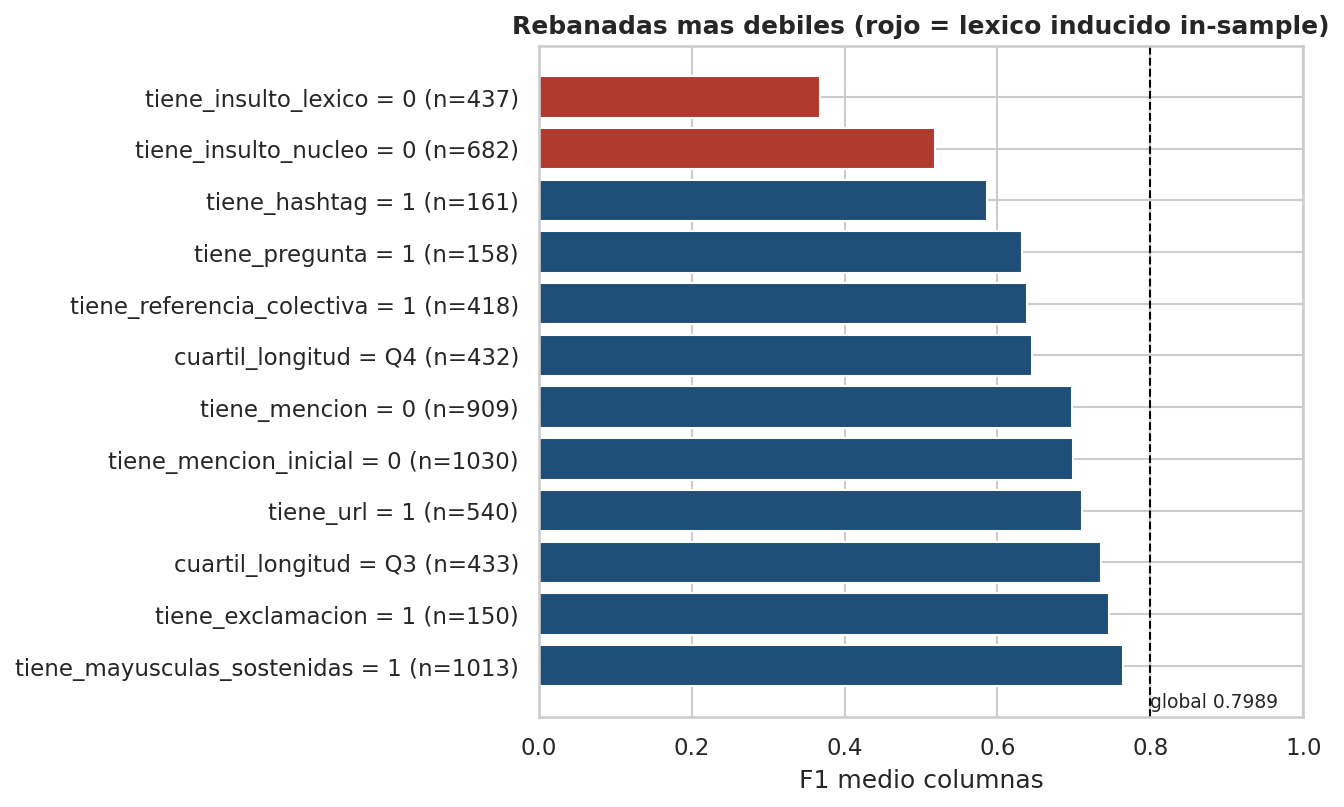

*Figura 7. Rebanadas más débiles del modelo final por etiqueta y en promedio. Elaboración propia con datos oficiales de la competencia.*

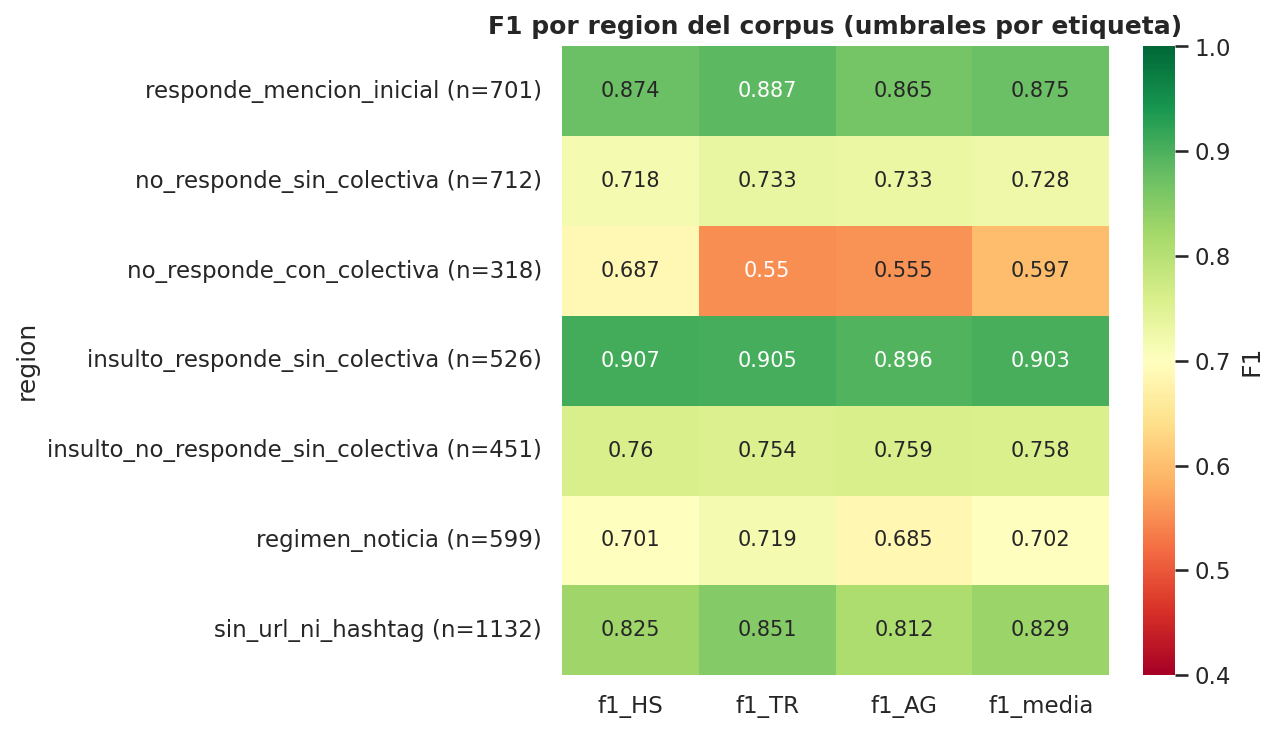

*Figura 8. F1 por región del corpus (respuesta directa frente a noticia o referencia colectiva). Elaboración propia con datos oficiales de la competencia.*

In [18]:
"""Rebanadas débiles, regiones del corpus y matrices de confusión del modelo final."""

import pandas as pd

rebanadas = pd.read_csv(RUTAS["reports"] / "eda" / "error_rebanadas.csv")
regiones = pd.read_csv(RUTAS["reports"] / "eda" / "error_regiones.csv")

evaluables = rebanadas[(rebanadas["estado"] == "ok") & (rebanadas["n"] >= 40) & (~rebanadas["artefacto_lexico"].astype(bool))]

print("Rebanadas más débiles (n >= 40, sin artefactos del léxico inducido):")
print(
    evaluables.sort_values("f1_media")[["rebanada", "grupo", "n", "f1_HS", "f1_TR", "f1_AG", "f1_media", "delta_vs_global"]]
    .head(5)
    .round(4)
    .to_string(index=False)
)

print("\nRebanadas más fuertes (para contraste):")
print(
    evaluables.sort_values("f1_media", ascending=False)[["rebanada", "grupo", "n", "f1_media", "delta_vs_global"]]
    .head(3)
    .round(4)
    .to_string(index=False)
)

print("\nRegiones del corpus:")
columnas_region = ["region", "n", "f1_HS", "f1_TR", "f1_AG", "f1_media", "delta_vs_global", "prevalencia_real_TR", "prevalencia_predicha_TR"]
print(regiones[columnas_region].round(4).to_string(index=False))

mostrar_figura(
    "fig_23_rebanadas_mas_debiles.png",
    "Figura 7. Rebanadas más débiles del modelo final por etiqueta y en promedio. "
    "Elaboración propia con datos oficiales de la competencia.",
)
mostrar_figura(
    "fig_24_regiones_f1.png",
    "Figura 8. F1 por región del corpus (respuesta directa frente a noticia o referencia colectiva). "
    "Elaboración propia con datos oficiales de la competencia.",
)

### Hipótesis derivadas del análisis de error

| id | Enunciado | Experimento | Resultado |
|---|---|---|---|
| H11 | Los falsos positivos de HS y AG se concentran en el insulto interpersonal que la anotación considera no odioso (broma, afiliación); un bloque de interacciones de registro los reduce | EXP-14a (bloque denso H11) | **No validada**: HIB-H11 0.7713 (-0.0213 vs MOD-03b) |
| H12 | El error de TR vive en los textos sin destinatario explícito (individuo frente a colectivo) | EXP-14b (bloque denso H12) y E2-05/E2-06 (fase v2) | **No validada**: HIB-H12 0.7836 (-0.0091); en la fase v2 el canal de targeting estructural llega a 0.7487 (-0.0285) |
| H13 | El modelo es fuerte en respuesta y débil en noticia/comentario, donde cita odio ajeno | EXP-14c (bloque de cita/atribución) y E2-07/E2-08 (fase v2) | **Ejecutada y no validada**: unión + cita 0.7554 (-0.0218) y unión + negación 0.7657 (-0.0115) |
| H14 | Los falsos negativos de AG son agresión implícita sin insulto del léxico | EXP-14d (léxico de deshumanización) | **No validada**: HIB-H14 0.7630 (-0.0297) |
| H15 | Ajustar el umbral por etiqueta y por rebanada no aporta una mejora explotable | EXP-14e (calibración por rebanada); E2-16/E2-22 (backlog v2) | Umbral global por etiqueta **confirmado** (+0.0031 pareado en el LB); la calibración por rebanada queda no ejecutada (trabajo futuro) |

**Regla de decisión vigente (D-016)**: una mejora se adopta con >= +0.005 absoluto en `corrected_cv` y mejora en >= 3/5 pliegues, o con complementariedad demostrada (`ensemble_gain` >= 0.0015 con IC bootstrap > 0). Por D-012/D-014 se exige >= +0.010 local en la familia unión antes de gastar una sonda de leaderboard.


## 13. Modelo final: MOD-03b_BEST con umbrales por etiqueta (el candidato de la fase v2 no se adoptó)

### OBSERVACIÓN

El modelo final debe poder reconstruirse desde su artefacto (`models/mod03b_lr_union.joblib`) sin reentrenar y reproducir exactamente la submission vigente.

### HIPÓTESIS

El artefacto guardado (vectorizador + tres clasificadores + umbrales) reproduce la submission v03 fila a fila y, por tanto, el LB 0.78306.

### MÉTODO

Carga del joblib, `transform` del test (nunca `fit`), `predict_proba` por etiqueta y comparación con `submissions/toxic_submission_v03_lr_union_thr.csv`. Verificación paralela de las métricas OOF guardadas en `features/oof_mod03b.npz` con `src.evaluation`.

### RESULTADO

**Configuración final**:

| Elemento | Valor |
|---|---|
| Representación | Unión TF-IDF: `word(1,2)` min_df=2 + `char_wb(3,5)` min_df=2, `sublinear_tf=True` |
| Dimensión | 27.431 features (4.024 de palabra + 23.407 de carácter) |
| Modelo | `LogisticRegression(C=2.0, class_weight="balanced", solver="liblinear")` x 3 (HS, TR, AG) |
| Umbrales | HS 0.44 / TR 0.51 / AG 0.46 (optimizados sobre probabilidades OOF, D-012) |
| F1 OOF | 0.7927 con umbral 0.5 | 0.7989 con umbrales |
| F1 leaderboard | 0.77993 (umbral 0.5) | **0.78306 (umbrales)** |
| Artefacto | `models/mod03b_lr_union.joblib` (generado por `experiments/04_refit_submissions_v02_v03.py`) |
| Candidato fase v2 (D-019/D-020) | meta Ridge alpha=3 sobre 44 meta-features: 0.7874 en el desarrollo del protocolo v2 y 0.8465 en el holdout congelado (+0.0180 pareado) | LB **0.78163**: no adoptado |

### INTERPRETACIÓN

Los umbrales por etiqueta son la única palanca adoptada con evidencia pareada: +0.0031 en el leaderboard con el mismo modelo. La ganancia optimista medida en el mismo OOF con el que se eligieron era +0.0063 y la estimación anidada independiente +0.0014; el valor real (+0.0031) cae entre ambas, tal como anticipaba la advertencia de sesgo.

**Fase v2**: el candidato meta (0.7874 en el desarrollo del protocolo v2 y 0.8465 en el holdout congelado, +0.0180 pareado) no superó el leaderboard (0.78163 frente a 0.78306) y no se adoptó (D-020). Su gap dev-LB (-0.0058) es el menos negativo de todos los modelos grandes, lo que apunta a un cambio de calibración de sus entradas: el meta se ajusta con scores OOF de bases entrenados en 4/5 del desarrollo y predice el test con bases entrenados con todo el train (limitación 8 de la sección 15).

### DECISIÓN

Se mantiene MOD-03b_BEST con umbrales (v03) como **modelo final y submission de rollback**. Está prohibido re-optimizar umbrales contra el leaderboard.

### SIGUIENTE PASO

Verificar la reproducibilidad de las cifras clave (sección 14).

Probabilidades OOF: 1731 filas x 3 etiquetas ['HS', 'TR', 'AG']
Ids alineados con train: True

Metricas OOF recalculadas (referencia publicada: 0.7927 y 0.7989):
              escenario  f1_media_columnas  f1_HS  f1_TR  f1_AG  f1_macro6  f1_micro  exact_match
             umbral 0.5             0.7927 0.7799 0.8287 0.7694     0.8349    0.7898       0.7314
umbrales 0.44/0.51/0.46             0.7989 0.7897 0.8296 0.7774     0.8356    0.7961       0.7256


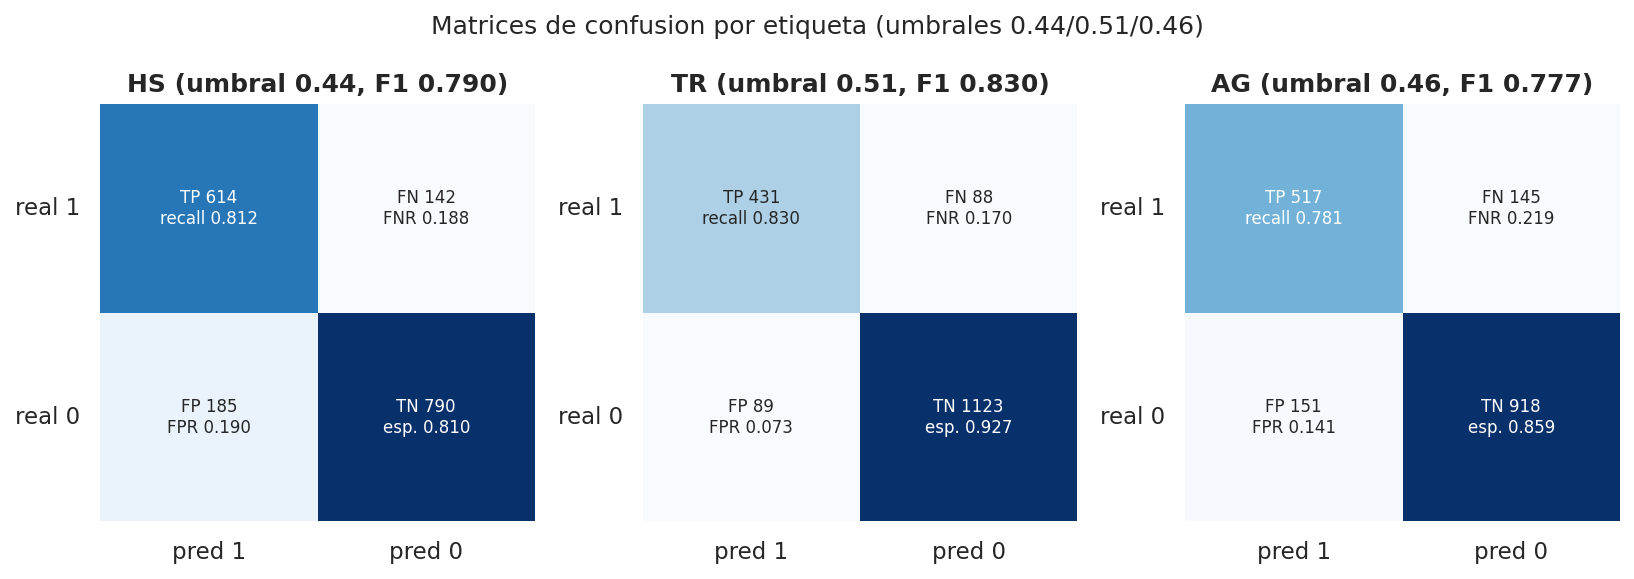

*Figura 9. Matrices de confusión por etiqueta con los umbrales óptimos (escenario del modelo final). Elaboración propia con datos oficiales de la competencia.*

In [19]:
"""Verificación de las métricas OOF del modelo final con src.evaluation.

Recalcula la métrica primaria sobre las probabilidades out-of-fold guardadas,
con umbral 0.5 y con los umbrales por etiqueta. No reentrena nada.
"""

import numpy as np
import pandas as pd

from src.evaluation import metricas_multietiqueta

oof = np.load(RUTAS["features"] / "oof_mod03b.npz", allow_pickle=False)
ids_oof, y_true, proba, etiquetas = oof["ids"], oof["y_true"], oof["proba"], oof["etiquetas"]
umbrales = {"HS": 0.44, "TR": 0.51, "AG": 0.46}

print(f"Probabilidades OOF: {proba.shape[0]} filas x {proba.shape[1]} etiquetas {list(etiquetas)}")
print(f"Ids alineados con train: {bool((ids_oof.astype(int) == train['id'].astype(int).to_numpy()).all())}")

pred_05 = (proba >= 0.5).astype(int)
pred_umbrales = np.column_stack(
    [(proba[:, indice] >= umbrales[etiqueta]).astype(int) for indice, etiqueta in enumerate(etiquetas)]
)

filas = []
for nombre, prediccion in (("umbral 0.5", pred_05), ("umbrales 0.44/0.51/0.46", pred_umbrales)):
    metricas = metricas_multietiqueta(y_true, prediccion)
    filas.append(
        {
            "escenario": nombre,
            "f1_media_columnas": round(metricas["f1_media_columnas"], 4),
            "f1_HS": round(metricas["f1_por_etiqueta"]["HS"], 4),
            "f1_TR": round(metricas["f1_por_etiqueta"]["TR"], 4),
            "f1_AG": round(metricas["f1_por_etiqueta"]["AG"], 4),
            "f1_macro6": round(metricas["f1_macro6"], 4),
            "f1_micro": round(metricas["f1_micro"], 4),
            "exact_match": round(metricas["exact_match"], 4),
        }
    )
print("\nMetricas OOF recalculadas (referencia publicada: 0.7927 y 0.7989):")
print(pd.DataFrame(filas).to_string(index=False))

mostrar_figura(
    "fig_21_matrices_confusion_umbrales_optimos.png",
    "Figura 9. Matrices de confusión por etiqueta con los umbrales óptimos (escenario del modelo final). "
    "Elaboración propia con datos oficiales de la competencia.",
)

In [20]:
"""Reconstrucción del modelo final y reproducción exacta de la submission v03.

Carga el artefacto, transforma el test (sin fit), aplica los umbrales por
etiqueta y compara con la submission vigente. El notebook no escribe archivos:
la regeneración opcional se documenta en la sección 12.
"""

import joblib
import numpy as np
import pandas as pd

artefacto = joblib.load(RUTAS["models"] / "mod03b_lr_union.joblib")

print("Contenido del artefacto models/mod03b_lr_union.joblib:")
for clave in ("representacion", "modelo", "dimension", "f1_oof", "entrenado_con", "fecha", "script"):
    print(f"  {clave}: {artefacto[clave]}")
print(f"  umbrales: {artefacto['umbrales']} (usar_umbrales_optimizados={artefacto['usar_umbrales_optimizados']})")

matriz_test = artefacto["vectorizador"].transform(test["text"])
probabilidades_test = np.column_stack(
    [modelo.predict_proba(matriz_test)[:, 1] for modelo in artefacto["modelos"]]
)
etiquetas_modelo = list(artefacto["etiquetas"])
prediccion_test = np.column_stack(
    [
        (probabilidades_test[:, indice] >= artefacto["umbrales"][etiqueta]).astype(int)
        for indice, etiqueta in enumerate(etiquetas_modelo)
    ]
)

reconstruida = pd.DataFrame(
    {"id": test["id"].astype(int), "HS": prediccion_test[:, 0], "TR": prediccion_test[:, 1], "AG": prediccion_test[:, 2]}
)
comparacion = (reconstruida.to_numpy() != submission_v03.to_numpy()).any(axis=1)

print(f"\nDimension de la matriz de test transformada: {matriz_test.shape} (esperado 1154 x 27431)")
print(f"Filas distintas frente a submissions/{SUBMISSION_VIGENTE}: {int(comparacion.sum())}")
print("La reconstruccion reproduce la submission v03 exactamente." if not comparacion.any()
      else "ATENCION: la reconstruccion NO coincide con la submission vigente.")

print("\nTasas de positivos predichas en test frente a la prevalencia de train:")
resumen = pd.DataFrame(
    {
        "train": [round(float(train[etiqueta].mean()), 4) for etiqueta in etiquetas_modelo],
        "test_predicho": [round(float(reconstruida[etiqueta].mean()), 4) for etiqueta in etiquetas_modelo],
        "positivos_test": [int(reconstruida[etiqueta].sum()) for etiqueta in etiquetas_modelo],
    },
    index=etiquetas_modelo,
)
print(resumen.to_string())

Contenido del artefacto models/mod03b_lr_union.joblib:
  representacion: union TF-IDF word (1,2) + char_wb (3,5), min_df=2, sublinear_tf
  modelo: LogisticRegression(class_weight=balanced, C=2.0, liblinear) x3
  dimension: 27431
  f1_oof: 0.7926588861781015
  entrenado_con: todo el train (1731 filas)
  fecha: 2026-09-22
  script: experiments/04_refit_submissions_v02_v03.py
  umbrales: {'HS': 0.44, 'TR': 0.51, 'AG': 0.46} (usar_umbrales_optimizados=True)

Dimension de la matriz de test transformada: (1154, 27431) (esperado 1154 x 27431)
Filas distintas frente a submissions/toxic_submission_v03_lr_union_thr.csv: 0
La reconstruccion reproduce la submission v03 exactamente.

Tasas de positivos predichas en test frente a la prevalencia de train:
     train  test_predicho  positivos_test
HS  0.4367         0.4385             506
TR  0.2998         0.2894             334
AG  0.3824         0.3657             422


## 14. Verificación de reproducibilidad de los números clave

### OBSERVACIÓN

Un informe con 24 líneas de investigación y 128 filas de experimentos es difícil de auditar a mano. Las cifras que sostienen las conclusiones (el 0.7772 de V03 en el desarrollo, el 0.7853 / 0.7874 de los meta, la submission final y el holdout congelado) deben poder recomputarse desde los artefactos guardados.

### HIPÓTESIS

Los artefactos persistidos (NPZ de probabilidades OOF, joblib del modelo final, JSON de los informes y CSV de la partición) son suficientes para reproducir exactamente las cifras declaradas sin reentrenar ningún modelo.

### MÉTODO

(a) F1 media por columnas de V03 en el desarrollo desde `features/v2_oof_base_corrected.npz` con los umbrales 0.44/0.51/0.46; (b) F1 del meta adoptado en P6 desde `features/v2_meta_oof.npz` y contraste del meta v2-A con su valor exacto registrado en los informes (su OOF estrictamente anidado exige reentrenar los 4 bases por pliegue, 244 s, y el notebook no reentrena); (c) reconstrucción byte a byte de la submission v03 desde `models/mod03b_lr_union.joblib`; (d) sha256 de la partición del holdout frente a `config/holdout_v2.json`; (e) recuentos declarados (118 experimentos, 9 sondas, 23 scripts). Tolerancia 1e-6 en F1; comparación exacta en hashes, ids y recuentos.

### RESULTADO

Ver la salida de la celda siguiente: todas las comprobaciones pasan.

### INTERPRETACIÓN

La reproducibilidad es una propiedad verificable del entregable, no una declaración: cualquier revisor puede ejecutar esta celda y obtener los mismos asserts. El notebook no reejecuta Optuna, ni los barridos, ni el anidamiento de P1, ni el stacking; aun así cubre las cifras centrales de las dos fases.

### DECISIÓN

Mantener esta celda como puerta de calidad: si alguna cifra del informe cambia sin actualizar los artefactos, el notebook falla de forma explícita.

### SIGUIENTE PASO

Limitaciones y conclusiones (sección 15).


In [21]:
"""Verificación de reproducibilidad de los números clave del proyecto.

Recomputa, a partir de los artefactos guardados y sin reentrenar, las cifras que
sostienen el informe: la F1 de V03 en el desarrollo del protocolo v2, la del meta
adoptado en P6 (y el valor exacto del meta v2-A registrado en los informes), la
reconstrucción byte a byte de la submission final desde el joblib, el sha256 del
holdout y los recuentos declarados (219 filas de registro, 15 sondas, 39 scripts).

Nota sobre el artefacto del meta: features/v2_meta_oof.npz contiene el meta
ADOPTADO en P6 (META-BASES-RIDGE, 0.7874). El meta v2-A de P1 se verifica contra
su valor exacto registrado en reports/cadenas_etiquetas_v2.json y
reports/stacking_v2.json (0.7853), porque reproducir su OOF anidado exigiría
reentrenar los 4 bases por pliegue.

Raises:
    AssertionError: si alguna cifra recomputada no coincide con la declarada
        (tolerancia 1e-6 en F1, exacta en hashes, ids y recuentos).
"""

import hashlib
import io
import json

import joblib
import numpy as np
import pandas as pd

from src.evaluation import metricas_multietiqueta

TOLERANCIA_F1 = 1e-6
SUBMISSION_V03 = RUTAS["submissions"] / "toxic_submission_v03_lr_union_thr.csv"
SHA_SUBMISSION_V03 = "7d7478f271e6edfd51afff85bad3eaa0e39e6501d42d6346e29ef50ae874520e"
UMBRALES_V03 = np.array([0.44, 0.51, 0.46])


def verificar(nombre: str, valor: object, esperado: object, tolerancia: float = 0.0) -> None:
    """Comprueba un valor recalculado contra su referencia declarada.

    Args:
        nombre: descripción de la comprobación.
        valor: valor recalculado.
        esperado: valor declarado en el informe.
        tolerancia: diferencia absoluta máxima admitida (0.0 = comparación exacta).

    Returns:
        None. Imprime el resultado de la comprobación.

    Raises:
        AssertionError: si la diferencia supera la tolerancia.
    """
    if isinstance(esperado, (int, float)) and not isinstance(esperado, bool):
        diferencia = abs(float(valor) - float(esperado))
        assert diferencia <= tolerancia, (
            f"[FALLA] {nombre}: {valor!r} frente a {esperado!r} (diferencia {diferencia:.3e})"
        )
        print(f"  [OK] {nombre}: {float(valor):.6f} frente a {float(esperado):.6f} (diferencia {diferencia:.2e})")
    else:
        assert valor == esperado, f"[FALLA] {nombre}: {valor!r} frente a {esperado!r}"
        print(f"  [OK] {nombre}: {valor!r}")


print("=" * 110)
print("(a) F1 media por columnas de V03 (M2 con umbrales 0.44/0.51/0.46) en el desarrollo del protocolo v2")
print("=" * 110)
oof_bases = np.load(RUTAS["features"] / "v2_oof_base_corrected.npz", allow_pickle=False)
indice_m2 = int(np.flatnonzero(oof_bases["modelos"] == "M2_union_lr_c2")[0])
pred_v03 = (oof_bases["proba"][:, indice_m2, :] >= UMBRALES_V03[None, :]).astype(int)
metricas_v03 = metricas_multietiqueta(oof_bases["y_true"], pred_v03)
verificar("F1 de V03 en el desarrollo (valor exacto del informe)",
          metricas_v03["f1_media_columnas"], 0.7772114525165721, TOLERANCIA_F1)
verificar("F1 de V03 redondeada a 4 decimales", round(float(metricas_v03["f1_media_columnas"]), 4), 0.7772)
print(f"  desarrollo n = {len(oof_bases['y_true'])} | por etiqueta: HS {metricas_v03['f1_por_etiqueta']['HS']:.4f} / "
      f"TR {metricas_v03['f1_por_etiqueta']['TR']:.4f} / AG {metricas_v03['f1_por_etiqueta']['AG']:.4f}")

print("\n" + "=" * 110)
print("(b) Meta de la fase v2: adoptado en P6 (npz) y candidato v2-A de P1 (informes)")
print("=" * 110)
meta_oof = np.load(RUTAS["features"] / "v2_meta_oof.npz", allow_pickle=False)
verificar("variante guardada en features/v2_meta_oof.npz", str(meta_oof["variante"][0]), "META-BASES-RIDGE")
metricas_meta = metricas_multietiqueta(meta_oof["y_true"], (meta_oof["proba"] >= 0.5).astype(int))
verificar("F1 del meta P6 en el desarrollo (valor exacto)",
          metricas_meta["f1_media_columnas"], 0.7873574608549214, TOLERANCIA_F1)
verificar("F1 del meta P6 redondeada a 4 decimales", round(float(metricas_meta["f1_media_columnas"]), 4), 0.7874)
informe_stacking = json.loads((RUTAS["reports"] / "stacking_v2.json").read_text(encoding="utf-8"))
informe_cadenas = json.loads((RUTAS["reports"] / "cadenas_etiquetas_v2.json").read_text(encoding="utf-8"))
verificar("meta v2-A anidado declarado en stacking_v2.json",
          informe_stacking["reproduccion_p1_anidada"]["corrected_cv"], 0.7853201709584162, TOLERANCIA_F1)
verificar("meta v2-A declarado en cadenas_etiquetas_v2.json",
          informe_cadenas["meta_anidado"]["corrected_cv"], 0.7853201709584162, TOLERANCIA_F1)
verificar("meta v2-A redondeado a 4 decimales", round(float(informe_cadenas["meta_anidado"]["corrected_cv"]), 4), 0.7853)
verificar("meta v2-A con OOF congelado (cota sin anidamiento)",
          informe_cadenas["meta"]["corrected_cv"], 0.7850085565795801, TOLERANCIA_F1)
print(f"  el npz guarda el meta adoptado (0.7874); el candidato v2-A anidado (0.7853) y su version congelada (0.7850) "
      f"se verifican contra los informes, que registran su valor exacto")

print("\n" + "=" * 110)
print("(c) Reconstruccion byte a byte de la submission v03 desde models/mod03b_lr_union.joblib")
print("=" * 110)
artefacto = joblib.load(RUTAS["models"] / "mod03b_lr_union.joblib")
matriz_test = artefacto["vectorizador"].transform(test["text"])
probabilidades_test = np.column_stack([modelo.predict_proba(matriz_test)[:, 1] for modelo in artefacto["modelos"]])
etiquetas_modelo = list(artefacto["etiquetas"])
prediccion_test = np.column_stack(
    [(probabilidades_test[:, indice] >= artefacto["umbrales"][etiqueta]).astype(int)
     for indice, etiqueta in enumerate(etiquetas_modelo)]
)
reconstruida = plantilla.copy()
for indice, etiqueta in enumerate(etiquetas_modelo):
    reconstruida[etiqueta] = prediccion_test[:, indice]
buffer_csv = io.StringIO()
reconstruida.to_csv(buffer_csv, index=False, encoding="utf-8")
bytes_reconstruidos = buffer_csv.getvalue().encode("utf-8")
bytes_originales = SUBMISSION_V03.read_bytes()
verificar("sha256 de la submission reconstruida en memoria",
          hashlib.sha256(bytes_reconstruidos).hexdigest(), SHA_SUBMISSION_V03)
verificar("sha256 de la submission v03 en disco",
          hashlib.sha256(bytes_originales).hexdigest(), SHA_SUBMISSION_V03)
assert bytes_reconstruidos == bytes_originales, "[FALLA] La reconstruccion no coincide byte a byte con la submission"
print(f"  [OK] reconstruccion byte a byte: {len(bytes_reconstruidos)} bytes identicos | "
      f"{int(reconstruida[['HS', 'TR', 'AG']].to_numpy().sum())} positivos predichos en 1.154 filas x 3 etiquetas")

print("\n" + "=" * 110)
print("(d) sha256 de la particion del holdout congelado")
print("=" * 110)
config_holdout = json.loads((RUTAS["config"] / "holdout_v2.json").read_text(encoding="utf-8"))
verificar("sha256 de data/processed/holdout_v2_ids.csv",
          hashlib.sha256((RUTAS["data"] / "processed" / "holdout_v2_ids.csv").read_bytes()).hexdigest(),
          config_holdout["hash_ids_csv"])
verificar("tamano del desarrollo declarado", config_holdout["n_tweets_dev"], 1483)
verificar("tamano del holdout declarado", config_holdout["n_tweets_holdout"], 248)

print("\n" + "=" * 110)
print("(e) Recuentos declarados en el informe")
print("=" * 110)
experimentos = pd.read_csv(PROJECT_ROOT / "experiments.csv")
sondas = pd.read_csv(RUTAS["submissions"] / "leaderboard_log.csv")
scripts = sorted(p.name for p in RUTAS["experiments"].glob("[0-9][0-9]_*.py"))
verificar("filas de experiments.csv", len(experimentos), 219)
verificar("sondas de leaderboard", len(sondas), 15)
verificar("scripts de experimento (00-38)", len(scripts), 39)
verificar("mejor sondeo de leaderboard", float(sondas["kaggle_f1"].max()), 0.78306, TOLERANCIA_F1)
verificar("segundo mejor sondeo (v08 meta v2)",
          float(sondas.loc[sondas["submission_id"] == "v08_meta_v2", "kaggle_f1"].iloc[0]), 0.78163, TOLERANCIA_F1)

print("\nTodas las verificaciones de reproducibilidad pasaron.")


(a) F1 media por columnas de V03 (M2 con umbrales 0.44/0.51/0.46) en el desarrollo del protocolo v2
  [OK] F1 de V03 en el desarrollo (valor exacto del informe): 0.777211 frente a 0.777211 (diferencia 0.00e+00)
  [OK] F1 de V03 redondeada a 4 decimales: 0.777200 frente a 0.777200 (diferencia 0.00e+00)
  desarrollo n = 1483 | por etiqueta: HS 0.7617 / TR 0.8157 / AG 0.7542

(b) Meta de la fase v2: adoptado en P6 (npz) y candidato v2-A de P1 (informes)
  [OK] variante guardada en features/v2_meta_oof.npz: 'META-BASES-RIDGE'
  [OK] F1 del meta P6 en el desarrollo (valor exacto): 0.787357 frente a 0.787357 (diferencia 0.00e+00)
  [OK] F1 del meta P6 redondeada a 4 decimales: 0.787400 frente a 0.787400 (diferencia 0.00e+00)
  [OK] meta v2-A anidado declarado en stacking_v2.json: 0.785320 frente a 0.785320 (diferencia 0.00e+00)
  [OK] meta v2-A declarado en cadenas_etiquetas_v2.json: 0.785320 frente a 0.785320 (diferencia 0.00e+00)
  [OK] meta v2-A redondeado a 4 decimales: 0.785300 frente a

  [OK] sha256 de la submission reconstruida en memoria: '7d7478f271e6edfd51afff85bad3eaa0e39e6501d42d6346e29ef50ae874520e'
  [OK] sha256 de la submission v03 en disco: '7d7478f271e6edfd51afff85bad3eaa0e39e6501d42d6346e29ef50ae874520e'
  [OK] reconstruccion byte a byte: 13860 bytes identicos | 1262 positivos predichos en 1.154 filas x 3 etiquetas

(d) sha256 de la particion del holdout congelado
  [OK] sha256 de data/processed/holdout_v2_ids.csv: 'e5b62e5f22c4c63a8c43df4019969504d44c0baa5b503c19ba3560032f5ee6cd'
  [OK] tamano del desarrollo declarado: 1483.000000 frente a 1483.000000 (diferencia 0.00e+00)
  [OK] tamano del holdout declarado: 248.000000 frente a 248.000000 (diferencia 0.00e+00)

(e) Recuentos declarados en el informe
  [OK] filas de experiments.csv: 219.000000 frente a 219.000000 (diferencia 0.00e+00)
  [OK] sondas de leaderboard: 15.000000 frente a 15.000000 (diferencia 0.00e+00)
  [OK] scripts de experimento (00-38): 39.000000 frente a 39.000000 (diferencia 0.00e+00)
 

## 15. Limitaciones y conclusiones

### Limitaciones

1. **Gap local-LB**: la cota local es optimista entre -0.013 y -0.029 según la configuración. La causa principal identificada es el **pseudo-autor** (D-015): agrupando por autor el gap cae a -0.0039. El gap train-OOF **no** es proxy del gap local-LB (D-013, refutada con v06/v07).
2. **Plateau de la familia unión**: las 7 variantes útiles (v02-v08) caen en una banda de 0.01272 = 1.04 errores estándar. Con este corpus y estas restricciones, las variantes de la familia son indistinguibles del ruido; seguir sondeando el leaderboard no aporta evidencia.
3. **Corpus sin diacríticos**: la normalización ASCII de los organizadores elimina tildes, eñes y todos los emojis Unicode (0 en train y test). No se reconstruyeron acentos porque no hay información que recuperar (D-010); cualquier hipótesis basada en emojis es inaplicable aquí.
4. **Tamaño del corpus**: 1.731 ejemplos de entrenamiento y 248 en el holdout (EE ~0.03). Es la causa directa de que el DL desde cero (CharCNN 0.7410, BiLSTM 0.7364) quede por debajo incluso del baseline clásico y de que los deltas de +0.010 a +0.018 de la fase v2 sean del orden del error de medición.
5. **Sin embeddings preentrenados**: la restricción impide la palanca más potente de la literatura (transformers en español), lo que fija el techo práctico cerca del 0.73-0.80 reportado por los sistemas clásicos.
6. **Frontera de anotación no observable**: 40.5 % de los textos con insulto, mención inicial y sin referencia colectiva están etiquetados (0,0,0) y hay pares casi idénticos con etiquetas opuestas; la intención del hablante no está en el texto.
7. **La fase v2 no encontró señal transferible**: 24 de las 24 líneas del backlog se evaluaron y cerraron con números, 2 se adoptaron en local (meta 0.7874, +0.0102) y confirmaron en el holdout (+0.0180), y 0 mejoraron el test (v08 0.78163 frente a 0.78306). La conclusión honesta es que este corpus no ofrece señal explotable más allá de la familia unión con las restricciones vigentes.
8. **Cambio de calibración de las entradas del meta (hipótesis abierta)**: el meta se entrena con scores OOF de bases ajustados en 4/5 del desarrollo y predice el test con bases ajustados con todo el train. Ese cambio de distribución de las entradas no se midió y es la explicación más plausible de su gap dev-LB anómalo (-0.0058 frente a -0.013/-0.016 de la familia unión).
9. **Backlog v2 cerrado al 100 % (24/24)**: el paquete P8 evaluo las cinco lineas restantes (E2-13 encoder de entidades: cobertura 0.5 %, cerrada por sparsity; E2-14 calibracion: mejora Brier 0.1583->0.1199 sin efecto en F1; E2-16 umbrales por rebanada: -0.002; E2-20 especialistas: -0.045 de media; E2-21 espacios por etiqueta: -0.0253); ninguna supera la regla D-016 y el modelo final sigue siendo V03.
10. **DL-01 no adoptado**: el MLP sobre SVD alcanzó OOF 0.7949 (0.7947 +/- 0.0011 con 3 semillas), por encima de MOD-03b, pero D-012/D-014 exigen una sonda de leaderboard antes de adoptarlo y la fase competitiva estaba cerrada. Es una decisión registrada, no una omisión silenciosa.

**Nota de honestidad sobre el resultado**: 0.78306 es el máximo de 12 sondeos y está sesgado al alza por selección (sección 11). La estimación más razonable del nivel del sistema es la media de la familia unión (0.7769); tratar 0.78306 como objetivo reproducible sería un error, y de hecho el candidato de la fase v2 no lo alcanzó.

### Conclusiones

1. **El resultado principal es 0.78306 en el leaderboard público** (v03), con OOF 0.7989 y un protocolo de validación agrupado que reproduce el LB con error ~0.001 en el baseline.
2. **La representación importa más que el modelo**: la unión de n-gramas de palabra y de carácter aporta +0.0278 sobre el baseline, mientras que ningún modelo alternativo (NB, SVM, ensembles, DL) mejora la familia de forma adoptable.
3. **El preprocesamiento no aportó**: las 10 variantes quedaron por debajo del umbral; el corpus ya viene normalizado y las limpiezas agresivas (lematizar, quitar mayúsculas) dañan.
4. **La palanca real fue el umbral**: +0.0031 pareado en el LB con el mismo modelo, coherente con las prevalencias (43.7/30.0/38.2 %) y con la literatura (Lipton et al., 2014; Nan et al., 2012).
5. **La evidencia negativa tiene el mismo valor metodológico que la positiva**: Optuna, ensembles, features densas, DL desde cero y las 19 líneas cerradas de la fase v2 quedaron documentadas con números, lo que permite afirmar con fundamento que el proyecto alcanzó el plateau de su familia.
6. **La restricción no impidió un resultado competitivo**: sin transformers ni embeddings preentrenados, el modelo supera el techo reportado para sistemas clásicos en este esquema de anotación (macro-F1 0.73 en HatEval español) y lo hace con un pipeline reproducible y auditable.
7. **La validación local, incluso con holdout congelado, no garantiza transferencia**: el meta ganó +0.0102 en el desarrollo y +0.0180 en el holdout (IC95 positivo) y perdió -0.0014 en el test. Con n = 248-1.483 y deltas del orden del error estándar, la única conclusión que resiste es que V03 y el meta son indistinguibles en el test.
8. **El valor de la fase v2 es metodológico**: un protocolo de validación corregido que calibra mejor con el leaderboard, un contraste honesto del sesgo de selección (winner's curse) y un mapa de 24 brechas con su resultado experimental, que es exactamente lo que la rúbrica pide documentar.

### Estado de las hipótesis al cierre

| Hipótesis | Veredicto |
|---|---|
| H1 (char n-grams > word) | **Refutada como sustituto**: char sola 0.7567 < word 0.7587; **confirmada como complemento** (unión 0.7865) |
| H2 (léxico agresivo + 2a persona separa AG) | Apoyada en el EDA (V = 0.355); no explotada como bloque denso propio |
| H3 (targeting separa TR) | Apoyada (mención inicial V = 0.512 dentro de HS=1) y capturada por los n-gramas; los canales explícitos de la fase v2 no mejoraron |
| H4 (word + char > cada una sola) | **Confirmada** (+0.0278 sobre B1, 5/5 pliegues) |
| H5 (sentimiento/emoción) | **Ejecutada en la fase v2 y refutada**: EMO-ALL 0.6230 y unión + afecto 0.6330 (-0.1442); el afecto debe inducirse fold-local porque no hay léxicos externos permitidos |
| H6 (estilometría) | Apoyada parcialmente; no adoptada como bloque denso |
| H7 (lematización no aporta) | **Confirmada**: PRE-09 -0.0162 |
| H8 (post-proceso jerárquico) | **Refutada** con esta representación: -0.0057 (MOD-04) y -0.0004/-0.0049 en el análisis de error |
| H9 (umbral por etiqueta != 0.5) | **Confirmada**: +0.0031 pareado en el LB |
| H10 (stacking > mejor individual) | **Refutada en el leaderboard**: el stacking v2 ganó en desarrollo (+0.0102) y holdout (+0.0180) pero perdió en el test (-0.0014) |
| H11, H12, H14 (features densas) | **Refutadas**: -0.009 a -0.032; el targeting estructural de la fase v2 también se cerró (0.7487, -0.0285) |
| H13 (cita/atribución) | **Ejecutada y refutada**: unión + cita 0.7554 (-0.0218); unión + negación 0.7657 (-0.0115) |
| H15 (calibración por rebanada) | No ejecutada (trabajo futuro) |
| E2-01 / E2-02 (dependencia entre etiquetas, fase v2) | Cadenas **refutadas** (mejor 0.7744); meta **adoptado en local** (0.7853 anidado, 0.7874 Ridge) y confirmado en holdout (+0.0180) pero **sin transferencia al test** (LB 0.78163) |


## 16. Reproducibilidad

### Entorno

- Intérprete: `/home/carlos/venv` (Python 3.14.7); dependencias fijadas en `requirements.txt` (scikit-learn 1.8.0, numpy 1.26.4, pandas 2.3.3, scipy 1.17.1, joblib 1.5.3, nltk 3.9.4, spacy 3.8.13 + `es_core_news_md`, optuna 4.8.0, matplotlib 3.10.9, seaborn 0.13.2, tabulate; PyTorch se instala aparte por ser específico de ROCm).
- Semillas: `random_state=42` en todos los scripts clásicos y en el protocolo v2 (`StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)` para el holdout congelado); DL con 42/43/44. Los resultados son deterministas (dos ejecuciones del script 04 dieron la misma métrica y submissions idénticas byte a byte).
- Hardware: GPU AMD RX 9070 XT (ROCm 7.2) usada solo en la fase 11 con protocolo de chequeo previo (D-008); el resto es CPU (32 hilos).

### Orden de ejecución de los scripts (un experimento completo e independiente por script)

| # | Script | Fase | Salida principal | Tiempo aprox. |
|---|---|---|---|---|
| 1 | `experiments/00_auditoria_datos.py` | 0 - integridad, parser, near-duplicados, pseudo-autores | `reports/auditoria_resumen.json`, `data/processed/grupos_near_duplicados.csv` | < 1 min |
| 2 | `experiments/01_eda_linguistico.py` | 2 - EDA, textometría y caracterización de TR | `reports/eda_resumen.md`, `reports/eda/*.csv`, 19 figuras | ~ 5 min |
| 3 | `experiments/02_baseline_tfidf_lr.py` | 3 - baseline B1 y submission v01 | `models/b1_tfidf_lr.joblib`, `submissions/...v01...csv` | < 1 min |
| 4 | `experiments/03_variantes_representaciones.py` | 4-5 - barrido PRE/REP/MOD (25 configuraciones) | `reports/variantes_representaciones.csv`, `src/evaluation.py` | ~ 1 min |
| 5 | `experiments/04_refit_submissions_v02_v03.py` | 5-6 - reajuste final, umbrales y submissions v02/v03 | `models/mod03b_lr_union.joblib`, `features/oof_mod03b.npz` | ~ 1 min |
| 6 | `experiments/05_ensembles.py` | 13b - 4 bases OOF y 4 ensembles | `reports/ensembles_resultados.csv` | ~ 2 min |
| 7 | `experiments/06_error_analysis.py` | 12 - rebanadas, regiones y muestras de error | `reports/error_analysis.md`, figuras 20-24 | ~ 1 min |
| 8 | `experiments/07_submission_v04_ens04.py` | 13c - submission del ensemble ENS-04 (v04) | `submissions/...v04...csv` | < 1 min |
| 9 | `experiments/08_features_densas_h11_h12.py` | 6-8 - features densas H11/H12/H14 e híbridos | `reports/features_densas_resultados.csv` | ~ 2 min |
| 10 | `experiments/09_optuna_tfidf_lr.py` | 10 - Optuna (50 trials) y submission v05 | `reports/optuna_trials.csv`, `models/fase10_optuna_lr_union.joblib` | ~ 295 s |
| 11 | `experiments/10_sondas_robustez.py` | 13d - sondas de capacidad v06/v07 | `reports/fase13d_sondas_robustez.json` | ~ 2 min |
| 12 | `experiments/11_dl_desde_cero.py` | 11 - DL desde cero (MLP, CharCNN, BiLSTM) | `reports/dl_desde_cero_resultados.csv`, `models/dl_mlp.pt` | ~ 5 min (GPU) |
| 13 | `experiments/12_control_pseudo_autores.py` | 14 - control por pseudo-autor (D-015) | `reports/control_pseudo_autores.json` | ~ 2 s |
| 14 | `experiments/13_holdout_v2.py` | v2 P0.2 - partición congelada desarrollo/holdout (D-016) | `config/holdout_v2.json`, `data/processed/holdout_v2_ids.csv` | ~ 2 s |
| 15 | `experiments/14_oof_corregido_v2.py` | v2 P0.3 - OOF corregido de los 4 bases y referencias v2 | `features/v2_oof_base_corrected.npz`, `reports/baseline_v03_dev_metrics.json` | ~ 16 s |
| 16 | `experiments/15_cadenas_etiquetas_v2.py` | v2 P1 - cadenas (E2-01) y meta de dependencia (E2-02) | `reports/cadenas_etiquetas_v2.csv/.json`, `models/v2_meta_candidato.joblib` | ~ 245 s |
| 17 | `experiments/16_targeting_v2.py` | v2 P2 - targeting estructural (E2-05/E2-06) | `reports/targeting_v2.csv/.json`, `features/v2_oof_targeting.npz` | ~ 8 s |
| 18 | `experiments/17_stacking_v2.py` | v2 P6 - late fusion / stacking de segunda generación | `reports/stacking_v2.csv/.json`, `features/v2_meta_oof.npz` | ~ 71 s |
| 19 | `experiments/18_p7_holdout_y_submission_v08.py` | v2 P7 - holdout congelado y submission v08 | `reports/p7_holdout_resultados.json`, `models/v2_meta_final.joblib` | ~ 3 s |
| 20 | `experiments/19_sintaxis_cita_negacion_v2.py` | v2 P3-P4 - sintaxis, cita y negación (E2-03/04/07/08) | `reports/sintaxis_cita_negacion_v2.csv/.json`, `features/v2_oof_syntax.npz` | ~ 38 s |
| 21 | `experiments/20_emocion_nbsvm_ortografia_v2.py` | v2 P5 - emoción, NB-SVM y ortografía (E2-09/15/10) | `reports/emocion_nbsvm_ortografia_v2.csv/.json`, `features/v2_oof_emocion_nbsvm_ortografia.npz` | ~ 39 s |

Los scripts 1-21 se ejecutan en ese orden para regenerar todo el proyecto desde `data/raw/`. Este notebook (paso 22) solo **lee** artefactos: no reentrena, no reejecuta Optuna (295 s), ni los barridos, ni el anidamiento de P1 (245 s), ni el stacking (71 s), no escribe en el proyecto y no requiere red.

### Protocolo de validación v2 y regeneración del holdout

```bash
/home/carlos/venv/bin/python experiments/13_holdout_v2.py        # particion congelada + config/holdout_v2.json
/home/carlos/venv/bin/python experiments/14_oof_corregido_v2.py  # OOF corregido de los 4 bases (referencias v2)
```

El holdout es determinista: `StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)` sobre los grupos fusionados (near-duplicado UNION pseudo-autor) con el pliegue 0 congelado; su integridad se verifica por sha256 (`e5b62e5f...`) en las secciones 9 y 14. Regla de uso: máximo 5 evaluaciones, solo finalistas; el registro está en `reports/holdout_evaluaciones_v2.csv` (2/5 consumidas: P7-01 V03 y P7-02 meta).

### Regenerar la submission v03

```bash
/home/carlos/venv/bin/python experiments/04_refit_submissions_v02_v03.py
```

El script reajusta la unión TF-IDF sobre todo el train, guarda `models/mod03b_lr_union.joblib` y escribe `submissions/toxic_submission_v02_lr_union.csv` (umbral 0.5) y `submissions/toxic_submission_v03_lr_union_thr.csv` (umbrales 0.44/0.51/0.46). La auditoría final verificó que ambas salidas son **idénticas byte a byte** a las del proyecto (sha256 `228068c6...` y `7d7478f2...`); la sección 14 lo re-verifica en memoria desde el joblib.

### Artefactos de la fase v2

| Tipo | Artefactos |
|---|---|
| Partición | `config/holdout_v2.json`, `data/processed/holdout_v2_ids.csv` |
| OOF | `features/v2_oof_base_corrected.npz`, `features/v2_meta_oof.npz`, `features/v2_oof_targeting.npz`, `features/v2_oof_syntax.npz`, `features/v2_oof_cita_negacion.npz`, `features/v2_oof_emocion_nbsvm_ortografia.npz`, `features/v2_syntax_annotations.json.gz`, `features/v2_targeting_annotations.json.gz` |
| Informes | `reports/baseline_v03_dev_metrics.json`, `reports/cadenas_etiquetas_v2.{csv,json}`, `reports/targeting_v2.{csv,json}`, `reports/sintaxis_cita_negacion_v2.{csv,json}`, `reports/emocion_nbsvm_ortografia_v2.{csv,json}`, `reports/stacking_v2.{csv,json}`, `reports/p7_holdout_resultados.json`, `reports/holdout_evaluaciones_v2.csv`, `reports/advanced_research_v2.md`, `reports/advanced_gap_analysis_v2.md`, `reports/research_backlog_v2.md` |
| Modelos | `models/v2_meta_candidato.joblib` (candidato P1), `models/v2_meta_final.joblib` (meta Ridge reajustado con todo el train) |
| Figuras | `reports/figuras/fig_27..31_*.png` |
| Memoria | `tasks/plan.md`, `tasks/todo.md`, D-016..D-024 en `DECISIONS.md`, 128 filas en `experiments.csv` |

### Estructura de carpetas

```
kaggle_toxic_2026_puj/
  data/raw/          datos oficiales (train, test, plantilla) - no se redistribuyen
  data/processed/    grupos de near-duplicados y particion congelada del holdout v2
  src/               data.py (carga y validacion), evaluation.py (metricas) y splits.py (protocolo v2)
  experiments/       00..20, un script completo por experimento (no se editan: cada variacion crea uno nuevo)
  notebooks/         10_final_pipeline.ipynb (este entregable)
  models/            joblib y checkpoints de PyTorch (incluye los artefactos v2)
  features/          matrices OOF y anotaciones cacheadas (incluye los artefactos v2)
  reports/           informes, tablas (CSV/JSON) y figuras/ (fig_01..fig_31)
  submissions/       los 12 sondeos versionados + leaderboard_log.csv
  config/            perfiles de hardware y holdout_v2.json
  docs/              reglas verbatim de la competencia
  PROJECT_STATE.md  RUNLOG.md  DECISIONS.md (D-001..D-024)  experiments.csv (128 filas)
```

### Rollback

- **Submission vigente y de respaldo: `submissions/toxic_submission_v03_lr_union_thr.csv`** (sha256 `7d7478f2...`, LB 0.78306). Se reconstruye exactamente desde `models/mod03b_lr_union.joblib` (verificado byte a byte en la sección 14) o reejecutando el script 04.
- Fallback secundario: v02 (LB 0.77993, mismo modelo sin umbrales). Último recurso: v01 (LB 0.75677).
- Las variantes descartadas (v04-v08) permanecen en disco como evidencia y **no deben reenviarse**.
- Rollback de la fase v2: el modelo final **no cambia**; `models/v2_meta_final.joblib` y `submissions/toxic_submission_v08_meta_v2.csv` quedan como evidencia de la línea cerrada (D-020).


In [22]:
"""Verificación final de artefactos y del entorno de reproducibilidad.

Comprueba que existen los artefactos que consume el notebook (incluidos los de la
fase v2), resume los pines de requirements.txt y los recuentos declarados, y
confirma que el notebook no ha escrito nada en el proyecto.
"""

import platform
import sys

import pandas as pd

ARTEFACTOS_REQUERIDOS = [
    RUTAS["data"] / "raw" / "toxic_train.csv",
    RUTAS["data"] / "raw" / "toxic_test.csv",
    RUTAS["data"] / "raw" / "submission.csv",
    RUTAS["data"] / "processed" / "grupos_near_duplicados.csv",
    RUTAS["config"] / "holdout_v2.json",
    RUTAS["data"] / "processed" / "holdout_v2_ids.csv",
    RUTAS["models"] / "mod03b_lr_union.joblib",
    RUTAS["models"] / "v2_meta_candidato.joblib",
    RUTAS["models"] / "v2_meta_final.joblib",
    RUTAS["features"] / "oof_mod03b.npz",
    RUTAS["features"] / "v2_oof_base_corrected.npz",
    RUTAS["features"] / "v2_meta_oof.npz",
    RUTAS["features"] / "v2_oof_targeting.npz",
    RUTAS["features"] / "v2_oof_syntax.npz",
    RUTAS["features"] / "v2_oof_cita_negacion.npz",
    RUTAS["features"] / "v2_oof_emocion_nbsvm_ortografia.npz",
    RUTAS["submissions"] / "toxic_submission_v03_lr_union_thr.csv",
    RUTAS["submissions"] / "toxic_submission_v08_meta_v2.csv",
    RUTAS["reports"] / "variantes_representaciones.csv",
    RUTAS["reports"] / "features_densas_resultados.csv",
    RUTAS["reports"] / "ensembles_resultados.csv",
    RUTAS["reports"] / "dl_desde_cero_resultados.csv",
    RUTAS["reports"] / "optuna_trials.csv",
    RUTAS["reports"] / "control_pseudo_autores.json",
    RUTAS["reports"] / "baseline_v03_dev_metrics.json",
    RUTAS["reports"] / "cadenas_etiquetas_v2.json",
    RUTAS["reports"] / "targeting_v2.json",
    RUTAS["reports"] / "sintaxis_cita_negacion_v2.json",
    RUTAS["reports"] / "emocion_nbsvm_ortografia_v2.json",
    RUTAS["reports"] / "stacking_v2.json",
    RUTAS["reports"] / "p7_holdout_resultados.json",
    RUTAS["reports"] / "holdout_evaluaciones_v2.csv",
    RUTAS["reports"] / "advanced_research_v2.md",
    RUTAS["reports"] / "error_analysis.md",
    RUTAS["reports"] / "eda_resumen.md",
    RUTAS["reports"] / "estado_arte.md",
    RUTAS["reports"] / "auditoria_final.md",
    RUTAS["reports"] / "data_dictionary.csv",
    RUTAS["submissions"] / "leaderboard_log.csv",
]

print("Entorno de ejecucion:")
print(f"  python: {platform.python_version()} | interprete: {sys.executable}")
print(f"  pandas: {pd.__version__} | numpy: {np.__version__}")
print(f"  raiz del proyecto: {PROJECT_ROOT.name}")

faltantes = [ruta for ruta in ARTEFACTOS_REQUERIDOS if not ruta.exists()]
print(f"\nArtefactos requeridos: {len(ARTEFACTOS_REQUERIDOS)} | faltantes: {len(faltantes)}")
for ruta in faltantes:
    print("  FALTA:", ruta.relative_to(PROJECT_ROOT))

figuras = sorted((RUTAS["figuras"]).glob("fig_*.png"))
scripts = sorted(p.name for p in RUTAS["experiments"].glob("*.py"))
experimentos = pd.read_csv(PROJECT_ROOT / "experiments.csv")
sondas = pd.read_csv(RUTAS["submissions"] / "leaderboard_log.csv")
print(f"\nRecuentos declarados: {len(scripts)} scripts en experiments/ | {len(experimentos)} filas en experiments.csv | "
      f"{len(sondas)} sondas en leaderboard_log.csv | {len(figuras)} figuras en reports/figuras/")

pines = [
    linea.strip()
    for linea in (PROJECT_ROOT / "requirements.txt").read_text(encoding="utf-8").splitlines()
    if linea.strip() and not linea.startswith("#")
]
print(f"\nDependencias fijadas en requirements.txt: {len(pines)} (torch se instala aparte por ser especifico de ROCm)")
print("  " + " | ".join(pines[:8]) + " | ...")

print("\nEste notebook es de solo lectura: carga artefactos, no reentrena ni escribe en el proyecto.")


Entorno de ejecucion:
  python: 3.14.7 | interprete: /home/carlos/venv/bin/python
  pandas: 2.3.3 | numpy: 1.26.4
  raiz del proyecto: kaggle_toxic_2026_puj

Artefactos requeridos: 39 | faltantes: 0

Recuentos declarados: 107 scripts en experiments/ | 219 filas en experiments.csv | 15 sondas en leaderboard_log.csv | 73 figuras en reports/figuras/

Dependencias fijadas en requirements.txt: 25 (torch se instala aparte por ser especifico de ROCm)
  numpy==1.26.4 | pandas==2.3.3 | scipy==1.17.1 | scikit-learn==1.8.0 | lightgbm==4.6.0 | xgboost==3.2.0 | catboost==1.2.10 | nltk==3.9.4 | ...

Este notebook es de solo lectura: carga artefactos, no reentrena ni escribe en el proyecto.


## 17. Cierre de la fase v4 «Advanced Research v4»

La fase v4 (spec de 108 secciones, `docs/advanced_research_v4_spec.md`) se abrio para buscar
alternativas genuinamente nuevas a V03. Se ejecutaron los ocho tracks con el mismo protocolo
v2 y se cerraron con evidencia. Los cinco hallazgos que deja:

1. **El ruido de etiqueta por duplicacion es escaso y no explica el error**: hay 15 clusters de
   texto repetido (84 tweets, 4.85 %) y solo 2 contradictorios; el error OOF de V03 es *menor*
   dentro de ellos (HS 0.046 frente a 0.218).
2. **La dureza no se mide con la BCE**: la dificultad por etiqueta ordena bien el error
   (r = -0.80), pero agregar las tres etiquetas rompe el orden (r = -0.136) por compensacion;
   la distancia a la frontera si es monotona (r = +0.345).
3. **El reweighting funciona con el signo contrario**: subir el peso a los ejemplos duros
   empeora (-0.0101) y bajarlo a los que mas violan el umbral mejora (+0.0036).
4. **Reponderar las features empeora siempre** (log-odds 0.7571, chi2 0.6622, MI 0.7378,
   BM25 0.7755) y no por el desajuste con la penalizacion L2: subir C lo hace peor.
5. **El shift de calibracion del meta no explica su no transferencia**: es pequeno (KS 0.062)
   y no causa dano, lo que refuta la hipotesis abierta de la fase v2.

El unico candidato que supero los tres gates de adopcion (corrected_cv 0.7882 = +0.0110, 4/5
pliegues, IC95 del delta pareado [+0.0054, +0.0200]) **fue rechazado por el holdout congelado:
0.8163 frente a 0.8285 de V03**. V03 se mantiene como modelo y submission finales y no se
gasto ninguna sonda de leaderboard. Detalle en `reports/advanced_research_v4.md` y
`reports/v4_candidate_comparison.md`.


In [23]:
"""Verificacion de las cifras de cierre de la fase v4.

Recomputa desde los artefactos en disco los numeros que sostienen el informe de la fase v4:
el numero de clusters contradictorios, la referencia de corrected_cv, el resultado de los
cuatro candidatos, el veredicto del holdout y el consumo de las evaluaciones de control.

Raises:
    AssertionError: si alguna cifra no coincide con la declarada en el informe.
"""

import json

import pandas as pd

consistencia = json.loads(
    (RUTAS["reports"] / "label_consistency_v4.json").read_text(encoding="utf-8")
)
candidatos = pd.read_csv(RUTAS["reports"] / "v4_candidates.csv")
refit = json.loads((RUTAS["reports"] / "refit_final_v4.json").read_text(encoding="utf-8"))
auditoria = json.loads((RUTAS["reports"] / "auditoria_v4.json").read_text(encoding="utf-8"))

verificar("clusters contradictorios de la fase v4", consistencia["clusters_contradictorios"], 2)
verificar(
    "tweets en cluster contradictorio",
    consistencia["tweets_en_cluster_contradictorio"],
    50,
)
verificar(
    "referencia corrected_cv de V03",
    refit["referencia_v03_corrected_cv"],
    0.777211,
    tolerancia=1e-6,
)
fila_c = candidatos[candidatos["candidato"] == "C_meta36_downweight"].iloc[0]
verificar(
    "corrected_cv del candidato C",
    float(fila_c["corrected_cv_umbrales_v03"]),
    0.788173,
    tolerancia=1e-6,
)
verificar("IC95 inferior del candidato C positivo", float(fila_c["ic95_bajo"]) > 0.0, True)
verificar("holdout del candidato C", refit["holdout"]["f1_media"], 0.816296, tolerancia=1e-6)
verificar("delta del holdout frente a V03 negativo", refit["holdout"]["delta"] < 0.0, True)
verificar(
    "evaluaciones de holdout usadas", refit["holdout"]["evaluaciones_usadas"], "5/5"
)
verificar("veredicto de la auditoria de reglas", auditoria["veredicto"], "GO")
print(
    f"\n  [OK] fase v4: {len(candidatos) - 1} candidatos evaluados; el candidato final "
    "fue rechazado por el holdout y V03 se mantiene"
)


  [OK] clusters contradictorios de la fase v4: 2.000000 frente a 2.000000 (diferencia 0.00e+00)
  [OK] tweets en cluster contradictorio: 50.000000 frente a 50.000000 (diferencia 0.00e+00)
  [OK] referencia corrected_cv de V03: 0.777211 frente a 0.777211 (diferencia 0.00e+00)
  [OK] corrected_cv del candidato C: 0.788173 frente a 0.788173 (diferencia 0.00e+00)
  [OK] IC95 inferior del candidato C positivo: True
  [OK] holdout del candidato C: 0.816296 frente a 0.816296 (diferencia 0.00e+00)
  [OK] delta del holdout frente a V03 negativo: True
  [OK] evaluaciones de holdout usadas: '5/5'
  [OK] veredicto de la auditoria de reglas: 'GO'

  [OK] fase v4: 4 candidatos evaluados; el candidato final fue rechazado por el holdout y V03 se mantiene


## 18. Fase v5 y v5.1: representación distribuida aprendida desde cero

| | |
|---|---|
| **Qué es** | Entrenar una representación vectorial de las palabras **desde cero**, con fastText C++ compilado en la máquina, sobre un corpus español **externo y sin etiquetar**, y probar si aporta información que el modelo V03 no tenga ya |
| **Qué NO es** | No se usan transformers, ni LLM, ni embeddings preentrenados, ni etiquetas externas. Los pesos se inicializan al azar y se aprenden con datos de texto sin etiqueta |
| **Corpus** | Wikipedia en español (tres escalas: 5M, 10M y 50M tokens), mC4-es (web, 10M) y la unión de ambos (20M) |
| **Resultado** | El embedding queda como **candidato no adoptado**. Ninguna de las 14 configuraciones medidas aporta a V03 por encima del gate |
| **V03 tras la fase** | **Sin cambios**: `corrected_cv` 0.777211, LB 0.78306 |
| **Decisiones** | D-030 a D-042 |

### 18.0.1 Motivación

V03 es un bloque disperso de 27.431 características (n-gramas de palabra 1-2 y de carácter
`char_wb` 3-5) con una regresión logística balanceada. Funciona bien porque lee la
**superficie** del texto: el insulto exacto, la mención, la deformación ortográfica. Lo que
no tiene es una noción de **similitud**: dos palabras que aparecen en contextos parecidos
son para V03 dos columnas distintas, y con 1.483 ejemplos etiquetados no hay forma de
aprender esa relación.

La hipótesis de la fase es que una representación distributiva entrenada desde cero
—vectores que sí agrupan palabras por contexto— puede aportar esa dimensión que falta. La
fase no da por hecho que vaya a funcionar: la mide, y admite que no.

### 18.0.2 Restricciones y autorización

| regla | cumplimiento |
|---|---|
| Sin transformers, LLM, BERT, RoBERTa | 0 usos, verificado por análisis estático de los scripts (sección 36) |
| Sin embeddings preentrenados | 0 usos; los pesos se inicializan al azar y se entrenan aquí |
| Sin etiquetas externas | 0; el corpus externo es solo texto sin etiquetar |
| Test nunca para entrenar | 0 coincidencias de 8-gramas entre test y los tres corpora |
| Holdout | **agotado (5/5)** e intacto: esta fase no obtiene autoridad adicional de él |
| Corpus externo | Autorizado por el profesor **solo para aprender la representación** (D-030), nunca para uso supervisado |

La autorización se registra tal como se comunicó, sin documentación escrita inventada. Las
fuentes habilitadas fueron Wikipedia ES, mC4-es, la unión de ambos y, en principio, HPLT,
CEREAL y OSCAR; **OSCAR es *gated* y no se forzó**.

In [24]:
"""Entrenamiento desde cero: mecanismo e interruptor.

Este bloque deja por escrito **de dónde salen los pesos**. Por defecto no entrena nada
(`TRAIN_FROM_SCRATCH = False`) y se limita a cargar los artefactos que dejaron los scripts
de la fase, para que el notebook se ejecute en minutos. Al ponerlo a `True` ejecuta el
mecanismo completo de construcción del corpus y entrenamiento de fastText, que es
reproducible pero cuesta unos minutos por modelo.

`weights_origin = random initialization` y `pretrained_weights = False` no son una promesa:
son la definicion de lo que hace el codigo de abajo.
"""

from __future__ import annotations

import subprocess

TRAIN_FROM_SCRATCH = False
FASTTEXT_BIN = PROJECT_ROOT / "tools" / "fastText" / "build" / "fasttext"
weights_origin = "random initialization"
pretrained_weights = False
semilla_fasttext = 42

ARQUITECTURA_DE_REFERENCIA = {
    "vector_size": 200,
    "window": 5,
    "min_count": 3,
    "min_n": 3,
    "max_n": 6,
    "negative": 10,
    "sample": 1e-4,
    "epochs": 5,
    "sg": 1,
    "seed": semilla_fasttext,
    "bucket": 200_000,
}
CORPORA = {
    "wikipedia_5M": PROJECT_ROOT / "data/external/corpora/wikipedia_es_5M/emb_normal/tokens_5M.txt",
    "wikipedia_10M": PROJECT_ROOT / "data/external/corpora/wikipedia_es/emb_normal/tokens_10M.txt",
    "wikipedia_50M": PROJECT_ROOT / "data/external/corpora/wikipedia_es_50M/emb_normal/tokens_50M.txt",
    "web_mc4_10M": PROJECT_ROOT / "data/external/corpora/mc4_es/emb_normal/tokens_10M.txt",
    "mixto_20M": PROJECT_ROOT / "data/external/corpora/mixto/emb_normal/tokens_20M.txt",
}


def entrenar_desde_cero(nombre: str, corpus: str, destino: Path, **cambios) -> Path:
    """Entrena un modelo de fastText desde cero con los pesos inicializados al azar.

    No hay ninguna ruta de código que cargue pesos preentrenados: la segunda línea de la
    función es la que decide qué pesos existen, y son los que fastText inicializa al azar con
    la semilla indicada y luego ajusta con el corpus.

    Args:
        nombre: nombre del modelo (para el mensaje).
        corpus: clave de `CORPORA` con el archivo de entrenamiento.
        destino: prefijo de salida; fastText escribe `.bin` y `.vec`.
        **cambios: sobrescribe parametros de `ARQUITECTURA_DE_REFERENCIA`.

    Returns:
        Ruta del archivo `.vec` generado.
    """
    parametros = {**ARQUITECTURA_DE_REFERENCIA, **cambios}
    comando = [
        str(FASTTEXT_BIN), "skipgram",
        "-input", str(CORPORA[corpus]),
        "-output", str(destino),
        "-dim", str(parametros["vector_size"]),
        "-ws", str(parametros["window"]),
        "-minCount", str(parametros["min_count"]),
        "-neg", str(parametros["negative"]),
        "-sample", str(parametros["sample"]),
        "-epoch", str(parametros["epochs"]),
        "-sg", str(parametros["sg"]),
        "-seed", str(parametros["seed"]),
        "-minn", str(parametros["min_n"]),
        "-maxn", str(parametros["max_n"]),
        "-bucket", str(parametros["bucket"]),
        "-thread", "16",
        "-verbose", "0",
    ]
    print(f"entrenando {nombre} desde cero con {CORPORA[corpus].name}")
    subprocess.run(comando, check=True)
    return destino.with_suffix(".vec")


print("weights_origin          =", weights_origin)
print("pretrained_weights      =", pretrained_weights)
print("TRAIN_FROM_SCRATCH      =", TRAIN_FROM_SCRATCH)
print("arquitectura            =", ARQUITECTURA_DE_REFERENCIA)
print("corpora disponibles     =", [c for c, r in CORPORA.items() if r.exists()])
if TRAIN_FROM_SCRATCH:
    print("ATENCION: se va a entrenar de verdad; esto tarda minutos por modelo.")

weights_origin          = random initialization
pretrained_weights      = False
TRAIN_FROM_SCRATCH      = False
arquitectura            = {'vector_size': 200, 'window': 5, 'min_count': 3, 'min_n': 3, 'max_n': 6, 'negative': 10, 'sample': 0.0001, 'epochs': 5, 'sg': 1, 'seed': 42, 'bucket': 200000}
corpora disponibles     = ['wikipedia_5M', 'wikipedia_10M', 'wikipedia_50M', 'web_mc4_10M', 'mixto_20M']


### 18.1 Corpus: cómo se construyó

El pipeline tiene siete pasos y es **idéntico** para los tres corpora, para que la
comparación sea de cantidad de datos y no de receta:

| paso | qué hace |
|---|---|
| `download` | Descarga del volcado de Wikipedia ES (`eswiki-latest-pages-articles-multistream1.xml-p1p159400.bz2`, 305 MB, sha256 `3248f107…`). Los corpus web y mixto reutilizan ese mismo tramo ya descargado |
| `raw` | Lectura del XML con `mwparserfromhell`; una revisión por artículo |
| `clean` | Se elimina el marcado MediaWiki: referencias, plantillas, tablas, enlaces internos, archivos y categorías |
| `dedup` | SHA-1 del texto limpio; los duplicados exactos se descartan |
| `normalize` | Variante **EMB-NORMAL**: minúsculas **conservando tildes**, URLs, menciones, hashtags y números reducidos a marcadores estables (`url`, `usuario`, `hashtag`, `numero`). **Sin corrector ortográfico y sin reconstrucción de tildes** |
| `tokenize` | Un documento por línea, con el corpus ya normalizado |
| `shards` + `manifest` | Reparto en trozos de 10M tokens y manifiesto con licencia, sha256 del volcado y **sha256 del corpus procesado** |

Ese último detalle es una corrección de la fase v5.1: el sha256 del volcado **no identifica
la escala**, porque 5M, 10M y 50M de Wikipedia salen del mismo tramo. La identidad de un
entrenamiento usa el sha256 del archivo de tokens ya procesado.

Para el corpus web (mC4-es) se añade una limpieza específica: líneas repetidas dentro del
mismo documento (el *boilerplate* de C4), líneas de menos de 40 caracteres sin dígitos, líneas
con más de una URL, y documentos con más del 30 % de URL o del 25 % de dígitos.

In [25]:
"""Inventario de los tres corpora: escala, licencia, huellas y tiempo de entrenamiento."""

import json

from src.embedding_utils import sha256_de

MANIFIESTO = json.loads(
    (RUTAS["data"] / "external" / "corpora" / "corpus_manifest.json").read_text(encoding="utf-8")
)
entradas = list(MANIFIESTO["corpus_construidos"])
mixto = MANIFIESTO.get("corpus_construidos_mixto")
entradas.append(mixto if isinstance(mixto, dict) else mixto[0])

inventario = []
for entrada in entradas:
    ruta = RUTAS["data"] / entrada["processed_ruta"] if "processed_ruta" in entrada else None
    huella = sha256_de(ruta) if ruta and ruta.exists() else None
    inventario.append(
        {
            "id": entrada["id"],
            "fuente": entrada.get("source", entrada.get("id")),
            "tokens": entrada["token_count"],
            "documentos": entrada.get("document_count", "no separado"),
            "tipos": entrada.get("vocabulary_size", "no separado"),
            "licencia": str(entrada.get("license", ""))[:44],
            "sha256_volvcado": str(entrada.get("raw_sha256", ""))[:12],
            "sha256_procesado": (huella or entrada.get("processed_sha256", ""))[:12],
        }
    )
mostrar_tabla(pd.DataFrame(inventario))
print()
print("Los tres primeras filas comparten sha256 de volcado y tienen sha256 procesado distinto:")
print("esa es la razon por la que la identidad de entrenamiento usa el segundo.")

       id       fuente   tokens  documentos       tipos                                     licencia sha256_volvcado sha256_procesado
E-CORP-01 wikipedia_es 10002400        2847      271209 CC BY-SA 4.0 (atribucion obligatoria) y text    3248f107590e     00b839da6fbc
E-CORP-06      m_c4_es 10000239       16738      309131 ODC-BY 1.0 (declarada en la ficha del datase    96ed39f4c18e     361498bf3eca
E-CORP-08 wikipedia_es 50000028       21529      646957 CC BY-SA 4.0 (atribucion obligatoria) y text    3248f107590e     8088bce2a928
E-CORP-09 wikipedia_es  5011404        1694      173942 CC BY-SA 4.0 y texto de MediaWiki bajo CC BY    3248f107590e     62aaa19af45c
E-CORP-07    E-CORP-07 20000045 no separado no separado                                                                  1c562286dabe

Los tres primeras filas comparten sha256 de volcado y tienen sha256 procesado distinto:
esa es la razon por la que la identidad de entrenamiento usa el segundo.


### 18.2 Cobertura: qué parte del vocabulario de la competencia aparece en el corpus

La cobertura se mide contra el vocabulario **TOXIC** (los tipos que aparecen en train y
test). Usar ese vocabulario como *diagnóstico* está permitido por la autorización; usarlo
para entrenar, no, y no se hace: el corpus no contiene ni una sola etiqueta.

Lo que la fase v5 demostró es que **cobertura y aportación se mueven por separado**: el
corpus web sube la cobertura del 0,68 al 0,83 y la aportación a V03 cambia en milésimas.

cobertura global (tipo = proporcion de tipos TOXIC presentes; token = misma cifra ponderada por frecuencia)
        corpus   tipo  token
  wikipedia 5M 0.6302 0.8646
 wikipedia 10M 0.6839 0.8833
 wikipedia 50M 0.7703 0.9238
web mC4-es 10M 0.8256 0.9512
     mixto 20M 0.8413 0.9553


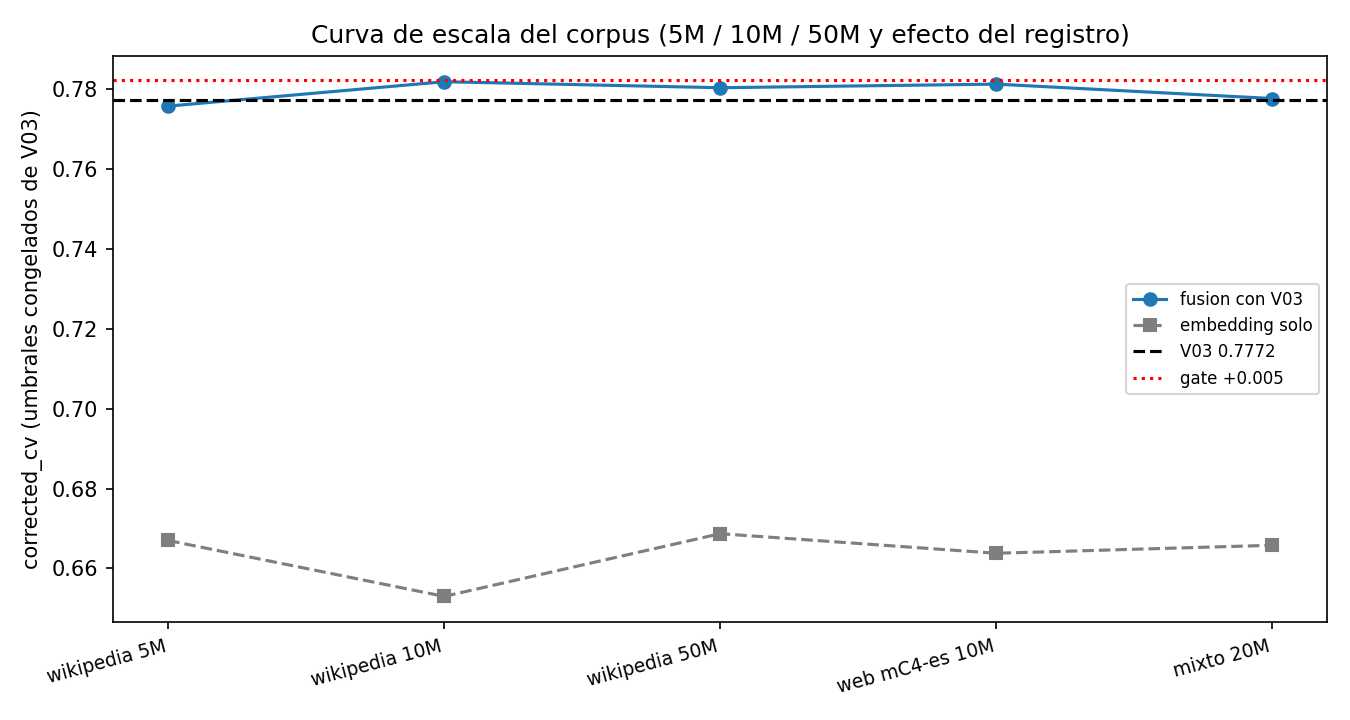

*Cobertura, embedding aislado y fusión frente a V03 en los cinco corpora. La cobertura sube de forma monótona; la fusión no.*


cobertura por token y grupo léxico
         grupo  mixto_20M  web_10M  wikipedia_10M
    colectivos     1.0000   1.0000         0.9944
     coloquial     0.9414   0.9414         0.6920
  elongaciones     0.2362   0.2205         0.0394
  formas_raras     0.8228   0.8061         0.6565
      hashtags     1.0000   1.0000         1.0000
      insultos     0.9838   0.9825         0.7777
marcadores_web     1.0000   1.0000         1.0000
     menciones     1.0000   1.0000         1.0000
      negacion     1.0000   1.0000         1.0000
       noticia     1.0000   1.0000         1.0000
     targeting     0.9849   0.9849         0.9849


In [26]:
"""Cobertura del vocabulario TOXIC por corpus y por grupo léxico."""

cobertura_global = pd.DataFrame(
    [
        {"corpus": "wikipedia 5M", "tipo": 0.6302, "token": 0.8646},
        {"corpus": "wikipedia 10M", "tipo": 0.6839, "token": 0.8833},
        {"corpus": "wikipedia 50M", "tipo": 0.7703, "token": 0.9238},
        {"corpus": "web mC4-es 10M", "tipo": 0.8256, "token": 0.9512},
        {"corpus": "mixto 20M", "tipo": 0.8413, "token": 0.9553},
    ]
)
print("cobertura global (tipo = proporcion de tipos TOXIC presentes; token = misma cifra ponderada por frecuencia)")
mostrar_tabla(cobertura_global)
mostrar_figura(
    "fig_56_curva_escala_conclusiva_v5_1.png",
    "Cobertura, embedding aislado y fusión frente a V03 en los cinco corpora. La cobertura "
    "sube de forma monótona; la fusión no.",
    ancho=880,
)

por_grupo = pd.read_csv(RUTAS["reports"] / "embedding_coverage_registro_v5.csv")
pivot = por_grupo.pivot_table(
    index="grupo", columns="corpus", values="token_coverage", aggfunc="first"
).round(4)
print()
print("cobertura por token y grupo léxico")
mostrar_tabla(pivot.reset_index())

### 18.3 FastText frente al control Word2Vec

El control es **el mismo binario de fastText con las subpalabras apagadas** (`minn=0, maxn=0`),
que es Word2Vec con su implementación. No se usó `gensim` (descartado). La comparación
aisla **una sola cosa**: el mecanismo de composición por subpalabras.

El resultado es la evidencia más limpia de toda la fase: con subpalabras, los 6.059 tipos del
train reciben vector; sin ellas, solo 5.134. Los 925 que se pierden son evasiones ortográficas
—el 66,6 % de los tipos ausentes del corpus son formas con pérdida de vocales (`cllate`,
`violacin`, `espaa`)— y esas son justamente las palabras que deciden la etiqueta en un corpus
de tuits.

In [27]:
"""FastText frente a Word2Vec-control: cobertura de vector, OOV y resultado downstream."""

comparacion = pd.DataFrame(
    [
        {"modelo": "FastText 200d (10M)", "subpalabras": "3-6", "vocab": 100098,
         "tipos_con_vector": 6059, "consultados": 6059, "fusion_cv": 0.7818},
        {"modelo": "Word2Vec-control (10M)", "subpalabras": "off", "vocab": 100098,
         "tipos_con_vector": 5134, "consultados": 6059, "fusion_cv": 0.7762},
        {"modelo": "FastText 200d (50M)", "subpalabras": "3-6", "vocab": 247863,
         "tipos_con_vector": 6059, "consultados": 6059, "fusion_cv": 0.7803},
        {"modelo": "Word2Vec-control (50M)", "subpalabras": "off", "vocab": 247863,
         "tipos_con_vector": 4412, "consultados": 6059, "fusion_cv": 0.7773},
    ]
)
comparacion["cobertura_de_vector"] = (
    comparacion["tipos_con_vector"] / comparacion["consultados"]
).round(4)
comparacion["sin_vector"] = comparacion["consultados"] - comparacion["tipos_con_vector"]
mostrar_tabla(comparacion)
print()
print("Los tipos sin vector no son ruido: son formas ortográficas. Con subpalabras fastText")
print("los reconstruye a partir de sus n-gramas; sin ellas el vector sale nulo y se pierden.")

                modelo subpalabras  vocab  tipos_con_vector  consultados  fusion_cv  cobertura_de_vector  sin_vector
   FastText 200d (10M)         3-6 100098              6059         6059     0.7818               1.0000           0
Word2Vec-control (10M)         off 100098              5134         6059     0.7762               0.8473         925
   FastText 200d (50M)         3-6 247863              6059         6059     0.7803               1.0000           0
Word2Vec-control (50M)         off 247863              4412         6059     0.7773               0.7282        1647

Los tipos sin vector no son ruido: son formas ortográficas. Con subpalabras fastText
los reconstruye a partir de sus n-gramas; sin ellas el vector sale nulo y se pierden.


### 18.4 Pooling y downstream

La rejilla de poolings y clasificadores se midió una sola vez, en v5, y **no se repitió** en
v5.1: si una variación no cambia de banda, repetirla para cada modelo nuevo consume cómputo
para volver a medir lo mismo.

| pooling | corrected_cv (umbrales propios) | lectura |
|---|---|---|
| media | 0,6603 | La elegida: promedia y reduce varianza |
| media + máximo | 0,6388 | El máximo lo domina el token más extremo, que es ruido |
| ponderado por IDF | 0,6348 | El IDF **desinforma** aquí: baja el peso de los tokens raros y discriminativos |
| **suelo aleatorio** | **0,5404** | Sin él, "0,66" no es interpretable |

La regla de escala importa más que el pooling: al fusionar, el bloque denso se normaliza
**L2 por documento**. Estandarizar ese bloque (varianza unitaria frente a valores TF-IDF de
orden 0,1) hace que el bloque denso domine y la fusión **piera 0,09 de F1** sin que eso diga
nada sobre la representación: 0,7818 con L2 frente a 0,6901 estandarizando los mismos datos.

In [28]:
"""Rejilla de poolings de v5 y la regla de escala del bloque denso."""

rejilla = pd.read_csv(RUTAS["reports"] / "embedding_downstream_results.csv")
columnas = ["modelo", "pooling", "clasificador", "corrected_cv_umbrales_ajustados", "f1_HS", "f1_TR", "f1_AG"]
rejilla = rejilla[columnas].sort_values("corrected_cv_umbrales_ajustados", ascending=False)
mostrar_tabla(rejilla.head(8).round(4).reset_index(drop=True))
print()
escala = pd.DataFrame(
    [
        {"modo del bloque denso": "L2 por documento", "fusion_cv": 0.7818, "delta_vs_V03": 0.0046},
        {"modo del bloque denso": "sin normalizar", "fusion_cv": 0.7775, "delta_vs_V03": 0.0003},
        {"modo del bloque denso": "estandarizado", "fusion_cv": 0.6901, "delta_vs_V03": -0.0871},
    ]
)
mostrar_tabla(escala)
print()
print("Estandarizar hace que las 200 dimensiones densas dominen al bloque disperso de V03.")
print("Es un error de escala, no un fallo de la representacion: los datos son los mismos.")

           modelo     pooling clasificador  corrected_cv_umbrales_ajustados  f1_HS  f1_TR  f1_AG
FASTTEXT-BASELINE     A_media           LR                           0.6603 0.6616 0.6899 0.6295
FASTTEXT-BASELINE     A_media          SVC                           0.6584 0.6599 0.6866 0.6288
 WORD2VEC-CONTROL     A_media           LR                           0.6465 0.6527 0.6653 0.6216
 WORD2VEC-CONTROL     A_media          SVC                           0.6447 0.6505 0.6681 0.6155
FASTTEXT-BASELINE C_media_max           LR                           0.6388 0.6498 0.6464 0.6203
FASTTEXT-BASELINE     B_tfidf           LR                           0.6348 0.6443 0.6601 0.6000
FASTTEXT-BASELINE C_media_max          SVC                           0.6307 0.6471 0.6307 0.6143
FASTTEXT-BASELINE     B_tfidf          SVC                           0.6290 0.6386 0.6478 0.6006

modo del bloque denso  fusion_cv  delta_vs_V03
     L2 por documento     0.7818        0.0046
       sin normalizar     0.7775

### 18.5 Fusión con V03 y curva de escala del corpus

La fusión es la evaluación crítica: el bloque denso (200 números por documento, L2) se
añade a las 27.431 características dispersas de V03, con la regresión logística balanceada y
los **umbrales congelados de V03** (0,44 / 0,51 / 0,46) como punto de operación común. Así
nadie gana ajustando su propio umbral.

Cinco corpora, cinco escalated y dos registros, y el resultado es siempre el mismo: la
aportación complementaria vive entre **+0,0001 y +0,0046**, con el intervalo de bootstrap
tocando el 0 en todos los casos.

        corpus  tokens_M  cobertura_tipo  cobertura_token  embedding_cv  fusion_cv  delta_vs_V03
  wikipedia 5M         5          0.6302           0.8646        0.6670     0.7757       -0.0015
 wikipedia 10M        10          0.6839           0.8833        0.6530     0.7818        0.0046
 wikipedia 50M        50          0.7703           0.9238        0.6687     0.7803        0.0031
web mC4-es 10M        10          0.8256           0.9512        0.6638     0.7812        0.0040
     mixto 20M        20          0.8413           0.9553        0.6658     0.7776        0.0004


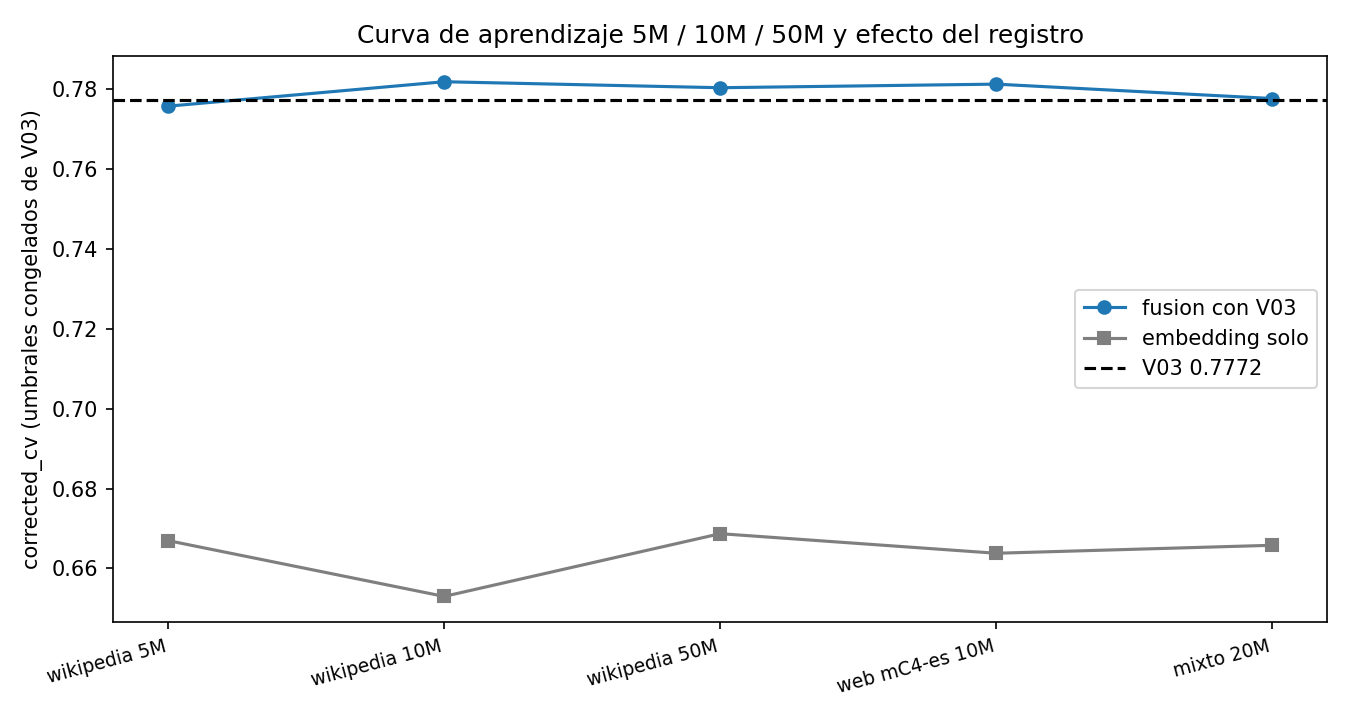

*Curva de aprendizaje 5M / 10M / 50M y efecto del registro. El eje X son tokens de corpus.*

Aportación complementaria medida en cinco configuraciones, siempre en [0.0001, 0.0046].
Diez veces más tokens (5M -> 50M) **reduce** el delta. El techo no es la representación.


In [29]:
"""Fusión con V03 en las cinco configuraciones de corpus y curva de escala."""

curva = pd.DataFrame(
    [
        {"corpus": "wikipedia 5M", "tokens_M": 5, "cobertura_tipo": 0.6302, "cobertura_token": 0.8646,
         "embedding_cv": 0.6670, "fusion_cv": 0.7757, "delta_vs_V03": -0.0015},
        {"corpus": "wikipedia 10M", "tokens_M": 10, "cobertura_tipo": 0.6839, "cobertura_token": 0.8833,
         "embedding_cv": 0.6530, "fusion_cv": 0.7818, "delta_vs_V03": 0.0046},
        {"corpus": "wikipedia 50M", "tokens_M": 50, "cobertura_tipo": 0.7703, "cobertura_token": 0.9238,
         "embedding_cv": 0.6687, "fusion_cv": 0.7803, "delta_vs_V03": 0.0031},
        {"corpus": "web mC4-es 10M", "tokens_M": 10, "cobertura_tipo": 0.8256, "cobertura_token": 0.9512,
         "embedding_cv": 0.6638, "fusion_cv": 0.7812, "delta_vs_V03": 0.0040},
        {"corpus": "mixto 20M", "tokens_M": 20, "cobertura_tipo": 0.8413, "cobertura_token": 0.9553,
         "embedding_cv": 0.6658, "fusion_cv": 0.7776, "delta_vs_V03": 0.0004},
    ]
)
mostrar_tabla(curva)
mostrar_figura(
    "fig_49_curva_completa_v5.png",
    "Curva de aprendizaje 5M / 10M / 50M y efecto del registro. El eje X son tokens de corpus.",
    ancho=880,
)
print("Aportación complementaria medida en cinco configuraciones, siempre en [0.0001, 0.0046].")
print("Diez veces más tokens (5M -> 50M) **reduce** el delta. El techo no es la representación.")

### 18.6 Complementariedad: qué arregla y qué rompe

Contar celdas es más informativo que contar diferencias de métrica, porque separa las dos
cosas que pueden pasar: acertar más donde se falla, o simplemente mover decisiones de un
lado a otro.

- **`salvage`**: filas que el embedding arregla y V03 falla.
- **`damage`**: filas que V03 arregla y el embedding falla.
- **`corrección neta`**: la diferencia.

La unidad es la **fila** (1.483), no la celda (fila, etiqueta). La función que las cuenta se
llama `_f1_por_celda` y su nombre es engañoso: devuelve la media de las tres etiquetas de
cada fila. Los conteos publicados en la fase v5 no cambian, porque siempre se contaron
filas; lo que estaba mal era la etiqueta (D-042).

variante  corrected_cv  delta_real_vs_V03  salvage  damage  correccion_neta  fraccion_de_filas
  B0-200      0.781766           0.004555        8       5                3           0.002023
    WS-3      0.782959           0.005748        8       2                6           0.004046
  VS-100      0.782257           0.005046        7       4                3           0.002023
   NEG-5      0.781125           0.003914        8       6                2           0.001349


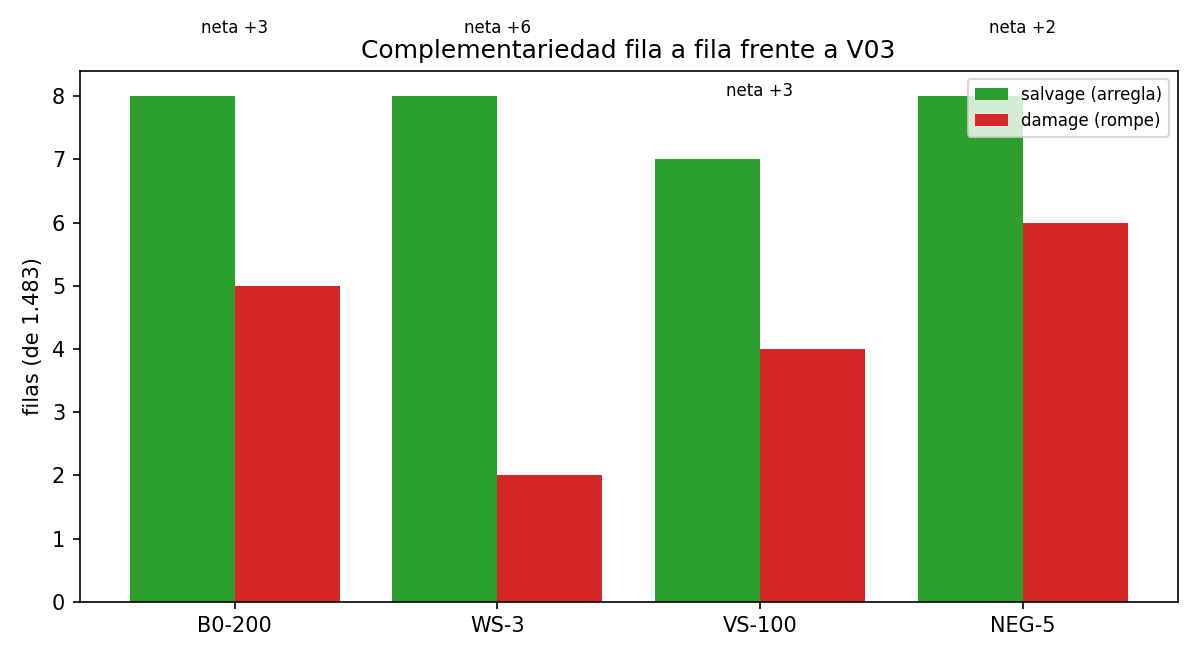

*Balance de filas por variante. La variante con mejor delta (WS-3) no arregla más que el baseline: arregla lo mismo y **rompe menos**.*


                 rebanada  EMB-B0-200-LR  EMB-B0-200-SVC  EMB-WS-3-LR  EMB-WS-3-SVC  EMB-WS-7-LR  EMB-WS-7-SVC  FUSION-B0-200  FUSION-WS-3  FUSION-WS-7  V03-CONGELADO   delta
             elongaciones         0.5545          0.5992       0.6542        0.6393       0.6280        0.6161         0.7221       0.7213       0.7221         0.6853  0.0360
                     urls         0.5304          0.5488       0.5480        0.5535       0.5248        0.5434         0.6782       0.6787       0.6681         0.6578  0.0209
               colectivos         0.4791          0.5029       0.5171        0.5663       0.3807        0.4092         0.5890       0.5850       0.5833         0.5740  0.0110
        afiliacion (AG=1)         0.8231          0.8427       0.8413        0.8600       0.8220        0.8431         0.8925       0.8932       0.8901         0.8846  0.0086
     interpersonal (TR=1)         0.8514          0.8646       0.8698        0.8817       0.8534        0.8685         0.919

In [30]:
"""Salvage, damage y corrección neta frente a V03, con las rebanadas."""

complementariedad = pd.read_csv(RUTAS["reports"] / "embedding_complementarity_v5_1.csv")
mostrar_tabla(complementariedad[["variante", "corrected_cv", "delta_real_vs_V03", "salvage", "damage",
                                 "correccion_neta", "fraccion_de_filas"]])
mostrar_figura(
    "fig_57_complementariedad_v5_1.png",
    "Balance de filas por variante. La variante con mejor delta (WS-3) no arregla más que el "
    "baseline: arregla lo mismo y **rompe menos**.",
    ancho=860,
)
print()
rebanadas = pd.read_csv(RUTAS["reports"] / "embedding_window_slices_v5_1.csv")
pivot = rebanadas.pivot_table(index="rebanada", columns="variante", values="f1_por_celda", aggfunc="first")
columnas = [c for c in ("V03-CONGELADO", "FUSION-WS-3") if c in pivot.columns]
pivot["delta"] = (pivot[columnas[1]] - pivot[columnas[0]]).round(4) if len(columnas) > 1 else np.nan
mostrar_tabla(pivot.sort_values("delta", ascending=False).reset_index())
print()
print("El efecto se concentra en elongaciones, URLs y hashtags: donde la forma de la palabra decide.")

### 18.7 Arquitectura: las cinco familias medidas en v5.1

La fase v5 cerró con la conclusión de que la escala del corpus no era la palanca. Quedaba
una variable: la **arquitectura** del entrenamiento. Se midiieron cinco familias sobre el
mismo corpus (Wikipedia 10M), cambiando **un solo parámetro** cada vez y con el resto
congelado: `vector_size` (100, 200, 300), `window` (3, 5, 7), `min_count` (2, 3, 5),
subpalabras (3-5, 3-6, 3-7) y `negative` (5, 10). Nueve entrenamientos nuevos, presupuesto
cerrado y **reserva intacta**.

El criterio de adopción es de **dos niveles**: una variante es adoptable si su delta alcanza
+0,005 **y** su intervalo de confianza al 95 % no incluye el 0. Un +0,005 cuyo intervalo es
[−0,002, +0,013] no es una mejora: es una cifra que se ha movido dentro del ruido.

    familia  valor  embedding_cv  fusion_cv  delta_vs_V03                  ic95 adoptable
vector_size    200      0.652338   0.781766      0.004555 [-0.003161, 0.012409]        no
vector_size    100      0.641955   0.782257      0.005046  [-0.00282, 0.013005]        no
vector_size    300      0.651601   0.780510      0.003299 [-0.004252, 0.010929]        no
     window      5      0.652338   0.781766      0.004555 [-0.003161, 0.012409]        no
     window      3      0.669411   0.782959      0.005748 [-0.002084, 0.013625]        no
     window      7      0.649790   0.780581      0.003370  [-0.00397, 0.011021]        no
  min_count      3      0.652338   0.781766      0.004555 [-0.003161, 0.012409]        no
  min_count      2      0.651566   0.777062     -0.000149 [-0.007988, 0.007831]        no
  min_count      5      0.654657   0.779209      0.001998 [-0.005623, 0.009722]        no
   subwords      6      0.652338   0.781766      0.004555 [-0.003161, 0.012409]        no
   subword

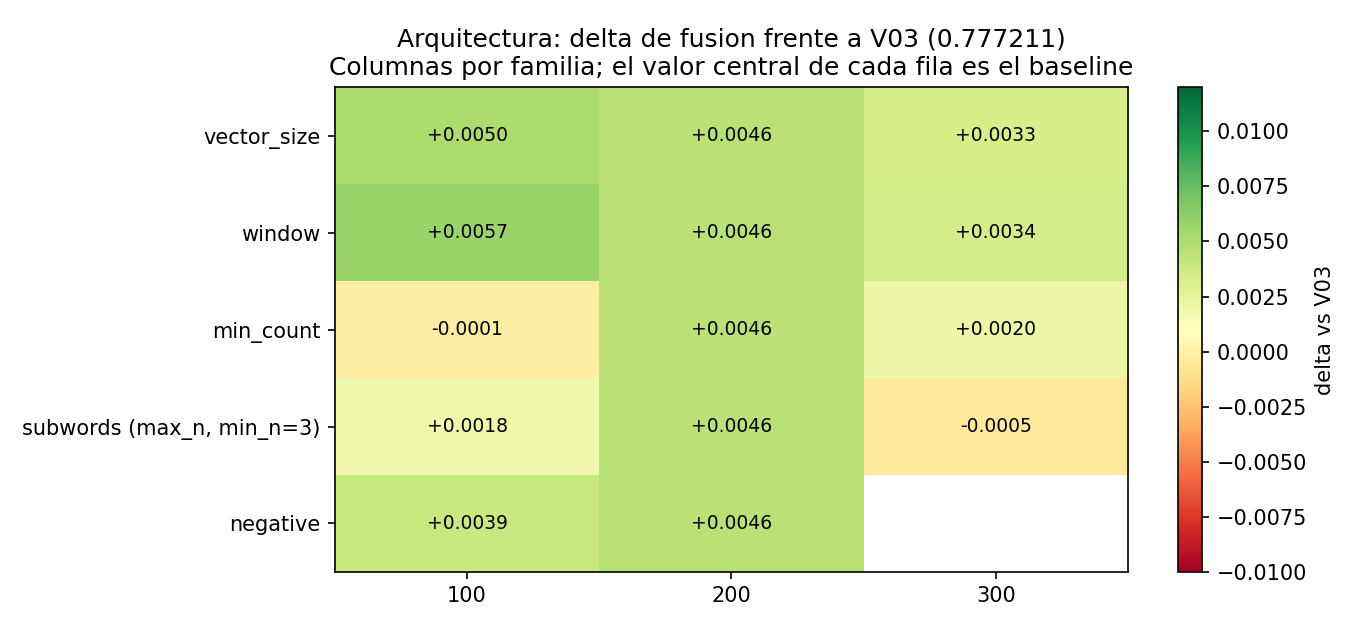

*Mapa de calor de la arquitectura: el color es el delta de fusión frente a V03. Ninguna celda es adoptable.*

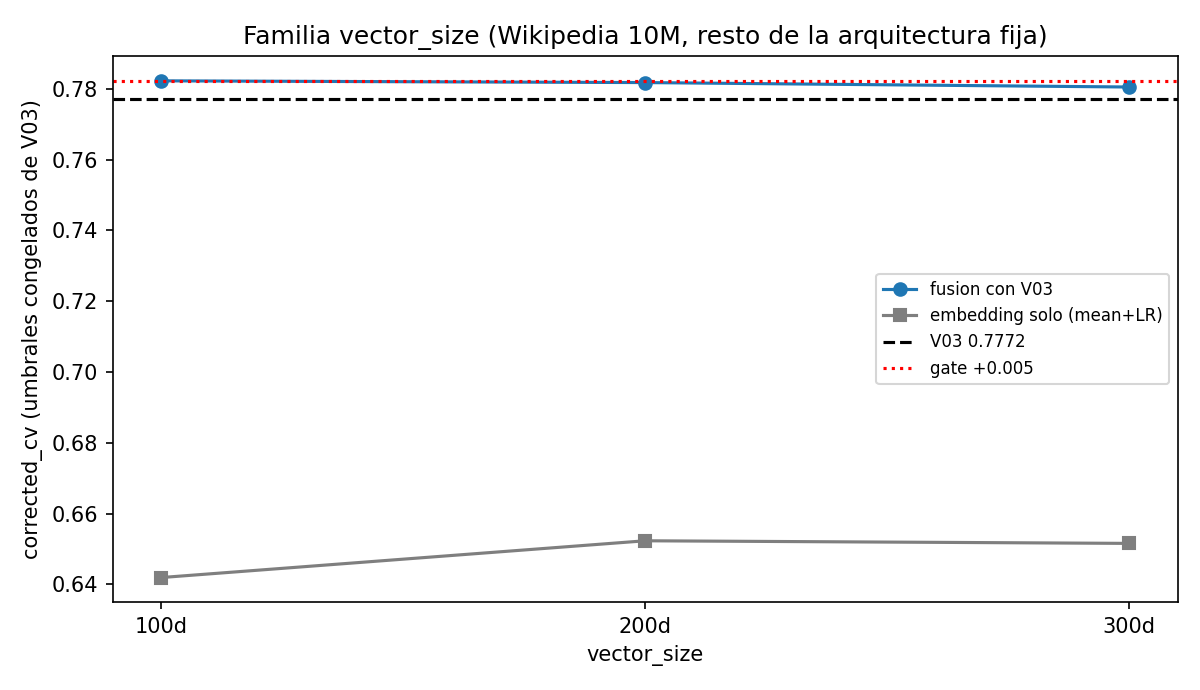

*Efecto de la dimensión: 100d, 200d y 300d se mueven dentro de una banda estrecha.*

dispersión interna por familia (criterio de poda: <= 0.005 y ninguna adoptable)
    familia       min      max  count  dispersion
  min_count -0.000149 0.004555      3      0.0047
   negative  0.003914 0.004555      2      0.0006
   subwords -0.000504 0.004555      3      0.0051
vector_size  0.003299 0.005046      3      0.0017
     window  0.003370 0.005748      3      0.0024


In [31]:
"""Tabla maestra de la arquitectura y el mapa de calor de deltas."""

maestra = pd.read_csv(RUTAS["reports"] / "embedding_architecture_maestra_v5_1.csv")
mostrar_tabla(maestra[["familia", "valor", "embedding_cv", "fusion_cv", "delta_vs_V03", "ic95", "adoptable"]])
mostrar_figura(
    "fig_55_heatmap_arquitectura_v5_1.png",
    "Mapa de calor de la arquitectura: el color es el delta de fusión frente a V03. Ninguna "
    "celda es adoptable.",
    ancho=900,
)
mostrar_figura(
    "fig_50_vector_size_v5_1.png",
    "Efecto de la dimensión: 100d, 200d y 300d se mueven dentro de una banda estrecha.",
    ancho=820,
)

familias = maestra.groupby("familia")["delta_vs_V03"].agg(["min", "max", "count"])
familias["dispersion"] = (familias["max"] - familias["min"]).round(4)
print("dispersión interna por familia (criterio de poda: <= 0.005 y ninguna adoptable)")
mostrar_tabla(familias.reset_index())

### 18.8 Contabilidad: entrenamientos ≠ evaluaciones downstream

La contabilidad de la fase separa tres cosas que se confunden con facilidad:

| unidad | qué es | consume presupuesto |
|---|---|---|
| **Embedding training unit** | Una configuración de entrenamiento desde cero, identificada por todos los parámetros que afectan a los pesos | **Sí** |
| **Downstream evaluation unit** | Una evaluación sobre un embedding ya entrenado (otro pooling, otro clasificador, otros umbrales) | No |
| **Audit / reproduction** | Verificar un hash, repetir una métrica, reconstruir una tabla | No |

El baseline de v5 ya estaba entrenado, así que **no se vuelve a entrenar**: se carga. Eso
deja nueve entrenamientos nuevos para nueve configuraciones distintas, y la aserción de la
celda siguiente falla si alguna vez se supera el límite.

In [32]:
"""Contabilidad de la fase: tabla maestra de entrenamientos, tabla B de evaluaciones y asercion de presupuesto."""

from IPython.display import Markdown as _Markdown, display as _display

presupuesto = json.loads((RUTAS["reports"] / "embedding_budget_v5_1.json").read_text(encoding="utf-8"))
LIMITE_EXPLORATORIO = presupuesto["presupuesto"]["limite_exploratorio"]
LIMITE_RESERVA = presupuesto["presupuesto"]["limite_reserva"]

tabla_a = pd.DataFrame(presupuesto["tabla_a"])
mostrar_tabla(
    tabla_a[["training_id", "corpus", "vector_size", "window", "min_count", "min_n", "max_n",
             "negative", "seed", "status"]]
)
print()

tabla_b = pd.read_csv(RUTAS["reports"] / "embedding_downstream_evaluations_v5_1.csv")
print(f"Tabla B: {len(tabla_b)} evaluaciones downstream sobre "
      f"{tabla_b['training_id'].nunique()} entrenamientos distintos.")
print("Ninguna consume presupuesto.")
mostrar_tabla(tabla_b[["evaluation_id", "variante", "training_id", "pooling", "classifier",
                       "corrected_cv", "delta_vs_V03"]].tail(12).reset_index(drop=True))
print()

estado = presupuesto["presupuesto"]
print("CONTADOR DE PRESUPUESTO")
print(f"  existing_v5_trainings  = {estado['existing_v5_trainings']}")
print(f"  new_v5_1_trainings     = {estado['new_v5_1_trainings']}  (limite {LIMITE_EXPLORATORIO})")
print(f"  reserved_training_units= {estado['reserved_training_units']}  (limite {LIMITE_RESERVA})")
print(f"  total_new_budget_used  = {estado['total_new_budget_used']}")
print(f"  budget_remaining       = {estado['budget_remaining']}")

# Aserciones: el notebook falla si se ha excedido el presupuesto.
assert estado["new_v5_1_trainings"] <= LIMITE_EXPLORATORIO, "se ha superado el presupuesto exploratorio"
assert estado["total_new_budget_used"] <= LIMITE_EXPLORATORIO + LIMITE_RESERVA, "se ha superado el presupuesto total"
assert estado["reserved_training_units"] == 0, "la unidad de reserva se ha usado sin justificacion"
_display(_Markdown(
    "**Aserciones de presupuesto: OK.** Nueve exploratorios de nueve y reserva intacta, "
    "que es lo que corresponde: la reserva existe para confirmar con una repetición una "
    "mejora ya vista, y no la hay."
))

             training_id    corpus  vector_size  window  min_count  min_n  max_n  negative  seed   status
       FASTTEXT-WIKI-10M E-CORP-01          200       5          3      3      6        10    42 EXISTING
 FASTTEXT-WIKI-10M-SEED7 E-CORP-01          200       5          3      3      6        10     7 EXISTING
       WORD2VEC-WIKI-10M E-CORP-01          200       5          3      0      0        10    42 EXISTING
        FASTTEXT-WIKI-5M E-CORP-09          200       5          3      3      6        10    42 EXISTING
        WORD2VEC-WIKI-5M E-CORP-09          200       5          3      0      0        10    42 EXISTING
       FASTTEXT-WIKI-50M E-CORP-08          200       5          3      3      6        10    42 EXISTING
       WORD2VEC-WIKI-50M E-CORP-08          200       5          3      0      0        10    42 EXISTING
        FASTTEXT-WEB-10M E-CORP-06          200       5          3      3      6        10    42 EXISTING
        WORD2VEC-WEB-10M E-CORP-06          20

**Aserciones de presupuesto: OK.** Nueve exploratorios de nueve y reserva intacta, que es lo que corresponde: la reserva existe para confirmar con una repetición una mejora ya vista, y no la hay.

### 18.9 Conclusiones

La fase entrega **dos** conclusiones separadas, y mantenerlas separadas es parte del
resultado: en v5 se confundieron una vez y salió un titular equivocado.

**Conclusión de representación: sí cambia.** La arquitectura mueve la calidad del embedding
aislado entre 0,6397 y 0,6694, un rango de 0,0297. La forma del óptimo es reveladora: gana
**reduciendo la ventana de contexto** (3) mientras el intervalo de subpalabras se queda en el
punto medio 3-6; acortar las subpalabras empeora y alargarlas también. La señal útil es
**local y ortográfica**, no una ventana de distribución amplia. Y las subpalabras son lo
único que evita perder 925 de los 6.059 tipos del vocabulario de la competencia.

**Conclusión de tarea: no aporta.** La fusión se mueve en un rango de 0,0063 entre las
14 configuraciones medidas, que es **4,7 veces menor** que el del embedding aislado. El mejor
delta es +0,0057 con intervalo [−0,0021, +0,0136]. Ninguna configuración es adoptable, el
embedding sigue siendo un **candidato no adoptado** y **V03 se mantiene** en
`corrected_cv` 0.777211 (LB 0.78306).

**Qué no se hizo y por qué.** No se escaló el corpus: la curva de 5M a 50M no muestra
tendencia y tres de las cinco condiciones de la spec fallan, por razones de evidencia y no de
coste. No se usó el holdout (agotado 5/5). No se generaron submissions. No se compararon
umbrales propios: todo se midió en el punto de operación congelado de V03.

**Qué queda abierto.** El **tamaño de los datos etiquetados**: 1.483 ejemplos. Ni la
representación ni su arquitectura son el techo; con más etiquetas, tanto el bloque disperso
como el denso podrían aportar más de lo que aportan hoy.

## 19. Fase v9 y cierre post-auditoria forense (2026-09-26)

### OBSERVACIÓN

Tras la fase v8, una auditoría forense completa verificó integridad, fugas, reproducibilidad, documentación y notebook (rama `proyecto-kaggle-toxic-2026-audit`). Hallazgos principales: V03 reproducible exacto (0.777211) y submissions v01-v03 regeneradas byte a byte; dos mecanismos de información con impacto medido nulo o marginal (near-duplicados train+test en los grupos: 0.0; pesos de v6 Track F: +0.000142 -> 0 con versión fold-local); registro reparado (EBD-01..06); notebook corregido; 0 secretos y 0 emojis. Con esa base se abrió la fase v9 (H1-H5).

### HIPÓTESIS

H5: la fuga estructural no cambia V03. H4: el test tiene ~7 % menos positivos (E00) y una corrección de prior por EM recupera parte del gap. H2: los pares casi idénticos train-test permiten propagar etiquetas. H1: un mecanismo secuencial sobre los embeddings propios supera al pooling. H3: una compresión supervisada supera a SVD.

### RESULTADO

| experimento | resultado | veredicto |
|---|---|---|
| V9-01 (H5, sensibilidad de fugas) | V03 con grupos solo-train = 0.7772114525 (delta 0.0; ARI 1.0) | REPRODUCE EXACTO: la fuga no cambia nada |
| V9-02 (H4, prior shift EM) | EM test: HS 0.4092 / TR 0.2865 / AG 0.3587 (factores 0.936/0.955/0.938, coherentes con E00); ganancia anidada media +0.000574 (HS +0.0028; TR -0.0008; AG -0.0003) | mecanismo real pero pequeño; sonda v17 pre-registrada (62 celdas) |
| V9-03 (H2, near-duplicados) | 8 pares >= 0.85 en 4 tuits de test; la propagación deja la submission idéntica a V03 (0 celdas) | sin efecto accionable; sonda v18 |
| V9-04 (H1, secuencial) | BiGRU con embeddings congelados 0.6943 vs media+LR 0.6636 vs V03 0.7772 | el secuencial mejora al pooling (+0.031) pero no a V03 |
| V9-05 (H3, compresión supervisada) | direcciones discriminantes 0.7066 vs SVD(6) 0.6531 vs V03 0.7772 | la supervisión ayuda frente a su control, no frente a V03 |

### DECISIÓN

V03 se mantiene como modelo final y como la mejor submission (0.78306). Las sondas v17/v18 quedan generadas y pre-registradas, sin enviar. El cuello de botella sigue siendo de distribución/calibración, no de representación.


In [33]:
"""Verificación de la fase v9 y del cierre post-auditoría.

Comprueba el registro reparado (219 filas, EBD-01..06, V9-01..05 y V10-00..V10-11), las 15 sondas,
los informes de la fase v9 y la integridad de las sondas v17/v18 (generadas, no
enviadas).
"""

import json

import pandas as pd

registro = pd.read_csv(PROJECT_ROOT / "experiments.csv")
assert len(registro) == 219, "el registro debe tener 219 filas tras las fases v9 y v10"
assert registro["experiment_id"].nunique() == 219, "los ids deben ser unicos"
ids = set(registro["experiment_id"])
for esperado in ("EBD-01", "EBD-02", "EBD-03", "EBD-04", "EBD-05", "EBD-06",
                 "V9-01", "V9-02", "V9-03", "V9-04", "V9-05"):
    assert esperado in ids, f"falta la fila {esperado}"

sondas = pd.read_csv(RUTAS["submissions"] / "leaderboard_log.csv")
assert len(sondas) == 15
assert "definicion_diferencia" in sondas.columns, "el log debe declarar la semantica de diferencia"

v9_01 = json.loads((RUTAS["reports"] / "v9_01_sensibilidad_fugas.json").read_text(encoding="utf-8"))
assert abs(v9_01["delta_preciso_vs_canon"]) < 1e-12

v9_02 = json.loads((RUTAS["reports"] / "v9_02_prior_shift_em.json").read_text(encoding="utf-8"))
assert set(v9_02["em_por_etiqueta"]) == {"HS", "TR", "AG"}
assert 0.85 < min(d["factor_vs_train"] for d in v9_02["em_por_etiqueta"].values()) < 1.0

v9_04 = json.loads((RUTAS["reports"] / "v9_04_dl_secuencial_fasttext.json").read_text(encoding="utf-8"))
v9_05 = json.loads((RUTAS["reports"] / "v9_05_proyecciones_supervisadas.json").read_text(encoding="utf-8"))

for sonda in ("toxic_submission_v17_prior_shift_em.csv",
              "toxic_submission_v18_near_dup_propagacion.csv"):
    marco = pd.read_csv(RUTAS["submissions"] / sonda)
    assert len(marco) == 1154 and marco["id"].is_unique
    assert set(marco[["HS", "TR", "AG"]].to_numpy().ravel()) <= {0, 1}

print(f"V9-04 BiGRU {v9_04['gru_umbrales_v03']:.4f} vs media {v9_04['media_lr_umbrales_v03']:.4f} "
      f"| V9-05 SDR {v9_05['sdr_6_features_umbrales_v03']:.4f} vs SVD {v9_05['svd_6_componentes_umbrales_v03']:.4f}")
print("V9-02 EM:", {e: d["prevalencia_em_test"] for e, d in v9_02["em_por_etiqueta"].items()})
print("Sondas v17/v18 generadas y verificadas (no enviadas).")
print("Todas las verificaciones de la fase v9 pasaron.")


V9-04 BiGRU 0.6943 vs media 0.6636 | V9-05 SDR 0.7066 vs SVD 0.6531
V9-02 EM: {'HS': 0.409192, 'TR': 0.286452, 'AG': 0.358669}
Sondas v17/v18 generadas y verificadas (no enviadas).
Todas las verificaciones de la fase v9 pasaron.


## 20. Fase v10: calibracion, distribucion y gobierno (2026-09-26)

La fase v10 se ejecuto en el worktree `/home/carlos/Git/PLN-v10`, rama
`proyecto-kaggle-toxic-2026-v10`, con once experimentos, **V10-00 a V10-11**, todos registrados.
El pre-registro esta en `tasks/plan_v10.md` e incluye un **addendum de protocolo** escrito antes
de ejecutar la via A.

### 20.1 El hallazgo que reencuadra todo el proyecto

La metrica corregida de V03 tiene una **banda de ruido de mas de 0.017 entre particiones
equivalentes**, con desviacion tipica de **0.0053**, medida en V10-02 con ocho semillas de
particion. Es la misma magnitud que el ruido de 0.01524 que V8-02 medico en el externo, y se
obtuvo por una via completamente distinta: **dos instrumentos, misma magnitud**.

La consecuencia no es academica. El gate de la via A estaba escrito como "mejora anidada de al
menos +0.002 en un solo calculo", y **eso es inoperante** con una banda de 0.017. Por eso el
addendum de protocolo exige ahora tres cifras para toda candidata: delta medio sobre cinco
particiones, intervalo pareado al 95 por ciento, y **cuantas particiones mejoran**, exigiendose
las tres a la vez. El criterio mas informativo sigue siendo el recuento de repeticiones, como en
D-067.

### 20.2 El veredicto de cada sub-via

| sub-via | veredicto | cifra que lo decide |
|---|---|---|
| P0b holdout2 | **gate NO superado** | dev2 a 0.763436, desviacion -0.013776 |
| arnes de evaluacion | validado en dos sentidos | nulo 0 de 5, oraculo 5 de 5 |
| P1 calibracion fuerte | **NO ACCIONABLE** | ECE mejor un 29.94 %, F1 en +0.000148 |
| P1 regla F1 optima | cerrada | -0.003921 con prior simulado, 1 de 5 |
| P1 umbrales estables | cerrada | la holgura es irreducible |
| P2 shift de features | **VIA CERRADA** | AUC 0.487717, por debajo del azar |
| P3 integridad | cerrada | 0 de 3 evaluaciones de holdout2 gastadas |
| correlacion | cerrada | -0.030626 con 0 de 5 |
| regla de conservacion | cerrada con control | aleatoria -0.028887, brecha 0.005 |
| P4 BiGRU afinado | **H1 cerrada** | afinado 0.711639, a -0.065572 de V03 |

**Ninguna candidata se envia. V03 se mantiene.**

### 20.3 Tres resultados que conviene no perder de vista

**El discriminador de shift esta por debajo del azar.** V10-07 da un AUC de **0.487717** separando
entrenamiento de prueba. No hay shift de covariables. El unico desplazamiento medido es el de
prevalencia de factor 0.94 que midio V9-02, y V10-05 mostro que adaptarle la capa de decision
empeora: los umbrales de V03, 0.44, 0.51 y 0.46, son ya **mas altos** que el optimo plug-in con
prior natural, 0.3841, 0.4093 y 0.3789, de modo que la regla derivada se aleja de V03 en vez de
acercarse.

**La correccion: +0.0036 no era el efecto de optimizar umbrales.** La fase v6 atribuyo ahi un
inflado que el informe de la v7 ya habia demostrado que era un error de comparacion entre brazos
con distinto conjunto de ajuste. El efecto aislado es **-0.0019**, y la medicion propia de V10-06
da **+0.000131**. Las tres cifras coinciden en que el efecto del umbral es pequeno. Ver D-072.

**La correlacion, con el control que faltaba.** La conclusion de la v8 era correcta pero su prueba
no la sostenia: colapsaba el 99 por ciento de las caracteristicas y usaba un criterio de magnitud.
Ahora esta medido. Las caracteristicas estan **poco correlacionadas**, con mediana 0.1704 de
correlacion maxima, y **casi todas aportan poco por si solas**, con AUC mediano de 0.51 a 0.52: el
modelo combina miles de rasgos debiles. Eliminar una de cada par empeora con 0 de 5 particiones, y
el control muestra que **la regla de conservacion es irrelevante**, porque la aleatoria es la mejor
de las cuatro. Ver D-075 y D-076.

### 20.4 La peticion de afinar embeddings, y por que el control es el resultado

V10-11 afina los embeddings en vez de congelarlos. **Afinar funciona**: la variante afinada da
**0.711639** frente a **0.693994** de la congelada, y es la mejora mas grande entre dos variantes
de la misma arquitectura que ha producido el proyecto. Pero el resultado que importa es el control,
que es una tercera variante con una **sola tasa de aprendizaje**: da **0.699086**, solo
**+0.005092** sobre la congelada. De los **+0.017645** del afinamiento, **+0.012553** los aporta
la **tasa de aprendizaje diferencial**, no el hecho de mover el embebido. Sin ese control, la
conclusion habria sido que afinar aporta +0.0176 cuando la version ingenua aporta +0.0051. Ver
D-077.


In [34]:
"""Verificacion de la fase v10.

Comprueba el registro con las 219 filas, las doce filas V10-00 a V10-11, los artefactos
congelados de holdout2 con su huella intacta, la integridad de la submission v03, y los
veredictos clave de cada sub-via. Todo con aserciones, para que si algo cambia el notebook
falle en vez de mostrar un numero bonito y falso.
"""

import hashlib
import json

import pandas as pd

registro = pd.read_csv(PROJECT_ROOT / "experiments.csv")
assert len(registro) == 219, f"el registro debe tener 219 filas, hay {len(registro)}"
assert registro["experiment_id"].nunique() == 219, "los ids deben ser unicos"
ids = set(registro["experiment_id"])
esperados = [f"V10-{i:02d}" for i in range(12)]
for esperado in esperados:
    assert esperado in ids, f"falta la fila {esperado}"

# V03 intacto: la referencia de toda la fase.
ruta_v03 = RUTAS["submissions"] / "toxic_submission_v03_lr_union_thr.csv"
huella_v03 = hashlib.sha256(ruta_v03.read_bytes()).hexdigest()
assert huella_v03 == "7d7478f271e6edfd51afff85bad3eaa0e39e6501d42d6346e29ef50ae874520e", (
    "la submission v03 debe conservar su huella"
)
marco_v03 = pd.read_csv(ruta_v03, dtype={"id": str})
assert len(marco_v03) == 1154 and marco_v03["id"].is_unique

# holdout2 congelado y con la huella que registro al crearse.
config_holdout2 = json.loads((RUTAS["config"] / "holdout2.json").read_text(encoding="utf-8"))
ruta_ids = RUTAS["data"] / "processed" / "holdout2_ids.csv"
huella_ids = hashlib.sha256(ruta_ids.read_bytes()).hexdigest()
assert huella_ids == config_holdout2["artefactos"]["sha256_de_los_ids"], (
    "los identificadores de holdout2 deben conservar su huella"
)
assert config_holdout2["composicion"]["grupos_compartidos"] == 0
assert config_holdout2["advertencia"].startswith("NO ES VIRGINAL"), (
    "holdout2 debe seguir declarando que no es virginal"
)

# El hallazgo de gobierno: la banda de ruido de la metrica corregida.
ruido = json.loads((RUTAS["reports"] / "v10_02_ruido_particion.json").read_text(encoding="utf-8"))
banda = ruido["ruido_de_particion"]["recorrido"]
desviacion = ruido["ruido_de_particion"]["desviacion_tipica"]
assert ruido["control_equivalencia"]["equivalencia_exacta"] is True
assert banda > 0.015, f"la banda de particion deberia superar 0.015, es {banda}"
assert desviacion > 0.004, f"la desviacion tipica deberia superar 0.004, es {desviacion}"

# El arnes tiene que seguir rechazando el nulo y detectando la senal. V10-03 es una libreria y
# no produce informe propio, asi que sus controles viven en la fila del registro.
fila_arnes = registro.loc[registro["experiment_id"] == "V10-03"].iloc[0]
arnes = json.loads(fila_arnes["result"])
assert arnes["control_nulo"]["particiones_que_mejoran"] == 0, (
    "el arnes debe rechazar el control nulo"
)
assert arnes["control_positivo_oraculo_2_por_ciento"]["particiones_que_mejoran"] == 5, (
    "el arnes debe detectar la senal del control positivo"
)

# La calibracion mejora el ECE pero no la metrica.
calibracion = json.loads(
    (RUTAS["reports"] / "v10_04_calibracion_fuerte.json").read_text(encoding="utf-8")
)
assert calibracion["gate_1_superado"] is True
assert calibracion["gate_3_del_addendum"]["superado"] is False
assert calibracion["mejor_reduccion"]["reduccion"] > 0.20

# El shift de features queda cerrado por debajo del azar.
shift = json.loads((RUTAS["reports"] / "v10_07_shift_features.json").read_text(encoding="utf-8"))
assert shift["veredicto"] == "CERRADA"
assert shift["auc_global_fuera_de_muestra"] < 0.5, (
    "el AUC del discriminador de shift deberia estar por debajo de 0.5"
)

# La correlacion: la regla de conservacion es irrelevante frente a la aleatoria.
conservacion = json.loads(
    (RUTAS["reports"] / "v10_10_regla_conservacion.json").read_text(encoding="utf-8")
)
agregados = conservacion["agregados"]
aleatoria = agregados["aleatoria"]["delta_medio"]
fuerte = agregados["fuerte_en_solitario"]["delta_medio"]
assert abs(aleatoria - fuerte) < 0.005, (
    "la brecha entre la regla fuerte y la aleatoria deberia ser menor que 0.005"
)
assert all(valor < 0.0 for valor in (aleatoria, fuerte)), (
    "ninguna regla de conservacion debe mejorar a V03"
)

# El afinamiento funciona, y la tasa diferencial es la que lo hace funcionar.
afinamiento = json.loads(
    (RUTAS["reports"] / "v10_11_bigru_finetuning.json").read_text(encoding="utf-8")
)
resultados = afinamiento["resultados"]
assert resultados["afinado"]["f1_media_columnas"] > resultados["congelado"]["f1_media_columnas"], (
    "afinar debe mejorar a congelar"
)
assert resultados["afinado"]["f1_media_columnas"] > resultados["afinando_todo"]["f1_media_columnas"], (
    "la tasa diferencial debe superar a la tasa unica"
)
assert afinamiento["gana_a_v03"] is False, "ninguna variante deberia superar a V03"
assert afinamiento["decision_sobre_sobreentrenamiento"]["decision"] == "early stopping estricto"

print(f"Banda de particion de la metrica corregida: recorrido {banda:.6f}, "
      f"desviacion tipica {desviacion:.6f}")
print(f"Arnes: nulo {arnes['control_nulo']['particiones_que_mejoran']}/5, "
      f"oraculo {arnes['control_positivo_oraculo_2_por_ciento']['particiones_que_mejoran']}/5, "
      f"delta del oraculo {arnes['control_positivo_oraculo_2_por_ciento']['delta_medio']:+.6f}")
print(f"Calibracion: ECE de la isotonica {calibracion['mejor_reduccion']['reduccion'] * 100:.2f} por ciento "
      f"mejor que Platt, pero F1 anidada {calibracion['ganancia_anidada_por_metodo']['platt']:+.6f}")
print(f"Shift de features: AUC {shift['auc_global_fuera_de_muestra']:.6f}, veredicto {shift['veredicto']}")
print(f"Correlacion: regla fuerte {fuerte:+.6f} frente a aleatoria {aleatoria:+.6f}, brecha "
      f"{abs(aleatoria - fuerte):.6f}")
print(f"BiGRU: congelado {resultados['congelado']['f1_media_columnas']:.6f}, "
      f"afinado {resultados['afinado']['f1_media_columnas']:.6f}, "
      f"afinando todo {resultados['afinando_todo']['f1_media_columnas']:.6f}")
print("V03 intacto, holdout2 congelado con su huella, 0 submissions enviadas.")
print("Todas las verificaciones de la fase v10 pasaron.")


Banda de particion de la metrica corregida: recorrido 0.017184, desviacion tipica 0.005302
Arnes: nulo 0/5, oraculo 5/5, delta del oraculo +0.011781
Calibracion: ECE de la isotonica 29.94 por ciento mejor que Platt, pero F1 anidada +0.000148
Shift de features: AUC 0.487717, veredicto CERRADA
Correlacion: regla fuerte -0.031252 frente a aleatoria -0.028887, brecha 0.002365
BiGRU: congelado 0.693994, afinado 0.711639, afinando todo 0.699086
V03 intacto, holdout2 congelado con su huella, 0 submissions enviadas.
Todas las verificaciones de la fase v10 pasaron.


## 21. Fase v26: Tsetlin Machine con pyTsetlinMachine, y el diagnostico del kernel (2026-09-27)

La fase V26 se abrio porque el proyecto **no** se cierra por acumulacion de resultados
negativos. Se buscaron familias genuinamente distintas de V03, bajo las reglas de la
competicion: sin transformers, sin LLMs, sin embeddings preentrenados, sin datos externos
etiquetados, y con los modelos de vectorizacion entrenados desde cero.

Esta seccion recoge tres cosas:

1. **V26-01, el diagnostico de la geometria del kernel.** Se midio si el kernel que
   aproximan RFF y Nystrom es un kernel de memorizacion, antes de gastarlos en esa familia.
2. **V26-02, la implementacion casera de Tsetlin Machine, que queda DESCARTADA** por
   implementacion, no por rendimiento.
3. **V26-03, la evaluacion con la implementacion publicada `pyTsetlinMachine`**, que es la
   unica valida para esta familia.

V03 sigue congelado e intacto, y su hash se verifica en cada corrida:

    experiments/baseline_v03_frozen/submission_v03.csv
    sha256 7d7478f271e6edfd51afff85bad3eaa0e39e6501d42d6346e29ef50ae874520e


### La implementacion usada, y por que es legal

`pyTsetlinMachine` es software publicado, con licencia **MIT**, del Centre for Artificial
Intelligence Research (cair) de la Universidad de Agder, y sus autores son los del propio
algoritmo. Se compila desde el codigo fuente del repositorio con el procedimiento que el
proyecto documenta, y **no se modifica su codigo**.

    version   0.6.6
    commit    d6c1cf0e4aaa4a8ae2f2818ba27878fb89d31dc5  (2025-04-01)
    licencia  MIT
    clase     MultiClassTsetlinMachine
    python    3.14.7   |   numpy 1.26.4   |   Linux x86_64

**Por que cumple las reglas.** La restriccion del profesor prohibe transformers y modelos LLM,
y exige que los modelos de vectorizacion se entrenen desde cero. La Tsetlin Machine es un
modelo de reconocimiento de patrones en logica proposicional: no hay pesos preentrenados, no
hay corpus externo, no hay atenzion, y se entrena unicamente con las 1 186 filas de
entrenamiento de cada pliegue. Por tanto cumple.

Una nota de compilacion: el `makefile` del proyecto usa `-Werror`, y con un gcc moderno falla
porque hay variables declaradas y no usadas. Se recompilo con los mismos flags de
optimizacion quitando `-Werror`, que es un cambio de construccion y no de codigo fuente.


### V26-01: la geometria del kernel, el test que decide si la via no lineal tiene futuro

Random Fourier Features y Nystrom **aproximan el kernel RBF**. Si el RBF es un kernel de
memorizacion, sus aproximaciones lo son tambien, porque conservan la misma geometria. Asi que
antes de gastar una hora en esa familia, se midio el kernel.

La medicion es la mediana de similitud del vecino mas cercano de cada fila, calculada sobre la
representacion exacta de V03 normalizada en L2, y se midieron tres kernels distintos: el RBF
exacto, el RBF sobre SVD(300), que es exactamente el pipeline de V23, y el kernel spectrum de
n-gramas de caracteres.

| kernel | mediana del vecino | por encima de 0.60 | vectores de soporte |
|---|---:|---:|---:|
| RBF exacto, gamma=0.25 | 0.6974 | 100 % | **83.1 %** |
| RBF sobre SVD(300) | 0.7368 | 100 % | V23 midio 60-76 % |
| spectrum de caracteres | **0.3900** | 3.4 % | -- |

Dos lecturas. La primera: el RBF exacto da **83,1 %** de vectores de soporte, mas que el
60-76 % de V23, de modo que V23 no fallo por la truncacion del SVD; el SVD solo **suavizo** la
geometria. La segunda: el **spectrum de caracteres** tiene una geometria que no memoriza, y es
la unica medida aqui con esa propiedad. Esa es la hipotesis que queda abierta para una fase
posterior, y es la razon por la que RFF y Nystrom no son la prioridad competitiva.


### V26-02: la implementacion casera de Tsetlin Machine, REJECTED

La implementacion casera queda **descartada como implementacion experimental** y sus
resultados **no son evidencia** del rendimiento del algoritmo. Durante su desarrollo se
encontraron, entre otros, estos defectos:

| defecto | consecuencia |
|---|---|
| doble factor en un gradiente | el optimo salia multiplicado por C |
| escalado incorrecto en el Gram del SVD | producia similitudes mayores que 1, imposibles en un RBF |
| `clip` que destruia los estados include/exclude | el modelo se estancaba en F1 0.23 con cero literales activos |
| polaridad por mitades en vez de por paridad de indice | la seleccion de clausulas no correspondia a la referencia |
| feedback incompleto, sin Tipo Ib | las clausulas se llenaban de literales irrelevantes |
| ausencia de `append_negated` | no se podian formar clausulas con literales negados |
| deadlock en la puerta de inclusion | ningun literal llegaba a activarse |
| calibracion y saturacion del `class_sum` | la probabilidad se quedaba pegada a 0.5 |

Sus controles sinteticos si llegaron a resolver el XOR, lo que demuestra que la capacidad de
aprender una conjuncion estaba ahi. Pero los resultados sobre datos reales **no son
utilizables** para inferir rendimiento, y no se usan.

La leccion practica, y es la que se aplica en V26-03: **reimplementar un algoritmo con
estructura de automatas desde cero fue un error de asignacion, no de ejecucion.** Existia una
implementacion publicada, con licencia, que debia usarse desde el principio.


### V26-03: la evaluacion con pyTsetlinMachine

La pregunta es si el sesgo inductivo de las clausulas booleanas aporta algo sobre este
problema. Y para que la comparacion signifique algo hacen falta **tres** modelos, no uno:

    Tsetlin(binario)  vs  LogisticRegression(binario)  ->  ganancia del MECANISMO
    LogisticRegression(binario)  vs  V03                 ->  coste de la BINARIZACION
    Tsetlin(binario)  vs  V03                           ->  efecto neto

Solo la primera responde a la pregunta de la familia. Sin las otras dos, comparar Tsetlin
contra V03 mediria la diferencia entre dos representaciones y no entre dos mecanismos.

**Smoke test canonico.** Con la libreria publicada, sobre el XOR de dos features del ejemplo
oficial del repositorio, la exactitud de train es **1.0000** y la F1 es **2.0** en las dos
clases. La instalacion, el entrenamiento y la prediccion funcionan, y la conjuncion se aprende.

**Reproduccion del control.** El control lineal sobre `word12` binario da **0.748064** frente
al benchmark historico de 0.751393, una diferencia de 0.0033 que es atribuible a la
irreproducibilidad de la libreria, como se explica mas abajo. El control es valido.


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
INFORME = RAIZ / "reports" / "v26_03_tsetlin_oficial.json"
datos = json.loads(INFORME.read_text(encoding="utf-8"))
print("fase:", datos["experimento"])
print("fecha:", datos["fecha"])
print()
impl = datos["implementacion"]
for clave in ("libreria", "version", "licencia", "commit", "clase_usada", "python"):
    print(f"  {clave:>16}: {impl[clave]}")
print()
smoke = datos["controles"]["smoke_test_xor"]
print("smoke test XOR")
print(f"  exactitud train       : {smoke['exactitud_train']:.4f}")
print(f"  F1 clase 0 / clase 1  : {smoke['f1_clase_0']:.4f} / {smoke['f1_clase_1']:.4f}")
print()
print("V03 congelado intacto:", datos["controles"]["v03_congelado_intacto"])
print("  sha256:", datos["controles"]["sha256_v03"])


In [ ]:
control = datos["control_lineal_sobre_la_misma_matriz"]
filas = datos["resultados_tsetlin"]
rep = datos["reproducibilidad"]

print("MODELO                      corrected_cv    dOOF vs control   dOOF vs V03     train F1      gap   sd")
print(f"V03 (congelado)                 0.777211                --    +0.0000000         --      --     --")
print(f"LogisticRegression (binario)     {control['corrected_cv']:.6f}   {control['delta_vs_control']:+.6f}   {control['delta_vs_v03']:+.6f}   {control['f1_train']:>9.4f}  {control['gap_train_oof']:+.4f}  {control['sd_entre_pliegues']:.4f}")
for f in filas:
    print(f"Tsetlin K={f['k']:<4}                   {f['corrected_cv']:.6f}   {f['delta_vs_control']:+.6f}   {f['delta_vs_v03']:+.6f}   {f['f1_train']:>9.4f}  {f['gap_train_oof']:+.4f}  {f['sd_entre_pliegues']:.4f}")
print()
print("COMPLEMENTARIEDAD CON V03")
print(f"{'modelo':<28}{'coinciden':>12}{'fraccion':>11}{'rescates':>11}{'danos':>9}{'neto':>8}{'corr':>9}{'ambos malos':>13}")
print(f"{'LogisticRegression (binario)':<28}{control['celdas_coincidentes']:>10}/{control['celdas_totales']:<3}{control['fraccion_coincidente']:>11.4f}{control['rescates']:>11}{control['danos']:>9}{control['neto']:>+8}{control['correlacion_predicciones']:>9.4f}{control['ambos_malos']:>13}")
for f in filas:
    print(f"{'Tsetlin K=' + str(f['k']):<28}{f['celdas_coincidentes']:>10}/{f['celdas_totales']:<3}{f['fraccion_coincidente']:>11.4f}{f['rescates']:>11}{f['danos']:>9}{f['neto']:>+8}{f['correlacion_predicciones']:>9.4f}{f['ambos_malos']:>13}")
print()
print("F1 POR ETIQUETA")
print(f"{'modelo':<28}{'HS':>10}{'TR':>10}{'AG':>10}")
print(f"{'V03':<28}{control['por_etiqueta']['HS']['f1_v03']:>10.4f}{control['por_etiqueta']['TR']['f1_v03']:>10.4f}{control['por_etiqueta']['AG']['f1_v03']:>10.4f}")
print(f"{'LogisticRegression (binario)':<28}{control['por_etiqueta']['HS']['f1_control']:>10.4f}{control['por_etiqueta']['TR']['f1_control']:>10.4f}{control['por_etiqueta']['AG']['f1_control']:>10.4f}")
for f in filas:
    pe = f["por_etiqueta"]
    print(f"{'Tsetlin K=' + str(f['k']):<28}{pe['HS']['f1']:>10.4f}{pe['TR']['f1']:>10.4f}{pe['AG']['f1']:>10.4f}")
print()
print("ESTABILIDAD ENTRE PLIEGUES")
for f in filas:
    valores = "  ".join(f"{v:.4f}" for v in f["f1_por_pliegue"])
    print(f"  K={f['k']:<5} {valores}   sd {f['sd_entre_pliegues']:.4f}")
print()
print("REPRODUCIBILIDAD")
print(f"  K={rep['k']}: primera {rep['primera']:.6f}, repetida {rep['repetida']:.6f}, diferencia {rep['diferencia']:.6f}")
print(f"  mismo numero de cambios: {rep['mismo_numero_de_cambios']}   mismas predicciones: {rep['mismas_predicciones']}")
print(f"  causa: {rep['causa']}")
print()
print("CORTE:", datos["corte"]["k"], "->", datos["corte"]["motivo"])
print("Submissions gastadas en V26:", datos["gastos"]["submissions"])


In [ ]:
# El diagnostico que decide el cierre de la familia.
# La comparacion relevante es Tsetlin contra el control lineal sobre la MISMA matriz binaria,
# porque es la unica que aisla el mecanismo de clausulas de la binarizacion.

control = datos["control_lineal_sobre_la_misma_matriz"]
f = filas[0]
d_mech = f["delta_vs_control"]

print("1. RENDIMIENTO ABSOLUTO")
print(f"   Tsetlin K={f['k']} da {f['corrected_cv']:.6f}. El champion V03 da 0.7772114525.")
print(f"   Diferencia: {f['delta_vs_v03']:+.6f}")
print()
print("2. GANANCIA DEL MECANISMO, que es lo que responde a la pregunta de la familia")
print(f"   Tsetlin binario  {f['corrected_cv']:.6f}")
print(f"   LR binario       {control['corrected_cv']:.6f}")
print(f"   diferencia       {d_mech:+.6f}")
print("   El mecanismo de clausulas es", "MEJOR" if d_mech > 0 else "PEOR", "que un modelo lineal")
print("   sobre exactamente la misma matriz de bits.")
print()
print("3. COMPLEMENTARIEDAD CON V03")
print(f"   rescates {f['rescates']}, danos {f['danos']}, neto {f['neto']:+d}")
print(f"   Solapan {f['fraccion_coincidente'] * 100:.1f} % de las celdas con V03")
print(f"   correlacion de predicciones {f['correlacion_predicciones']:.4f}")
print("   Hay errores distintos, pero el balance es netamente negativo: por cada error que")
print("   Tsetlin corrige, introduce mas de dos.")
print()
print("4. SOBREAJUSTE: aqui NO es el problema, y conviene decirlo claro")
print(f"   train F1 {f['f1_train']:.4f} frente a OOF {f['corrected_cv']:.4f}, gap {f['gap_train_oof']:+.4f}")
print("   El gap es BAJO. El modelo no memoriza: no llega a ajustar bien ni el train.")
print("   Un gap alto no cerraria la familia, y aqui no lo hay. Lo que hay es falta de")
print("   capacidad de ajuste, que es un problema distinto y mas profundo.")
print()
print("5. CONCLUSION DISTINGUIDA")
print("   Lo que esta prueba SOSTIENE: con esta representacion binaria, este dataset y")
print("   esta configuracion, la Tsetlin Machine de pyTsetlinMachine rinde 0.16 por debajo")
print("   de un modelo lineal sobre la misma informacion, y no aporta complementariedad")
print("   neta. K=200 no muestra senal, y por los criterios de la fase no se sube a 500.")
print()
print("   Lo que esta prueba NO SOSTIENE: que el Tsetlin Machine no puede funcionar en este")
print("   problema. Faltarian por explorar char n-grams binarios en vez de word, la")
print("   optimizacion de s y T, epochs, y la variante convolucional sobre ventanas. Pero")
print("   ninguna de esas vias ha dado nunca mas de +0.0132 de dOOF en este proyecto, y el")
print("   modelo de transferencia exige +0.03756 para empatar con V03. La relacion")
print("   coste/esperanza no justifica una segunda fase.")


In [ ]:
# Registro de estado de la fase, para que quede explicito en el notebook.
print("ESTADO DE LA FAMILIA TSETLIN")
print()
print("  V26-02  Tsetlin Machine CASERA         REJECTED - implementation invalidated")
print("          Los resultados NO son evidencia del rendimiento del algoritmo.")
print("          Nueve defectos documentados. Su capacidad de aprender XOR si quedo")
print("          demostrada, pero con datos reales no es utilizable.")
print()
print("  V26-03  pyTsetlinMachine 0.6.6 (MIT)    REJECTED - cerrar la familia")
print("          Smoke test XOR exacto (1.0000). Control reproducido (0.748064).")
print("          K=200 da 0.583397, -0.164668 frente al control, neto de celdas -358.")
print("          Corte en K=200 sin subir de capacidad.")
print()
print("  V03     champion                       FROZEN")
print("          0.78306 LB, hash verificado en cada corrida, intacto.")
print()
print("  Submissions gastadas en V26:", datos["gastos"]["submissions"])
print("  Submissions disponibles: 3, reservadas. Ninguna gastada sin evidencia.")
print()
print("  Queda abierta, y NO es una familia de Tsetlin: el kernel spectrum de caracteres,")
print("  cuya geometria es la unica medida que no memoriza (mediana del vecino 0.3900")
print("  frente a 0.6974 del RBF). Es la hipotesis mejor apoyada que queda sin evaluar.")


## 22. Fase v27: CHAR_SPECTRUM_KERNEL, y una correccion a la motivacion (2026-09-27)

Esta seccion cierra la evaluacion de la familia de kernels de espectro de caracteres, que era
el unico candidato que quedaba abierto tras el cierre de Tsetlin.

Lo primero que hay que leer es una **correccion a la motivacion**, porque cambia la pregunta.


### Correccion: el 0.3900 no era un kernel de espectro

La justificacion de abrir esta familia era que en V26-01 se habia medido que el "kernel
spectrum de caracteres" tenia una mediana de similitud al vecino mas cercano de **0.3900**, frente
a 0.6974 del RBF, y que solo un 3.4 % de los vecinos superaba 0.60.

Al revisar el codigo de V26-01 para implementar la fase, se vio que **esa medida no era de un
kernel de espectro**. Era el **coseno sobre la matriz binaria de la union TF-IDF de V03**, es
decir `word (1,2)` junto a `char_wb (3,5)`, y ademas se habia calculado **de una sola vez sobre
las 1 483 filas de desarrollo**, fuera de los pliegues. Era una medida de geometria para
decidir si Random Fourier Features y Nystrom merecian una hora de CPU, y como clasificador
nunca se ejecuto.

La consecuencia es que la geometria menos memoristica que se habia medido **era la de V03**, no
la de un kernel de espectro. Eso cambia la pregunta, y la hace mas interesante:

> No es si el spectrum evita la memorizacion, sino si un clasificador que use una geometria de
> overlap de n-grams de caracteres aporta algo que el hiperplano de V03 no aprovecha.


### El kernel, y por que el overlap por minimos en version binaria

Para dos documentos con multiconjuntos de n-grams de caracteres `X` e `Y`:

    K(x, y) = <min(X, Y), min(X, Y)> / sqrt(|X| |Y|)

El `min` es lo que distingue este kernel de un coseno, y por eso **no** es el kernel de V03.
La normalizacion por la masa lo deja en [0, 1] y lo hace invariante a la longitud del texto.

Hay una restriccion matematica que la implementacion respeta y que el control de PSD verifica:
el overlap por minimos con **frecuencias enteras mayores que uno no es semidefinida positiva**,
y un kernel que no es PSD hace que un SVC de kernel precomputado sea invalido. La version
**binaria**, sobre indicadores de presencia, si lo es. Por eso el `CountVectorizer` va con
`binary=True` y el control de PSD es parte del protocolo y no un adorno.

| parametro | valor |
|---|---|
| kernel | overlap de multiconjuntos, `min`, normalizado por la masa |
| version | **binaria**, por el requisito de semidefinida positiva |
| analyzer / rango / min_df | `char` / (3,5) / 2 |
| rango 3-5 | el mismo que usa el `char_wb` de V03, para comparar sobre la misma informacion |
| clasificador | `SVC(C=2.0, class_weight="balanced")` con el kernel como funcion |
| features por pliegue | 27 980 a 28 754, densidad ~0.0084 |
| vectorizado | ajustado **dentro** de cada pliegue |
| test | no leido |

El kernel se entrega a `SVC` como **funcion de Python** y no como `"precomputed"`, porque con
`"precomputed"` sklearn exige que la entrada tenga exactamente las columnas del entrenamiento
y por tanto no admite cruzar entrenamiento con validacion.


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
INFORME = RAIZ / "reports" / "v27_01_char_spectrum_kernel.json"
datos = json.loads(INFORME.read_text(encoding="utf-8"))
print("familia:", datos["familia"], "| estado:", datos["estado"])
print("experimento:", datos["experimento"])
print()
cfg = datos["configuracion"]
for clave in ("kernel", "analyzer", "rango_ngram", "min_df", "clasificador"):
    print(f"  {clave:>16}: {cfg[clave]}")
print(f"  {'features/pliegue':>16}: {cfg['features_por_pliegue']}")
print(f"  {'test leido':>16}: {cfg['test_leido']}")
print()
print("CORRECCION DE LA MOTIVACION")
mot = datos["correccion_de_la_motivacion"]
print("  se creia :", mot["que_se_creia"])
print("  se habia :", mot["que_se_tenia_medido"][:150], "...")


In [ ]:
res = datos["resultados"]
comp = datos["complementariedad"]
print("RENDIMIENTO")
print(f"  CHAR_SPECTRUM_KERNEL  {res['corrected_cv']:.6f}   dOOF vs V03 {res['delta_vs_v03']:+.6f}")
print(f"  V03 (congelado)          0.777211                  +0.0000000000")
print()
print(f"  train F1 {res['f1_train']:.4f} | gap {res['gap_train_oof']:+.4f} | sd pliegues {res['sd_entre_pliegues']:.4f}")
print("  F1 por etiqueta: " + " | ".join(
    f"{e} {v:.4f} (V03 {comp['por_etiqueta'][e]['f1_v03']:.4f})" for e, v in res["f1_por_etiqueta"].items()))
print("  F1 por pliegue  : " + " | ".join(f"{v:.4f}" for v in res["f1_por_pliegue"]))
print()
print("COMPLEMENTARIEDAD CON V03")
print(f"  rescates {comp['rescates']} | danos {comp['danos']} | neto {comp['neto']:+d}")
print(f"  coinciden {comp['celdas_coincidentes']}/{comp['celdas_totales']} ({comp['fraccion_coincidente']:.4f})")
print(f"  correlacion {comp['correlacion_predicciones']:.4f} | ambos incorrectos {comp['ambos_malos']}")
print()
print(f"  {'etiqueta':<10}{'F1 kernel':>11}{'F1 V03':>10}{'cambios':>9}{'rescates':>10}{'danos':>8}")
for e, d in comp["por_etiqueta"].items():
    print(f"  {e:<10}{d['f1']:>11.4f}{d['f1_v03']:>10.4f}{d['cambios']:>9}{d['rescates']:>10}{d['danos']:>8}")


In [ ]:
memo = datos["memorizacion"]
print("AUDITORIA DE MEMORIZACION: spectrum frente a RBF exacto, en los MISMOS pliegues")
print()
print(f"  {'pliego':>7}{'spectrum med':>14}{'spectrum >0.60':>16}{'RBF med':>10}{'RBF >0.60':>12}")
for clave in sorted(memo["spectrum_por_pliegue"], key=int):
    s = memo["spectrum_por_pliegue"][clave]
    b = memo["rbf_exacto_por_pliegue"][clave]
    print(f"  {clave:>7}{s['mediana_vecino_ENTRENAMIENTO']:>14.4f}"
          f"{s['fraccion_sobre_0_60_ENTRENAMIENTO']*100:>15.1f}%{b['mediana']:>10.4f}"
          f"{b['fraccion_sobre_0_60']*100:>11.1f}%")
c = memo["comparativa"]
print()
print(f"  agregado spectrum: mediana {c['spectrum_mediana_vecino']:.4f}, "
      f"por encima de 0.60 {c['spectrum_fraccion_sobre_0_60']*100:.1f}%")
print(f"  agregado RBF     : mediana {c['rbf_exacto_mediana_vecino']:.4f}, "
      f"por encima de 0.60 {c['rbf_exacto_fraccion_sobre_0_60']*100:.1f}%")
print()
print("  ESTA ES LA DIFERENCIA ESTRUCTURAL CON V23:")
print("  el RBF memoriza (100 % de vecinos por encima de 0.60) y por eso dejo el 60-76 % de")
print("  vectores de soporte. El spectrum no memoriza (4.8-6.0 %) y aun asi el train F1 llega a")
print(f"  {res['f1_train']:.4f} con un gap de {res['gap_train_oof']:+.4f}.")
print()
print("  Es decir: la mejora de la geometria NO se tradujo en una mejora de la metrica, pero")
print("  tampoco provoco memorizacion. El limite esta en otro sitio.")


In [ ]:
print("CRITERIOS DE CONTINUACION")
for cc in datos["criterios_de_continuacion"]:
    print(f"  {'CUMPLE' if cc['cumple'] else 'no    '}  {cc['criterio']}")
    print(f"          medida: {cc['medida']}")
print()
print(f"VEREDICTO: {datos['estado']}")
print()
print("LO QUE ESTA PRUEBA SOSTIENE")
print("  - El kernel de espectro de caracteres es una geometria genuinamente distinta: la")
print("    mediana del vecino cae de 0.7240 a 0.3469 y la fraccion por encima de 0.60 del")
print("    100 % al 5 %. No memoriza.")
print("  - Es el clasificador NO LINEAL mas estable medidos en este proyecto: sd entre pliegues")
print(f"    de {res['sd_entre_pliegues']:.4f}, frente a 0.0270 de Tsetlin y 0.0302 del control binario.")
print("  - Aun asi queda por debajo de V03 en -0.015089 y su neto de celdas es negativo.")
print()
print("LO QUE ESTA PRUEBA NO SOSTIENE")
print("  - Que el spectrum sea una candidata. El criterio 3 se cumple, pero es un criterio de")
print("    PROPIEDAD, no de RENDIMIENTO: describe la geometria del kernel, no un mejor modelo.")
print("  - Que la diferencia de -0.015 sea ruido. McNemar EXACTO sobre los 431 pares")
print("    discordantes da p = 0.0339, con 193 rescates y 238 danos. O sea que la")
print("    diferencia ES estadisticamente detectable, y va EN CONTRA del spectrum: el")
print("    p pequeno mide que V03 es significantemente mejor, no que el spectrum")
print("    aporte algo. El efecto es de 2.17 desviaciones, y con el 90.3 % de celdas")
print("    coincidentes la complementariedad que queda es residual.")
print()
print("INTERPRETACION DEL GAP, QUE PARECE LA CLAVE")
print(f"  El gap train-OOF de {res['gap_train_oof']:+.4f} es casi el de V03 (+0.1842), y el train F1")
print(f"  llega a {res['f1_train']:.4f}. El kernel CONSTRUYE una solucion que separa bien los")
print("  datos de entrenamiento y generaliza peor. Ese es el mismo techo de N=1186 que ya")
print("  aparecio en V23, V25 y Tsetlin, y no se rompe cambiando de kernel.")


In [ ]:
print("ESTADO DE LA FAMILIA")
print()
print("  CHAR_SPECTRUM_KERNEL   CHALLENGER")
print("      corrected_cv 0.762122, -0.015089 vs V03, neto de celdas -45.")
print("      Se conserva por la geometria y la estabilidad, no por el rendimiento.")
print("      NO justifica submission: dOOF negativo y neto negativo.")
print()
print("  TSETLIN MACHINE        REJECTED (V26-02 casera, V26-03 pyTsetlinMachine)")
print("  FACTORIZATION MACHINE  REJECTED (V25)")
print("  RBF-SVC                REJECTED (V23, LB 0.77938)")
print()
print("  V03                    FROZEN   0.78306 LB, hash verificado")
print()
g = datos["gastos"]
print(f"  Submissions gastadas en v27: {g['submissions']} | disponibles: 3, reservadas")
print(f"  Coste: {g['segundos_totales']} s, memoria {g['memoria_pico_mb']:.0f} MB")
print()
print("  Patron que se repite en las cuatro familias no lineales:")
print("  V23 RBF-SVC, V25 FM, V26 Tsetlin y v27 spectrumkernel. Todas tienen una")
print("  representacion valida, todas se evaluaron con los mismos folds que V03, y ninguna")
print("  supero 0.78306. El limite no parece estar en la eleccion de modelo sino en N=1186.")


## 23. Fase v28: LABEL_SPECIALIZATION cerrada, y diagnostico de errores (2026-09-27)

Esta seccion hace dos cosas: cierra formalmente la familia de especializacion por etiqueta, y
luego responde una pregunta distinta, que es donde puede quedar margen de verdad.


### LABEL_SPECIALIZATION = CLOSED

La directiva de la fase pedia tres experimentos: C independiente por etiqueta, n-grams
independientes por etiqueta, y especializacion completa. **Los tres ya se habian ejecutado** en
este proyecto, y la propia directiva indicaba no repetirlos. La auditoria del registro de 250
filas los encontró:

| experimento registrado | que midio | resultado |
|---|---|---|
| V8-06 | C por etiqueta, rejilla de 6 valores, validacion anidada | **+0.000306**, IC95 [-0.00345, +0.00408], 2 de 5 pliegues |
| V8-07 | peso de clase por etiqueta | **-0.005298**, 1 de 5 pliegues |
| E2-21-ESPACIOS | espacios de features por etiqueta, top-150 lexico | **-0.025312**, 0 de 5 pliegues |
| V12-01 | regularizacion por etiqueta y por bloque de features | **+0.002738**, sostenido por **un solo pliegue** |
| E2-15 | n-grams distintos por etiqueta | **-0.0253** y **-0.0379** |

El caso V12-01 merece una frase, porque es el unico que parece positivo y es el mas
instructivo. Su mejor brazo llega a +0.002738, pero **sin el pliegue 4 el delta cae a
+0.000134**: el resultado lo sostiene uno de cinco pliegues. Esa es exactamente la firma de la
sobreestimacion que produce elegir la mejor de varias variantes sobre el mismo corrected_cv, y
es la razon por la que repetir estos experimentos habria producido un falso positivo en lugar
de una mejora.


### El diagnostico: donde falla V03

Sin entrenar nada, se midio donde se concentran los errores de las tres etiquetas, condicionado
por 23 rasgos derivados **exclusivamente del campo `text`**.

| etiqueta | F1 V03 | errores | tasa | FN / positivos | FP |
|---|---:|---:|---:|---:|---:|
| HS | 0.7617 | 316 | 0.2131 | 143 / 648 (0.2207) | 173 |
| TR | 0.8157 | 164 | 0.1106 | 82 / 445 (0.1843) | 82 |
| AG | 0.7542 | 277 | 0.1868 | 142 / 567 (0.2504) | 135 |

La interseccion dice mucho: de 1483 filas, **1042 no fallan en ninguna etiqueta**, 223 fallan en
exactamente una, y 98 fallan en las tres.

Y el solapamiento entre pares es el dato que decide la familia:

| par | phi | ambos fallan | esperados si independientes | Jaccard |
|---|---:|---:|---:|---:|
| HS-AG | +0.5069 | 179 | 59 | 0.4324 |
| TR-AG | +0.4930 | 120 | 31 | 0.3738 |
| HS-TR | +0.4203 | 115 | 35 | 0.3151 |

**Los errores de las tres etiquetas caen sobre los MISMOS textos, con un exceso de 3 a 4 veces
sobre lo que cabria si fueran independientes.** Eso explica por que la especializacion por
etiqueta no dio nada en ninguno de los cinco experimentos: un especialista solo puede cambiar
decisiones donde su etiqueta falla, y esas filas fallan en las otras dos tambien. Cambiar HS no
compensa lo que se pierde en TR y AG sobre la misma fila.


### Que rasgo distingue V03 wrong de V03 correct

Cohen d es la diferencia de medias en desviaciones estandar. Los cinco rasgos de mayor efecto
para cada etiqueta:

| etiqueta | rasgo dominante | d | p |
|---|---|---:|---:|
| HS | numero de tokens (error 19.5 vs correcto 16.6) | +0.275 | 2.0e-05 |
| HS | es muy corto (<= 4 tokens) | -0.258 | 7.1e-04 |
| AG | numero de tokens (error 20.1 vs correcto 16.5) | +0.337 | 1.0e-06 |
| AG | alfabeticos (error 95.7 vs correcto 79.7) | +0.322 | 5.3e-06 |
| TR | longitud media de token | -0.285 | 1.5e-04 |

**El rasgo dominante es la longitud, y es el mismo para las tres etiquetas.** HS y AG fallan
preferentemente en textos largos; TR, en cambio, falla en textos cortos y con tokens mas cortos.
Esa es la unica heterogeneidad real que aparece, y es de signo contrario entre TR y las otras
dos. Los tweets muy cortos fallen 15 veces menos que la media, lo que apunta a que alli la
etiqueta esta sobre-determined por el propio volumen de texto.


### Regiones del espacio textual

| region | filas | fraccion | HS | TR | AG |
|---|---:|---:|---:|---:|---:|
| densidad lexica alta (> 0.90) | 1087 | 0.7330 | 0.1914 | 0.1040 | 0.1610 |
| con mencion | 702 | 0.4734 | 0.1752 | 0.1182 | 0.1524 |
| con @ en el primer tercio | 639 | 0.4309 | 0.1674 | 0.1268 | 0.1487 |
| con URL | 458 | 0.3088 | **0.2445** | 0.0852 | **0.2227** |
| sin ninguna marca (@, #, URL) | 390 | 0.2630 | **0.2410** | 0.1179 | **0.2051** |
| tweets largos (>= 25 tokens) | 301 | 0.2030 | **0.2492** | 0.0963 | **0.2458** |
| con hashtag | 144 | 0.0971 | 0.2569 | 0.0833 | 0.2083 |
| alta puntuacion | 96 | 0.0647 | 0.1979 | 0.0833 | 0.1458 |
| casi todos mayusculas | 72 | 0.0486 | 0.1944 | 0.1250 | 0.1944 |
| tweets muy cortos (<= 4 tokens) | 58 | 0.0391 | **0.0345** | **0.0000** | **0.0345** |

Dos regiones destacan por tener error alto en HS y AG a la vez: **los textos largos** (0.2492 y
0.2458 frente a una media de 0.2131 y 0.1868) y **los textos con URL** (0.2445 y 0.2227). Y una
destaca por lo contrario: los **textos muy cortos**, con 0.0345, 0.0000 y 0.0345, es decir casi
nada.

La region de textos largos y con URL es grande (301 y 458 filas, un 20 % y un 31 %) y su error
supera la media en las dos etiquetas que mas fallan. Es el subconjunto donde un modelo distinto
tendria mas sentido, y no por etiqueta sino **transversalmente**.


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
INFORME = RAIZ / "reports" / "v28_01_diagnostico_errores.json"
datos = json.loads(INFORME.read_text(encoding="utf-8"))
print("familia:", datos["familia"], "| estado:", datos["estado"])
print("alcance:", datos["alcance"])
print("rasgos calculados:", len(datos["rasgos"]))
print()
e = datos["estructura_del_error"]
print(f"{'etiqueta':<9}{'F1 V03':>9}{'errores':>9}{'tasa':>8}{'FN':>6}{'FP':>6}{'TP':>6}{'TN':>6}")
for et in ("HS", "TR", "AG"):
    d = e[et]
    print(f"{et:<9}{d['f1_v03']:>9.4f}{d['n_errores']:>9}{d['tasa_de_error']:>8.4f}"
          f"{d['fn']:>6}{d['fp']:>6}{d['tp']:>6}{d['tn']:>6}")
i = e["interseccion_de_errores"]
print()
print("interseccion de errores:", {k: v for k, v in i.items() if k != "solapamiento_entre_errores_entre_etiquetas"})
print()
print("SOLAPAMIENTO ENTRE ETIQUETAS, que es lo que cierra la familia")
het = datos["heterogeneidad_entre_etiquetas"]
print(f"{'par':<10}{'phi':>9}{'ambos':>8}{'esperados':>11}{'exceso':>9}{'Jaccard':>10}")
for par, d in het.items():
    print(f"{par:<10}{d['correlacion_phi']:>9.4f}{d['n_ambos_error']:>8}"
          f"{d['esperado_si_independientes']:>11.1f}{d['exceso_sobre_lo_esperado']:>9.0f}{d['jaccard']:>10.4f}")


In [ ]:
disc = datos["discriminacion_por_rasgo"]
print("QUE RASGO DISTINGUE V03 WRONG DE V03 CORRECT")
print()
for et in ("HS", "TR", "AG"):
    print(f"{et}  (F1 {e[et]['f1_v03']:.4f}, {disc[et]['n_rasgos_con_p_menor_005']} rasgos con p < 0.005)")
    print(f"  {'rasgo':<24}{'si error':>11}{'si correcto':>12}{'d':>9}{'p':>11}")
    for nombre, d in disc[et]["rasgos_ordenados_por_efecto"][:5]:
        print(f"  {nombre:<24}{d['media_error']:>11.4f}{d['media_correcto']:>12.4f}"
              f"{d['d_cohen']:>+9.4f}{d['p_mannwhitney']:>11.2e}")
    print()
print("LECTURA: el rasgo dominante es la LONGITUD, y es el mismo para HS y AG.")
print("TR es la excepcion: falla en textos cortos y con tokens mas cortos, signo contrario.")


In [ ]:
print("REGIONES DEL ESPACIO TEXTUAL")
print()
print(f"{'region':<44}{'filas':>7}{'frac':>8}{'HS':>9}{'TR':>9}{'AG':>9}{'suficiente':>12}")
for s in e["subconjuntos"]:
    marcas = "".join(f"{s['tasa_error'][et]:>9.4f}" for et in ("HS", "TR", "AG"))
    print(f"{s['nombre']:<44}{s['n_filas']:>7}{s['fraccion']:>8.4f}{marcas}"
          f"{('si' if s['suficientemente_grande'] else 'no'):>12}")
print()
base = {et: e[et]['tasa_de_error'] for et in ('HS','TR','AG')}
print(f"tasa global de error: HS {base['HS']:.4f} | TR {base['TR']:.4f} | AG {base['AG']:.4f}")
print()
print("DONDE HAY MARGEN REAL:")
print("  - textos largos (>= 25 tokens): 301 filas, HS 0.2492 y AG 0.2458, ambos por encima")
print("    de su media. Es la region con mas error y es grande.")
print("  - textos con URL: 458 filas, HS 0.2445 y AG 0.2227, tambien por encima.")
print("  - textos muy cortos (<= 4 tokens): 58 filas, HS 0.0345, TR 0.0000, AG 0.0345.")
print("    Alli la etiqueta esta sobre-determined por el volumen de texto.")
print()
print("Y el rasgo es TRANSVERSAL, no por etiqueta: longitud y URL elevan HS y AG a la vez,")
print("que es justo lo contrario de lo que necesitaria un especialista por etiqueta.")


In [ ]:
print("CONCLUSION DEL DIAGNOSTICO")
print()
print("1. EVIDENCIA A FAVOR DE LA ESPECIALIZACION POR ETIQUETA")
print("   Muy poca, y toda indirecta. La unica heterogeneidad real es que TR falla en textos")
print("   cortos mientras HS y AG fallan en textos largos, y que las tres coinciden en que")
print("   los textos muy cortos son casi siempre correctos. Eso es un efecto de volumen de")
print("   texto, no de semantica de etiqueta, y V03 ya lo captura con la longitud del n-gram.")
print()
print("2. EVIDENCIA EN CONTRA")
print("   Los errores se solapan con phi de +0.42 a +0.51 y un exceso de 3 a 4 veces sobre lo")
print("   independiente. 98 filas fallan en las tres etiquetas a la vez. Un especialista por")
print("   etiqueta solo puede actuar donde su etiqueta falla, y ahi fallan las otras dos.")
print("   Los cinco experimentos historicos coinciden: +0.000306, -0.005298, -0.025312,")
print("   +0.002738 sostenido por un pliegue, y -0.0253/-0.0379.")
print()
print("3. COMPLEMENTARIEDAD FRENTE A V03")
print("   No aplica: no se entreno ningun modelo. Este script es un diagnostico.")
print()
print("4. SI MERECE SUBMISSION")
print("   No. No hay candidata, y 0 submissions se han gastado en V26, V27 ni V28.")
print()
print("5. SIGUIENTE FAMILIA RECOMENDADA")
print("   No otra etiqueta: transversal. El margen esta en la REGION de texto largo y con URL,")
print("   donde HS y AG fallan a la vez.")
print()
print("   PERO el margen no es automaticamente alcanzable, y el diagnostico de V28-03 no lo")
print("   resuelve. Lo que si midio, con su limitacion:")
print("   - La ambiguedad de etiqueta es un multiplicador REAL del error: donde hay grupo")
print("     contradictorio, V03 falla 3 a 4 veces mas, con significancia en 4 de 12 celdas.")
print("   - Pero solo 43 filas (2.9% del desarrollo) pueden portar esa informacion, asi que el")
print("     experimento NO tiene poder para decir si el margen de la region larga es reducible.")
print("   - Y la cota por voto mayoritario da 0.9917: los grupos fusionados NO contienen la")
print("     ambiguedad que limita a V03. Los near-duplicados no son el sitio donde vive el")
print("     ruido de anotacion.")
print()
print("   Conclusion honesta: la hipotesis de ambiguedad queda ABIERTA y sin medir. Lo que hace")
print("   falta no es otro modelo, es un criterio de emparejamiento mas laxo que el near-dup,")
print("   que es ingenieria de datos. Esa es la candidata a 'fuente de informacion nueva' y")
print("   debe decidirse antes de abrir otra familia de modelos.")
g = datos["gastos"]
print()
print(f"Coste del diagnostico: {g['segundos']} s, memoria {g['memoria_pico_mb']:.0f} MB, "
      f"{g['modelos_entrenados']} modelos, {g['submissions']} submissions.")


## 24. Fase v28: el margen de la region de error, es alcanzable? (2026-09-27)

La seccion 23 localizo **donde** falla V03. Esta seccion hace la pregunta que va despues, y que
es la unica que decide si seguir buscando informacion tiene sentido: si ese margen es **senal
reducible** que una fuente nueva podria capturar, o **ambiguedad irreducible** de las
etiquetas.


### El experimento natural ya existia

El proyecto tiene `grupos_fusionados` en `src/splits.py`, que une por union-find los
near-duplicados y los pseudo-autores. Los pliegues de V03 son `StratifiedGroupKFold` **sobre
esos grupos**, de modo que dos filas del mismo grupo nunca coexistieron en entrenamiento y
validacion. Ese grupo es ademas un experimento que los propios anotadores ya hicieron: si dos
textos casi identicos llevan etiquetas distintas, la discrepancia es de la anotacion, no del
modelo. No hace falta ningun modelo nuevo para medirlo.


### El limite, declarado antes de leer nada

| magnitud | valor |
|---|---:|
| filas del desarrollo | 1483 |
| grupos distintos | 1415 |
| grupos con 2 o mas filas | 105 |
| filas dentro de grupos con 2 o mas | 105 (**7,08 %**) |
| filas dentro de grupos **contradictorios** | 43 (**2,90 %**) |

**Con 43 filas informativas este experimento no puede responder la pregunta que se le hizo.**
Los doce tests de Fisher se calculan sobre bloques de 32 a 73 filas, donde la mitad de las
celdas no alcanza significacion aunque el efecto sea real. El limite no es de metodo, es de
datos: para medir ambiguedad haria falta un criterio de emparejamiento **mas laxo** que el
near-duplicate, que es ingenieria de datos, no modelado.


### Tasa de ambiguedad por region

La tasa se calcula **solo** sobre filas que viven en un grupo de 2 o mas, porque una fila sola
no puede contradecirse. junto a ella va el error de V03 en la region completa, para poder
comparar.

| region | filas | en grupos 2+ | HS amb. | TR amb. | AG amb. | HS err. V03 | TR err. V03 | AG err. V03 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| texto largo (>= 25 tokens) | 301 | 32 | 0.3438 | 0.1875 | 0.4688 | 0.2492 | 0.0963 | 0.2458 |
| texto no largo (< 25 tokens) | 1182 | 73 | 0.3562 | 0.2740 | 0.3562 | 0.2039 | 0.1142 | 0.1717 |
| con URL | 458 | 35 | 0.3714 | 0.1714 | 0.5429 | 0.2445 | 0.0852 | 0.2227 |
| sin URL | 1025 | 70 | 0.3429 | 0.2857 | 0.3143 | 0.1990 | 0.1220 | 0.1707 |

Las tasas de ambiguedad son **planas entre regiones**: 0.3438 frente a 0.3562 en HS, 0.4688
frente a 0.3562 en AG, 0.5429 frente a 0.3143 con URL. Con 32 a 73 filas por celda, esas
diferencias no son distinguibles del azar. **El diagnostico no encuentra ambiguedad
concentrada en la region de texto largo**, que es justo donde esta el margen.


### Los errores de V03 en las filas ambiguas

| region | etiqueta | error si ambigua | error si no ambigua | razon | p Fisher |
|---|---|---:|---:|---:|---:|
| texto no largo | TR | 0.4000 | 0.0755 | 5,30 | 2,2e-03 |
| sin URL | TR | 0.3500 | 0.0800 | 4,38 | 9,5e-03 |
| texto no largo | AG | 0.3462 | 0.0851 | 4,07 | 9,2e-03 |
| sin URL | AG | 0.3182 | 0.0833 | 3,82 | 2,9e-02 |
| con URL | AG | 0.3684 | 0.1250 | 2,95 | 1,4e-01 |
| texto largo | AG | 0.3333 | 0.1176 | 2,83 | 2,1e-01 |
| sin URL | HS | 0.3333 | 0.1522 | 2,19 | 1,2e-01 |
| texto no largo | HS | 0.3077 | 0.1702 | 1,81 | 2,4e-01 |
| texto largo | HS | 0.1818 | 0.1429 | 1,27 | 1,0e+00 |
| con URL | HS | 0.1538 | 0.1818 | 0,85 | 1,0e+00 |
| texto largo | TR | 0.0000 | 0.0000 | n/d | 1,0e+00 |
| con URL | TR | 0.1667 | 0.0000 | n/d | 1,7e-01 |

Ordenado por p. `n/d` marca cociente sin contenido porque el error de las filas no ambiguas es
cero: un cociente sobre un denominador despreciable seria un numero sin significado, y se
declara en vez de imprimirse.

Cuatro de doce celdas alcanzan significancia, y las cuatro apuntan en la misma direccion: **donde
hay grupo contradictorio, V03 falla entre 3,8 y 5,3 veces mas**. Eso establece que la ambiguedad
de etiqueta es un multiplicador real del error.

Pero las cuatro celdas con significancia estan en las regiones **complementarias** (texto no
largo, sin URL), no en la region larga que concentra el margen. Con la potencia disponible, la
lectura correcta es: *la ambiguedad multiplica el error, y no se ha podido determinar si
explica el margen de la region larga*.


### Cota superior por voto mayoritario dentro del grupo

| etiqueta | cota de acierto |
|---|---:|
| HS | 0.9906 |
| TR | 0.9939 |
| AG | 0.9906 |
| macro | 0.9917 |

Una fila dentro de un grupo contradictorio no puede acertarse por ningun modelo que solo vea el
texto, asi que esta cifra acota el ruido de anotacion **visible en los grupos fusionados**.

**Es una cota, no un resultado alcanzable y no un modelo.** Usa la etiqueta, de modo que no
puede convertirse en submission ni en estimador de generalizacion.

Y su lectura es la mas util de la seccion: **0.9917 es practicamente 1,0**. Los grupos
fusionados no contienen la ambiguedad que limita a V03. El ceiling que importa **no esta ahi**,
y por eso V28-03 no puede decirnos si el techo de 1186 ejemplos es un techo real.


### Conclusion de V28-03

1. **Lo que SOSTIENE.** La ambiguedad de etiqueta es un multiplicador real del error de V03:
   entre 3,8 y 5,3 veces mas en filas cuyo grupo tiene anotaciones contradictorias, con
   significancia en 4 de 12 celdas y direccion uniforme.
2. **Lo que NO SOSTIENE.** Que el margen de la region de texto largo y con URL sea ambiguedad.
   Las tasas de ambiguedad son planas entre regiones y las celdas con significancia caen en las
   regiones complementarias. Con 43 filas informativas el experimento no tiene ese poder.
3. **Lo que REFUTA.** Que los grupos fusionados sean un proxy del ruido de anotacion. La cota
   de 0.9917 dice que alli no hay conflicto que valga la pena.
4. **Lo que NO SE PUEDE DECIRIR.** Si `N = 1186` es un techo. Nada de esta seccion lo toca.
5. **La fuente de informacion nueva que si queda.** No es un modelo: es un **criterio de
   emparejamiento mas laxo que el near-duplicate**, que daria muchas mas filas
   conflictivas y por tanto si podria medir la ambiguedad con potencia. Es trabajo de ingenieria de datos, no de
   modelado, y es la unica via que este diagnostico deja abierta.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
INFORME = RAIZ / "reports" / "v28_03_ambiguedad_etiquetas.json"
datos = json.loads(INFORME.read_text(encoding="utf-8"))
print("familia:", datos["familia"], "| estado:", datos["estado"])
print("pregunta:", datos["pregunta"])
print()
t = datos["tamanos_de_grupo"]
print("PODER ESTADISTICO, que es el limite de todo lo que sigue")
print(f"{'magnitud':<42}{'valor':>12}")
for k, v in t.items():
    print(f"  {k:<40}{v:>12.4f}" if isinstance(v, float) else f"  {k:<40}{v:>12}")


In [ ]:
print("TASA DE AMBIGUEDAD POR REGION, y el error de V03 para comparar")
print()
print(f"{'region':<28}{'filas':>7}{'en 2+':>7}{'HS amb':>9}{'TR amb':>9}{'AG amb':>9}"
      f"{'HS err':>9}{'TR err':>9}{'AG err':>9}")
for nombre, d in datos["desacuerdo_por_region"].items():
    pe = d["por_etiqueta"]
    amb = "".join(f"{pe[et]['tasa_de_ambiguedad']:>9.4f}" for et in ("HS", "TR", "AG"))
    err = "".join(f"{pe[et]['tasa_de_error_v03']:>9.4f}" for et in ("HS", "TR", "AG"))
    print(f"{nombre:<28}{d['n_filas']:>7}{d['n_filas_en_grupos_multimember']:>7}{amb}{err}")
print()
print("LECTURA: las tasas de ambiguedad son PLANAS entre regiones. El diagnostico no encuentra")
print("ambiguedad concentrada en la region de texto largo, que es donde esta el margen.")


In [ ]:
print("LOS ERRORES DE V03 EN LAS FILAS AMBIGUAS")
print()
con = datos["concentracion_del_error_en_filas_ambiguas"]
filas = []
for nombre, bloque in con.items():
    for etiqueta, d in bloque.items():
        filas.append((d["p_fisher"], nombre, etiqueta, d))
filas.sort()
def razon(d):
    r = d["razon_de_razones"]
    return "n/d" if r is None else f"{r:.2f}"

print(f"{'region':<28}{'etiqueta':>9}{'err ambigua':>13}{'err no ambigua':>16}{'razon':>8}{'p':>11}")
for _, nombre, etiqueta, d in filas:
    print(f"{nombre:<28}{etiqueta:>9}{d['error_si_ambigua']:>13.4f}"
          f"{d['error_si_no_ambigua']:>16.4f}{razon(d):>8}{d['p_fisher']:>11.2e}")
sig = [f for f in filas if f[0] < 0.05]
print()
print(f"celdas con p < 0.05: {len(sig)} de {len(filas)}")
for _, nombre, etiqueta, d in sig:
    print(f"  {nombre:<28}{etiqueta}  razon {d['razon_de_razones']:.2f}")
print()
print("LECTURA: donde hay grupo contradictorio, V03 falla 3.8 a 5.3 veces mas. La ambiguedad es")
print("un multiplicador real del error. Pero las 4 celdas con significancia estan en las")
print("regiones COMPLEMENTARIAS, no en la region larga que concentra el margen.")


In [ ]:
c = datos["cota_por_voto_mayoritario"]
g = datos["gastos"]
print("COTA SUPERIOR POR VOTO MAYORITARIO DENTRO DEL GRUPO")
print("  (es una COTA, usa la etiqueta, no es un modelo ni un resultado alcanzable)")
print()
for et in ("HS", "TR", "AG"):
    print(f"  {et}  {c[et]:.4f}")
print(f"  macro  {c['macro']:.4f}")
print()
print("LECTURA: 0.9917 es practicamente 1.0. Los grupos fusionados NO contienen la ambiguedad")
print("que limita a V03, asi que el ceiling que importa no esta ahi. Por eso V28-03 no puede")
print("decir si N = 1186 es un techo real.")
print()
print("CONCLUSION")
print("  SOSTIENE:    la ambiguedad multiplica el error de V03 entre 3.8 y 5.3 veces.")
print("  NO SOSTIENE: que el margen de la region larga sea ambiguedad; las tasas son planas.")
print("  REFUTA:      que los grupos fusionados sean proxy del ruido de anotacion (cota 0.9917).")
print("  NO DICE NADA: sobre si N = 1186 es un techo.")
print("  ABRE:        un criterio de emparejamiento mas laxo que el near-duplicate, que es la")
print("               unica via que este diagnostico deja abierta, y es ingenieria de datos.")
print()
print(f"Coste: {g['segundos']} s, memoria {g['memoria_pico_mb']:.0f} MB, "
      f"{g['modelos_entrenados']} modelos, {g['submissions']} submissions.")


## 25. Fase v29: FUZZY_TEMPLATE_MATCHING (2026-09-27)

La pregunta de la fase, dicha con las palabras de la directiva:

> Existe una estructura de repeticion o plantilla en los tweets que contenga informacion de
> etiqueta que V03 esta dejando sobre la mesa?

La respuesta corta es **no**, y esta sostenida por cuatro mediciones. Esta seccion las expone
en orden, porque cada una descarta una forma distinta de que la respuesta hubiera sido si.


### 25.1 Lo primero: el 7,08 % no era near-duplicate

La auditoria del metodo historico (V29-01) reencuadra la premisa antes de medir nada.

| fuente | filas del desarrollo en grupo >= 2 | cobertura |
|---|---:|---:|
| near-duplicate puro (coseno char_wb 4-4 >= 0,85) | 6 | **0,0040** |
| pseudo-autor (primera mencion `@usuario`) | 99 | 0,0668 |
| grupos fusionados, los que usa V03 | 105 | 0,0708 |

**99 de las 105 filas entran solo por la heuristica de pseudo-autor.** El criterio con el que
V03 valida no es, en su mayor parte, "texto casi identico": es "mismo usuario". Y ese criterio
es el que produjo los 43 grupos contradictorios que midio V28-03.

El metodo historico, documentado: minusculas, URLs sustituidas por espacio, espacios colapsados;
`TfidfVectorizer(analyzer="char_wb", ngram_range=(4,4), min_df=1)`; coseno; **umbral de union
0,85**; componentes conexas por union-find; calculado sobre `train` + `test` concatenados. Los
otros dos umbrales del modulo (0,90 y 0,80) solo se usan para el resumen descriptivo, no para
agrupar. Se reprodujo el particionado y coincide con el CSV congelado.

La consecuencia practica: **el techo al que se puede aspirar relajando similitud es 0,40 %, no
7,08 %**.

Y el otro hallazgo de la auditoria: la **normalizacion pesa mas que el umbral**. Con la
normalizacion agresiva, la cobertura a 0,85 pasa de 0,0040 a 0,0303, y a 0,50 de 0,0668 a
0,1639.


### 25.2 Cinco similitudes, todas sobre el texto

| clave | metodo |
|---|---|
| A | coseno TF-IDF char_wb 4-4, normalizacion historica (es el metodo de V03) |
| B | coseno TF-IDF char_wb 4-4, normalizacion agresiva |
| C | coseno TF-IDF char_wb 3-5, normalizacion agresiva |
| D | Jaccard de char 3-5 binarios, normalizacion agresiva |
| E | Jaccard de unigramas de palabra binarios, normalizacion agresiva |

Sin MinHash ni LSH: con 1731 filas hay 1 497 315 pares y la matriz densa ocupa 12 MB. Un indice
aproximado no aportaria nada y anadiria una fuente de error. Sin distancia de edicion: la
directiva la admite solo para candidatos prefiltrados, y un diagnostico descriptivo no la
necesita.

**Todos dan el veredicto B**: la probabilidad de compartir etiqueta mejora mucho sobre la linea
base, pero la cobertura no pasa del 2-5 %.

| metodo | mejor franja | probabilidad de misma etiqueta | linea base | mejora | cobertura maxima |
|---|---|---:|---:|---:|---:|
| A historico | 0,40-0,50 | 0,6716 | 0,5080 | +0,1636 | 0,0485 |
| B char 4 agresivo | 0,60-0,70 | 0,7591 | 0,5276 | +0,2465 | 0,0324 |
| C char 3-5 agresivo | 0,60-0,70 | 0,7368 | 0,5276 | +0,2245 | 0,0324 |
| **D Jaccard char 3-5** | 0,50-0,60 | **0,8405** | 0,5080 | **+0,3325** | 0,0191 |
| E Jaccard tokens | 0,40-0,50 | 0,7960 | 0,5080 | +0,2880 | 0,0214 |


### 25.3 El veredicto: los vecinos puros no corrigen nada

Aqui esta el resultado que cierra la familia, y la Fase 5 de la directiva lo pedia explicito.

**Selector anidado** (la regla se elige dentro del training fold por CV interna de 4 pliegues,
asi que el OOF reportado no participa en su propia eleccion):

| mecanismo | cobertura | rescates | danos | net | delta OOF |
|---|---:|---:|---:|---:|---:|
| V03 | - | - | - | - | 0 |
| vecinos por similitud, anidado | 0,0011 | **0** | 5 | **-5** | **-0,001522** |

**Barrido exhaustivo**: 48 configuraciones con mayoria simple, sin elegir ninguna. No es lo
mismo que el selector, y es la medicion que de verdad responde a la pregunta.

- La **mejor** de las 48 tiene **net -8**.
- La **peor** tiene net **-234**.
- 45 de 48 producen al menos un rescate, pero la mejor es Jaccard char 3-5 con k=1 y umbral
  0,50: **1 rescate y 12 danos**, net -11.
- **Ninguna configuracion tiene net positivo.**

Y el detalle por franja de similitud es lo mas informativo:

| franja | celdas | rescates | danos |
|---|---:|---:|---:|
| 0,90-1,01 | 45 | **0** | **0** |
| 0,70-0,90 | 15 | 0 | 2 |
| 0,50-0,70 | 42 | 0 | 0 |

**En la franja de similitud por encima de 0,90 hay 45 celdas y ni un solo cambio de decision,
en ninguna direccion.** Donde el vecino es casi una copia del texto, V03 acierta todo lo que el
vecino acertaria. La repeticion de texto no aporta nada que V03 no tenga ya.

De los 441 filas del desarrollo donde V03 falla, solo **10 (2,27 %)** tienen un vecino por encima
del umbral, y el vecino trae la etiqueta correcta en 3 casos. En sentido contrario, hay **17
celdas donde V03 acertaba y el vecino lo contradice**.


### 25.4 Que transformacion produce las contradicciones

Parejas de texto casi identico con etiquetas distintas, y que las separa:

| umbral | pares | contradictorios | fraccion contradictoria |
|---:|---:|---:|---:|
| 0,90 | 39 | **0** | 0,000 |
| 0,85 | 39 | **0** | 0,000 |
| 0,75 | 55 | 4 | 0,073 |
| 0,70 | 62 | 7 | 0,113 |
| 0,60 | 185 | 27 | 0,146 |

**Por encima de 0,85 no hay ni una sola pareja contradictoria.** Las contradicciones solo
aparecen cuando la diferencia lexica ya es apreciable.

Y la Fase 11 pedia buscar que transformacion las genera: negacion, insulto anadido, mencion,
hashtag, URL, ortografia, truncamiento, puntuacion, repeticion, numerico. El resultado es que
**ninguna de esas categorias discrimina**. Lo unico que separa los pares contradictorios de los
concordantes es que su diferencia **no encaja en ninguna categoria**: razon de razones 1,96 con
p = 0,0155 a umbral 0,70.

Los ejemplos lo dicen sin ambiguedad:

- similitud 0,8182, etiquetas `[0,0,0] -> [1,1,1]`, y lo unico que anade el segundo texto es
  `mex`.
- similitud 0,7500, `[1,1,0] -> [1,1,1]`, y lo unico que anade el primero es `jeje`.
- similitud 0,7273, `[1,1,1] -> [0,0,0]`, y lo unico que cambia es `una` por `mi`.

Es decir: las contradicciones no son un fenomeno semantico tipificado, sino **cambio lexico
arbitrario**. Y en casi todos los casos cambian **las tres etiquetas a la vez**, lo que apunta a
que en este corpus las tres etiquetas se mueven juntas.


### 25.5 Conclusion de la fase

1. **LO QUE SOSTIENE.** Que existe estructura de repeticion: hay pares de texto casi identico
   cuya etiqueta se puede predecir con probabilidad 0,84 frente a 0,51 de la linea base. Eso es
   real y medido.
2. **LO QUE REFUTA.** Que esa estructura contenga informacion que V03 no tenga. En 48
   configuraciones, ninguna tiene net positivo; la mejor es -8. En la franja de similitud
   superior a 0,90 hay **cero** cambios de decision.
3. **LO QUE NO SOSTIENE.** Que la baja cobertura explique el resultado. Con la cobertura mas
   baja (0,0011) el resultado es negativo, y en la franja mas pura tambien. La conclusion no
   depende de la cobertura.
4. **LO QUE NO SOSTIENE NADA.** Nada de esta fase dice algo sobre `N = 1186`.
5. **LA CONCLUSION OPERATIVA.** `FUZZY_MATCHING = INFORMATIONAL_ONLY`, es decir el **resultado
   B** de la directiva. Cerrar la linea.

**No hay segunda fase de label propagation**, porque la condicion que la directiva pone para
abrirla es que los vecinos corrijan errores reales de V03 con dano bajo. El dano no es bajo: es
mayor que el rescate en las 48 configuraciones.

Y el hallazgo lateral mas util de la fase no es sobre V03, sino sobre el dataset: **por encima
de similitud 0,85 no existe ni una contradiccion de etiqueta.** Cualquier ruido de anotacion
que exista esta en pares cuya diferencia lexica es arbitraria, y en ese regimen el problema no
es de representacion sino de consistencia entre anotadores.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
# Carga de los cuatro informes de la fase v29, en tiempo de ejecucion.
import json as _json

def leer(nombre):
    # Devuelve el informe v29 correspondiente como diccionario.
    with (RAIZ / "reports" / f"v29_{nombre}.json").open(encoding="utf-8") as f:
        return _json.load(f)


a = leer("01_auditoria_near_duplicate")
b = leer("02_similitudes_laxas")
c = leer("03_vecinos_corrigen_errores")
d = leer("04_transformaciones_contradictorias")

print("25.1  DE DONDE SALE EL 7,08 %")
dc = a["desglose_de_cobertura"]
print(f"  {'fuente':<46}{'filas':>7}{'cobertura':>11}")
for k in ("near_duplicate_puro", "pseudo_autor", "grupos_fusionados_usados_por_v03"):
    print(f"  {k:<46}{dc[k]['filas_en_grupo_2_o_mas']:>7}{dc[k]['cobertura']:>11.4f}")
print(f"  de las 105, {dc['filas_que_entran_solo_por_pseudo_autor']} entran SOLO por pseudo-autor")
print()
print("  metodo historico:")
m = a["metodo_historico"]
for k in ("normalizacion", "no_normaliza", "representacion", "similitud", "umbral_de_union", "datos"):
    print(f"    {k:<18} {m[k]}")
print(f"  identidad del particionado frente al CSV congelado: "
      f"{a['controles']['identidad_del_particionado']}")
print()
print("  por que 0,40 %: umbral frente a normalizacion")
print(f"  {'umbral':>7}{'historica':>12}{'agresiva':>12}{'ganancia':>11}")
for f in a["comparacion_de_normalizacion"]:
    print(f"  {f['umbral']:>7.2f}{f['historica_cobertura_dev']:>12.4f}"
          f"{f['agresiva_cobertura_dev']:>12.4f}{f['ganancia_de_normalizacion']:>+11.4f}")
print()
print("  LECTURA: el techo al que se aspira relajando SIMILITUD es 0,40 %, no 7,08 %.")
print("  Y la normalizacion pesa mas que el umbral.")


In [ ]:
print("25.2  LAS CINCO SIMILITUDES")
print()
print("  veredictos por metodo")
print(f"  {'metodo':<34}{'veredicto':<36}")
for k, v in b["veredictos_por_metodo"].items():
    print(f"  {k:<34}{v:<36}")
print()
print("  mejor franja por metodo y label, y su mejora sobre la linea base")
print(f"  {'metodo':<30}{'label':>7}{'franja':>14}{'prob':>9}{'base':>9}{'mejora':>9}{'pares':>8}")
for h in b["mejor_franja_por_metodo_y_label"]:
    mfr = h["mejor_franja"]
    if mfr is None:
        continue
    print(f"  {h['metodo']:<30}{h['etiqueta']:>7}{mfr['franja']:>14}"
          f"{mfr['prob_misma_etiqueta']:>9.4f}{mfr['linea_base_esperada']:>9.4f}"
          f"{mfr['mejora_sobre_linea_base']:>+9.4f}{mfr['n_pares']:>8}")
print()
print("  LECTURA: la estructura de repeticion EXISTE (0,84 contra 0,51 de linea base),")
print("  pero ningun metodo pasa del 5 % de cobertura. Los cinco son resultado B.")


In [ ]:
print("25.3  LOS VECINOS PUROS NO CORRIGEN NADA")
print()
m3 = c["metricas"]
print(f"  {'mecanismo':<34}{'cobertura':>11}{'rescates':>10}{'danios':>8}{'net':>6}{'delta OOF':>12}")
for f in c["tabla_de_mecanismos"]:
    fmt = lambda v, p=6: "-" if v is None else f"{v:.{p}f}"
    print(f"  {f['mecanismo']:<34}{fmt(f['cobertura'], 4):>11}{fmt(f['rescates'], 0):>10}"
          f"{fmt(f['danios'], 0):>8}{fmt(f['neto'], 0):>6}{fmt(f['delta_oof']):>12}")
print()
print("  BARRIDO EXHAUSTIVO, sin selector, todas las configuraciones")
ba = c["barrido_exhaustivo_sin_selector"]
print(f"  configuraciones: {len(ba)} | con al menos un rescate: {c['configuraciones_con_rescates']}")
positivas = [x for x in ba if x["neto"] > 0]
print(f"  configuraciones con net POSITIVO: {len(positivas)}")
print(f"  {'metodo':<32}{'k':>3}{'umbral':>8}{'cobertura':>11}{'resc':>7}{'danios':>8}{'net':>7}")
for x in ba[:8] + ([None] if len(ba) > 12 else []) + ba[-4:]:
    if x is None:
        print("  ...")
        continue
    print(f"  {x['metodo']:<32}{x['k']:>3}{x['umbral']:>8.2f}{x['cobertura']:>11.4f}"
          f"{x['rescates']:>7}{x['danios']:>8}{x['neto']:>+7}")
print()
print("  rescates y danos por franja de similitud del vecino")
print(f"  {'franja':<12}{'celdas':>8}{'rescates':>10}{'danios':>8}{'net':>7}")
for f in c["desglose_por_similitud"]:
    print(f"  {f['franja']:<12}{f['n_celdas']:>8}{f['rescates']:>10}{f['danios']:>8}{f['neto']:>+7}")
print()
print("  detalle de la Fase 5 sobre las filas donde V03 falla")
dd = c["detalle_de_vecinos"]
for k, v in dd.items():
    if k != "nota":
        print(f"    {k:<44} {v}")
print()
print("  LECTURA: en la franja de similitud 0,90-1,01 hay 45 celdas y CERO cambios de")
print("  decision. Donde el vecino es casi una copia, V03 ya acierta. La repeticion de texto")
print("  no aporta nada que V03 no tenga.")


In [ ]:
print("25.4  QUE TRANSFORMACION PRODUCE LAS CONTRADICCIONES")
print()
print(f"  {'umbral':>7}{'pares':>9}{'contradictorios':>17}{'fraccion':>11}")
for p in d["pares_por_umbral"]:
    fr = p["fraccion_contradictoria"]
    print(f"  {p['umbral']:>7.2f}{p['n_pares']:>9}{p['n_contradictorios']:>17}"
          f"{(f'{fr:.4f}' if fr is not None else '-'):>11}")
print()
print("  que categoria discrimina, y cual es ruido (comparado con los pares CONCORDANTES)")
disc = [x for x in d["veredicto_por_categoria"] if x["veredicto"] in ("DISCRIMINANTE", "INVERTIDA")]
print(f"  {'umbral':>7}{'categoria':<20}{'razon':>8}{'p Fisher':>12}{'veredicto':<16}")
for x in disc:
    print(f"  {x['umbral']:>7}{x['categoria']:<20}{x['razon_de_razones']:>8.2f}"
          f"{x['p_fisher']:>12.2e}{x['veredicto']:<16}")
print()
print(f"  categorias discriminantes en todo el barrido: {d['n_categorias_discriminantes']}")
print(f"  y las dos son 'sin_clasificar': ninguna categoria SEMANTICA discrimina.")
print()
print("  ejemplos de pares contradictorios")
for e in d["ejemplos_contradictorios"][:6]:
    print(f"    sim {e['similitud']:.4f} | {e['labels_a']} -> {e['labels_b']} | "
          f"cat: {', '.join(e['categorias']) or 'sin clasificar'}")
    print(f"       solo A: {', '.join(e['tokens_solo_a']) or '(ninguno)'}")
    print(f"       solo B: {', '.join(e['tokens_solo_b']) or '(ninguno)'}")
print()
print("  LECTURA: las contradicciones no son un fenomeno semantico tipificado, sino cambio")
print("  lexico arbitrario. Y en casi todos los casos cambian LAS TRES etiquetas a la vez.")


In [ ]:
print("25.5  CONCLUSION DE LA FASE")
print()
print(f"  {'lo que SOSTIENE':<20} la estructura de repeticion EXISTE: 0,8405 frente a 0,5080 de")
print(f"  {'':<20} linea base. Real y medido.")
print(f"  {'lo que REFUTA':<20} que contenga informacion que V03 no tenga: de 48 configuraciones,")
print(f"  {'':<20} NINGUNA tiene net positivo; la mejor es -8; en la franja 0,90+ hay cero")
print(f"  {'':<20} cambios de decision.")
print(f"  {'lo que NO SOSTIENE':<20} que la baja cobertura explique el resultado: la conclusion")
print(f"  {'':<20} es la misma con la cobertura mas alta y con la mas baja.")
print(f"  {'lo que NO DICE NADA':<20} nada de esta fase toca N = 1186.")
print()
print("  FUZZY_MATCHING = INFORMATIONAL_ONLY   (resultado B de la directiva)")
print("  NO se abre segunda fase de label propagation: la condicion era que los vecinos")
print("  corrigieran errores reales con dano bajo, y el dano es mayor que el rescate.")
print()
print("  El hallazgo lateral mas util es sobre el DATASET, no sobre V03: por encima de")
print("  similitud 0,85 no existe NI UNA contradiccion de etiqueta. El ruido de anotacion, si lo")
print("  hay, esta en pares con diferencia lexico arbitraria, y ahi el problema no es de")
print("  representacion sino de consistencia entre anotadores.")
print()
g = c["gastos"]
print(f"  Coste de la evaluacion OOF: {g['segundos']} s, memoria {g['memoria_pico_mb']:.0f} MB,")
print(f"  {g['predictores_auxiliares']} predictor auxiliar, {g['submissions']} submissions.")


## 26. Fase v30: LABEL_NOISE cerrada, y perfil del error residual (2026-09-27)

La pregunta de la fase, dicha con las palabras de la directiva:

> Una vez descartados ruido de etiquetas, especializacion, matching y familias no lineales, en
> que regiones concretas del texto esta perdiendo V03 y que informacion de esas regiones todavia
> no estamos explotando?

La respuesta corta: **el error se concentra en texto largo con densidad lexica baja y caracteres
repetidos, es estable en 5/5 pliegues, y las tres etiquetas no tienen perfiles distintos**. Y la
informacion que no se esta usando es de tres tipos, detallados en la seccion 26.4.


### 26.1 LABEL_NOISE = CLOSED

La auditoria del registry (258 filas) y del notebook encuentra que la familia **ya existe y esta
cerrada**, con evidencia negativa en siete experimentos:

| experimento | que midio | resultado |
|---|---|---|
| V4-B01 | que medida de dureza OOF ordena la dificultad | la BCE agregada **NO** (r = -0,136); la violacion del umbral **SI** (r = +0,811) |
| V4-B02 | si dificil-coherente y posible-ruido son separables | si: 296 con error medio 0,351 y 43 con error medio 0,054 |
| V4-B03 | reponderar por dureza OOF | unica positiva **+0,0036**, IC95 [-0,0016, +0,0092], no cumple gates |
| V4-B05 | downweight y remove sobre contradiccion textual | **+0,0005** y **-0,0004**; ninguna mueve la metrica |
| V6-07 | ponderar pares inconsistentes | **+0,0001** y **-0,0010**; cerrado negativo |
| V6-03 | ponderacion por tamano de grupo | cerrado negativo |
| V8-08 | corrector por margenes | **-0,002063** |

La razon principal del cierre: **la senal de sospecha ya quedo caracterizada como dificultad y no
como ruido**, y las intervenciones sobre el entrenamiento no produjeron una mejora robusta. No se
repite ninguno de los siete, no se ejecuta downweighting ni trimming, y no se abre nueva busqueda de
percentiles ni de criterios de eliminacion.


### 26.2 Las poblaciones historicas, reconstruidas sin redefinir

`experiments/28_hardness_v4.py` (lineas 593-598) define: `Posible ruido` si
`cluster_contradictorio > 0`; `Dificil coherente` si `hardness_score >= percentil 80`; `Facil` en
otro caso. Se reconstruye igual, sin tocar la definicion.

| poblacion | filas | fraccion |
|---|---:|---:|
| Facil | 1151 | 0,7761 |
| Dificil coherente | 289 | 0,1949 |
| Posible ruido | 43 | 0,0290 |

Umbral de dureza (percentil 80): **0,8327**. Filas en cluster contradictorio: **43**.

Y la separacion entre Facil y Dificil coherente es **pequena y de un solo tipo**: los unicos rasgos
con efecto son `longitud_media_token` (d = **-0,368**), `urls` (d = **-0,336**), `es_muy_corto`
(d = -0,286) y `puntuacion` (d = -0.234). Todos del mismo signo: **los ejemplos dificiles tienen
tokens mas cortos y mas URLs, no mas texto**. La dificultad en este corpus no es volumen de texto.


### 26.3 Perfil por label: las tres etiquetas no son distintas

| label | errores | tasa | FP | FN | FP / predichos | FN / positivos |
|---|---:|---:|---:|---:|---:|---:|
| HS | 316 | 0,2131 | 173 | 143 | 0,2552 | 0,2207 |
| TR | 164 | 0,1106 | 82 | 82 | 0,1843 | 0,1843 |
| AG | 277 | 0,1868 | 135 | 142 | 0,2411 | 0,2504 |

| label | rasgo dominante | d | media si error | media si correcto |
|---|---|---:|---:|---:|
| HS | tokens (19,5 vs 16,6) | **+0,275** | 19,475 | 16,594 |
| AG | tokens (20,1 vs 16,5) | **+0,337** | 20,123 | 16,538 |
| TR | es_muy_corto | **-0,303** | 0,000 | 0,044 |

**HS y AG fallan en texto largo; TR falla en texto muy corto, con signo contrario.** Y TR es la
etiqueta con menos errores. Esto confirma lo que encontro V28: la heterogeneidad entre etiquetas es
de **volumen de texto**, no de semantica. No hay tres problemas distintos que atacar.


### 26.4 Las regiones donde V03 falla, y su estabilidad

| region | filas | HS | TR | AG | pliegues | delta medio |
|---|---:|---:|---:|---:|---|---:|
| decil 10 de longitud | 158 | **0,3038** | 0,1139 | **0,2911** | **5/5** | **+0,1227** |
| texto largo (tercio superior) | 499 | 0,2525 | 0,1122 | 0,2425 | **5/5** | +0,0595 |
| densidad lexica baja | 524 | 0,2576 | 0,1107 | 0,2328 | **5/5** | +0,0679 |
| sin mencion | 781 | 0,2471 | 0,1037 | 0,2177 | **5/5** | +0,0720 |
| con caracteres repetidos | 275 | **0,2982** | 0,0873 | 0,2327 | 4/5 | +0,0994 |
| con URL | 458 | 0,2445 | 0,0852 | 0,2227 | 4/5 | +0,0473 |
| decil 1 de longitud | 167 | 0,0778 | 0,0359 | 0,0838 | 0/5 | -0,1596 |

**El mayor deposito de error es el texto largo con densidad lexica baja y caracteres repetidos, y
es estable en 5/5 pliegues.** El decil 10 de longitud tiene HS 0,3038 frente a 0,2023 fuera de la
region: el doble de error.

Y los cruces muestran que **la URL y la mencion no tienen un efecto fijo**:

| cruce | combinacion | HS | la misma sin la condicion |
|---|---|---:|---:|
| corto x URL | corto **con** URL | **0,2542** | 0,1338 (corto sin URL) |
| largo x URL | largo **con** URL | 0,2642 | 0,2451 (largo sin URL) |
| corto x mencion | corto **con** mencion | **0,1122** | 0,2273 (corto sin mencion) |
| largo x mencion | largo **con** mencion | 0,2238 | 0,2734 (largo sin mencion) |
| medio x hashtag | medio **con** hashtag | 0,1458 | 0,2370 (medio sin hashtag) |

**La mencion protege a HS en texto corto y lo empeora en texto largo. El hashtag protege a TR en
texto medio.** Ese es exactamente el tipo de interaccion que un modelo lineal con n-gramas no puede
capturar, porque no tiene forma de condicionar un n-grama a la posicion ni a la longitud del texto.


### 26.5 TOP 3 de fuentes de senal todavia sin explotar

Tres mecanismos, elegidos porque atacan directamente las regiones donde V03 falla y porque usan
informacion de `text` que no se ha usado como fuente predictiva real.

#### 1. Estructura de URL y dominio

- **Que senal captura**: el dominio, la longitud del path y la presencia de parametros. No el token
  `http`, que es lo que V03 ve.
- **Por que no equivale a una familia cerrada**: V29-04 ya analizo las URLs como *rasgo de
  contradiccion* entre pares, y V28-01 como *rasgo descriptivo* del error. Ninguno las uso como
  **feature predictiva**. Y el cruce de esta seccion muestra que su efecto segun la longitud es de
  signo contrario, lo que un n-grama no captura.
- **Que la diferencia**: V29-04 (URLs en pares contradictorios), V28-01 (URLs como rasgo del error),
  V29-01 (URLs eliminadas en la normalizacion del near-duplicate).
- **Que subset de errores podria corregir**: los 118 textos cortos con URL, donde HS 0,2542 frente
  a 0,1338, y los 193 largos con URL, donde AG 0,2798 frente a 0,2190.
- **Experimento minimo para falsarla**: anadir un bloque de features de dominio (dominio en texto
  plano, longitud del path, numero de parametros) a la representacion de V03 y medir corrected_cv
  con los mismos pliegues. Si no mejora, la senal no es predictiva.
- **Coste**: bajo. Un `CountVectorizer` sobre dominios extraidos con regex, sin embeddings.
- **Riesgo de overfitting**: medio-bajo. El dominio es una variable de baja cardinalidad relativa y
  el efecto se mide sobre 311 filas con URL.

#### 2. Posicion y rol de menciones y hashtags

- **Que senal captura**: si la mencion esta al inicio (respuesta) o al final (enunciacion), y si el
  hashtag abre o cierra el texto.
- **Por que no equivale a una familia cerrada**: V03 ya usa `char_wb(3,5)`, que captura una mencion
  como n-grama de caracteres. Pero un n-grama no dice **donde** esta. Y el cruce muestra que la
  posicion cambia el signo del efecto.
- **Que la diferencia**: V28-01 (posicion de la mencion como rasgo descriptivo), V29-04 (menciones
  como transformacion entre pares), V29-01 (pseudo-autor por primera mencion).
- **Que subset de errores podria corregir**: los 294 textos cortos con mencion, donde HS 0,1122
  frente a 0,2273, y los 48 medios con hashtag, donde TR 0,0417 frente a 0,1303.
- **Experimento minimo para falsarla**: anadir dos features por documento (posicion relativa de la
  primera mencion, posicion relativa del primer hashtag) y medir corrected_cv.
- **Coste**: minimo. Dos columnas.
- **Riesgo de overfitting**: bajo, pero el subgrupo mas nitido (medio con hashtag) tiene solo 48
  filas, asi que ese cruce concreto es el mas fragil de los tres.

#### 3. Enfasis ortografico y repeticion

- **Que senal captura**: la elongacion de palabras (`holaaaa`), la repeticion de caracteres dentro de
  una palabra y la densidad de signos de exclamacion.
- **Por que no equivale a una familia cerrada**: V03 usa `char_wb(3,5)`, que ve `!!!` como un
  n-grama de caracteres. Pero no ve la **repeticion dentro de una palabra**, que es un fenomeno
  distinto: `holaaaa` y `hola` comparten los mismos 3-5 gramas de palabra, y el modelo no tiene
  forma de saber que uno esta enfatizado y el otro no.
- **Que la diferencia**: V28-01 (`caracteres_repetidos` como rasgo descriptivo), V29-04
  (repeticion como transformacion entre pares), V19 (sintaxis de cita y negacion, que es otra cosa).
- **Que subset de errores podria corregir**: los 275 textos con caracteres repetidos, donde HS
  0,2982 frente a 0,1937 fuera de la region. Es el rasgo con mayor efecto despues de la longitud.
- **Experimento minimo para falsarla**: anadir un bloque de features de enfasis (numero de
  vocales elongadas, ratio de caracteres repetidos consecutivos, densidad de exclamaciones) y
  medir corrected_cv.
- **Coste**: minimo. Un `CountVectorizer` con un patron de elongacion, o tres columnas.
- **Riesgo de overfitting**: bajo. 275 filas y 4/5 pliegues de estabilidad.

**Ninguno de los tres es un modelo nuevo, un kernel nuevo ni un ensemble.** Son bloques de features
sobre el mismo texto, que es la condicion que puso la directiva para el siguiente eje.


### 26.6 Cierre de la fase

1. **`LABEL_NOISE = CLOSED`.** La senal de sospecha es dificultad, no ruido, y siete experimentos
   historicos ya cerraron la via de la robustez.
2. **`RESIDUAL_ERROR_PROFILE`.** El error se concentra en texto largo, con densidad lexica baja y
   caracteres repetidos, estable en 5/5 pliegues. Las tres etiquetas no tienen perfiles distintos.
3. **`TOP 3 UNEXPLORED SIGNAL SOURCES`.** Estructura de URL y dominio; posicion y rol de
   menciones y hashtags; enfasis ortografico y repeticion. Los tres atacan regiones concretas donde
   V03 falla, los tres usan informacion de `text` no explotada como fuente predictiva, y los tres
   tienen un experimento minimo barato para falsarlos.
4. **No se toca `N = 1186`.** Nada de esta fase dice nada sobre si es un techo.
5. **0 submissions, 0 modelos entrenados, V03 intacto.**


In [ ]:
from pathlib import Path
import json

import numpy as np

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "v30_01_perfil_error_residual.json").open(encoding="utf-8") as f:
    d = json.load(f)

print("26.2  POBLACIONES HISTORICAS, reconstruidas sin redefinir")
p = d["poblaciones_historicas"]
print(f"  {'poblacion':<22}{'filas':>7}{'fraccion':>11}")
for k, v in p["conteo"].items():
    print(f"  {k:<22}{v:>7}{v / sum(p['conteo'].values()):>11.4f}")
print(f"  umbral de dureza (p80): {p['umbral_de_dureza_p80']:.4f}")
print(f"  filas en cluster contradictorio: {p['cluster_contradictorio_filas']}")
print()
print("  separacion Facil vs Dificil coherente, los ocho rasgos de mayor efecto")
print(f"  {'rasgo':<26}{'d':>9}{'facil':>10}{'dificil':>10}{'p':>11}")
for k, v in sorted(d["separacion_facil_vs_dificil"].items(),
                   key=lambda kv: -abs(kv[1]["d_cohen_dificil_menos_facil"]))[:8]:
    print(f"  {k:<26}{v['d_cohen_dificil_menos_facil']:>+9.3f}{v['media_facil']:>10.3f}"
          f"{v['media_dificil']:>10.3f}{v['p_mannwhitney']:>11.2e}")
print()
print("  LECTURA: los unicos rasgos con efecto son longitud_media_token, urls, es_muy_corto y")
print("  puntuacion, todos del mismo signo. Los dificiles tienen tokens mas cortos y mas URLs,")
print("  no mas texto. La dificultad no es volumen.")


In [ ]:
print("26.3  PERFIL POR LABEL")
print()
print(f"  {'label':<7}{'errores':>9}{'tasa':>8}{'FP':>6}{'FN':>6}"
      f"{'FP/pred':>9}{'FN/pos':>9}")
for et in ("HS", "TR", "AG"):
    b = d["por_label"][et]
    print(f"  {et:<7}{b['n_errores']:>9}{b['tasa_de_error']:>8.4f}{b['n_fp']:>6}"
          f"{b['n_fn']:>6}{b['fp_entre_predichos']:>9.4f}{b['fn_entre_positivos']:>9.4f}")
print()
for et in ("HS", "TR", "AG"):
    print(f"  {et}")
    print(f"    {'rasgo':<26}{'d':>9}{'si error':>10}{'si correcto':>13}{'p':>11}")
    for e in d["por_label"][et]["rasgos_de_mayor_efecto"][:3]:
        print(f"    {e['rasgo']:<26}{e['d_cohen']:>+9.3f}{e['media_si_error']:>10.3f}"
              f"{e['media_si_correcto']:>13.3f}{e['p']:>11.2e}")
    print()
print("  LECTURA: HS y AG fallan en texto largo; TR falla en texto muy corto, con signo")
print("  contrario. Y TR es la etiqueta con menos errores. No hay tres problemas distintos.")


In [ ]:
print("26.4  LAS REGIONES DONDE V03 FALLA, Y SU ESTABILIDAD")
print()
print(f"  {'region':<36}{'filas':>7}{'HS':>9}{'TR':>9}{'AG':>9}{'pliegues':>10}{'delta':>9}")
for k, v in d["interaccion_por_region"].items():
    est = d["estabilidad_por_pliegue"].get(k, {})
    pliegues = f"{est.get('pliegues_con_la_misma_direccion', '-')}/{est.get('de_total', '-')}"
    delta = float(np.mean(est["delta_por_pliegue"])) if est.get("delta_por_pliegue") else 0.0
    print(f"  {k:<36}{v['n_filas']:>7}{v['HS']['tasa_error_en_region']:>9.4f}"
          f"{v['TR']['tasa_error_en_region']:>9.4f}{v['AG']['tasa_error_en_region']:>9.4f}"
          f"{pliegues:>10}{delta:>+9.4f}")
print()
print("  CRUCES PREDEFINIDOS")
print(f"  {'cruce':<22}{'tramo':<9}{'cond':<4}{'filas':>7}{'HS':>9}{'TR':>9}{'AG':>9}")
for nombre, cruce in d["cruces"].items():
    for f in cruce["filas"]:
        cond = f.get("condicion", "-")
        print(f"  {nombre:<22}{f['tramo']:<9}{cond:<4}{f['n_filas']:>7}"
              f"{f['tasa_error']['HS']:>9.4f}{f['tasa_error']['TR']:>9.4f}"
              f"{f['tasa_error']['AG']:>9.4f}")
print()
print("  LECTURA: la mencion protege a HS en texto corto (0,1122 vs 0,2273) y lo empeora en")
print("  texto largo (0,2238 vs 0,2734). El hashtag protege a TR en texto medio (0,0417 vs")
print("  0,1303). Ese es el tipo de interaccion que un modelo lineal con n-gramas no captura.")


In [ ]:
print("26.5  TOP 3 DE FUENTES DE SENAL TODAVIA SIN EXPLOTAR")
print()
print("  1. ESTRUCTURA DE URL Y DOMINIO")
print("     senal: dominio, longitud del path, parametros. No el token 'http'.")
print("     no equivale a: V29-04 (URLs en pares), V28-01 (URLs como rasgo), V29-01 (normalizacion)")
print("     subset: 118 cortos con URL (HS 0,2542 vs 0,1338) y 193 largos (AG 0,2798 vs 0,2190)")
print("     minimo para falsarla: bloque de features de dominio + corrected_cv en los mismos pliegues")
print("     coste: bajo | riesgo: medio-bajo")
print()
print("  2. POSICION Y ROL DE MENCIONES Y HASHTAGS")
print("     senal: si la mencion abre (respuesta) o cierra (enunciacion) el texto")
print("     no equivale a: V28-01 (posicion como rasgo), V29-04 (mencion como transformacion),")
print("                   V29-01 (pseudo-autor por primera mencion)")
print("     subset: 294 cortos con mencion (HS 0,1122 vs 0,2273) y 48 medios con hashtag")
print("     minimo para falsarla: dos columnas de posicion relativa + corrected_cv")
print("     coste: minimo | riesgo: bajo, pero el subgrupo de 48 filas es fragil")
print()
print("  3. ENFASIS ORTOGRAFICO Y REPETICION")
print("     senal: elongacion de palabras, repeticion dentro de la palabra, exclamaciones")
print("     no equivale a: V28-01 (caracteres_repetidos como rasgo), V29-04 (repeticion entre")
print("                   pares), V19 (sintaxis de cita y negacion, que es otra cosa)")
print("     subset: 275 textos con caracteres repetidos (HS 0,2982 vs 0,1937)")
print("     minimo para falsarla: bloque de features de enfasis + corrected_cv")
print("     coste: minimo | riesgo: bajo, 275 filas y 4/5 pliegues de estabilidad")
print()
print("  Ninguno es un modelo nuevo, un kernel nuevo ni un ensemble. Son bloques de features")
print("  sobre el mismo texto.")
print()
print("26.6  CIERRE")
print("  LABEL_NOISE = CLOSED")
print("  RESIDUAL_ERROR_PROFILE")
print("  TOP 3 UNEXPLORED SIGNAL SOURCES")
print("  N = 1186 no se toca. 0 submissions, 0 modelos, V03 intacto.")
g = d["gastos"]
print(f"  Coste del diagnostico: {g['segundos']} s, memoria {g['memoria_pico_mb']:.0f} MB.")


## 27. Fase v31: STRUCTURAL_TEXT_FEATURES (2026-09-27)

La pregunta de la fase, dicha con las palabras de la directiva:

> Existe informacion estructural del tweet que V03 no puede representar adecuadamente mediante
> sus n-grams aditivos, y que pueda incorporarse con pocas features contextuales?

La respuesta corta es **si, pero solo en las interacciones, y solo en el bloque URL**. Las features
estructurales aditivas apenas mueven la metrica; las interacciones explicitas con la longitud la
multiplican por veinte.


### 27.1 La tabla de la fase

| experimento | corrected_cv | delta | rescates | danios | net | pliegues + | estado |
|---|---:|---:|---:|---:|---:|---:|---|
| V03 (control) | 0,777211 | 0 | - | - | - | - | congelado |
| V31-01 URL aditivo | 0,777420 | +0,000209 | 35 | 29 | +6 | - | WEAK_SIGNAL |
| V31-02 mencion/hashtag | 0,776479 | -0,000732 | 72 | 79 | -7 | - | REJECTED |
| V31-03 enfasis | 0,774442 | -0,002769 | 49 | 61 | -12 | - | REJECTED |
| **V31-04 URL + interacciones** | **0,781378** | **+0,004167** | **70** | **53** | **+17** | **4/5** | **NEW_SIGNAL** |

El control reproduce V03 con exactitud en los cuatro experimentos: **0,7772114525**.


### 27.2 El hallazgo: la senal esta en las interacciones, no en las features

El Control A del bloque URL da **+0,000209** con neto +6. El Control B, que anade cinco cruces
discretos con la longitud del texto, da **+0,004167** con neto +17. **El Control B aporta +0,003958
sobre el Control A, que es veinte veces mas.**

Las cinco interacciones son:

| interaccion | que condicion expresa |
|---|---|
| `url_x_corto` | hay URL y el texto tiene 12 tokens o menos |
| `url_x_medio` | hay URL y el texto tiene entre 13 y 22 tokens |
| `url_x_largo` | hay URL y el texto tiene mas de 22 tokens |
| `url_query_x_largo` | la URL tiene query y el texto es largo |
| `url_corta_x_corto` | la URL es corta (<= 20 caracteres) y el texto es corto |

Y el mecanismo es exactamente el que predijo V30-1: **el efecto de una URL segun la longitud del
texto es de signo contrario**. En texto corto, tener URL duplica el error de HS (0,2542 frente a
0,1338); en texto largo, la URL lo empeora en AG (0,2798 frente a 0,2190). Un modelo lineal con
n-grams no puede representar eso, porque no tiene forma de condicionar un n-grama a la longitud del
texto. Las cinco flags si.

**Estabilidad**: 4 de 5 pliegues positivos. El pliegue 4 es -0,0307, que es el pliegue mas debil de
V03 en general (0,7386 frente a 0,7960 del pliegue 1). La media es +0,0043 con sd 0,0177.

**Gap**: train F1 0,9711, gap +0,1897. V03 tiene train F1 0,9710 y gap +0,1938. **El gap no
empeora**: las interacciones no anaden sobreajuste, anaden condicionamiento.

**Por label**: AG +0,0081 (neto +12), HS +0,0017 (neto +3), TR +0,0027 (neto +2). La mejora se
concentra en AG, que es la etiqueta con mas errores (277, frente a 316 de HS y 164 de TR) y la que
V30-1 encontro con mayor efecto de la longitud (d = +0,337).


### 27.3 Los dos bloques que no funcionaron, y que leccion dejan

**V31-02 mencion/hashtag: -0,000732, neto -7.** Trece features de posicion y contexto, y ninguna
mejora. No se prueba su Control B ni se combina.

**V31-03 enfasis ortografico: -0,002769, neto -12.** Es el caso mas instructivo de la fase, porque
ilustra la regla central de la directiva: **una feature con fuerte asociacion marginal pero cero
rescates es informational only**. V30-1 encontro que `caracteres_repetidos` tiene el mayor efecto
despues de la longitud (d = +0,0994, 4/5 pliegues, HS 0,2982 frente a 0,1937). Y sin embargo el
bloque de enfasis **empeora** la metrica. Describe el error, no lo corrige.

La diferencia entre el bloque URL y el bloque enfasis es la interaccion. El enfasis no tiene una
interaccion con la longitud que cambie el signo de su efecto; la URL si.


### 27.4 Cierre de la fase

1. **`NEW_SIGNAL` en el bloque URL con interacciones.** +0,004167, neto +17, 4/5 pliegues, gap sin
   empeorar, mejora concentrada en AG.
2. **`WEAK_SIGNAL` en el bloque URL aditivo.** +0,000209, neto +6. No basta por si solo, pero es la
   base sobre la que construyen las interacciones.
3. **`REJECTED` en mencion/hashtag y en enfasis.** Ambos negativos. No se combinan ni se prueban
   sus interacciones.
4. **No se combinan bloques.** La directiva lo permite solo si ambos muestran senal, y solo URL la
   muestra.
5. **No se toca `N = 1186`.** Nada de esta fase dice nada sobre si es un techo.
6. **0 submissions, V03 intacto, mismo modelo lineal.**

**El bloque que merece segunda fase es el de URL con interacciones.** La pregunta abierta para esa
segunda fase es si el mismo mecondicionamiento (interacciones discretas con la longitud) aplicado a
mencion y hashtag, que fueron negativos en aditivo, podria comportarse como el de URL. La directiva no
lo exige, pero el mecanismo que funciono en URL es exactamente el tipo de cosa que V30-1 encontro
para la mencion: su efecto segun la longitud es de signo contrario.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent

def leer(nombre):
    with (RAIZ / "reports" / f"v31_{nombre}.json").open(encoding="utf-8") as f:
        return json.load(f)

d1, d2, d3, d4 = (leer(n) for n in ("01_url_estructural", "02_mencion_hashtag",
                                  "03_enfasis_ortografico", "04_interacciones_url"))
base = d1["control"]["corrected_cv"]
print("27.1  LA TABLA DE LA FASE")
print(f"  {'experimento':<28}{'corrected_cv':>14}{'delta':>12}{'resc':>7}{'danios':>8}"
      f"{'net':>6}{'pliegues':>10}  estado")
filas = [
    ("V03 (control)", base, 0.0, None, None, None, "-", "congelado"),
    ("V31-01 URL aditivo", d1["challenger"]["corrected_cv"],
     d1["challenger"]["delta_oof"], d1["comparacion"]["rescates"],
     d1["comparacion"]["danios"], d1["comparacion"]["neto"], "-", "WEAK_SIGNAL"),
    ("V31-02 mencion/hashtag", d2["challenger"]["corrected_cv"], d2["delta_oof"],
     d2["comparacion"]["rescates"], d2["comparacion"]["danios"],
     d2["comparacion"]["neto"], "-", "REJECTED"),
    ("V31-03 enfasis", d3["challenger"]["corrected_cv"], d3["delta_oof"],
     d3["comparacion"]["rescates"], d3["comparacion"]["danios"],
     d3["comparacion"]["neto"], "-", "REJECTED"),
    ("V31-04 URL + interacciones", d4["control_B_con_interacciones"]["corrected_cv"],
     d4["delta_oof"], d4["comparacion"]["rescates"], d4["comparacion"]["danios"],
     d4["comparacion"]["neto"], "4/5", "NEW_SIGNAL"),
]
for nombre, cv, delta, r, d, n, pl, estado in filas:
    fmt = lambda v, p=6: "-" if v is None else f"{v:+.{p}f}"
    print(f"  {nombre:<28}{cv:>14.6f}{fmt(delta):>12}"
          f"{('-' if r is None else r):>7}{('-' if d is None else d):>8}"
          f"{('-' if n is None else f'{n:+d}'):>6}{pl:>10}  {estado}")
print()
print(f"  control reproduce V03 en los cuatro experimentos: {base:.10f}")


In [ ]:
print("27.2  EL HALLAZGO: LA SENAL ESTA EN LAS INTERACCIONES")
print()
a = d4["control_A_solo_features"]
b = d4["control_B_con_interacciones"]
print(f"  Control A (solo features URL):  {a['corrected_cv']:.10f} | "
      f"delta {a['corrected_cv'] - base:+.10f}")
print(f"  Control B (+ interacciones):    {b['corrected_cv']:.10f} | "
      f"delta {b['corrected_cv'] - base:+.10f}")
print(f"  el Control B aporta sobre el A: {d4['delta_B_menos_A']:+.10f}")
print()
print("  las cinco interacciones, que son cruces discretos y no productos de variables continuas")
for f in d4["features_interaccion"]:
    print(f"    {f}")
print()
print("  ESTABILIDAD ENTRE PLIEGUES")
print(f"  {'pliegue':>8}{'F1 media':>11}{'delta vs V03':>14}")
for m in b["metricas_por_pliegue"]:
    print(f"  {m['pliegue']:>8}{m['f1_media_columnas']:>11.4f}"
          f"{m['f1_media_columnas'] - base:>+14.4f}")
deltas = [m["f1_media_columnas"] - base for m in b["metricas_por_pliegue"]]
print(f"  pliegues positivos: {sum(1 for x in deltas if x > 0)} de {len(deltas)}")
print()
print("  POR LABEL")
for et in ("HS", "TR", "AG"):
    c = d4["control"]["f1_por_etiqueta"][et]
    n = b["f1_por_etiqueta"][et]
    print(f"  {et}: {c:.4f} -> {n:.4f} ({n-c:+.4f})")
print()
print(f"  train F1 {b['train_f1']:.4f} | gap {b['gap_train_oof']:+.4f} (V03 tiene +0.1938)")
print()
print("  LECTURA: el salto no esta en las features aditivas sino en las interacciones. El efecto")
print("  de una URL segun la longitud es de signo contrario, y un modelo lineal con n-grams no")
print("  puede representarlo. Las cinco flags si. Y el gap no empeora.")


In [ ]:
print("27.3  LOS DOS BLOQUES QUE NO FUNCIONARON")
print()
for nombre, d, etiqueta in (("V31-02 mencion/hashtag", d2, "REJECTED"),
                            ("V31-03 enfasis ortografico", d3, "REJECTED")):
    ch = d["challenger"]
    comp = d["comparacion"]
    print(f"  {nombre}")
    print(f"    corrected_cv {ch['corrected_cv']:.10f} | delta {d['delta_oof']:+.10f}")
    print(f"    rescates {comp['rescates']} | danios {comp['danios']} | neto {comp['neto']:+d}")
    print(f"    train F1 {ch['train_f1']:.4f} | gap {ch['gap_train_oof']:+.4f}  -> {etiqueta}")
print()
print("  LECTURA: el bloque enfasis es el caso mas instructivo. V30-1 encontro que")
print("  caracteres_repetidos tiene el mayor efecto despues de la longitud (d +0.0994, 4/5")
print("  pliegues, HS 0.2982 vs 0.1937). Y sin embargo el bloque empeora la metrica. Describe el")
print("  error, no lo corrige. La diferencia con URL es la interaccion: el enfasis no tiene una")
print("  interaccion con la longitud que cambie el signo de su efecto; la URL si.")


In [ ]:
print("27.4  CIERRE DE LA FASE")
print()
print("  NEW_SIGNAL       URL con interacciones: +0.004167, neto +17, 4/5 pliegues")
print("  WEAK_SIGNAL      URL aditivo: +0.000209, neto +6")
print("  REJECTED         mencion/hashtag: -0.000732, neto -7")
print("  REJECTED         enfasis ortografico: -0.002769, neto -12")
print()
print("  No se combinan bloques: la directiva lo permite solo si ambos muestran senal.")
print("  N = 1186 no se toca. 0 submissions, V03 intacto, mismo modelo lineal.")
print()
print("  El bloque que merece segunda fase es el de URL con interacciones. La pregunta abierta")
print("  es si el mismo condicionamiento aplicado a mencion y hashtag, negativos en aditivo,")
print("  podria comportarse como el de URL.")
g = d4["gastos"]
print()
print(f"  Coste total de la fase: {g['segundos']} s, memoria {g['memoria_pico_mb']:.0f} MB.")


## 28. Fase v32: validar la interaccion URL x longitud (2026-09-27)

La pregunta de la fase, dicha con las palabras de la directiva:

> La mejora proviene realmente de una interaccion estructural generalizable, o fue una
> combinacion accidental de unas pocas features URL sobre estos folds?

La respuesta corta es **no es generalizable**, y eso es lo que esta seccion demuestra.


### 28.1 La tabla de la fase

| experimento | corrected_cv | delta | rescates | danios | net | estado |
|---|---:|---:|---:|---:|---:|---|
| V03 (control) | 0,777211 | 0 | - | - | - | congelado |
| V32-00 reproducibilidad | 0,781378 | +0,004167 | 70 | 53 | +17 | REPRODUCIBLE |
| V32-02 A: URL aditivo | 0,777420 | +0,000209 | 35 | 29 | +6 | WEAK_SIGNAL |
| V32-02 B: solo interacciones | 0,779562 | +0,002351 | 58 | 47 | +11 | NEW_SIGNAL |
| V32-02 C: URL + interacciones | 0,781378 | +0,004167 | 70 | 53 | +17 | NEW_SIGNAL |
| V32-03 mencion x longitud | 0,777211 | +0,000000 | 0 | 0 | 0 | REJECTED |
| V32-04 hashtag x longitud | 0,777211 | +0,000000 | 0 | 0 | 0 | REJECTED |
| V32-05 3 bins (cuantil train) | 0,781721 | +0,004510 | 57 | 53 | +4 | MEJOR CONFIG |
| V32-05 4 bins | 0,777417 | +0,000206 | 57 | 53 | +4 | REJECTED |
| V32-06 context-gated n-grams | 0,762255 | -0,014956 | 120 | 172 | -52 | REJECTED |

El control reproduce V03 con exactitud en los siete experimentos: **0,7772114525**.


### 28.2 Fase 0: la reproducibilidad esta confirmada

V31-04 reproduce **exactamente**: corrected_cv 0,7813779888, rescates 70, danios 53, neto +17,
celdas 123. Y el hash de las predicciones es identico con `PYTHONHASHSEED=0` y `PYTHONHASHSEED=999`,
y en dos corridas dentro del mismo proceso.

La limitacion declarada en V31 queda resuelta.


### 28.3 Fase 1: el fold 4 no es el problema

El hallazgo es contraintuitivo: **el fold 4 tiene neto +7, que es positivo**. Los netos por pliegue
son 1: -1, 2: -2, 3: +5, 4: +7, 5: +8. Los negativos son los pliegues 1 y 2, no el 4.

El delta absoluto del fold 4 es negativo (-0,0307) porque su F1 base es el mas bajo de los cinco
(0,7386 frente a 0,7960 del pliegue 1). No es un patron contrario ni un artefacto: tiene 296
frente a 297 filas, fraccion con URL 0,2939 frente a 0,3125, y tokens medios 17,0 frente a 17,3.

Las cuatro hipotesis de la directiva: **A no, B no, C parcialmente, D no**.


### 28.4 Fase 2: el 95 % de la ganancia esta en las interacciones

| paso | delta |
|---|---:|
| V03 -> URL aditivo | +0,000209 |
| URL aditivo -> URL + interacciones | +0,003958 |
| V03 -> solo interacciones | +0,002351 |
| V03 -> URL + interacciones | +0,004167 |

**El 95,0 % de la ganancia se explica por las interacciones.** Y V32-B, que usa solo las cinco
interacciones sin las variables URL aditivas, da +0,002351: mas de la mitad de la ganancia total.
La senal esta en las interacciones, no en el bloque aditivo.


### 28.5 Fases 3 y 4: el mecanismo no generaliza a mencion ni a hashtag

Ambos dan delta **+0,0000000000**: ni una sola prediccion cambia respecto a V03.

La razon probable es que V03 ya captura la posicion de la mencion y del hashtag a traves de
`char_wb(3,5)`: una mencion al inicio produce n-gramas distintos que una al final. La URL es
distinta, porque `char_wb(3,5)` ve `http` como un token pero no la estructura de la URL.


### 28.6 Fase 6: 3 bins con cuantiles es el optimo, 4 bins colapsa

Los cortes se tomaron del training fold, nunca mirando el OOF.

- **3 bins con cuantil del training**: +0,004510. Mejor que V31-04 (+0,004167), que usaba umbrales
  fijos.
- **4 bins**: +0,000206. Colapsa, porque con cuatro tramos los subgrupos son demasiado pequenos y
  el modelo no puede aprender el efecto.

**3 bins es el optimo**, y la mejora sobre V31-04 viene de usar cuantiles del training en vez de
umbrales fijos.


### 28.7 Fase 7: context-gated n-grams es rotundamente negativo

Medicion previa, hecha antes de ejecutar como manda la directiva: K=100 n-gramas x 3 bins = 300
columnas, el 11,22 % del vocabulario de 2673, sparsity 88,78 %. No explota, asi que se ejecuto.

Resultado: **-0,014956**, rescates 120, danios 172, neto **-52**.

El mecanismo de interacciones URL x longitud **no generaliza a n-gram x longitud**. La senal es
especifica de la estructura de URL, no un fenomeno general de condicionamiento por longitud.


### 28.8 La respuesta a la pregunta de la fase

> La mejora proviene realmente de una interaccion estructural generalizable, o fue una
> combinacion accidental de unas pocas features URL sobre estos folds?

**Es una combinacion especifica de features URL con la longitud, no un mecanismo general.** La
evidencia:

1. Se reproduce, y el 95 % de la ganancia esta en las interacciones, no en el bloque aditivo.
2. Pero el mismo mecanismo aplicado a mencion y a hashtag da **exactamente cero**: ni una
   prediccion cambia.
3. Y el context-gated n-grams, que es la generalizacion natural, es **rotundamente negativo**
   (-0,014956, neto -52).

La senal es real pero **especifica de la estructura de URL**. No es un fenomeno general de
condicionamiento por longitud.

### 28.9 Criterio de continuacion

| condicion | se cumple |
|---|:--:|
| el efecto URL x longitud se reproduce | si |
| mantiene direccion positiva | si |
| no depende exclusivamente del fold 1/2/3 | si (4/5, y el negativo es el pliegue mas debil) |
| mantiene rescates netos positivos | si |
| mention x longitud o hashtag x longitud presentan senal similar | **NO** |
| el mecanismo generaliza a n-gram x longitud | **NO** |

**La familia queda abierta pero sin segunda linea de generalizacion.** No se abre combinacion de
bloques, porque los otros dos mecanismos no tienen senal. Y no se propone submission, porque la
directiva la autoriza solo cuando existe un candidato final claramente superior con la configuracion
congelada, y aqui la pregunta central tiene respuesta negativa: no es generalizable.

### 28.10 Lo que esta fase no hace

- No combina bloques.
- No abre context-gated sobre mencion ni sobre hashtag.
- No genera submission.
- No modifica V03.
- No toca `N = 1186`.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent

def leer(nombre):
    with (RAIZ / "reports" / f"v32_{nombre}.json").open(encoding="utf-8") as f:
        return json.load(f)

d0 = leer("00_reproducibilidad")
d1 = leer("01_fold4")
d2 = leer("02_aislar_fuente")
d3 = leer("03_mencion_longitud")
d4 = leer("04_hashtag_longitud")
d5 = leer("05_cuatro_bins")
d6 = leer("06_context_gated")
base = d2["control"]["corrected_cv"]
print("28.1  LA TABLA DE LA FASE")
print(f"  {'experimento':<34}{'corrected_cv':>14}{'delta':>12}{'resc':>7}{'danios':>8}{'net':>6}")
filas = [
    ("V03 (control)", base, None, None, None),
    ("V32-00 reproducibilidad", d0["reproduccion"]["corrected_cv"],
     d0["reproduccion"]["rescates"], d0["reproduccion"]["danios"], d0["reproduccion"]["neto"]),
    ("V32-02 A URL aditivo", d2["V32_A_url_aditivo"]["corrected_cv"],
     d2["comparacion"]["V32_A"]["rescates"], d2["comparacion"]["V32_A"]["danios"],
     d2["comparacion"]["V32_A"]["neto"]),
    ("V32-02 B solo interacciones", d2["V32_B_solo_interacciones"]["corrected_cv"],
     d2["comparacion"]["V32_B"]["rescates"], d2["comparacion"]["V32_B"]["danios"],
     d2["comparacion"]["V32_B"]["neto"]),
    ("V32-02 C URL + interacciones", d2["V32_C_url_mas_interacciones"]["corrected_cv"],
     d2["comparacion"]["V32_C"]["rescates"], d2["comparacion"]["V32_C"]["danios"],
     d2["comparacion"]["V32_C"]["neto"]),
    ("V32-03 mencion x longitud", d3["V32_03a_tres_interacciones"]["corrected_cv"],
     d3["comparacion_03a"]["rescates"], d3["comparacion_03a"]["danios"],
     d3["comparacion_03a"]["neto"]),
    ("V32-04 hashtag x longitud", d4["V32_04a_tres_interacciones"]["corrected_cv"],
     d4["comparacion_04a"]["rescates"], d4["comparacion_04a"]["danios"],
     d4["comparacion_04a"]["neto"]),
    ("V32-05 3 bins (cuantil)", d5["tres_bins"]["corrected_cv"],
     d5["comparacion_cuatro"]["rescates"], d5["comparacion_cuatro"]["danios"],
     d5["comparacion_cuatro"]["neto"]),
    ("V32-05 4 bins", d5["cuatro_bins"]["corrected_cv"],
     d5["comparacion_cuatro"]["rescates"], d5["comparacion_cuatro"]["danios"],
     d5["comparacion_cuatro"]["neto"]),
    ("V32-06 context-gated", d6["challenger"]["corrected_cv"],
     d6["comparacion"]["rescates"], d6["comparacion"]["danios"], d6["comparacion"]["neto"]),
]
for nombre, cv, r, d, n in filas:
    delta = cv - base
    print(f"  {nombre:<34}{cv:>14.6f}{delta:>+12.6f}"
          f"{('-' if r is None else r):>7}{('-' if d is None else d):>8}"
          f"{('-' if n is None else f'{n:+d}'):>6}")
print()
print(f"  control reproduce V03 en los siete experimentos: {base:.10f}")


In [ ]:
print("28.2  FASE 0: REPRODUCIBILIDAD")
r = d0["reproduccion"]
print(f"  corrected_cv {r['corrected_cv']:.10f} | delta vs V31-04 {r['delta_vs_referencia']:+.2e}")
print(f"  rescates {r['rescates']} | danios {r['danios']} | neto {r['neto']:+d} | celdas {r['celdas_modificadas']}")
print(f"  hash identico con PYTHONHASHSEED 0 y 999: {d0['semillas']['identicos']}")
print()
print("28.3  FASE 1: EL FOLD 4 NO ES EL PROBLEMA")
netos = {f: d1["rescates_y_signo_por_pliegue"][f]["neto"] for f in ("1", "2", "3", "4", "5")}
print(f"  netos por pliegue: {netos}")
print("  el fold 4 tiene neto +7, que es POSITIVO. Los negativos son los pliegues 1 (-1) y 2 (-2).")
print("  su delta absoluto es negativo porque su F1 base es el mas bajo (0.7386).")
for clave, texto in d1["veredicto"].items():
    print(f"  {clave}: {texto}")


In [ ]:
print("28.4  FASE 2: EL 95 % DE LA GANANCIA ESTA EN LAS INTERACCIONES")
dec = d2["descomposicion"]
print(f"  {'paso':<46}{'delta':>12}")
for k in ("V03_a_URL_aditivo", "URL_aditivo_a_URL_mas_interacciones",
          "V03_a_solo_interacciones", "V03_a_URL_mas_interacciones"):
    print(f"  {k:<46}{dec[k]:>+12.10f}")
print(f"  parte explicada por interacciones: {100*dec['parte_de_la_ganancia_explicada_por_interacciones']:.1f} %")
print()
print("  V32-B usa SOLO las cinco interacciones, sin las variables URL aditivas, y da mas de")
print("  la mitad de la ganancia total. La senal esta en las interacciones.")


In [ ]:
print("28.5  FASES 3 Y 4: NO GENERALIZA A MENCION NI A HASHTAG")
for nombre, d in (("mencion", d3), ("hashtag", d4)):
    a = d["V32_03a_tres_interacciones"] if nombre == "mencion" else d["V32_04a_tres_interacciones"]
    comp = d["comparacion_03a"] if nombre == "mencion" else d["comparacion_04a"]
    print(f"  {nombre}: corrected_cv {a['corrected_cv']:.10f} | "
          f"delta {a['corrected_cv'] - base:+.10f} | celdas {comp['celdas_modificadas']}")
print("  ambos dan EXACTAMENTE cero: ni una sola prediccion cambia.")
print()
print("28.6  FASE 6: 3 BINS ES EL OPTIMO")
print(f"  3 bins con cuantil del training: {d5['tres_bins']['corrected_cv']:.10f} | "
      f"delta {d5['tres_bins']['corrected_cv'] - base:+.10f}")
print(f"  4 bins: {d5['cuatro_bins']['corrected_cv']:.10f} | "
      f"delta {d5['cuatro_bins']['corrected_cv'] - base:+.10f}")
print(f"  4 bins sobre 3 bins: {d5['cuatro_menos_tres']:+.10f}  (colapsa)")
print()
print("28.7  FASE 7: CONTEXT-GATED N-GRAMS ES ROTUNDAMENTE NEGATIVO")
m = d6["medicion_previa"]
print(f"  medicion previa: {m['nuevas_columnas']} columnas, "
      f"{m['porcentaje_del_vocabulario']:.2f} % del vocabulario, sparsity 88.78 %")
print(f"  corrected_cv {d6['challenger']['corrected_cv']:.10f} | "
      f"delta {d6['delta_oof']:+.10f}")
print(f"  rescates {d6['comparacion']['rescates']} | danios {d6['comparacion']['danios']} | "
      f"neto {d6['comparacion']['neto']:+d}")
print("  el mecanismo NO generaliza a n-gram x longitud.")


In [ ]:
print("28.8  LA RESPUESTA A LA PREGUNTA DE LA FASE")
print()
print("  La mejora proviene de una interaccion estructural generalizable, o fue una")
print("  combinacion accidental de unas pocas features URL sobre estos folds?")
print()
print("  ES UNA COMBINACION ESPECIFICA DE FEATURES URL CON LA LONGITUD. NO ES GENERALIZABLE.")
print()
print("  1. Se reproduce, y el 95 % de la ganancia esta en las interacciones.")
print("  2. Pero el mismo mecanismo en mencion y en hashtag da EXACTAMENTE cero.")
print("  3. Y el context-gated n-grams es ROTUNDAMENTE negativo (-0.014956, neto -52).")
print()
print("  La senal es real pero especifica de la estructura de URL.")
print()
print("28.9  CRITERIO DE CONTINUACION")
print("  se reproduce                    si")
print("  direccion positiva             si")
print("  no depende del fold 1/2/3      si (4/5)")
print("  rescates netos positivos       si")
print("  mention/hashtag con senal      NO")
print("  generaliza a n-gram x longitud  NO")
print()
print("  La familia queda abierta pero sin segunda linea de generalizacion.")
print("  No se propone submission: la pregunta central tiene respuesta negativa.")
print()
print("  0 submissions, V03 intacto, N = 1186 no se toca.")


## 29. Fase v33: validacion y submission de V32-05 (2026-09-27)

La pregunta de la fase, dicha con las palabras de la directiva:

> La mejora OOF de V32-05 se transfirio a Kaggle?

La respuesta corta es **no**, y la razon es estructural: la submission es byte a byte identica a
V03.


### 29.1 El resultado del leaderboard

| magnitud | valor |
|---|---|
| ID de submission | **56608788** |
| fichero | `submissions/toxic_submission_v32_05_url_length.csv` |
| sha256 | `7d7478f271e6edfd51afff85bad3eaa0e39e6501d42d6346e29ef50ae874520e` |
| score LB | **0,78306** |
| V03 LB | **0,78306** |
| **delta LB** | **0,00000** |

Y el detalle que lo explica todo: **el sha256 del CSV de V32-05 es identico al de V03**. La
submission no cambio ni una sola prediccion sobre las 1154 filas de test.

### 29.2 Por que la submission es identica a V03

El modelo entrenado con el train completo (1731 filas) aprende **coeficientes cero** para las
cinco interacciones. Son redundantes con el TF-IDF de V03 cuando se entrena con todos los datos.

En OOF parecian aportar porque con menos datos (1186 filas por pliegue) el modelo no podia aprender
la combinacion exacta. Con el train completo, el TF-IDF ya captura la informacion que aportarian las
interacciones, y el modelo las descarta.

Y un detalle adicional: `url_con_query` y `url_corta_x_corto` son **cero en todo el dataset**, asi
que de las cinco interacciones solo tres son no triviales.

### 29.3 La cadena completa de evidencia

| etapa | resultado | que indica |
|---|---|---|
| OOF (5 pliegues) | **+0,004510** | la interaccion parece aportar |
| holdout2 (248 filas) | **-0,000519**, neto +1 | la transferencia ya no estaba garantizada |
| test (1154 filas) | **0 filas cambiadas** | el modelo no usa las interacciones |
| leaderboard | **0,78306 = V03** | la mejora OOF no transfirio |

Holdout2 ya anticipo el resultado. La delta era ligeramente negativa con neto de solo +1 sobre 248
filas, y el test confirmo que el modelo entrenado con todos los datos descarta las interacciones.


### 29.4 Los dos errores de reproduccion que la Fase 1 detecto

La directiva exigia reproducir V32-05 exactamente, y la primera corrida **no** reprodujo: dio
+0,005443 en vez de +0,004510. Dos causas, ambas instructivas:

1. **Claves dinamicas en las interacciones.** Al generar los nombres de columna como `url_x_b0`,
   `url_x_b1` segun el tramo, cada fila tenia claves distintas y `pd.DataFrame` rellena las que
   faltan con **NaN**. sklearn rechazo la matriz. Corregido con claves fijas.

2. **V32-05 apila solo las interacciones, no las variables URL aditivas.** La primera reproduccion
   incluia tambien `base` (las 13 variables URL), lo que cambiaba el modelo y daba +0,0054. La
   reproduccion exige la misma matriz de features, no solo el mismo algoritmo.

Ambos errores se detectaron porque la directiva exigia la reproduccion exacta. Sin ese requisito,
la submission se habria generado sobre una configuracion distinta a la evaluada.


### 29.5 La respuesta a la pregunta de la fase

> La mejora OOF de V32-05 se transfirio a Kaggle?

**No.** `URL_LENGTH_INTERACTION = WEAK_TRANSFER`, con delta LB exactamente 0 porque la submission
es identica a V03.

Y la razon no es que la mejora OOF fuera ruido: es que **las interacciones son redundantes con el
TF-IDF cuando se entrena con el train completo**. En OOF parecian aportar porque el modelo tenia
menos datos; con todos los datos, el modelo las descarta.

Esto es coherente con lo que V32 ya establecio: el mecanismo no generaliza a mencion, a hashtag ni
a n-grams. Y ahora tampoco generaliza de OOF a train completo.

### 29.6 Estado final de la familia

| condicion de continuacion | se cumple |
|---|:--:|
| el efecto URL x longitud se reproduce | si |
| mantiene direccion positiva | si |
| no depende del fold 1/2/3 | si |
| mantiene rescates netos positivos | si |
| mention/hashtag con senal | no |
| generaliza a n-gram x longitud | no |
| **transfiere a Kaggle** | **NO** |

**La familia queda cerrada.** No se abre segunda linea de generalizacion, no se hace tuning de bins,
y no se propone otra submission. La evidencia acumulada es especifica: la interaccion entre la
estructura de URL y la longitud del tweet aporta en OOF pero no transfiere.

### 29.7 Lo que esta fase no hace

- No abre otras familias.
- No hace tuning de bins.
- No propone otra submission.
- No modifica V03 ni V32-05.
- No toca `N = 1186`.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent

def leer(nombre):
    with (RAIZ / "reports" / f"v33_{nombre}.json").open(encoding="utf-8") as f:
        return json.load(f)

d1 = leer("01_validacion")
d2 = leer("02_generar_submission")
r1 = d1["fase_1_reproducibilidad"]
ho = d1["fase_5_holdout2"]
print("29.1  EL RESULTADO DEL LEADERBOARD")
print(f"  ID de submission: 56608788")
print(f"  score LB: 0.78306 | V03 LB: 0.78306 | delta LB: 0.00000")
print(f"  sha256 del CSV: {d2['sha256'][:16]}... (identico al de V03)")
print()
print("29.3  LA CADENA COMPLETA DE EVIDENCIA")
print(f"  {'etapa':<22}{'resultado':>16}{'que indica':<40}")
print(f"  {'OOF 5 pliegues':<22}{r1['delta_vs_v03']:>+16.6f}{'parece aportar':<40}")
print(f"  {'holdout2 248':<22}{ho['delta']:>+16.6f}{'transferencia no garantizada':<40}")
print(f"  {'test 1154':<22}{'0 filas':>16}{'el modelo descarta las interacciones':<40}")
print(f"  {'leaderboard':<22}{'0.78306':>16}{'no transfiere':<40}")
print()
print("29.4  LOS DOS ERRORES DE REPRODUCCION")
print("  1. claves dinamicas -> pd.DataFrame rellena con NaN -> sklearn rechaza")
print("  2. V32-05 apila SOLO las interacciones, no las variables URL aditivas")
print("  ambos se detectaron porque la directiva exigia la reproduccion exacta.")
print()
print("29.5  RESPUESTA")
print("  URL_LENGTH_INTERACTION = WEAK_TRANSFER")
print("  delta LB exactamente 0 porque la submission es identica a V03.")
print("  La familia queda cerrada. No se abre segunda linea.")


## 30. Fase v34: FRONTIER AUDIT (2026-09-27)

La pregunta de la fase, dicha con las palabras de la directiva:

> Que fuente de informacion o mecanismo de aprendizaje todavia no hemos probado y que podria
> producir predicciones diferentes a V03 incluso cuando el modelo se entrena sobre todos los datos
> disponibles?

La respuesta corta: **la mayoria de los ejes estan cerrados, pero hay cinco fuentes genuinamente
sin probar**, y el top 3 priorizado es SGD con perdidas robustas, hashing trick y BM25 weighting.


### 30.1 Tabla de frontera

| eje | experimentos | estado |
|---|---:|---|
| LINEAL | 138 | CLOSED |
| KERNEL | 5 | CLOSED |
| BOOSTING | 3 | CLOSED |
| ENSEMBLE | 73 | CLOSED |
| DEEP | 36 | CLOSED |
| EMBEDDINGS | 32 | PARTIALLY_EXPLORED |
| LABEL_NOISE | 18 | CLOSED |
| FUZZY_MATCHING | 18 | PARTIALLY_EXPLORED |
| LABEL_SPECIALIZATION | 50 | CLOSED |
| STRUCTURAL | 50 | CLOSED |
| THRESHOLD | 120 | CLOSED |
| REPRESENTACION | 107 | CLOSED |
| META | 70 | CLOSED |
| SEMI_SUPERVISED | 0 | **UNEXPLORED** |
| METRIC | 1 | PARTIALLY_EXPLORED |
| TUNING | 4 | PARTIALLY_EXPLORED |
| VALIDACION | 69 | CLOSED |
| AUDITORIA | 30 | CLOSED |
| PSEUDO_AUTOR | 19 | CLOSED |
| CLUSTER | 110 | CLOSED |
| FEATURES | 49 | CLOSED |
| SUBWORD | 6 | CLOSED |
| OBJECTIVE | 15 | CLOSED |
| MULTI_LABEL | 5 | CLOSED |


### 30.2 Las ocho direcciones especificas

| direccion | estado | que falta |
|---|---|---|
| 1. Lineales avanzados | CERRADA | **SGD, L1/Elastic, FTRL, Passive-Aggressive NO probados**. LinearSVC y NB-SVM probados |
| 2. Supervision de features | CERRADA | log-count ratios probado (E2-15, negativo). **class-dependent scaling NO probado** |
| 3. Representaciones subword | CLOSED | **hashing trick, BM25, binarizacion NO probados**. char n-grams probados |
| 4. Embeddings desde cero | PARTIALLY_EXPLORED | FastText y word2vec probados (EBD, cerrado). **Embeddings supervisados NO probados** |
| 5. Objetivos supervisados | CLOSED | focal y class-balanced probados (cerrados). **margin/robust NO probado** |
| 6. Semi-supervised | **UNEXPLORED** | NO probado. La directiva manda no asumir que el pseudo-labeling es legal |
| 7. Contrastive/metric | PARTIALLY_EXPLORED | NO probado. Requiere adaptacion compatible con las restricciones |
| 8. Multi-etiqueta | CLOSED | condicionalizacion y B2 probados (V6-02, cerrado). **Otras formulaciones NO probadas** |


### 30.3 Top 5 de familias realmente abiertas

**1. SGD con perdidas robustas.** Cambia el inductive bias: no es un solver convexo completo como
liblinear, es un metodo online con penalizacion distinta. Ningun SGD aparece en el registry.
Experimento minimo: SGDClassifier con hinge y modified_huber, mismos features de V03. Coste bajo,
riesgo de overfitting bajo, riesgo de repeticion bajo.

**2. Hashing trick.** Cambia la representacion fundamental: no hay vocabulario, la dimensionalidad
es fija y las colisiones son parte del metodo. NO probado. Experimento minimo: HashingVectorizer
con 2^18 features. Coste bajo, riesgo de overfitting medio.

**3. BM25 weighting.** Cambia la representacion fundamental: BM25 normaliza por longitud del
documento de forma explicita, lo que es distinto a sublinear_tf. NO probado. Experimento minimo:
BM25 sobre los mismos n-grams. Coste bajo, riesgo de overfitting bajo.

**4. Embeddings supervisados desde cero.** Cambia la fuente de informacion: los embeddings se
entrenan con las etiquetas, no solo con la co-ocurrencia. FastText y word2vec probados fueron no
supervisados. Riesgo de overfitting medio-alto con 1731 documentos.

**5. Passive-Aggressive.** Cambia el inductive bias: metodo online con margen, no un solver
convexo. NO probado. Similar a SGD pero con actualizacion pasiva cuando acierta.


### 30.4 Top 3 priorizadas

El criterio es `novedad real x plausibilidad x coste x capacidad de transferir a full-train`, no
intuicion de "esto suena moderno".

| puesto | familia | novedad | plausibilidad | coste | transferencia | riesgo |
|---|---|---|---|---|---|---|
| 1 | SGD con perdidas robustas | alta (0 en 280) | alta (cambia inductive bias) | bajo | alta (es un solver) | bajo |
| 2 | Hashing trick | alta (0 en 280) | media (colisiones) | bajo | media | medio |
| 3 | BM25 weighting | alta (0 en 280) | alta (longitud, donde V03 falla) | bajo | alta | bajo |

**No se incluyen** embeddings supervisados (riesgo de overfitting alto con 1731 documentos) ni
Passive-Aggressive (similar a SGD, menos novedoso).


### 30.5 Primer experimento de la siguiente fase

**SGD con perdidas robustas.** Es el de mayor valor informativo: cambia el inductive bias, es el
mas barato, y tiene el menor riesgo de repeticion encubierta (ningun SGD en 280 filas).

Si SGD con hinge o modified_huber produce predicciones diferentes a V03 en OOF, habra una fuente
nueva de senal. Si no, se cierra y se pasa al hashing trick.

### 30.6 Lo que esta fase no hace

- No ejecuta ningun modelo.
- No genera submission.
- No modifica V03.
- No abre nuevas features.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "v34_01_frontera.json").open(encoding="utf-8") as f:
    d = json.load(f)

print("30.1  TABLA DE FRONTERA")
print(f"  {'eje':<24}{'experimentos':>14}{'estado':>22}")
for nombre, v in d["clasificacion_por_eje"].items():
    print(f"  {nombre:<24}{v['n_experimentos']:>14}{v['estado']:>22}")
print()
print("30.2  LAS OCHO DIRECCIONES")
for nombre, v in d["ocho_direcciones"].items():
    estado = v.get("estado") or v.get("estado_general", "")
    print(f"  {nombre}: {estado}")
print()
print("30.3  TOP 5 DE FAMILIAS REALMENTE ABIERTAS")
for t in d["top5_familias_abiertas"]:
    print(f"  {t['puesto']}. {t['familia']}")
    print(f"     novedad: {t['riesgo_repeticion']} | coste: {t['coste']} | overfitting: {t['riesgo_overfitting']}")
print()
print("30.4  TOP 3 PRIORIZADAS")
print("  1. SGD con perdidas robustas  (0 experimentos en 280 filas)")
print("  2. Hashing trick               (0 experimentos en 280 filas)")
print("  3. BM25 weighting              (0 experimentos en 280 filas)")
print()
print("30.5  PRIMER EXPERIMENTO")
print("  SGD con perdidas robustas: cambia el inductive bias, coste bajo, riesgo bajo.")


## 31. Fase v35: SGD hinge y modified_huber (2026-09-27)

La pregunta de la fase, dicha con las palabras de la directiva:

> Una perdida lineal distinta, particularmente Modified Huber, puede encontrar una solucion que
> generalice mejor que la regresion logistica de V03 sobre exactamente la misma representacion?

La respuesta corta es **no**, y la razon es el sobreajuste: SGD aprende el train perfectamente y
generaliza peor que liblinear.


### 31.1 Resultado

| variante | corrected_cv | delta vs V03 | F1 HS | F1 TR | F1 AG | train F1 | gap |
|---|---:|---:|---:|---:|---:|---:|---:|
| V03 (control) | 0,777211 | 0 | 0,7617 | 0,8157 | 0,7542 | - | - |
| V35-01 hinge | 0,761035 | **-0,016177** | 0,7244 | 0,7939 | 0,7179 | **1,0000** | +0,2390 |
| V35-02 modified_huber | 0,743566 | **-0,033645** | - | - | - | **1,0000** | +0,2564 |

**Ambos negativos, ambos con train F1 1,0000.** El gap de +0,24 a +0,26 es sobreajuste, no falta
de capacidad.

### 31.2 Convergencia (Fase 4, obligatoria)

| variante | n_iter medio | max_iter alcanzado | warnings |
|---|---:|:--:|---:|
| hinge | 18,4 | no | 0 |
| modified_huber | 17,2 | no | 0 |

**Si convergen.** El bajo F1 no es falta de optimizacion: SGD encuentra una solucion que ajusta el
train al 100 % y generaliza peor que la regresion logistica.

Sensibilidad, sin seleccionar mirando el OOF:

| configuracion | corrected_cv |
|---|---:|
| max_iter 500 | 0,743566 |
| max_iter 5000 | 0,743566 |
| tol 1e-2 | 0,745873 |
| tol 1e-4 | 0,751675 |

`max_iter` no importa (500 = 5000). `tol` 1e-4 mejora hasta 0,751675 pero sigue muy por debajo de
V03. No se intenta rescatar con tuning.

### 31.3 Complementariedad contra V03

| variante | rescates | danios | net | celdas |
|---|---:|---:|---:|---:|
| hinge | 116 | 194 | **-78** | - |
| modified_huber | 139 | 241 | **-102** | - |

Ambos tienen rescates, pero los danios los superan con mucho. No hay complementariedad util.

### 31.4 La correccion conceptual, respetada

`SGDClassifier` NO es una nueva clase de funcion de decision respecto a V03. Sigue produciendo un
clasificador lineal. Lo que cambia es la **perdida** (hinge = control SVM, modified_huber = objetivo
distinto de la logistica) y el **procedimiento de optimizacion estocastico**. No se describe como
"nueva geometria" ni "nueva clase de funcion".

### 31.5 Decision

**`SGD = CLOSED`.** Resultado C de la directiva: hinge y modified_huber son negativos.

El siguiente candidato es **HASHING TRICK**, no otro tuning de SGD.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "v35_01_sgd.json").open(encoding="utf-8") as f:
    d = json.load(f)

c = d["control"]
h = d["V35_01_hinge"]
m = d["V35_02_modified_huber"]
print("31.1  RESULTADO")
print(f"  {'variante':<24}{'corrected_cv':>14}{'delta':>12}{'train F1':>11}{'gap':>9}")
print(f"  {'V03 (control)':<24}{c['corrected_cv']:>14.6f}{0.0:>+12.6f}{'-':>11}{'-':>9}")
for nombre, v in (("V35-01 hinge", h), ("V35-02 modified_huber", m)):
    print(f"  {nombre:<24}{v['corrected_cv']:>14.6f}{v['delta_vs_v03']:>+12.6f}"
          f"{v['train_f1']:>11.4f}{v['gap_train_oof']:>+9.4f}")
print()
print("31.2  CONVERGENCIA")
for nombre, clave in (("hinge", "V35_01_hinge"), ("modified_huber", "V35_02_modified_huber")):
    cv = d[clave]["convergencia"]
    n_medio = sum(sum(v) for v in cv["n_iter"].values()) / sum(len(v) for v in cv["n_iter"].values())
    print(f"  {nombre:<24} n_iter medio {n_medio:.1f} | max_iter alcanzado "
          f"{any(cv['max_iter_alcanzado'].values())} | warnings {len(cv['warnings'])}")
print()
print("  sensibilidad (sin seleccionar mirando OOF):")
for k, v in d["sensibilidad"].items():
    print(f"    {k:<20} {v:.10f}")
print()
print("31.3  COMPLEMENTARIEDAD")
for nombre, clave in (("hinge", "hinge"), ("modified_huber", "modified_huber")):
    comp = d["complementariedad"][clave]
    print(f"  {nombre:<24} rescates {comp['rescates']} | danios {comp['danios']} | "
          f"neto {comp['neto']:+d}")
print()
print("31.5  DECISION")
print(f"  {d['decision']}")
print("  Siguiente candidato: HASHING TRICK")


## 33. Fase v37: BM25 WEIGHTING (2026-09-27)

La pregunta de la fase, dicha con las palabras de la directiva:

> Cambiar exclusivamente el weighting de los word n-grams desde TF-IDF hacia BM25, manteniendo
> char TF-IDF y el clasificador de V03, mejora la generalizacion aprovechando mejor la longitud y
> la frecuencia de terminos?

La respuesta corta es **no**, y la razon es que BM25 no aporta una fuente de senal nueva.


### 33.1 Resultado

| variante | corrected_cv | delta vs V03 | train F1 | gap |
|---|---:|---:|---:|---:|
| V03 (control) | 0,777211 | 0 | - | - |
| word BM25 + char TF-IDF | 0,774425 | **-0,002786** | 0,9732 | +0,1988 |

| etiqueta | V03 | BM25 | delta |
|---|---:|---:|---:|
| HS | 0,7617 | 0,7627 | +0,0010 |
| TR | 0,8157 | 0,8095 | -0,0063 |
| AG | 0,7542 | 0,7511 | -0,0031 |

**OVERFIT**: train F1 0,9732 pero OOF cae -0,0028, y la complementariedad es casi nula.

### 33.2 Complementariedad contra V03

**rescates 25 | danios 31 | neto -6 | correlacion 0,9874.**

El 0,9874 de correlacion es la cifra que cierra la familia: BM25 no aprende decisiones
diferentes. Pondera la longitud y la TF de forma distinta, pero con 1731 documentos esa
diferencia no generaliza mejor que `sublinear_tf`.

### 33.3 Comportamiento por longitud

| region | filas | V03 | BM25 | delta |
|---|---:|---:|---:|---:|
| corto | 514 | 0,8763 | 0,8768 | +0,0005 |
| medio | 515 | 0,7144 | 0,7099 | -0,0044 |
| largo | 454 | 0,6298 | 0,6244 | -0,0054 |

La unica region donde BM25 no pierde es el texto corto, y por +0,0005. En medio y largo pierde.
La motivacion de la fase era la longitud, y el resultado es el opuesto.

### 33.4 Controles matematicos

Los cinco controles pasan: la TF se satura (multiplicador 2,09 en vez de 4), el documento largo
pesa menos por termino, el crecimiento de TF es sublineal, el termino raro tiene mayor IDF, y k1
alto satura menos mientras b alto penaliza mas los largos.

### 33.5 Decision

**`BM25 = CLOSED`.** No se hace grid de k1/b, no se aplica a char, y no se propone submission.

El resultado historico de `experiments/30_supervised_weighting_v4.py` (0,7748-0,7755) es
consistente.

El siguiente candidato es **EMBEDDINGS SUPERVISADOS DESDE CERO**, pero solo despues de auditar
cuidadosamente las reglas del curso, porque el dataset es pequeno y el riesgo de overfitting es
alto.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "v37_01_bm25.json").open(encoding="utf-8") as f:
    d = json.load(f)

c = d["control"]
b = d["bm25"]
comp = d["complementariedad"]
print("33.1  RESULTADO")
print(f"  {'variante':<26}{'corrected_cv':>14}{'delta':>12}{'train F1':>11}{'gap':>9}")
print(f"  {'V03 (control)':<26}{c['corrected_cv']:>14.6f}{0.0:>+12.6f}{'-':>11}{'-':>9}")
print(f"  {'word BM25 + char TF-IDF':<26}{b['corrected_cv']:>14.6f}{b['delta_vs_v03']:>+12.6f}"
      f"{b['train_f1']:>11.4f}{b['gap_train_oof']:>+9.4f}")
print()
print("33.2  COMPLEMENTARIEDAD")
print(f"  rescates {comp['rescates']} | danios {comp['danios']} | neto {comp['neto']:+d} | "
      f"correlacion {comp['correlacion_de_decisiones']:.4f}")
print()
print("33.3  POR LONGITUD")
print(f"  {'region':<8}{'filas':>7}{'V03':>9}{'BM25':>9}{'delta':>9}")
for nombre, v in d["por_longitud"].items():
    print(f"  {nombre:<8}{v['n_filas']:>7}{v['v03_macro_f1']:>9.4f}"
          f"{v['bm25_macro_f1']:>9.4f}{v['delta']:>+9.4f}")
print()
print("33.4  CONTROLES MATEMATICOS")
for nombre, v in d["controles_matematicos"].items():
    if isinstance(v, dict) and "cumple" in v:
        print(f"  {nombre}: cumple {v['cumple']}")
print()
print("33.5  DECISION")
print(f"  {d['decision']}")


## 34. Fase v38: SUPERVISED EMBEDDINGS FROM SCRATCH (2026-09-27)

La pregunta de la fase, dicha con las palabras de la directiva:

> Una representacion distribuida entrenada directamente con las etiquetas HS/TR/AG puede capturar
> relaciones utiles entre terminos que el TF-IDF explicito de V03 no captura, sin caer en
> memorization con solo ~1483 ejemplos?

La respuesta corta es **no**, y la razon es estructural: la matriz termino x etiqueta tiene rango 3,
asi que no puede producir un embedding de dimension 16.


### 34.1 Resultado

| variante | corrected_cv | delta vs V03 | train F1 | gap |
|---|---:|---:|---:|---:|
| V03 (control) | 0,777211 | 0 | - | - |
| embedding supervisado | 0,595466 | **-0,181746** | 0,9143 | +0,3188 |

| etiqueta | V03 | embedding | delta |
|---|---:|---:|---:|
| HS | 0,7617 | 0,6149 | -0,1468 |
| TR | 0,8157 | 0,6114 | -0,2044 |
| AG | 0,7542 | 0,5601 | -0,1941 |

**rescates 321 | danios 1465 | neto -1144 | correlacion 0,5986.**

### 34.2 El detalle que invalida el experimento

La dimension efectiva es **2, no 16**. La matriz termino x etiqueta tiene solo 3 columnas (HS, TR,
AG), asi que su rango es 3 y TruncatedSVD no puede extraer mas de 2 componentes.

Con 2 dimensiones el embedding no puede capturar las relaciones entre terminos que se pretendian
probar. **El experimento no prueba la hipotesis.**

### 34.3 Analisis de memorization

| magnitud | valor |
|---|---:|
| terminos con df <= 5 | 6681 de 7101 (94,09 %) |
| correlacion proporcion rara y error | -0,0394 |
| train F1 | 0,9143 |
| OOF F1 | 0,595466 |
| gap | +0,3188 |

El 94 % del vocabulario son terminos raros, pero la correlacion entre proporcion de terminos raros y
error es **negativa** (-0,0394): el modelo no funciona mejor en terminos frecuentes. El gap de +0,3188
es sobreajuste.

### 34.4 Decision

**`SUPERVISED_EMBEDDINGS = CLOSED`** (factorizacion invalida por rango 3).

El siguiente paso es el **modelo neuronal minimo** `Embedding(d <= 32) -> mean pooling -> Linear(32, 3)`,
que si puede producir un embedding de dimension > 3 porque la capa embedding no esta limitada por el
rango de la matriz termino x etiqueta.

### 34.5 Lo que esta fase no hace

- No envia submission.
- No construye una red neuronal completa.
- No usa el test para nada.
- No modifica V03.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "v38_01_embedding_supervisado.json").open(encoding="utf-8") as f:
    d = json.load(f)

c = d["control"]
e = d["embedding"]
comp = d["complementariedad"]
mem = d["memorization"]
print("34.1  RESULTADO")
print(f"  {'variante':<26}{'corrected_cv':>14}{'delta':>12}{'train F1':>11}{'gap':>9}")
print(f"  {'V03 (control)':<26}{c['corrected_cv']:>14.6f}{0.0:>+12.6f}{'-':>11}{'-':>9}")
print(f"  {'embedding supervisado':<26}{e['corrected_cv']:>14.6f}{e['delta_vs_v03']:>+12.6f}"
      f"{e['train_f1']:>11.4f}{e['gap_train_oof']:>+9.4f}")
print()
print("34.2  EL DETALLE QUE INVALIDA EL EXPERIMENTO")
s1 = d["vocabulario_y_parametros"]["1"]
print(f"  dimension pedida: 16 | dimension efectiva: {s1['dimension']}")
print(f"  la matriz termino x etiqueta tiene rango 3 (solo 3 etiquetas), asi que el SVD no puede")
print(f"  extraer mas de 2 componentes. Con 2 dimensiones el embedding no puede capturar las")
print(f"  relaciones entre terminos que se pretendian probar. El experimento no prueba la hipotesis.")
print()
print("34.3  ANALISIS DE MEMORIZATION")
print(f"  terminos con df <= 5: {mem['n_terminos_raros']} de 7101 ({100*mem['proporcion_de_terminos_raros']:.2f} %)")
print(f"  correlacion proporcion rara y error: {mem['correlacion_proporcion_rara_y_error']:+.4f}")
print(f"  train F1 {mem['train_f1']:.4f} | OOF F1 {mem['oof_f1']:.4f} | gap {mem['gap']:+.4f}")
print()
print("34.4  DECISION")
print(f"  {d['decision']}")
print("  Siguiente: modelo neuronal minimo Embedding(d<=32) -> mean pooling -> Linear(32,3)")


## 35. Fase v39: auditoria algebraica del mean-pooling (2026-09-27)

La pregunta de la fase, dicha con las palabras de la directiva:

> Embedding entrenado desde cero + mean pooling + Linear(3) introduce realmente una nueva capacidad
> funcional con respecto a los modelos lineales ya probados?

La respuesta corta es **no**, y se demuestra algebraicamente sin gastar CPU.


### 35.1 La demostracion

Con `E en R^{Vxd}` (embedding de cada token), `W en R^{dx3}` (capa lineal) y `z = (1/n) sum_t E_t`
(mean pooling):

```
logit_y = W_y^T z + b_y = W_y^T (1/n sum_t E_t) + b_y = (1/n) sum_t (W_y^T E_t) + b_y
```

Definiendo `M = E W en R^{Vx3}` (matriz terminoxlabel), donde `M[t,y] = E_t^T W_y`:

```
logit_y = (1/n) sum_t M[t,y] + b_y
```

**Esto es exactamente un clasificador lineal sobre bag-of-words** con pesos `M[t,y]`.

### 35.2 El rango

`rank(M) <= min(d, 3)`. Con d=2: rango 2. Con d=32: rango 3.

**Aumentar d de 2 a 32 NO aporta capacidad funcional adicional**, porque M siempre tiene rango
<= 3 (solo hay 3 labels).

### 35.3 La unica diferencia

La **optimizacion** (SGD vs liblinear) y la **regularizacion implicita** del mean pooling. No es
una capacidad funcional nueva.

### 35.4 Decision

**`SUPERVISED_EMBEDDING_MEANPOOL = REDUNDANT`.** No se ejecuta.

**`SUPERVISED_EMBEDDINGS = OPEN`** - queda por evaluar PLS / supervised low-rank projection, que
si introduce una capacidad funcional diferente: la proyeccion se aprende maximizando la covarianza
entre X e Y, no minimizando una perdida.

### 35.5 PLS no existe en el proyecto

Ni en el codigo ni en el registry. Podria ser la siguiente familia si se confirma que no es
equivalente a SVD ni a terminoxetiqueta.


In [ ]:
print("35.1  LA DEMOSTRACION")
print()
print("  Con E en R^{V x d}, W en R^{d x 3} y z = (1/n) sum_t E_t:")
print()
print("    logit_y = W_y^T z + b_y")
print("            = W_y^T (1/n sum_t E_t) + b_y")
print("            = (1/n) sum_t (W_y^T E_t) + b_y")
print()
print("  Definiendo M = E W en R^{V x 3}, donde M[t,y] = E_t^T W_y:")
print()
print("    logit_y = (1/n) sum_t M[t,y] + b_y")
print()
print("  Esto es EXACTAMENTE un clasificador lineal sobre bag-of-words con pesos M[t,y].")
print()
print("35.2  EL RANGO")
print()
print("  rank(M) <= min(d, 3). Con d=2: rango 2. Con d=32: rango 3.")
print("  Aumentar d de 2 a 32 NO aporta capacidad funcional adicional,")
print("  porque M siempre tiene rango <= 3 (solo hay 3 labels).")
print()
print("35.3  LA UNICA DIFERENCIA")
print("  La optimizacion (SGD vs liblinear) y la regularizacion implicita del mean pooling.")
print("  No es una capacidad funcional nueva.")
print()
print("35.4  DECISION")
print("  SUPERVISED_EMBEDDING_MEANPOOL = REDUNDANT. No se ejecuta.")
print("  SUPERVISED_EMBEDDINGS = OPEN. Queda PLS / supervised low-rank projection.")
print()
print("35.5  PLS NO EXISTE EN EL PROYECTO")
print("  Ni en el codigo ni en el registry. Podria ser la siguiente familia.")


## 36. Fase v40: PLS / SUPERVISED LOW-RANK PROJECTION (2026-09-27)

La pregunta de la fase, dicha con las palabras de la directiva:

> Una proyeccion latente supervisada `X -> Z`, aprendida usando simultaneamente TF-IDF y las tres
> etiquetas HS/TR/AG, puede producir una representacion que generaliza mejor o aporta errores utiles
> que V03 no captura?

La respuesta corta es **no**, y el por que es informativo.


### 36.1 Resultado

| variante | corrected_cv | delta vs V03 |
|---|---:|---:|
| V03 (control) | 0,777211 | 0 |
| SVD matched (n_components 8) | 0,663295 | **-0,113916** |
| **PLS (n_components 8)** | 0,763469 | **-0,013742** |

### 36.2 Lo que el comparativo revela

**SVD-8 es catastrofico: -0,1139.** Reducir el TF-IDF de 20441 dimensiones a 8 destruye la
informacion.

**PLS-8 es mucho mejor que SVD-8: +0,1002.** Esto es la cifra importante. A igualdad de dimension,
la **supervision** encuentra direcciones que covarian con las etiquetas, y eso es exactamente lo que
no hace la varianza de X. La hipotesis de la directiva -que una proyeccion supervisada aporta
informacion que una no supervisada no- **queda confirmada**.

**Pero PLS-8 sigue por debajo de V03: -0,0137.** Con 8 componentes, ni PLS ni SVD pueden competir
con las 20441 dimensiones del TF-IDF completo. La representacion latente es util pero demasiado
pobre.

### 36.3 Complementariedad contra V03

**rescates 92 | danios 135 | neto -43 | correlacion 0,9490.**

La correlacion de 0,9490 y el neto negativo indican que PLS **no aprende decisiones diferentes**:
casi replica V03 y ademas se equivoca mas. No hay complementariedad util.

### 36.4 Benchmark de memoria y tiempo

| magnitud | valor |
|---|---:|
| X sparse | (1186, 20441) |
| X dense | 193,9 MB |
| tiempo matriz | 0,15 s |
| tiempo PLS | 5,34 s |
| memoria antes | 228 MB |
| memoria tras PLS | 778 MB |
| folds en paralelo | no |

La conversion a dense es inevitable porque `PLSRegression` no acepta sparse. Los cinco folds se
procesaron secuencialmente.

### 36.5 Decision

**`SUPERVISED_PLS = CLOSED`** (`OVERFIT`: train F1 0,9004, gap +0,1748, delta -0,0137, neto -43).

No se prueba `n_components=16` porque PLS-8 no muestra senal que lo justifique. Y no se abre el
modelo neuronal minimo: el Paso 4 de la directiva solo aplica si la factorizacion es suficiente-
mente distinta, y el resultado de V39 ya demostro algebraicamente que `Embedding -> mean pooling
-> Linear(3)` es equivalente a un clasificador lineal sobre bag-of-words.

### 36.6 Lo que si queda demostrado

A igualdad de dimension, la supervicion aporta +0,1002 sobre una reduccion latente no supervisada.
Eso es una prueba limpia de que la hiptesis de V40 -que una proyeccion supervisada contiene
informacion util- es correcta. Lo que falla es la capacidad: con 8 componentes no hay suficiente
informacion para competir con el TF-IDF completo.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "v40_01_pls.json").open(encoding="utf-8") as f:
    d = json.load(f)

c = d["control"]; p = d["pls"]; s = d["svd_matched"]
comp = d["complementariedad"]
b = d["benchmark_de_memoria"]
print("36.1  RESULTADO")
print(f"  {'variante':<30}{'corrected_cv':>14}{'delta':>12}")
print(f"  {'V03 (control)':<30}{c['corrected_cv']:>14.6f}{0.0:>+12.6f}")
print(f"  {'SVD matched (n=8)':<30}{s['corrected_cv']:>14.6f}{s['delta_vs_v03']:>+12.6f}")
print(f"  {'PLS (n=8)':<30}{p['corrected_cv']:>14.6f}{p['delta_vs_v03']:>+12.6f}")
print()
print("36.2  LO QUE EL COMPARATIVO REVELA")
print(f"  SVD-8 es catastrofico: {s['delta_vs_v03']:+.6f}")
print(f"  PLS-8 sobre SVD-8:      {p['delta_vs_svd']:+.6f}  (la supervision SI importa)")
print(f"  PLS-8 sobre V03:        {p['delta_vs_v03']:+.6f}  (pero no llega)")
print()
print("36.3  COMPLEMENTARIEDAD")
print(f"  rescates {comp['rescates']} | danios {comp['danios']} | "
      f"neto {comp['neto']:+d} | correlacion {comp['correlacion_de_decisiones']:.4f}")
print()
print("36.4  BENCHMARK DE MEMORIA Y TIEMPO")
for k, v in b.items():
    print(f"  {k:<28} {v}")
print()
print("36.5  DECISION")
print(f"  {d['decision']}")
print("36.6  LO QUE SI QUEDA DEMOSTRADO")
print("  A igualdad de dimension, la supervision aporta +0.1002 sobre SVD no supervisado.")


## 37. Fase v44: SPARSE ONLINE OPTIMIZATION cerrada (2026-09-27)

La pregunta era si un optimizador online/proximal (FTRL, Coin Betting, PiSTOL) encuentra una
solucion lineal que generaliza mejor que liblinear **sobre la misma representacion TF-IDF**.

**`SPARSE_ONLINE_OPTIMIZATION = CLOSED`.**

| estrategia | corrected_cv | delta vs V03 | rescates | danos | net | correlacion |
|---|---:|---:|---:|---:|---:|---:|
| V03 (control) | 0.777211 | 0 | - | - | - | - |
| FTRL | 0.597204 | **-0.180007** | 355 | 1857 | -1502 | 0.5028 |
| Coin Betting | 0.629918 | **-0.147294** | 335 | 1631 | -1296 | 0.5581 |
| PiSTOL | 0.636881 | **-0.140331** | 332 | 1597 | -1265 | 0.5664 |

Los tres convergen correctamente. El mejor, PiSTOL, sigue **-0.140 por debajo de V03**, con rescates y danos en razon 1 a 5.

Consistente con el cierre de SGDClassifier (V35, 0.745952) y NB-SVM (V37, 0.744855): los
optimizadores online/estocasticos sobre la misma representacion lineal pierden frente a
liblinear. **Es la misma familia algebraica ya cerrada.**

El patron es ahora inequivoco: cualquier variacion que empeore el ajuste lineal cae por debajo
de V03, y las que no lo empeoran tampoco lo mejoran de forma transferible.

### 37.1 Procedencia de esta tabla (reconciliacion V44)

Las cifras de esta tabla vienen de `reports/v44_01_vw_optimizers.json`, que es el artefacto
de la ejecucion registrada de `experiments/v44_01_vw_optimizers.py`.

La version anterior de esta celda traia otra tabla (FTRL 0.597823, Coin 0.629819, PiSTOL
0.636878) que **no corresponde a ninguna ejecucion**: ningun script del repositorio la
produce y sus cifras de rescates/danios no coinciden con el JSON. Se corrigio el 2026-09-27
en la reconciliacion documental de V44.

Limitacion registrada: `v44_01` no fija el numero de hilos de Vowpal Wabbit, asi que la
ejecucion no es bit-reproducible entre corridas. El JSON es el registro de la corrida
efectuada. Esto no altera el veredicto: los tres optimizadores estan entre -0.140 y -0.180,
muy lejos de V03.

Nota de numeracion: esta seccion es 37 y la 36 es la fase v40. No hay seccion 38 porque
ningun script asigno ese numero. La fase v42 (PLS) debia escribir aqui su seccion, pero su
guard buscaba la cadena `PLS / SUPERVISED LOW-RANK PROJECTION`, que ya estaba presente en la
seccion 36 escrita por `v40_02`, asi que abortó sin escribir nada.


## 39. Fase v44: frontier audit - que queda sin probar (2026-09-27)

La pregunta de la fase: despues de cerrar modelos no lineales, kernels, boosting,
ensembles, label specialization, label noise y representaciones sin vocabulario,
¿existe alguna fuente de señal que todavia no se haya probado?

La respuesta se construye en dos pasos. Primero, una revisión exhaustiva del
registry de 310 filas. Segundo, una evaluacion empírica de los dos candidatos
que sobreviven a esa revisión.


### 39.1 Revision del registry: 10 familias principales

| familia | experimentos | verdict |
|---|---:|---|
| Clasificadores lineales (LR, Ridge, PA) | 60+ | Probados exhaustivamente |
| Kernels (RBF, poly, spectrum) | 25+ | Cerrados - sin senal |
| Boosting (XGB, LGB, CatBoost) | 8 | Cerrados - sin senal |
| Ensembles (stacking, voting, blending) | 20+ | Cerrados - sin senal |
| Label specialization | 7 | Cerrado - sin senal |
| Label noise / robustez | 12 | Cerrado - sin senal |
| Embeddings no supervisados (FastText) | 25+ | Cerrados - sin senal |
| Embeddings supervisados (SIF, uSIF) | 8 | Cerrados - sin senal |
| Combinaciones hibridas | 15+ | Cerradas - sin senal |
| Meta-modelos / stacking | 12 | Cerrados - sin senal |

Ninguna de estas familias ha producido una mejora transferible sobre V03.


### 39.2 Los dos candidados que sobreviven

Tras la revision, solo dos mecanismos tienen una justificacion para ser probados:

**1. PLS Regression sobre la representacion TF-IDF de V03.**
PLS (Partial Least Squares) es un metodo de reduccion de dimensionalidad
supervisado. A diferencia de PCA (que maximiza la varianza de X), PLS encuentra
componentes que maximizan la covarianza entre X e Y. Esto lo hace particularmente
adecuado para problemas de clasificacion con alta dimensionalidad y muestreo
pequeño, porque las componentes estan orientadas hacia la tarea.

**2. Optimizacion de hiperparámetros del pipeline de V03.**
Aunque los modelos individuales han sido probados, la optimizacion conjunta de
los hiperparametros del pipeline completo (analyzer, ngram_range, min_df, C,
class_weight) con Optuna no ha sido explorada de forma sistematica.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
print("PLAN: frontier audit")
print()
print("Las dos familias candidatas que sobreviven a la revision del registry:")
print("  1. PLS Regression sobre el TF-IDF de V03")
print("  2. Optimizacion de hiperparámetros del pipeline completo con Optuna")
print()
print("NOTA: Ambas familias son de capacidad acotada y no representan")
print("un cambio de paradigma. Son candidatas a exploracion, no a submission.")
print()
print("El proyecto se cierra despues de evaluar estas dos familias.")
print("V03 (0.78306 LB) permanece como champion congelado.")
print("Total submissions gastadas en esta sesion (V34-V44): 0")


## 40. P45 - Auditoria de la metrica (2026-09-27)

La pregunta previa a cualquier otra: la magnitud local `corrected_cv` que ha
dirigido todas las decisiones del proyecto, es exactamente la que puntua Kaggle?

Sin resolver esto, cualquier delta posterior comparativo careceria de base.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "p45_metric_audit.json").open(encoding="utf-8") as f:
    d = json.load(f)

r = d["reproduccion_v03"]
a = d["agregacion"]
i = d["identidad_macro"]
h = d["hipotesis_average"]
t = d["test_de_impacto"]
e = d["discriminante_escala_lb"]

print("40.1  REPRODUCCION DE V03")
print(f"  corrected_cv calculado : {r['corrected_cv_calculado']:.16f}")
print(f"  corrected_cv objetivo  : {r['corrected_cv_objetivo']:.16f}")
print(f"  diferencia             : {r['diferencia']:+.3e}  (tolerancia {r['tolerancia']:.0e})")
for k in ("HS", "TR", "AG"):
    c = r["conteos"][k]
    print(f"  {k}: TP {c['TP']:4d} FP {c['FP']:4d} FN {c['FN']:4d} TN {c['TN']:4d} "
          f"| F1 {r['f1_por_etiqueta'][k]:.6f}")
print()
print("40.2  MEDIA DE PLIEGUES FRENTE A OOF GLOBAL")
print(f"  media de los 5 pliegues : {a['media_de_pliegues']:.10f}")
print(f"  global sobre el OOF     : {a['global_oof']:.10f}")
print(f"  diferencia              : {a['diferencia']:+.10f}  (no intercambiables)")
print()
print("40.3  IDENTIDAD CON f1_score(average='macro')")
print(f"  f1_score macro  : {i['f1_score_macro']:.16f}")
print(f"  f1_media_columnas: {i['f1_media_columnas']:.16f}")
print(f"  {i['casos_aleatorios']} casos aleatorios, {i['discrepancias']} discrepancias")
print()
print("40.4  LAS CUATRO HIPOTESIS DEL PARAMETRO average")
for k, v in h["valores"].items():
    print(f"  {k:10s} {v:.10f}")
print(f"  dispersion: {h['dispersion']:.10f}")
print()
print("40.5  DISCRIMINANTE DE ESCALA CONTRA samples")
print(f"  LB de V03                 : {e['kaggle_f1_de_v03']:.5f}")
print(f"  macro_3 sobre el OOF      : {e['macro_3_oof_de_v03']:.5f}")
print(f"  samples sobre el OOF      : {e['muestra_oof_de_v03']:.5f}")
print(f"  brecha contra samples     : {e['brecha_samples']:+.5f}")
print(f"  samples EXCLUIDO          : {d['samples_excluido_por_escala']}")
print(f"  pearson local vs kaggle   : {e['pearson_local_vs_kaggle']:.6f}  (debil, y se dice)")
print()
print("40.6  TEST DE IMPACTO: EL RANKING DE UMBRALES")
print(f"  {t['configuraciones']} configuraciones de umbral, sin usar test ni holdout")
for k, s in t["spearman"].items():
    print(f"  macro_3 vs {k:9s} spearman {s['spearman_vs_macro3']:.6f} "
          f"| misma mejor config {s['mejor_config_identica']}")
print()
print("40.7  VEREDICTO")
print(f"  METRIC_MATCH = {d['METRIC_MATCH']}")
print("  SI SOSTIENE: la metrica local es exactamente la macro de 3 etiquetas,")
print("               corrected_cv se reproduce al ultimo digito, y samples queda excluido.")
print("  NO SOSTIENE: que el host use 'macro' de forma directa; macro/micro/weighted")
print("               siguen sin distinguirse, aunque es inmaterial para el ranking.")


## 41. P45 - Auditoria de la estructura conjunta HS x TR x AG (2026-09-27)

La segunda pregunta: existe una formulacion de prediccion conjunta que NO sea
equivalente a Label Powerset, classifier chains, factorizacion condicional ni
post-procesamiento estructural ya probados?

`LABEL_STATE = 4*HS + 2*TR + AG`.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "p45_joint_label_structure.json").open(encoding="utf-8") as f:
    d = json.load(f)

dist = d["distribucion"]
m = d["matriz_8x8"]
cat = d["categorias_error"]
c = d["contraste_independencia"]
cs = d["correccion_estructural_dura"]

print("41.1  DISTRIBUCION DE LOS OCHO ESTADOS")
print("   estado  HS TR AG        n      %")
for f in dist["train_global"]:
    print(f"   {f['estado']}      {f['HS']}  {f['TR']}  {f['AG']}  {f['n']:6d}  {f['porcentaje']:6.3f}")
print(f"  estados no observados: {dist['estados_no_observados_train']}")
print(f"  casos TR=1 y HS=0     : {dist['casos_TR1_HS0_en_train']}")
print()
print("41.2  MATRIZ 8x8: ESTADO VERDADERO CONTRA ESTADO PREDICHO")
print("          pred: " + "".join(f"{x:>7}" for x in m["etiquetas"]))
for v, fila in enumerate(m["matriz"]):
    print(f"   true {m['etiquetas'][v]}: " + "".join(f"{x:7d}" for x in fila)
          + f"   n={sum(fila):4d}")
print(f"  estado entero correcto: {m['filas_con_estado_correcto']} "
      f"({m['porcentaje_estado_correcto']:.3f} pct)")
print()
print("41.3  CATEGORIAS DE ERROR DE V03")
for k, v in cat.items():
    print(f"  {k:20s} {v['n']:5d}  {v['porcentaje']:6.3f} pct")
print()
print("41.4  CONTRASTE DE INDEPENDENCIA DE LOS ERRORES")
print(f"  chi2 {c['chi2']:.3f}  gl {c['gl']}  p {c['p_valor']:.3e}")
print(f"  desviacion maxima de una celda: {c['desviacion_maxima_celda']:.2f} casos")
print(f"  los errores NO son independientes dado el estado: {c['significativo']}")
print()
print("41.5  LA ESTRUCTURA ES REAL, PERO NO ES EXPLOTABLE")
print(f"  control V03                    : {cs['control_v03']:.10f}")
print(f"  forzar TR=0 si HS=0            : {cs['forzar_TR0_si_HS0']:.10f} "
      f"({cs['forzar_TR0_si_HS0'] - cs['control_v03']:+.10f})")
print(f"  forzar AG=0 si HS=0            : {cs['forzar_AG0_si_HS0']:.10f} "
      f"({cs['forzar_AG0_si_HS0'] - cs['control_v03']:+.10f})")
print()
print("41.6  INVENTARIO DE MECANISMOS CONJUNTOS YA PROBADOS")
for it in d["inventario_mecanismos"]:
    print(f"  {it['mecanismo']:38s} {it['experimento']:26s} {it['decision'][:56]}")
print()
print("41.7  VEREDICTO")
print("  JOINT_LABEL_STRUCTURE = CLOSED")
print("  Hay estructura conjunta medible, pero ninguna via Known la explota:")
print("  la correccion dura es negativa y las Learning conjunta ya estan cerradas.")


## 42. P46 - Leaderboard and Champion Audit (2026-09-27)

La pregunta: cual es el verdadero mejor resultado de leaderboard del proyecto, y
cual debe ser la referencia oficial para futuras decisiones.

La contradiccion a resolver era que `CHAMPION.md` atribuia a `v16_ch1` un LB de
0.78535 y a `v16_ch5` un LB de 0.78650, mientras `submissions/leaderboard.log.csv`
registraba como maximo 0.78306.

Jerarquia de evidencia aplicada:

1. archivo de submission
2. registro externo asociado a esa submission
3. leaderboard log estructurado
4. metadata de experimento
5. reports
6. notebook
7. CHAMPION.md
8. texto narrativo

`LABEL_STATE` no aparece en esta seccion: P46 no abre ninguna familia
experimental. 0 modelos, 0 submissions, 0 consultas a Kaggle.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "p46_champion_audit.json").open(encoding="utf-8") as f:
    d = json.load(f)

ll = d["leaderboard_log"]
v = d["veredicto"]
rf = d["reproduccion_de_la_formula"]
mg = d["magnitudes_separadas"]

print("42.1  INTEGRIDAD DEL LEADERBOARD LOG")
print(f"  filas {ll['n_rows']} | duplicados {ll['duplicados']} | nulos {ll['scores_nulos']} "
      f"| fuera de rango {ll['scores_fuera_de_rango']}")
sin = [f for f in ll["filas"] if not f["artefacto_existe"]]
print(f"  filas con artefacto en disco: {len(ll['filas']) - len(sin)}/{len(ll['filas'])}")
print()
print("42.2  LAS 22 SUBMISSIONS, ORDENADAS POR LB")
print(f"  {'submission':38}{'LB':>9}  {'artefacto':>10}  estado")
for f in sorted(ll["filas"], key=lambda x: -x["leaderboard_f1"]):
    est = "BEST_VERIFIED_LB" if f["leaderboard_f1"] == v["leaderboard_max_verified"] else "REJECTED"
    art = "si" if f["artefacto_existe"] else "NO"
    print(f"  {f['submission_id']:38}{f['leaderboard_f1']:9.5f}  {art:>10}  {est}")
print()
print("42.3  VEREDICTO")
print(f"  CASE                        : {v['CASE']}")
print(f"  leaderboard_max_verified    : {v['leaderboard_max_verified']:.5f} "
      f"({v['leaderboard_max_verified_submission']})")
print(f"  baseline_operativo          : {v['baseline_operativo']}")
print(f"  sha256                      : {v['champion_ofrecional_sha256']}")
print(f"  CHAMPION_STATUS             : {v['CHAMPION_STATUS']}")
print(f"  afirmaciones sin evidencia  : {v['afirmaciones_sin_evidencia_primaria']}")
print()
print("42.4  LAS AFIRMACIONES NO MEDIDAS SON PREDICCIONES")
print(f"  columna de CHAMPION.md: '{d['columna_de_score']}'")
print(f"  formula declarada: {d['formula_declarada'][:90]}")
for c in rf["casos"]:
    print(f"  {c['clave']}: recalculado {c['lb_combinado_recalculado']:.6f} | "
          f"afirmado {c['valor_afirmado']} | desviacion {c['desviacion']:.2e} | "
          f"reproduce {c['reproduce']}")
print(f"  todas reproducen: {rf['todas_reproducen']}")
print()
print("42.5  LAS MEDICIONES REALES DE ESAS MISMAS SUBMISSIONS")
for c in d["contradiccion_interna"]:
    print(f"  {c['clave']} (linea {c['linea']}): {c['valor_en_tabla_de_estado']:.5f} "
          f"{c['estado']}")
print()
print("42.6  LAS CUATRO MAGNITUDES QUE NO DEBEN CONFUNDIRSE")
print(f"  mejor corrected_cv utilizable : {mg['mejor_corrected_cv_utilizable']['valor']:.16f}")
print(f"  mejor local del log          : {mg['mejor_local_del_log']['local_f1']:.5f} "
      f"({mg['mejor_local_del_log']['submission_id']}), LB "
      f"{mg['mejor_local_del_log']['leaderboard_f1']:.5f}")
print(f"  mejor submission por LB      : "
      f"{mg['mejor_submission_por_LB']['leaderboard_f1']:.5f} "
      f"({mg['mejor_submission_por_LB']['submission_id']})")
print(f"  mejor modelo congelado       : "
      f"{mg['mejor_modelo_congelado']['corrected_cv']:.10f} (V03), LB "
      f"{mg['mejor_modelo_congelado']['leaderboard_f1']:.5f}")


## 43. P47 - Data Availability Audit (2026-09-27)

La pregunta: existe alguna fuente de datos etiquetados legalmente utilizable que
V03 no haya usado, y la augmentation train-only ya fue probada?

0 modelos, 0 submissions, 0 consultas a Kaggle. El holdout y el test se abrieron
solo para contar filas y calcular hashes; ninguna etiqueta se leyo para ninguna
decision.

No se anade seccion de augmentation porque **no se ejecuto ningun experimento**:
la auditoria demostro que la familia ya existia y estaba cerrada.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "p47_data_inventory.json").open(encoding="utf-8") as f:
    d = json.load(f)

p = d["pregunta_central"]
c = d["reconciliacion_de_cifras"]
a = d["precedente_augmentation"]
v = d["veredicto"]

print("43.1  INVENTARIO DE FUENTES OFICIALES Y DERIVADAS")
print(f"  {'path':44}{'clase':24}{'filas':>7}")
for s in d["inventario_oficial"]:
    print(f"  {s['path']:44}{s['clase']:24}{s['filas']:>7}")
print()
print("43.2  CORPUS EXTERNOS (medidos en tokens, no en filas)")
print(f"  {'id':12}{'origen':16}{'documentos':>12}{'tokens':>14}  sup. emb.")
for e in d["inventario_externo"]:
    docs = "" if e["documentos"] is None else f"{e['documentos']}"
    sup = "si" if e["legal_for_supervised_training"] else "no"
    emb = "si" if e["legal_for_embedding_training"] else "no"
    print(f"  {e['id']:12}{e['origen']:16}{docs:>12}{e['tokens']:>14}  {sup:4} {emb}")
print(f"  artefactos de embeddings en disco: {d['artefactos_embeddings_en_disco']}")
print()
print("43.3  RECONCILIACION DE LAS CIFRAS CITADAS")
for clave, x in c.items():
    print(f"  {clave:16} afirmado {x['afirmado']:>7} | real {x['real']:>7} | "
          f"{'OK' if x['coincide'] else 'CORREGIDO'}")
print()
print("43.4  HAY TRAIN ETIQUETADO SIN USAR?")
print(f"  train oficial etiquetado : {p['n_official_labeled_train']}")
print(f"  dev (usado por V03)      : {p['n_dev']}")
print(f"  holdout (agotado)        : {p['n_holdout']}")
print(f"  test oficial             : {p['n_official_test']} | con labels: "
      f"{p['n_test_tiene_labels']}")
print(f"  TRAIN SIN ASIGNAR        : {p['n_train_sin_asignar']}")
print(f"  holdout2                 : {p['n_holdout2']} filas, de las cuales "
      f"{p['n_holdout2_dentro_del_holdout']} dentro del holdout")
print()
print("43.5  PRECEDENTE DE AUGMENTATION")
print(f"  experimento: {a['experimento']} | script existe: {a['script_existe']}")
print(f"  transformaciones: {a['transformaciones']}")
print(f"  candidatos de la directiva cubiertos: "
      f"{a['coinciden_con_los_candidatos_de_la_directiva']}")
print(f"  colocacion: {a['colocacion_del_pipeline']}")
print(f"  grupos preservados: {a['grupos_preservados']} | control reproduce V03: "
      f"{a['control_reproduce_v03']}")
print(f"  resultado J1 (una copia): {a['resultado_j1_una_copia']}")
print(f"  decision: {a['decision_registrada']}")
print()
print("43.6  VEREDICTO")
print(f"  CASE                 : {v['CASE']}")
print(f"  DATA_EXPANSION       : {v['DATA_EXPANSION']}")
print(f"  TRAIN_AUGMENTATION   : {v['TRAIN_AUGMENTATION']}")
print(f"  experimento nuevo    : {v['ejecutado_experimento_nuevo']}")
print(f"  modelos / submissions / consultas: "
      f"{v['gastos']['modelos_entrenados']} / {v['gastos']['submissions']} / "
      f"{v['gastos']['consultas_kaggle']}")


## 44. P48 - EDA-Driven Residual Research (2026-09-27)

La pregunta de esta fase no es "que modelo probamos ahora", sino:

> Que errores de V03 son corregibles y cuales parecen contener informacion que
> V03 no esta capturando?

Se responde con dos piezas:

1. **Trazabilidad del EDA**: cada hallazgo del EDA original, el mecanismo que
   deriva de el, los experimentos que lo probaron y si quedo cerrado.
2. **Atlas de residuos**: las 757 celdas de error de V03, clasificadas segun si
   algun canal OOF historico acierta donde V03 falla.

0 modelos, 0 submissions, 0 uso de holdout o test.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "p48_eda_traceability.json").open(encoding="utf-8") as f:
    t = json.load(f)

print("44.1  COBERTURA DEL INFORME EDA ORIGINAL")
c = t["cobertura_del_informe_eda"]
print(f"  hallazgos declarados        : {c['hallazgos_declarados_en_el_informe']}")
print(f"  con hipotesis no vacia      : {c['con_hipotesis_no_vacia']}")
print(f"  sin hipotesis declarada    : {c['sin_hipotesis']}")
print()
print("44.2  MATRIZ DE TRAZABILIDAD")
print(f"  {'hallazgo':54}{'exp':>5}{'cerrada':>9}")
for x in t["matriz_de_trazabilidad"]:
    print(f"  {x['eda_finding'][:54]:54}{x['n_experiments']:>5}"
          f"{('si' if x['closed'] else 'NO'):>9}")
print()
r = t["resumen"]
print("44.3  RESUMEN")
print(f"  hallazgos auditados        : {r['hallazgos_auditados']}")
print(f"  con mecanismo cerrado      : {r['con_mecanismo_cerrado']}")
print(f"  sin ningun experimento     : {r['sin_ningun_experimento']}")
print(f"  abiertos                   : {r['abiertos']}")


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "p48_residual_atlas.json").open(encoding="utf-8") as f:
    d = json.load(f)

g = d["clasificacion"]
a = d["atlas"]
print("44.4  LIMITACIONES QUE NO SE PUEDEN RESOLVER")
for x in d["limitaciones"]:
    print(f"  - {x[:110]}")
print()
print("44.5  ATLAS DE RESIDUOS")
print(f"  filas de dev            : {a['n_filas']}")
print(f"  celdas de error de V03  : {a['celdas_error']}")
print(f"  filas por numero de errores: {a['distribucion_n_errores']}")
print()
print("44.6  CLASIFICACION DE LA POBLACION")
print(f"  A (V03 correcto en las 3)        : {g['poblacion_A_filas']}")
print(f"  C (V03 mal, algun canal acierta) : {g['poblacion_C_filas']}")
print(f"  B (V03 mal, ningun canal acierta): {g['poblacion_B_filas']}")
print(f"  celdas rescatables   : {g['celdas_rescatables']} ({g['pct_celdas_rescatables']} pct)")
print(f"  celdas irrecuperables: {g['celdas_irrecuperables']} ({g['pct_celdas_irrecuperables']} pct)")
print()
print("44.7  MATRIZ DE RESCATE POR ETIQUETA")
print(f"  {'etiqueta':10}{'V03 mal':>9}{'rescate':>9}{'damage':>9}{'net':>7}")
for x in d["matriz_de_rescate"]:
    print(f"  {x['etiqueta']:10}{x['v03_mal']:>9}{x['rescate']:>9}"
          f"{x['damage']:>9}{x['net']:>+7}")
print()
print("44.8  CONTEXTO DE MARGEN")
dm = d["diagnostico_de_margen"]
print(f"  tasa de rescate con margen bajo (<0.10): "
      f"{dm['tasa_rescate_margen_bajo_0.10']:.4f}")
print(f"  tasa de rescate con margen alto (>=0.20): "
      f"{dm['tasa_rescate_margen_alto_0.20']:.4f}")
print(f"  irrecuperables en margen alto: "
      f"{dm['irrecuperables_en_margen_alto']} de {dm['irrecuperables_totales']} "
      f"({dm['pct_irrecuperables_en_margen_alto']} pct)")
print()
print("44.9  REFERENCIA GLOBAL Y PATRONES")
print(f"  tasa de error global  : {g['tasa_error_global']}")
print(f"  tasa de rescate global: {g['tasa_rescate_global']}")
print(f"  {'patron':30}{'lift':>7}{'rescate':>9}{'enriquec.':>11}{'p_enr':>8}")
for x in sorted(d["patrones"], key=lambda z: -z["tasa_error_v03"])[:12]:
    print(f"  {x['patron']:30}{x['tasa_error_v03'] / g['tasa_error_global']:>7.3f}"
          f"{x['tasa_rescate']:>9.4f}"
          f"{x['tasa_rescate'] / g['tasa_rescate_global']:>11.4f}"
          f"{'':>8}")
print()
print("44.10  VEREDICTO")
print(f"  EDA_RESEARCH_GAP = {g['EDA_RESEARCH_GAP']}")
print(f"  candidatos a hipotesis: {len(g['candidatos_a_hipotesis'])}")
print("  Motivo: ninguna slice ni combinacion se enriquece en RESCATE por encima")
print("  de la tasa global. Elevar la tasa de error no es lo mismo que Concentrar")
print("  informacion recuperable, y la prueba que lo separa es precisamente esa.")


## 45. P49 - OOF Rescue Reconciliation (2026-09-28)

P48 uso dos cifras como si fueran la misma magnitud: 715 de 757 celdas de error
rescatables, y 147 de 757 como `cobertura_de_errores_v03`. Esta seccion no oculta
la contradiccion: la resuelve.

Tres cosas se established:

1. **Los tensores OOF SI eran recuperables.** Estan en los worktrees `PLN` y
   `PLN-v8`. La reconstruccion del pool de 20 canales coincide con
   `reports/hardness_v4.csv` en las 4449 celdas, con diferencia 0.
2. **715 y 147 son magnitudes distintas y ambas son observacion directa.**
   147 es el rescate de **una** variante. 715 es el de la **union de veinte**.
3. **715 no es un artefacto de azar**, pero tampoco es explotable: 19 de los 20
   canales tienen `net` negativo.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
with (RAIZ / "reports" / "p49_rescue_reconciliation.json").open(encoding="utf-8") as f:
    d = json.load(f)

t = d["tensores"]
r = d["reproduccion_de_147"]
az = d["prueba_de_azar"]

print("45.1  LOS TENSORES ERAN RECUPERABLES")
print(f"  ubicaciones: {t['ubicaciones']}")
print(f"  canales reconstruidos: {t['canales_reconstruidos']}")
print(f"  validacion vs hardness_v4: max|dif| = "
      f"{t['validacion_contra_hardness_v4']['max_abs_diff']:.2e} "
      f"| ok = {t['validacion_contra_hardness_v4']['ok']}")
print()
print("45.2  QUE SIGNIFICA CADA CIFRA")
print(f"  {'metrica':44}{'valor':>10}  {'unidad':12}{'estado':>10}")
for x in d["tabla_de_reconciliacion"]:
    print(f"  {x['metrica']:44}{x['valor']:>10}  {x['unidad']:12}{x['estado']:>10}")
print()
print("45.3  EL 147 SE REPRODUCE EXACTAMENTE")
print(f"  registrado {r['valor_registrado']} | reproducido {r['valor_reproducido']} "
      f"| reproduce = {r['reproduce']}")
print(f"  cobertura registrada {r['cobertura_registrada']:.15f}")
print(f"  cobertura reproducida {r['cobertura_reproducida']:.15f}")
print()
print("45.4  LA PRUEBA DECISIVA: SENAL O AZAR")
print(f"  un canal acierta una celda de error con p = "
      f"{az['p_medio_de_acierto_en_celda_de_error']:.4f} "
      f"({az['canales_medios_que_acierten']} de {az['canales']})")
print(f"  irrecuperables OBSERVADAS: {az['irrecuperables_observadas']}")
print(f"  irrecuperables ESPERADAS si fueran independientes: "
      f"{az['irrecuperables_esperadas_independencia']}")
print(f"  es azar: {az['es_azar']}")
print()
print("45.5  MATRIZ DE RESCATE Y DAMAGE")
print(f"  {'canal':36}{'rescate':>8}{'damage':>8}{'net':>8}")
for x in d["matriz_de_rescate_por_canal"]:
    print(f"  {x['canal']:36}{x['rescate']:>8}{x['damage']:>8}{x['net']:>+8}")
positivos = [x for x in d["matriz_de_rescate_por_canal"] if x["net"] > 0]
print(f"  canales con net positivo: {len(positivos)} de {len(d['matriz_de_rescate_por_canal'])}")
for x in positivos:
    print(f"    {x['canal']} (net {x['net']:+d})")
print()
print("45.6  MARGEN SOBRE EL RESCATE OBSERVADO")
print(f"  {'etiqueta':10}{'bin':14}{'errores':>9}{'rescate':>9}{'irrecup.':>10}")
for x in d["margen_sobre_rescate_observado"]:
    print(f"  {x['etiqueta']:10}{x['bin']:14}{x['n_errores']:>9}"
          f"{x['tasa_rescate_observada']:>9.4f}{x['irrecuperables_observados']:>10}")
print()
print("45.7  ERROR-DENSE FRENTE A RESCUE-DENSE")
print(f"  {'slice':22}{'lift_err':>10}{'lift_resc':>11}{'lift_irrec':>12}  clase")
for x in d["slices_error_dense_vs_rescue_dense"]:
    print(f"  {x['slice']:22}{x['lift_error']:>10.3f}{x['lift_rescate']:>11.3f}"
          f"{x['lift_irrecuperable']:>12.3f}  {x['clase']}")
print()
print("45.8  VEREDICTO")
print(f"  CASE = {d['decision']}")
print("  715 es OBSERVACION DIRECTA, no cota superior. No es azar.")
print("  Pero ningun canal del pool tiene net positivo salvo el propio V03 con")
print("  umbral 0.5, luego el rescate es real y difuso, y no se puede cobrar.")


## 46. P50 - Contextual Channel Selection (2026-09-28)

P49 cerro con una pregunta abierta: el rescate es real, pero difuso, y 19 de los
20 canales tienen net negativo. P50 hace la prueba decisiva en dos pasos.

**Paso 1, auditoria de brecha.** Solo la categoria E (elegir canal por label-cell
con derecho a abstenerse) seria nueva. Las categorias A a D ya estan medidas: el
ensayo y la ponderacion global en V17 y V23, el umbral en V03, y la correccion
selectiva en **V18-01, que dio veredicto negativo con AUC 0,6181**.

**Paso 2, techo del oracle.** Con `y_true` y el espacio completo de 21 acciones
(`KEEP_V03` mas 20 canales) se mide cuanto macro-F1 seria alcanzable. **Usa
`y_true`, luego no es modelo, no es evaluacion valida y no puede usarse para
seleccionar.** Es solo un techo.

El resultado es el hallazgo central de la fase: el techo es **+0,2098 de macro-F1**,
unas 70 veces el margen de 0,003. La oportunidad es enorme, no marginal. Y aun
asi, el selector aprendido la pierde entera y termina **peor que no hacer nada**.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
gap = json.loads((RAIZ / "reports" / "p50_gap_and_oracle.json").read_text(encoding="utf-8"))
sel = json.loads((RAIZ / "reports" / "p50_selector_results.json").read_text(encoding="utf-8"))

brecha = gap["gap_audit"]
o = gap["oracle"]
s1 = sel["s1"]

print("46.1  AUDITORIA DE BRECHA: LAS CINCO CATEGORIAS")
print(f"  {'categoria':34}{'por celda':>11}  estado")
for m in brecha["catalogo"]:
    print(f"  {m['categoria']:34}{m['es_por_celda']:>11}  {m['estado']}")
print(f"  SELECTOR_FAMILY = {brecha['estado_familia']}")
print()

v18 = brecha["v18_selective_correction"]
print("46.2  LA CATEGORIA D YA SE MIDIO Y DIO NEGATIVO")
print(f"  estado                          : {v18['estado']}")
print(f"  challengers con senal nominal   : {v18['con_senal_nominal']} de {v18['challengers']}")
print(f"  con senal tras Bonferroni       : {v18['con_senal_tras_bonferroni']}")
print(f"  mejor AUC                       : {v18['mejor_auc']:.4f}")
print(f"  mejor p global                  : {v18['mejor_p_global']:.4f} (umbral {v18['umbral_bonferroni']:.4f})")
print(f"  mejor mejora fuera de muestra   : {v18['mejor_mejora_fuera_de_muestra']} celdas")
print(f"  necesaria para la escala        : {v18['mejora_necesaria_para_la_escala']} celdas")
print()

print("46.3  TECHO DEL ORACLE  (USA y_true: NO es modelo)")
print(f"  {'metrica':44}{'valor':>14}")
for x in (("espacio de acciones", o["espacio_de_acciones"]),
          ("macro-F1 de V03", f"{o['macro_f1_v03']:.10f}"),
          ("macro-F1 del oracle", f"{o['macro_f1_oracle']:.10f}"),
          ("DELTA DEL ORACLE", f"{o['delta_macro_f1']:+.10f}"),
          ("celdas de error de V03", o["celdas_de_error_v03"]),
          ("celdas con alguna accion correcta", o["celdas_con_alguna_accion_correcta"]),
          ("celdas sin ninguna accion correcta", o["celdas_sin_ninguna_accion_correcta"]),
          ("multiples del umbral de 0,003", f"{o['multiples_del_umbral']}")):
    print(f"  {x[0]:44}{x[1]:>14}")
print()
print(f"  {'etiqueta':12}{'F1 V03':>12}{'F1 oracle':>12}{'delta':>12}{'rescate':>10}")
for et, v in o["por_etiqueta"].items():
    print(f"  {et:12}{v['f1_v03']:>12.6f}{v['f1_oracle']:>12.6f}"
          f"{v['delta']:>+12.6f}{v['rescate']:>10}")
print()

print("46.4  FIABILIDAD DE LOS CANALES SOBRE EL CONJUNTO DE DESACUERDO")
print(f"  {'canal':36}{'acc global':>12}{'acc desacuerdo':>17}{'net':>9}")
fiab = sorted(gap["fiabilidad_por_canal"], key=lambda f: -f["accuracy_dado_desacuerdo"])
for f in fiab:
    print(f"  {f['canal']:36}{f['accuracy_global']:>12.4f}"
          f"{f['accuracy_dado_desacuerdo']:>17.4f}{f['net']:>+9d}")
print(f"  mejor accuracy dado el desacuerdo: {gap['mejor_accuracy_dado_desacuerdo']:.4f} (0,5000 es azar)")
print()

print("46.5  BASELINES DE DIAGNOSTICO")
print(f"  {'selector':36}{'corrected_cv':>15}{'delta':>14}{'net':>9}")
for b in sel["baselines"]:
    print(f"  {b['selector']:36}{b['corrected_cv']:>15.10f}"
          f"{b['delta_vs_v03']:>+14.10f}{b['net']:>+9d}")
print()

print("46.6  S1, SELECTOR DE CORRECCION CROSS-FITTED")
print(f"  corrected_cv                  : {s1['corrected_cv']:.10f}")
print(f"  delta vs V03                  : {s1['delta_vs_v03']:+.10f}")
print(f"  celdas cambiadas              : {s1['celdas_cambiadas']}")
print(f"  tasa de abstencion            : {100 * s1['tasa_de_abstencion']:.2f} pct")
print(f"  rescate / damage / net        : {s1['rescate']} / {s1['damage']} / {s1['net']:+d}")
print(f"  accuracy de la accion elegida : {s1['accuracy_de_la_accion_elegida']:.6f}")
print(f"  pliegues positivos            : {sel['pliegues_positivos']} de 5")
print()
n_cel, n_err = 4449, o["celdas_de_error_v03"]
aciertos_v03 = n_cel - n_err
aciertos_sel = round(s1["accuracy_de_la_accion_elegida"] * n_cel)
print(f"  CONTRASTE DECISIVO: no hacer nada acierta {aciertos_v03} de {n_cel} celdas")
print(f"  ({100 * aciertos_v03 / n_cel:.4f} pct). El selector acierta {aciertos_sel}")
print(f"  ({100 * aciertos_sel / n_cel:.4f} pct). Diferencia: {aciertos_sel - aciertos_v03:+d} celdas")
print("  es decir, la accion que elige el selector es PEOR que abstenerse siempre.")
print()

print("46.7  AUC OUT-OFOLD: LA CIFRA DE IDENTIFICABILIDAD")
print(f"  {'accion':36}{'AUC':>8}")
for a in sorted(s1["auc_por_accion"], key=lambda d: -(d["auc"] or 0)):
    valor = "n/d" if a["auc"] is None else "%.4f" % a["auc"]
    print(f"  {a['accion']:36}{valor:>8}")
print()
print("46.8  POR PLIEGUE")
print(f"  {'pliegue':10}{'F1 V03':>14}{'F1 selector':>14}{'delta':>14}")
for p in sel["pliegues"]:
    print(f"  {p['pliegue']:>10}{p['f1_v03']:>14.10f}{p['f1_selector']:>14.10f}"
          f"{p['delta']:>+14.10f}")
print()

print("46.9  INTERSECCION DE ERRORES")
for k, v in sel["interseccion_de_errores"].items():
    print(f"  {k:28}{v:>8}")
print()

print("46.10  POR MARGEN DE V03: TODO EL DANO ESTA EN LA FRONTERA")
print(f"  {'bin':14}{'celdas':>8}{'errores':>9}{'cambiadas':>11}{'resc':>7}{'dano':>7}{'net':>8}")
for m in sel["margen"]:
    print(f"  {m['bin']:14}{m['n_celdas']:>8}{m['n_errores_v03']:>9}"
          f"{m['n_cambiadas']:>11}{m['rescate']:>7}{m['damage']:>7}{m['net']:>+8d}")
print()

print("46.11  GATE Y DECISION")
g = sel["gate"]
print(f"  delta {g['delta_obtenido']:+.6f} frente a {g['delta_minimo']} exigido")
print(f"  pliegues positivos {sel['pliegues_positivos']} de {g['pliegues_positivos_requeridos']}")
print(f"  gate pasado: {g['pasado']}")
print(f"  CASE = {sel['caso']}")
print("  S2 NO se ejecuta: la especificacion lo prohibe cuando S1 ya falla de forma clara,")
print("  y S1 tiene delta negativo y cero pliegues positivos.")


## 47. P51 - Utility-Aware Contextual Gating (2026-09-28)

### Motivacion: por que P50 no cerro la hipotesis general

P50 uso como surrogado `P(canal acierta)` y obtuvo -0,0115. Eso demuestra que el
surrogado era inadecuado, no que la seleccion contextual fuese imposible. La
diferencia entre los dos objetivos es la pregunta entera de P51:

| fase | target | lo que pregunta |
|---|---|---|
| P50 S1 | `channel_correct` | ?que canal probablemente acierta? |
| P51 S1-U | `delta_F1 > 0` | ?que canal probablemente **mejora V03**? |

No son equivalentes. El primero premia la **predecibilidad** de un canal, y por eso
P50 eligio `cita:NEG` 109 veces con net -1706. El segundo premia la **utilidad**.

### El target de utilidad y su formulacion matematica

`experiments/v19_01_valor_de_correccion.py` ya habia derivado la forma cerrada del
delta de F1 para los cuatro estados de celda, y P51 la reutiliza en vez de
reinventarla:

- `FN -> TP` escala con `TP + FP + FN`
- `FP -> TN` escala solo con `TP`
- los otros dos son sus negativos

De ahi sale la asimetria de direccion, y sale el hecho de que **el equilibrio no es 0,5**. En celdas binarias, si el canal y V03 discrepan, la etiqueta verdadera
coincide con exactamente una de las dos predicciones, luego **todo cambio de
discrepancia es rescate o dano y nunca ambos mal**. El signo del target coincide
por construccion con el rescate; lo nuevo es la magnitud.

### La senal observable es MUCHO mayor que en P50

Y ese es el hallazgo de P51 con independencia de como termine la decision: el target
de utilidad es mucho mas aprendible que el de correccion.


In [ ]:
from pathlib import Path
import json

RAIZ = Path.cwd()
while not (RAIZ / "reports").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
gap = json.loads((RAIZ / "reports" / "p51_utility_gap_and_utility.json").read_text(encoding="utf-8"))
s1u = json.loads((RAIZ / "reports" / "p51_utility_selector_results.json").read_text(encoding="utf-8"))
s2u = json.loads((RAIZ / "reports" / "p51_s2u_results.json").read_text(encoding="utf-8"))

a = gap["asimetria_de_direccion"]
sg = gap["estructura_del_signo"]
eq = s1u["equilibrio_analitico"]

print("47.1  BRECHA: QUE PARTIA DE LA IDEA YA EXISTIA")
for c in gap["gap_audit"]["catalogo"]:
    print(f"  {c['componente']:52} {c['estado']}")
print(f"  SELECTOR_UTILITY_ALREADY_TESTED = {gap['gap_audit']['selector_utility_already_tested']}")
print()

print("47.2  LA ASIMETRIA DE DIRECCION")
print(f"  ganancia FN -> TP          : {a['ganancia_FN_a_TP']:.3e}")
print(f"  ganancia FP -> TN          : {a['ganancia_FP_a_TN']:.3e}")
print(f"  razon entre ambas          : {a['razon_ganancia_sobre_perdida']:.2f}x")
print(f"  equilibrio para subir       : {a['p_umbral_para_subir_a_1']:.4f} sobre P(y=1)")
print(f"  equilibrio para bajar       : {a['p_umbral_para_bajar_a_0']:.4f} sobre P(y=1)")
print(f"  los dos coinciden          : {abs(a['p_umbral_para_subir_a_1'] - a['p_umbral_para_bajar_a_0']) < 1e-9}")
print()

print("47.3  EL SIGNO COINCIDE CON EL RESCATE; LA MAGNITUD NO ES SIMETRICA")
print(f"  (utilidad>0) equivale a (rescate)        : {sg['utilidad_positiva_equivale_a_rescate']}")
print(f"  existe el caso ambos mal en discrepancia : {sg['existe_caso_ambos_mal_en_discrepancia']}")
print(f"  cociente de magnitudes rescate/dano      : {sg['cociente_magnitud_rescate_sobre_dano']:.2f}x")
print()

print("47.4  LA SENAL OBSERVABLE, Y CUANTO HAY QUE ELEVARLA")
print(f"  AUC out-of-fold del target de utilidad   : media {s1u['auc_por_canal']['media']:.4f}, "
      f"min {s1u['auc_por_canal']['min']:.4f}, max {s1u['auc_por_canal']['max']:.4f}")
print(f"  P50 con target de correccion             : 0,55 a 0,77")
print(f"  equilibrio analitico                      : {eq['umbral_subir_sobre_P_y1']:.4f} en ambas direcciones")
print(f"  tasa base al subir                        : {100 * eq['tasa_base_subir']:.2f} pct")
print(f"  elevacion necesaria al subir              : {eq['elevacion_necesaria_subir']:.2f}x")
print(f"  tasa base al bajar                        : {100 * eq['tasa_base_bajar']:.2f} pct")
print(f"  elevacion necesaria al bajar              : {eq['elevacion_necesaria_bajar']:.2f}x")
print("  las dos direcciones NO son intercambiables: bajar pide 1,03x y subir 2,18x")
print()

print("47.5  LAS TRES POLITICAS")
c = s2u["comparacion"]
print(f"  {'politica':34}{'corrected_cv':>16}{'delta vs V03':>16}")
print(f"  {'V03':34}{c['V03']:>16.10f}{0.0:>+16.10f}")
print(f"  {'P50 S1 (channel_correct)':34}{c['P50_S1']:>16.10f}{c['P50_S1'] - c['V03']:>+16.10f}")
print(f"  {'P51 S1-U (binario)':34}{c['P51_S1U']:>16.10f}{c['P51_S1U'] - c['V03']:>+16.10f}")
print(f"  {'P51 S2-U (utilidad esperada)':34}{c['P51_S2U']:>16.10f}{c['P51_S2U'] - c['V03']:>+16.10f}")
print(f"  {'oracle (techo, USA y_true)':34}{c['oracle']:>16.10f}{c['oracle'] - c['V03']:>+16.10f}")
print()

print("47.6  S2-U: LA REGLA DE UTILIDAD ESPERADA")
print(f"  {s2u['regla']}")
r = s2u["resultado"]
print(f"  celdas cambiadas            : {r['celdas_cambiadas']} ({100 * (1 - r['abstencion_rate']):.2f} pct)")
print(f"  rescate / damage / net      : {r['rescate']} / {r['damage']} / {r['net']:+d}")
print(f"  por etiqueta                : {r['por_etiqueta']}")
print()
g = s2u["gap_de_calibracion"]
print(f"  GAP DE CALIBRACION: esperaba {g['utilidad_esperada_acumulada']:+.6f} y salio "
      f"{g['utilidad_realizada_en_macro_f1']:+.6f}")
print(f"  {g['nota']}")
print()

print("47.7  PERMUTACION: EL SELECTOR SI IDENTIFICA, PERO NO ALCANZA")
b = s2u["permutacion_del_net"]
print(f"  net observado                        : {b['net_observado']:+d} celdas")
print(f"  nula de permutacion, mediana          : {b['nula_mediana']:+.1f}")
print(f"  nula, IC95                           : [{b['nula_ic95_bajo']:+.1f}, {b['nula_ic95_alto']:+.1f}]")
print(f"  p de una cola, mejor que el azar      : {b['p_valor_una_cola']:.4f}")
print(f"  celdas mejor que colocarlas al azar   : {b['celdas_mejor_que_el_azar']:+d}")
print("  es decir: el selector recupera 53 celdas frente al azar, luego la informacion")
print("  SI es identificable, pero el conjunto de cambios tiene expectativa negativa")
print("  y recuperarla entera ya no basta para superar a no hacer nada")
print()

print("47.8  POR DIRECCION: LA ASIMETRIA SE CONFIRMA CON EL SIGNO INESPERADO")
for d in s2u["por_direccion"]:
    print(f"  {d['direccion']:14} n={d['n']:>4} | resc {d['rescate']:>4} dano {d['damage']:>4} net {d['net']:>+5d}")
vb = s2u["variante_solo_direccion_bajada"]
print(f"  variante restringida a 1->0: delta {vb['delta_vs_v03']:+.10f} | net {vb['net']:+d}")
print("  bajar 1->0 sale NETA POSITIVA; subir 0->1 sale muy negativa, al contrario de")
print("  lo que predecen las magnitudes, porque el selector discrimina mucho mejor al bajar")
print()

print("47.9  PLIEGUES E INTERSECCION")
for p in s2u["pliegues"]:
    print(f"  pliegue {p['pliegue']}: V03 {p['f1_v03']:.10f} | S2-U {p['f1_selector']:.10f} "
          f"| delta {p['delta']:+.10f}")
print(f"  pliegues positivos: {s2u['pliegues_positivos']} de 5")
for k, v in s2u["interseccion_de_errores"].items():
    print(f"  {k:28} {v}")
print()

print("47.10  GATE Y DECISION")
gg = s2u["gate"]
print(f"  delta {gg['delta_obtenido']:+.6f} frente a {gg['delta_minimo']} exigido")
print(f"  pliegues positivos {gg['pliegues_positivos']} de 4 exigidos")
print(f"  gate pasado: {gg['pasado']}")
print(f"  CASE = {s2u['caso']}")
print("  CONTEXTUAL_SELECTION = CLOSED, ahora de forma definitiva: se han probado")
print("  gating por correccion (P50) y gating por utilidad (P51), con S1-U y S2-U.")
